# Corrector数据准备：逐轨迹、可中断、可核验

2026-11-07。先理解[源码导读](../studies/policy_generalization/corrector_source_walkthrough.md)，再依次运行。
第1格准备环境并同步脚本；第2格CPU选三条真实示范并保存Drive；第3格显式启动GPU提取；第4格只读检查。
第一次仅三轨迹用于链路验证，不声称足够训练有效Corrector，也不把本Notebook算作已经训练。
不需要安装LIBERO模拟器。特征提取使用原smolvla_libero权重，不使用五步LoRA练习权重。
完整轨迹完成并SHA校验后发布；断连时仅重做未完成episode，未提供任意帧级续跑。
本地CPU准备/重跑与归档已实测，GPU入口待远程首次验证。运行输出暂留空。


## CPU和T4分开使用

- CPU会话：首格RUNTIME_MODE='cpu'，只运行首格和原始示范准备格。不安装Torch、LeRobot、模拟器或下载模型权重。
- 切换T4：会话磁盘可能重建；重新挂载同一Drive，首格改为'gpu'。已完成原始轨迹仍在ARCHIVE，重跑第二格会验SHA后跳过，不再下载它们。
- 第三格改RUN_GPU_EXTRACTION=True才会加载VLA提取视觉特征。之后训练只需复制已完成特征缓存到当前临时盘。
- .py是实际处理程序，Notebook提供参数、日志和结果展示；本Notebook已内嵌当前脚本，因此不要求先在Colab clone整个仓库。
- CPU轻依赖版本取自本地已验证环境；全新Colab CPU依赖安装和GPU提取仍需首次远程验证。

11月7日T4修复：原始三轨迹的CPU处理已在远程完成，旧报错输出保留。更新后的首格自动识别硬件，打印实际Torch版本；若宿主不符合固定LeRobot要求，在独立环境安装官方Torch2.11.0/cu128，不改宿主、不放宽约束。此分支首次需下载CUDA wheels，CUDA算子验证失败会明确停止。


In [15]:
import sys, shutil, subprocess
print('Python:', sys.executable)
print('当前模式变量:', globals().get('RUNTIME_MODE', '尚未执行准备格'))
if shutil.which('nvidia-smi'):
    print(subprocess.run(['nvidia-smi','--query-gpu=name,driver_version','--format=csv,noheader'], capture_output=True, text=True).stdout)


Python: /usr/bin/python3
当前模式变量: gpu
Tesla T4, 580.82.07



In [1]:
import torch
print(torch.cuda.get_device_name(0))

AssertionError: Torch not compiled with CUDA enabled

## 从这里启动：新T4执行环境格；旧运行时卡住才用恢复格

新连接不一定代表运行时已重置。下面的恢复格默认只检查残留准备进程；全新运行时直接跳过它。环境准备格以 `CLOSED_LOOP_SOURCE =` 开头（前面是随格同步的脚本），不需要先执行顶部的Torch查询格。

准备日志先写 `/content/smolvla-training/setup_logs_local`，结束后压缩备份云盘。出现“环境已就绪”说明安装检查完成；之后才是日志归档。完成后执行“只更新代码”格，再进入“今日主线”1～4，暂不运行旧pilot与独立基线。


In [3]:
# 仅在旧环境格长时间无进展时使用；全新T4运行时跳过本格。
# 先停止旧单元格。默认只检查；确认要终止残留准备进程时改为True。
STOP_STALLED_PREPARE = False
from pathlib import Path
import os, signal, subprocess, time
recovery_work = Path(globals().get('WORKDIR', '/content/smolvla-training'))
processes = {}
for entry in Path('/proc').iterdir():
    if not entry.name.isdigit():
        continue
    try:
        argv = [x.decode() for x in (entry / 'cmdline').read_bytes().split(b'\0') if x]
        parent = int(next(x for x in (entry / 'status').read_text().splitlines()
                          if x.startswith('PPid:')).split()[1])
        processes[int(entry.name)] = (parent, argv)
    except (OSError, ValueError, StopIteration, UnicodeError):
        continue
roots = set()
for pid, (_, argv) in processes.items():
    if (str(recovery_work / 'smolvla_training_workbench.py') in argv and 'prepare' in argv
            and '--workdir' in argv and argv[argv.index('--workdir') + 1:][:1] == [str(recovery_work)]):
        roots.add(pid)
targets = set(roots)
while True:
    extra = {pid for pid, (parent, _) in processes.items() if parent in targets} - targets
    if not extra:
        break
    targets.update(extra)
print('本项目残留prepare及其子进程：', sorted(targets))
if targets and not STOP_STALLED_PREPARE:
    raise RuntimeError('先停止旧格；若仍残留，将STOP_STALLED_PREPARE改为True后重跑本恢复格。不会终止训练/提取。')
for pid in targets:
    try:
        current = [x.decode() for x in Path(f'/proc/{pid}/cmdline').read_bytes().split(b'\0') if x]
        if current == processes[pid][1]:
            os.kill(pid, signal.SIGTERM)
    except (ProcessLookupError, FileNotFoundError):
        pass
if targets:
    time.sleep(1)
    for pid in targets:
        status = Path(f'/proc/{pid}/status')
        if status.exists() and 'State:\tZ' not in status.read_text():
            raise RuntimeError(f'PID {pid}尚未退出，保留现场；不要并行重跑准备格。')
managed_python = recovery_work / 'torch-runtime-2.11-cu128/bin/python'
if managed_python.is_file():
    subprocess.run([str(managed_python), '-c',
                    "import torch; print('已安装Torch：',torch.__version__); print('CUDA：',torch.cuda.is_available()); print(torch.ones(1,device='cuda').sum().item())"],
                   check=True, timeout=60)
venv_python = recovery_work / 'venv/bin/python'
if venv_python.is_file():
    try:
        subprocess.run([str(venv_python), '-c', 'import sys; print(sys.prefix)'],
                       check=True, timeout=20)
    except (subprocess.SubprocessError, OSError):
        backup = recovery_work / ('venv_incomplete_' + str(time.time_ns()))
        (recovery_work / 'venv').rename(backup)
        print('仅备份启动失败的工作venv：', backup)
print('检查完成。现在执行下一环境准备格；模型、数据、已装Torch和pip缓存均未删除。')


本项目残留prepare及其子进程： []


CalledProcessError: Command '['/content/smolvla-training/torch-runtime-2.11-cu128/bin/python', '-c', "import torch; print('已安装Torch：',torch.__version__); print('CUDA：',torch.cuda.is_available()); print(torch.ones(1,device='cuda').sum().item())"]' returned non-zero exit status 1.

In [4]:
CLOSED_LOOP_SOURCE = '"""单回合/批量Corrector入口；共享原基线的环境、初始化、录像与逐回合恢复逻辑。\n\n--methods H50 H20 monitor lvm ogg；--initial-state-ids 0为单初始化，多个编号/seed为批量。\n控制练习留在corrector_online_runtime.py的student_*；显式reference可先测试完整连接。\n"""\nfrom smolvla_baseline_benchmark import main\n\nif __name__==\'__main__\':main()\n'
ONLINE_PRACTICE_SOURCE = '"""用户完成的LVM/OGG核心练习；不等同于已接入的在线算法。\n\n上游参考：lerobot_eval_modified_detection.py的到期比较/robust_threshold_step，\n以及smolvla_modified/modeling_smolvla_modified.py的sample_actions引导分支。\n"""\nimport numpy as np\nimport torch\nimport torch.nn.functional as F\n\n\ndef visual_mismatch(predicted_delta, observed_delta):\n    """练习L1：[B,L,D]和[B,L,D]→每样本误差[B]。\n\n    先各自reshape(B,-1)，再计算1-F.cosine_similarity(...,dim=-1)。\n    observed_delta只能在t+k观测到达后用z_(t+k)-z_t构造，不得提前读取未来帧。\n    本方法只计算分数，不决定是否中止、不对batch取平均。\n    """\n    if predicted_delta.shape != observed_delta.shape or predicted_delta.ndim != 3:\n        raise ValueError("需要同形状的[B,L,D]")\n    if predicted_delta.numel() == 0 or not predicted_delta.is_floating_point() or not observed_delta.is_floating_point():\n        raise ValueError("需要非空浮点特征")\n    predicted_flat = predicted_delta.reshape(predicted_delta.shape[0], -1)\n    observed_flat = observed_delta.reshape(observed_delta.shape[0], -1)\n    cosine_sim = F.cosine_similarity(predicted_flat, observed_flat, dim=-1)\n    # 零变化向量没有可定义的方向；PyTorch的eps使分数为1，不代表已确认失败。\n    return 1 - cosine_sim  # 返回每个样本的视觉变化不一致分数，不聚合batch。\n\n\ndef robust_limits(history, k_on=3., k_off=2., noise_floor=.25):\n    """练习L2：历史误差列表→(T_on,T_off)两个float。\n\n    np.median求中位数；MAD=median(abs(history-median))，再max(MAD,1e-6)。\n    两个阈值分别max(noise_floor,median+k*MAD)。\n    这只是源码状态机的阈值核心；尚未包含EWMA/bootstrap/持续计数/冷却。\n    正式状态机需与固定上游robust_threshold_step逐项对齐，不能冒充完成整个LVM。\n    """\n    history = np.asarray(history, dtype=np.float64)\n    if (history.ndim != 1 or history.size == 0 or not np.isfinite(history).all()\n            or not np.isfinite([k_on, k_off, noise_floor]).all()\n            or k_on <= k_off or k_off < 0 or noise_floor < 0):\n        raise ValueError("需要非空历史、k_on>k_off及非负floor")\n    median = np.median(history)\n    mad = np.median(np.abs(history - median))\n    mad = max(mad, 1e-6)\n    T_on = max(noise_floor, median + k_on * mad)\n    T_off = max(noise_floor, median + k_off * mad)\n    return float(T_on), float(T_off)\n\n\ndef guided_velocity(predictor, z_t, x_tau, velocity, timestep, target_delta, eta=1.):\n    """练习G1：冻结预测器，通过候选动作影响视觉残差，计算速度引导。\n\n    z_t/target_delta：[B,L,D]；x_tau/velocity：[B,H,A_pad]；timestep：[B]。\n    predictor是可微Torch模块（不是返回NumPy的predict_delta_z封装）。\n    已在eval且参数requires_grad=False，但仍应保留对输入动作的梯度。\n    返回(v_guided, loss_float)，v_guided同velocity形状并已detach。\n\n    在torch.enable_grad()内：\n      1. velocity.detach().clone().requires_grad_(True)建立独立速度叶子v。\n      2. clean=x_tau-timestep[:,None,None]*v，取第0个动作的前predictor.cfg.action_dim维。\n      3. predictor(z_t,action)预测delta；与target_delta按样本展平算平均余弦损失。\n      4. torch.autograd.grad(loss,v)取引导梯度；v-eta*gradient，最后detach。\n    target_delta由外部构造为期望变化减实际偏离；此处不训练预测器或VLA。\n    tau是Flow Matching生成进度，H是未来动作位置，两种时间不能混淆。\n    """\n    if x_tau.shape != velocity.shape or velocity.ndim != 3 or not np.isfinite(eta) or eta < 0:\n        raise ValueError("需要相同[B,H,A_pad]及非负eta")\n    if predictor.training or any(p.requires_grad for p in predictor.parameters()):\n        raise ValueError("调用前执行predictor.eval().requires_grad_(False)，本函数不隐式修改模型")\n    if torch.is_inference_mode_enabled():\n        raise RuntimeError("OGG需要输入梯度；使用no_grad包围策略，不要使用inference_mode")\n    batch_size, horizon, padded_dim = velocity.shape\n    if (horizon < 1 or padded_dim < predictor.cfg.action_dim or timestep.shape != (batch_size,)\n            or z_t.ndim != 3 or z_t.shape[0] != batch_size or target_delta.shape != z_t.shape):\n        raise ValueError("检查[B,H,A_pad]、timestep[B]及z_t/target_delta[B,L,D]")\n    if not torch.isfinite(timestep).all() or ((timestep < 0) | (timestep > 1)).any():\n        raise ValueError("生成进度timestep应为[0,1]内的有限数，不是秒数")\n    # 参数冻结只是不为参数求导；计算图仍穿过预测器，保留loss对action、v的导数。\n    # 策略通常在no_grad下采样；这里临时启用记录，否则loss与v之间不会建图。\n    with torch.enable_grad():\n        # detach切断原计算图，但共享存储；clone复制数据，建立独立的新速度叶子。\n        v = velocity.detach().clone().requires_grad_(True)  # [B,H,A_pad]，例如[1,50,32]。\n        # 计算clean动作\n        clean = x_tau.detach() - timestep[:, None, None] * v\n        # 取第0个动作的前predictor.cfg.action_dim维\n        action = clean[:, 0, :predictor.cfg.action_dim]\n        # 使用预测器预测delta\n        delta = predictor(z_t.detach(), action)\n        # 计算损失\n        # 单机器人仍保留B=1；mean此时不改数值。这里比较候选动作预测与纠偏目标，\n        # 不是重新执行LVM的历史/当前观测比较。\n        loss = visual_mismatch(delta, target_delta.detach()).mean()\n        if not torch.isfinite(loss):\n            raise FloatingPointError("OGG损失出现NaN/Inf")\n        # 计算梯度\n        # 返回元组，取其中loss对v的导数；不向模型参数.grad累加。\n        # create_graph=False：无需再对这次导数求导，不建立高阶梯度图。\n        gradient = torch.autograd.grad(loss, v, create_graph=False)[0]\n        if not torch.isfinite(gradient).all():\n            raise FloatingPointError("OGG输入梯度出现NaN/Inf")\n        # 更新速度\n        v_guided = (v - eta * gradient).detach()\n    return v_guided, loss.item()\n'
ONLINE_RUNTIME_SOURCE = '"""LeRobot0.6.1实例级LVM/OGG适配；源状态机复用，单环境、普通动作队列。"""\nfrom __future__ import annotations\n\nimport ast\nfrom collections import deque\nfrom contextlib import contextmanager\nfrom dataclasses import dataclass, field\nimport json\nfrom pathlib import Path\nimport sys\nimport time\nimport types\nfrom unittest.mock import patch\n\nimport numpy as np\nimport torch\ntry:\n    from studies.policy_generalization.corrector.online_practice import guided_velocity, visual_mismatch\nexcept ModuleNotFoundError as error:\n    if not error.name.startswith(\'studies\'): raise\n    from corrector_online_practice import guided_velocity, visual_mismatch\n\n\ndef student_should_interrupt(method, triggered):\n    """monitor只记分；lvm/ogg在触发时清空待执行队列。始终返回bool。"""\n    if method == \'monitor\': return False\n    if method in {\'lvm\',\'ogg\'}: return bool(triggered)\n    # H50/H20走普通策略，不进入Corrector；拼错在线模式时及时报错。\n    raise ValueError(f\'未知Corrector模式：{method!r}\')\n\n\ndef student_correction_target(expected, observed):\n    """同形状[B,L,D]的期望/实测视觉变化→纠偏目标；不是未来真值。"""\n    if not isinstance(expected, torch.Tensor) or not isinstance(observed, torch.Tensor):\n        raise TypeError(\'期望变化和实测变化应为Tensor\')\n    if expected.shape != observed.shape or expected.ndim != 3 or expected.numel() == 0:\n        raise ValueError(\'需要同形状的非空[B,L,D]，避免减法静默广播\')\n    if (expected.device != observed.device or not expected.is_floating_point()\n            or not observed.is_floating_point()):\n        raise ValueError(\'视觉变化应为同设备浮点Tensor\')\n    return expected - observed\n\n\ndef decisions(implementation):\n    if implementation == \'reference\':\n        return lambda method, triggered: method in {\'lvm\',\'ogg\'} and bool(triggered), lambda e,o:e-o\n    if implementation != \'student\': raise ValueError(\'未知控制实现\')\n    # 启动GPU加载前检查空位；明确选择reference才使用对照，不隐式补答案。\n    student_should_interrupt(\'monitor\',True)\n    student_correction_target(torch.zeros(1,1,1),torch.zeros(1,1,1))\n    return student_should_interrupt,student_correction_target\n\n\ndef monitor_api(source_root):\n    import corrector_data_workbench as archive\n    archive.ensure_source(source_root)\n    path=source_root/\'src/lerobot/scripts/lerobot_eval_modified_detection.py\'\n    tree=ast.parse(path.read_text())\n    names={\'RobustThresholdState\',\'robust_threshold_step\'}\n    body=[n for n in tree.body if isinstance(n,(ast.ClassDef,ast.FunctionDef)) and n.name in names]\n    if {n.name for n in body}!=names:raise RuntimeError(\'固定上游缺少监控状态机\')\n    name=\'_fixed_corrector_threshold\'\n    module=types.ModuleType(name);sys.modules[name]=module\n    module.__dict__.update(np=np,dataclass=dataclass,field=field)\n    future=ast.ImportFrom(module=\'__future__\',names=[ast.alias(name=\'annotations\')],level=0)\n    exec(compile(ast.fix_missing_locations(ast.Module(body=[future,*body],type_ignores=[])),str(path),\'exec\'),module.__dict__)\n    return module.RobustThresholdState,module.robust_threshold_step,archive.digest(path)\n\n\ndef load_predictor(checkpoint,source_root,device):\n    import corrector_train as train\n    config,_,cls,_,hashes=train.reference_api(source_root)\n    saved=torch.load(checkpoint,map_location=\'cpu\',weights_only=True)\n    protocol=saved.get(\'feature_protocol\')\n    if not protocol or protocol[\'source_files\']!=hashes:raise RuntimeError(\'需要带完整来源协议的best_model或评估快照\')\n    if protocol.get(\'encoder_policy_revision\',train.archive.POLICY_SHA)!=train.archive.POLICY_SHA:\n        raise RuntimeError(\'预测器视觉编码器与当前冻结VLA版本不一致\')\n    if \'encoder_policy_revision\' not in protocol:\n        protocol={**protocol,\'encoder_policy_revision\':train.archive.POLICY_SHA,\'legacy_encoder_revision_inferred\':True}\n    cfg=dict(saved[\'model_cfg\']);cfg[\'scale\']=config.ModelScale(cfg[\'scale\']);cfg[\'custom_widths\']=tuple(cfg[\'custom_widths\'])\n    model=cls(config.SiglipMLPConfig(**cfg)).to(device)\n    model.load_state_dict(saved[\'state_dict\'],strict=True);model.eval().requires_grad_(False)\n    return model,protocol\n\n\nclass OnlineCorrector:\n    def __init__(self,policy,predictor,protocol,method,source_root,directory,*,fps=20,stride=1,\n                 eta=1.,guidance_every=3,implementation=\'reference\',trace=True,event_tensors=False,\n                 force_step=-1,cooldown=0):\n        if method not in {\'monitor\',\'lvm\',\'ogg\'}:raise ValueError(\'未知Corrector模式\')\n        self.interrupt,self.target=decisions(implementation)\n        State,self.threshold_step,self.monitor_sha=monitor_api(source_root)\n        self.state=State(cooldown_steps=cooldown)\n        self.policy,self.predictor,self.method=policy,predictor,method\n        self.directory=Path(directory);self.directory.mkdir(parents=True,exist_ok=True)\n        physical_steps=protocol[\'prediction_seconds\']*fps\n        if not np.isclose(physical_steps,round(physical_steps)):\n            raise ValueError(\'预测跨度不能对应整数控制步；需要基于时间戳的另一套调度\')\n        self.k=int(round(physical_steps));self.stride=stride\n        if self.k<1 or stride<1 or self.k%stride:raise ValueError(\'跨度须为monitor-stride的正整数倍\')\n        if getattr(policy.config,\'rtc_config\',None) is not None:raise ValueError(\'首版不支持RTC异步动作拼接\')\n        if protocol[\'h_window\']!=1 or predictor.cfg.action_dim!=7:raise ValueError(\'当前接入仅支持h1/7维动作\')\n        self.eta,self.every=eta,guidance_every\n        if self.every<1 or (method==\'ogg\' and eta<=0):raise ValueError(\'OGG需要正eta和引导间隔\')\n        self.trace,self.event_tensors,self.force_step=trace,event_tensors,force_step\n        if force_step>=0 and (force_step<self.k or force_step%stride):raise ValueError(\'强制事件须在预测到期后并对齐monitor-stride\')\n        self.pending=deque();self.step=0;self.monitor_s=0.;self.events=0;self.guidance_calls=0\n        self.active=False;self.z_now=None;self.target_now=None;self.denoise_index=0\n        self.original_select=policy.select_action;self.original_denoise=policy.model.denoise_step\n\n    def log(self,row):\n        if self.trace:\n            with (self.directory/\'monitor_steps.jsonl\').open(\'a\') as file:\n                file.write(json.dumps(row,allow_nan=False)+\'\\n\');file.flush()\n\n    @torch.no_grad()\n    def encode(self,batch):\n        if len(self.policy.config.image_features)!=2 or any(k not in batch for k in self.policy.config.image_features):\n            raise ValueError(\'需要与训练相同的两路相机顺序\')\n        images,masks=self.policy.prepare_images(batch)\n        if len(images)!=2 or any(not bool(m.all()) for m in masks):raise ValueError(\'缺失相机不能静默补图\')\n        z=torch.cat([self.policy.model.vlm_with_expert.embed_image(img) for img in images],dim=1).float()\n        if z.shape[0]!=1 or z.shape[-1]!=self.predictor.cfg.token_dim:raise ValueError(\'当前首版要求单环境且token维度一致\')\n        if not torch.isfinite(z).all():raise FloatingPointError(\'在线视觉特征非有限\')\n        return z.detach()\n\n    def select_action(self,batch,*args,**kwargs):\n        # eval_policy外层是inference_mode：局部退出，再用no_grad限制VLA图；OGG单独enable_grad。\n        with torch.inference_mode(False),torch.no_grad():\n            batch={k:(v.clone() if isinstance(v,torch.Tensor) and v.is_inference() else v) for k,v in batch.items()}\n            started=time.perf_counter();z=None;row={\'step\':self.step,\'score\':None,\'threshold\':None,\'trigger\':False}\n            if self.step%self.stride==0:\n                z=self.encode(batch);self.z_now=z\n                if self.pending and self.pending[0][0]<self.step:raise RuntimeError(\'预测到期队列时间错位\')\n                if self.pending and self.pending[0][0]==self.step:\n                    _,origin,expected=self.pending.popleft();observed=z-origin\n                    score=float(visual_mismatch(expected,observed).item())\n                    if not np.isfinite(score):raise FloatingPointError(\'在线偏离分数非有限\')\n                    threshold,trigger=self.threshold_step(score,self.state)\n                    forced=self.step==self.force_step\n                    row.update(score=score,threshold=threshold,trigger=bool(trigger),debug_forced=forced,\n                               observed_norm=float(observed.norm()),expected_norm=float(expected.norm()))\n                    if self.interrupt(self.method,trigger or forced):\n                        discarded=len(self.policy._queues[\'action\'])\n                        self.policy._queues[\'action\'].clear()  # 缓存只在本实例；不reset监控历史。\n                        self.events+=1;row.update(interrupted=True,discarded_actions=discarded)\n                        self.target_now=self.target(expected,observed).detach()\n                        self.active=self.method==\'ogg\';self.denoise_index=0\n                        if self.event_tensors:\n                            torch.save({\'z_now\':z.cpu(),\'expected\':expected.cpu(),\'observed\':observed.cpu(),\n                                        \'target\':self.target_now.cpu()},self.directory/f\'event_{self.step:04d}.pt\')\n                if self.step==self.force_step and row[\'score\'] is None:raise ValueError(\'强制事件时尚无到期预测，请增大force-step并对齐stride\')\n            if z is not None and z.is_cuda:torch.cuda.synchronize(z.device)\n            self.monitor_s+=time.perf_counter()-started\n            try:action=self.original_select(batch,*args,**kwargs)\n            finally:self.active=False  # OGG只对事件后本次查询生效，不泄漏到后续普通块。\n            if z is not None:\n                tick=time.perf_counter()\n                predicted=self.predictor(z,action[:,:self.predictor.cfg.action_dim].float()).detach()\n                if not torch.isfinite(predicted).all():raise FloatingPointError(\'预测器输出非有限\')\n                self.pending.append((self.step+self.k,z,predicted))\n                if z.is_cuda:torch.cuda.synchronize(z.device)\n                self.monitor_s+=time.perf_counter()-tick\n            self.log(row);self.step+=1\n            return action\n\n    def denoise_step(self,prefix_pad_masks,past_key_values,x_t,timestep):\n        v=self.original_denoise(prefix_pad_masks,past_key_values,x_t,timestep)\n        if self.active and self.denoise_index%self.every==0:\n            v,loss=guided_velocity(self.predictor,self.z_now,x_t,v,timestep,self.target_now,eta=self.eta)\n            self.guidance_calls+=1;self.log({\'step\':self.step,\'denoise\':self.denoise_index,\'guidance_loss\':loss})\n        self.denoise_index+=1\n        return v\n\n    @contextmanager\n    def installed(self):\n        with patch.object(self.policy,\'select_action\',self.select_action),patch.object(self.policy.model,\'denoise_step\',self.denoise_step):\n            yield self\n'
STREAM_MANIFEST_SOURCE = '{\n  "format": 1,\n  "dataset": "HuggingFaceVLA/libero",\n  "revision": "86958911c0f959db2bbbdb107eb3e17c5f9c798e",\n  "selection": {\n    "task_ids": [\n      24\n    ],\n    "limit": 44,\n    "seed": 42\n  },\n  "records": [\n    {\n      "episode": 813,\n      "frames": 155,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-213.parquet",\n          "bytes": 102411765\n        }\n      ]\n    },\n    {\n      "episode": 818,\n      "frames": 164,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-214.parquet",\n          "bytes": 98527849\n        }\n      ]\n    },\n    {\n      "episode": 825,\n      "frames": 153,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-215.parquet",\n          "bytes": 87174761\n        }\n      ]\n    },\n    {\n      "episode": 850,\n      "frames": 152,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-221.parquet",\n          "bytes": 96360176\n        }\n      ]\n    },\n    {\n      "episode": 852,\n      "frames": 169,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-221.parquet",\n          "bytes": 96360176\n        }\n      ]\n    },\n    {\n      "episode": 857,\n      "frames": 154,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-222.parquet",\n          "bytes": 100371196\n        }\n      ]\n    },\n    {\n      "episode": 860,\n      "frames": 153,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-223.parquet",\n          "bytes": 102336875\n        }\n      ]\n    },\n    {\n      "episode": 876,\n      "frames": 160,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-226.parquet",\n          "bytes": 86977934\n        }\n      ]\n    },\n    {\n      "episode": 877,\n      "frames": 153,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-226.parquet",\n          "bytes": 86977934\n        }\n      ]\n    },\n    {\n      "episode": 887,\n      "frames": 143,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-229.parquet",\n          "bytes": 93142720\n        }\n      ]\n    },\n    {\n      "episode": 905,\n      "frames": 154,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-232.parquet",\n          "bytes": 95916787\n        }\n      ]\n    },\n    {\n      "episode": 908,\n      "frames": 195,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-233.parquet",\n          "bytes": 87889932\n        }\n      ]\n    },\n    {\n      "episode": 934,\n      "frames": 160,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-238.parquet",\n          "bytes": 99187598\n        }\n      ]\n    },\n    {\n      "episode": 945,\n      "frames": 154,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-241.parquet",\n          "bytes": 103795286\n        }\n      ]\n    },\n    {\n      "episode": 978,\n      "frames": 187,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-248.parquet",\n          "bytes": 98642802\n        }\n      ]\n    },\n    {\n      "episode": 983,\n      "frames": 148,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-249.parquet",\n          "bytes": 104335270\n        }\n      ]\n    },\n    {\n      "episode": 984,\n      "frames": 152,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-249.parquet",\n          "bytes": 104335270\n        }\n      ]\n    },\n    {\n      "episode": 985,\n      "frames": 145,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-249.parquet",\n          "bytes": 104335270\n        }\n      ]\n    },\n    {\n      "episode": 1002,\n      "frames": 172,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-253.parquet",\n          "bytes": 84811070\n        }\n      ]\n    },\n    {\n      "episode": 1011,\n      "frames": 176,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-255.parquet",\n          "bytes": 104619432\n        }\n      ]\n    },\n    {\n      "episode": 1020,\n      "frames": 161,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-256.parquet",\n          "bytes": 99164615\n        }\n      ]\n    },\n    {\n      "episode": 1024,\n      "frames": 143,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-257.parquet",\n          "bytes": 103137240\n        }\n      ]\n    },\n    {\n      "episode": 1035,\n      "frames": 136,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-259.parquet",\n          "bytes": 99767648\n        }\n      ]\n    },\n    {\n      "episode": 1074,\n      "frames": 149,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-268.parquet",\n          "bytes": 102648659\n        }\n      ]\n    },\n    {\n      "episode": 1075,\n      "frames": 160,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-268.parquet",\n          "bytes": 102648659\n        }\n      ]\n    },\n    {\n      "episode": 1100,\n      "frames": 179,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-273.parquet",\n          "bytes": 87041198\n        }\n      ]\n    },\n    {\n      "episode": 1102,\n      "frames": 150,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-274.parquet",\n          "bytes": 78651162\n        }\n      ]\n    },\n    {\n      "episode": 1108,\n      "frames": 137,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-275.parquet",\n          "bytes": 86434248\n        }\n      ]\n    },\n    {\n      "episode": 1131,\n      "frames": 151,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-280.parquet",\n          "bytes": 85491425\n        }\n      ]\n    },\n    {\n      "episode": 1143,\n      "frames": 189,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-283.parquet",\n          "bytes": 85292638\n        }\n      ]\n    },\n    {\n      "episode": 1148,\n      "frames": 150,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-284.parquet",\n          "bytes": 86358749\n        }\n      ]\n    },\n    {\n      "episode": 1151,\n      "frames": 156,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-285.parquet",\n          "bytes": 104153187\n        }\n      ]\n    },\n    {\n      "episode": 1152,\n      "frames": 152,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-285.parquet",\n          "bytes": 104153187\n        }\n      ]\n    },\n    {\n      "episode": 1166,\n      "frames": 148,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-288.parquet",\n          "bytes": 91751781\n        }\n      ]\n    },\n    {\n      "episode": 1171,\n      "frames": 151,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-289.parquet",\n          "bytes": 96495679\n        }\n      ]\n    },\n    {\n      "episode": 1187,\n      "frames": 151,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-293.parquet",\n          "bytes": 95816066\n        }\n      ]\n    },\n    {\n      "episode": 1205,\n      "frames": 146,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-296.parquet",\n          "bytes": 103307130\n        }\n      ]\n    },\n    {\n      "episode": 1219,\n      "frames": 149,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-299.parquet",\n          "bytes": 85376889\n        }\n      ]\n    },\n    {\n      "episode": 1224,\n      "frames": 146,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-300.parquet",\n          "bytes": 100979482\n        }\n      ]\n    },\n    {\n      "episode": 1225,\n      "frames": 151,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-301.parquet",\n          "bytes": 98616764\n        }\n      ]\n    },\n    {\n      "episode": 1233,\n      "frames": 146,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-302.parquet",\n          "bytes": 97681620\n        }\n      ]\n    },\n    {\n      "episode": 1242,\n      "frames": 155,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-304.parquet",\n          "bytes": 103678931\n        }\n      ]\n    },\n    {\n      "episode": 1243,\n      "frames": 155,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-304.parquet",\n          "bytes": 103678931\n        }\n      ]\n    },\n    {\n      "episode": 1245,\n      "frames": 157,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-305.parquet",\n          "bytes": 100506531\n        }\n      ]\n    }\n  ],\n  "frames": 6867,\n  "physical_download_bytes": 3538853095,\n  "estimated_feature_bytes": 846000666,\n  "fps": 10,\n  "split_scope": "episode train/validation development split; no independent predictor test set"\n}\n'
STREAM_SOURCE = '"""临时原始分片→逐轨迹特征持久化；先测速，再按冻结清单扩大规模。"""\nfrom __future__ import annotations\n\nimport argparse\nfrom datetime import datetime, timezone\nimport json\nfrom pathlib import Path\nimport shutil\nimport time\nimport sys\n\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nimport corrector_data_workbench as data\n\n\nclass BudgetStop(Exception):\n    """仅在轨迹边界正常结束，不伪造全部完成。"""\n\n\ndef choose_records(rows, task_ids, limit, seed=42):\n    import random\n    records = []\n    for row in rows:\n        low, high = row[\'stats/task_index/min\'][0], row[\'stats/task_index/max\'][0]\n        if low != high or int(low) not in task_ids:\n            continue\n        if len(row[\'tasks\']) != 1:\n            raise ValueError(\'需要单任务轨迹\')\n        records.append({\'episode\': int(row[\'episode_index\']), \'frames\': int(row[\'length\']),\n                        \'task_id\': int(low), \'task\': row[\'tasks\'][0]})\n    # 小测速集合含813/818/825；扩大时仍保留相同划分，不因抽样规模变化重新分配。\n    splits = {}\n    for task in sorted(task_ids):\n        pool = sorted(r[\'episode\'] for r in records if r[\'task_id\'] == task)\n        if len(pool) < 2:\n            raise ValueError(f\'task{task}缺少可独立验证的轨迹\')\n        reserved = [825] if 825 in pool else []\n        candidates = [e for e in pool if e not in {813, 818, *reserved}]\n        random.Random(seed + task).shuffle(candidates)\n        count = min(len(pool) - 1, max(1, round(len(pool) * .2)))\n        validation = set(reserved + candidates[:count - len(reserved)])\n        splits.update({e: \'validation\' if e in validation else \'train\' for e in pool})\n    records.sort(key=lambda r: ({813: -3, 818: -2, 825: -1}.get(r[\'episode\'], r[\'episode\'])))\n    records = records[:limit] if limit else records\n    for row in records:\n        row[\'split\'] = splits[row[\'episode\']]\n    if {r[\'split\'] for r in records} != {\'train\', \'validation\'}:\n        raise ValueError(\'所选子集缺少训练或验证轨迹；扩大limit，不自动打散帧\')\n    return records\n\n\nclass FooterResolver:\n    """用实际Parquet页脚定位；发布的episode data/file_index已知不可靠。"""\n    def __init__(self, files, fs, cache, reader=None):\n        self.files, self.fs, self.cache = files, fs, cache\n        self.ranges = json.loads(cache.read_text()) if cache.exists() else {}\n        self.reader = reader\n\n    def bounds(self, i):\n        path = self.files[i][\'path\']\n        if path not in self.ranges:\n            if self.reader:\n                low, high = self.reader(path)\n            else:\n                import pyarrow.parquet as pq\n                remote = f\'datasets/{data.DATA_ID}@{data.DATA_SHA}/{path}\'\n                with self.fs.open(remote, \'rb\', block_size=65536) as file:\n                    meta = pq.ParquetFile(file).metadata\n                    column = meta.schema.names.index(\'episode_index\')\n                    stats = [meta.row_group(j).column(column).statistics for j in range(meta.num_row_groups)]\n                    if not stats or any(s is None or not s.has_min_max for s in stats):\n                        raise RuntimeError(f\'页脚缺少episode范围：{path}\')\n                    low, high = min(int(s.min) for s in stats), max(int(s.max) for s in stats)\n            self.ranges[path] = [low, high]\n            data.write_json(self.cache, self.ranges)\n        return self.ranges[path]\n\n    def locate(self, episode):\n        lo, hi = 0, len(self.files) - 1\n        found = None\n        while lo <= hi:\n            mid = (lo + hi) // 2\n            low, high = self.bounds(mid)\n            if episode < low: hi = mid - 1\n            elif episode > high: lo = mid + 1\n            else: found = mid; break\n        if found is None:\n            raise RuntimeError(f\'没有定位到episode{episode}；不回退到错误元信息索引\')\n        selected = [found]\n        for direction in (-1, 1):\n            i = found + direction\n            while 0 <= i < len(self.files):\n                low, high = self.bounds(i)\n                if not low <= episode <= high: break\n                selected.append(i); i += direction\n        # 只是候选，下载后还须核对完整帧索引和长度；不能仅凭min/max宣布已定位。\n        return [self.files[i] for i in sorted(selected)]\n\n\ndef make_manifest(args):\n    from huggingface_hub import HfApi, HfFileSystem, hf_hub_download\n    import pyarrow.parquet as pq\n    path = args.archive / \'manifest.json\'\n    selection = {\'task_ids\': args.task_ids, \'limit\': args.limit, \'seed\': args.seed}\n    if path.exists():\n        old = json.loads(path.read_text())\n        if old[\'selection\'] != selection or old[\'revision\'] != data.DATA_SHA:\n            raise RuntimeError(\'冻结清单不同，使用新archive；不覆盖已完成缓存\')\n        if old[\'estimated_feature_bytes\']>args.feature_budget_gib*2**30:raise ValueError(\'已有清单超出当前显式特征预算\')\n        return old\n    if getattr(args,\'manifest_template\',None):\n        template=json.loads(args.manifest_template.read_text())\n        if (template[\'dataset\']!=data.DATA_ID or template[\'revision\']!=data.DATA_SHA\n                or template[\'selection\']!=selection):raise ValueError(\'预核验清单与所选数据版本/范围不一致\')\n        if template[\'estimated_feature_bytes\']>args.feature_budget_gib*2**30:raise ValueError(\'预核验清单超出特征预算\')\n        for r in template[\'records\']:\n            for f in r[\'files\']:\n                candidate=Path(f[\'path\'])\n                if candidate.is_absolute() or \'..\' in candidate.parts or not candidate.parts or candidate.parts[0]!=\'data\' or f[\'bytes\']<=0:\n                    raise ValueError(\'清单分片路径/大小不合法\')\n        data.write_json(path,template)\n        return template\n    began = time.perf_counter()\n    info = HfApi().dataset_info(data.DATA_ID, revision=data.DATA_SHA, files_metadata=True, token=False)\n    files = sorted([{\'path\': f.rfilename, \'bytes\': f.size} for f in info.siblings\n                    if f.rfilename.startswith(\'data/\') and f.rfilename.endswith(\'.parquet\')], key=lambda r: r[\'path\'])\n    if not files or any(f[\'bytes\'] is None for f in files): raise RuntimeError(\'缺少实际分片大小\')\n    rows = []\n    columns = [\'episode_index\',\'length\',\'tasks\',\'stats/task_index/min\',\'stats/task_index/max\']\n    for f in info.siblings:\n        if f.rfilename.startswith(\'meta/episodes/\') and f.rfilename.endswith(\'.parquet\'):\n            local = hf_hub_download(data.DATA_ID, f.rfilename, repo_type=\'dataset\', revision=data.DATA_SHA,\n                                    local_dir=args.workdir / \'metadata\', token=False)\n            rows.extend(pq.read_table(local, columns=columns).to_pylist())\n    records = choose_records(rows, set(args.task_ids), args.limit, args.seed)\n    resolver = FooterResolver(files, HfFileSystem(token=False), args.archive / \'footer_ranges.json\')\n    for r in records:\n        r[\'files\'] = resolver.locate(r[\'episode\'])\n        print(\'定位\', r[\'episode\'], r[\'frames\'], [f[\'path\'] for f in r[\'files\']], flush=True)\n    frames = sum(r[\'frames\'] for r in records)\n    # 以已实测的双相机L=128/D=960量化布局估算，不含原图和checkpoint。\n    estimate = frames * (128 * 960 + 128 * 2 + 7 * 2 + 7 * 4 + 4 + 8 + 8)\n    if estimate > args.feature_budget_gib * 2**30:\n        raise RuntimeError(\'预计特征超出显式feature-budget-gib，缩小清单或提高已核对预算\')\n    unique = {f[\'path\']: f[\'bytes\'] for r in records for f in r[\'files\']}\n    manifest = {\'format\': 1, \'dataset\': data.DATA_ID, \'revision\': data.DATA_SHA, \'selection\': selection,\n                \'records\': records, \'frames\': frames, \'physical_download_bytes\': sum(unique.values()),\n                \'estimated_feature_bytes\': estimate, \'fps\': 10,\n                \'split_scope\': \'episode train/validation development split; no independent predictor test set\'}\n    data.write_json(path, manifest)\n    data.write_json(args.archive / \'plan_timing.json\', {\'seconds\': time.perf_counter()-began})\n    return manifest\n\n\ndef validate_rows(rows, spec):\n    rows = sorted(rows, key=lambda r: r[\'frame_index\'])\n    if (len(rows) != spec[\'frames\'] or [r[\'frame_index\'] for r in rows] != list(range(spec[\'frames\']))\n            or any(r[\'episode_index\'] != spec[\'episode\'] or r[\'task_index\'] != spec[\'task_id\']\n                   or len(r[\'action\']) != 7 for r in rows)):\n        raise RuntimeError(f\'实际原始帧与冻结清单不一致：episode{spec["episode"]}\')\n    return rows\n\n\ndef run_stream(args, manifest):\n    import pyarrow as pa\n    import pyarrow.parquet as pq\n    from huggingface_hub import hf_hub_download\n    specs = {r[\'episode\']: r for r in manifest[\'records\']}\n    pending = []\n    for ep, spec in specs.items():\n        final = args.archive / \'features\' / f\'episode_{ep}\'\n        if data.verified(final):\n            meta = json.loads((final/\'metadata.json\').read_text())\n            if (meta[\'policy_revision\'] != data.POLICY_SHA or meta[\'corrector_revision\'] != data.CORRECTOR_SHA\n                    or meta[\'split\'] != spec[\'split\'] or meta[\'num_frames\'] != spec[\'frames\']):\n                raise RuntimeError(\'已完成特征与清单/编码器不一致\')\n        else: pending.append(ep)\n    if args.max_new_episodes: pending = pending[:args.max_new_episodes]\n    started = time.perf_counter()\n    deadline = started + args.minutes * 60 if args.minutes else float(\'inf\')\n    report_path = args.archive / \'stream_report.json\'\n    report = json.loads(report_path.read_text()) if report_path.exists() else {\'episodes\': {}, \'attempts\': []}\n    attempt = {\'started_utc\': datetime.now(timezone.utc).isoformat(), \'selected\': pending, \'downloads\': [],\n               \'stream_script_sha256\':data.digest(Path(__file__)),\'extract_script_sha256\':data.digest(Path(data.__file__))}\n    report[\'attempts\'].append(attempt)\n    raw_root = args.workdir / \'raw\'; raw_root.mkdir(parents=True, exist_ok=True)\n    source_root = args.workdir / \'source\'; source_root.mkdir(exist_ok=True)\n    downloaded = set()\n\n    def persist(): data.write_json(report_path, report)\n\n    def prepare_episode(ep):\n        if time.perf_counter() >= deadline: raise BudgetStop()\n        spec = specs[ep]; began = time.perf_counter(); tables = []; origins = []\n        for f in spec[\'files\']:\n            if shutil.disk_usage(args.workdir).free < f[\'bytes\'] + 256 * 2**20:\n                raise RuntimeError(\'临时盘空间不足；不会把GPU显存当作文件存储\')\n            cached = (source_root / f[\'path\']).is_file(); tick = time.perf_counter()\n            local = Path(hf_hub_download(data.DATA_ID, f[\'path\'], repo_type=\'dataset\', revision=data.DATA_SHA,\n                                       local_dir=source_root, token=False))\n            attempt[\'downloads\'].append({\'file\': f[\'path\'], \'bytes\': f[\'bytes\'], \'cache_hit\': cached,\n                                         \'seconds\': time.perf_counter()-tick})\n            persist(); downloaded.add(local)\n            table = pq.read_table(local, filters=[(\'episode_index\',\'=\',ep)])\n            if table.num_rows: tables.append(table)\n            origins.append({\'file\': f[\'path\'], \'sha256\': data.digest(local)})\n        if not tables: raise RuntimeError(f\'候选分片没有episode{ep}\')\n        table = pa.concat_tables(tables); rows = validate_rows(table.to_pylist(), spec)\n        local = args.workdir / \'raw_build\' / f\'episode_{ep}\'; local.mkdir(parents=True,exist_ok=True)\n        pq.write_table(pa.Table.from_pylist(rows,schema=table.schema), local/\'frames.parquet\')\n        data.write_json(local/\'provenance.json\', {\'dataset\':data.DATA_ID,\'revision\':data.DATA_SHA,\n             \'episode\':ep,\'split\':spec[\'split\'],\'num_frames\':spec[\'frames\'],\'fps\':10,\n             \'task\':spec[\'task\'],\'task_id\':spec[\'task_id\'],\'sources\':origins,\'manifest_sha256\':data.digest(args.archive/\'manifest.json\')})\n        final = raw_root / f\'episode_{ep}\'\n        if not data.verified(final):\n            if final.exists(): raise RuntimeError(\'发现不完整原始目录，保留现场\')\n            data.publish(local,final)\n        report[\'episodes\'][str(ep)] = {\'prepare_seconds\':time.perf_counter()-began}\n        persist()\n\n    def completed(ep, metrics):\n        report[\'episodes\'][str(ep)].update(metrics, completed=True)\n        persist()  # 完成特征及测速记录先在Drive落盘，再清临时原图。\n        if args.keep_raw:\n            final = args.archive/\'raw\'/f\'episode_{ep}\'\n            if not data.verified(final):\n                local=args.workdir/\'raw_export\'/f\'episode_{ep}\';local.mkdir(parents=True,exist_ok=True)\n                for p in (raw_root/f\'episode_{ep}\').iterdir():\n                    if p.name!=\'COMPLETE.json\': shutil.copy2(p,local/p.name)\n                final.parent.mkdir(parents=True,exist_ok=True);data.publish(local,final)\n                shutil.rmtree(local)\n        for root in [raw_root,args.workdir/\'raw_build\',args.workdir/\'features\']:\n            p=root/f\'episode_{ep}\'\n            if p.exists():shutil.rmtree(p)\n\n    options = argparse.Namespace(output_root=args.archive,work_root=args.workdir,raw_root=raw_root,\n        episodes=pending,device=\'cuda\',allow_cpu_extraction=False,allow_model_download=True,\n        source_root=args.source_root,before_episode=prepare_episode,on_complete=completed)\n    persist()\n    try:\n        data.extract(options)\n        attempt[\'status\']=\'finished_selected_batch\'\n    except BudgetStop:\n        attempt[\'status\']=\'stopped_at_episode_boundary\'\n    except BaseException as error:\n        attempt[\'status\']=\'interrupted_or_error\';attempt[\'error\']=f\'{type(error).__name__}: {error}\'\n        persist();raise\n    finally:\n        attempt[\'wall_seconds\']=time.perf_counter()-started;persist()\n    # 仅删除本次已下载的公开原始分片；特征及来源哈希已落Drive，模型缓存保留。\n    for path in downloaded:path.unlink(missing_ok=True)\n    print(json.dumps(report,ensure_ascii=False,indent=2),flush=True)\n\n\ndef main():\n    p=argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'mode\',choices=[\'plan\',\'run\',\'status\'])\n    p.add_argument(\'--archive\',type=Path,required=True)\n    p.add_argument(\'--workdir\',type=Path,required=True)\n    p.add_argument(\'--source-root\',type=Path,required=True)\n    p.add_argument(\'--task-ids\',type=int,nargs=\'+\',default=[24])\n    p.add_argument(\'--limit\',type=int,default=44)\n    p.add_argument(\'--seed\',type=int,default=42)\n    p.add_argument(\'--feature-budget-gib\',type=float,default=4.)\n    p.add_argument(\'--manifest-template\',type=Path,help=\'使用已核对的公开清单，省去远程重复扫描页脚\')\n    p.add_argument(\'--max-new-episodes\',type=int,default=0)\n    p.add_argument(\'--minutes\',type=float,default=45.)\n    p.add_argument(\'--keep-raw\',action=\'store_true\')\n    args=p.parse_args()\n    if args.limit<0 or args.max_new_episodes<0 or args.minutes<0 or args.feature_budget_gib<=0:\n        p.error(\'规模/预算参数不合法\')\n    import os\n    if str(args.archive).startswith(\'/content/drive/\') and not os.path.ismount(\'/content/drive\'):\n        raise RuntimeError(\'Drive未挂载\')\n    args.archive.mkdir(parents=True,exist_ok=True);args.workdir.mkdir(parents=True,exist_ok=True)\n    if args.mode==\'plan\':\n        manifest=make_manifest(args);print(json.dumps({k:v for k,v in manifest.items() if k!=\'records\'},indent=2))\n    else:\n        manifest=json.loads((args.archive/\'manifest.json\').read_text())\n        if manifest[\'revision\']!=data.DATA_SHA:raise RuntimeError(\'数据版本不一致\')\n        if args.mode==\'run\':run_stream(args,manifest)\n        else:\n            count=sum(data.verified(args.archive/\'features\'/f\'episode_{r["episode"]}\') for r in manifest[\'records\'])\n            print(\'有效特征轨迹：\',count,\'/\',len(manifest[\'records\']))\n\n\nif __name__==\'__main__\':main()\n'
PREDICTION_SOURCE = '"""读取冻结验证索引，评估Corrector视觉残差；plot阶段不依赖Torch或VLA。"""\nfrom __future__ import annotations\n\nimport argparse\nimport bisect\nimport csv\nimport json\nimport shutil\nfrom pathlib import Path\n\nimport numpy as np\n\n\ndef predict(args):\n    import torch\n    import torch.nn.functional as F\n    import corrector_train as train\n\n    torch.set_num_threads(2)\n    selected = getattr(args, "checkpoint", None)\n    if selected is None and not (args.run / "result.json").is_file():\n        raise RuntimeError("需要已完成并重载验证的训练运行；不读取正在写入的best权重")\n    protocol = json.loads((args.run / "protocol.json").read_text())\n    config, dataset_cls, model_cls, _, hashes = train.reference_api(args.source_root)\n    if hashes != protocol["source_files"]:\n        raise ValueError("参考源码与训练时不同")\n    groups, records, _ = train.datasets(args.features, None, dataset_cls, protocol["k_step"])\n    if records != protocol["records"]:\n        raise ValueError("特征归档与训练记录不同")\n    split = protocol["split"]\n    groups, actual, indices = train.select_split(groups, split["mode"], split["val_ratio"] or .1, protocol["seed"])\n    if actual != split:\n        raise ValueError("验证划分与冻结协议不同")\n    frozen = np.load(args.run / "split_indices.npz")\n    if any(not np.array_equal(frozen[k], indices[k]) for k in indices):\n        raise ValueError("冻结索引文件与协议不一致")\n    cfg = dict(protocol["model"])\n    cfg["scale"] = config.ModelScale(cfg["scale"])\n    cfg["custom_widths"] = tuple(cfg["custom_widths"])\n    model = model_cls(config.SiglipMLPConfig(**cfg))\n    checkpoint_path = selected if selected is not None else args.run / "best_model.pt"\n    checkpoint_sha = train.archive.digest(checkpoint_path)\n    previous = args.output / "summary.json"\n    if previous.exists() and json.loads(previous.read_text())["checkpoint_sha256"] != checkpoint_sha:\n        raise ValueError("报告目录已有另一份权重结果；为每个checkpoint指定独立output")\n    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)\n    if checkpoint.get("feature_protocol") != protocol or checkpoint.get("model_cfg") != protocol["model"]:\n        raise ValueError("checkpoint来源与本运行协议不一致")\n    model.load_state_dict(checkpoint["state_dict"], strict=True)\n    model.eval()\n    # 均值基线只从训练样本估计，不用验证目标拟合基线。\n    mean = torch.zeros_like(groups["train"][0]["delta_z"], dtype=torch.float64)\n    for item in groups["train"]:\n        mean += item["delta_z"]\n    mean = (mean / len(groups["train"])).float()\n    rows = []\n    validation = groups["validation"]\n    master = validation.dataset\n    frame_arrays = {str(ds.data_path): np.load(ds.data_path / "frame_index.npy", mmap_mode="r")\n                    for ds in master.datasets}\n    with torch.no_grad():\n        for i in range(len(validation)):\n            item = validation[i]\n            pred = model(item["z_t"][None], item["a_t"][None])[0]\n            target = item["delta_z"]\n            index = int(validation.indices[i])\n            part = bisect.bisect_right(master.cumulative_sizes, index)\n            local_index = index - (master.cumulative_sizes[part - 1] if part else 0)\n            ds = master.datasets[part]\n            t, future = ds.pairs[local_index]\n            frame = frame_arrays[str(ds.data_path)]\n            row = {"episode": int(ds.ep_idx[t]), "frame": int(frame[t]), "future_frame": int(frame[future]),\n                   "cosine": float(F.cosine_similarity(pred.reshape(1, -1), target.reshape(1, -1)).item()),\n                   "mse": float(F.mse_loss(pred, target)), "zero_mse": float(target.square().mean()),\n                   "train_mean_mse": float(F.mse_loss(mean, target)),\n                   "train_mean_cosine": float(F.cosine_similarity(mean.reshape(1, -1), target.reshape(1, -1))),\n                   "pred_norm": float(pred.norm()), "target_norm": float(target.norm())}\n            rows.append(row)\n            if i == 0:\n                np.savez_compressed(args.output / "first_pair.npz", z_t=item["z_t"].numpy(),\n                                    predicted_delta=pred.numpy(), target_delta=target.numpy(), action=item["a_t"].numpy())\n    with (args.output / "per_pair.csv").open("w", newline="") as file:\n        writer = csv.DictWriter(file, fieldnames=list(rows[0]))\n        writer.writeheader(); writer.writerows(rows)\n    numeric = ("cosine", "mse", "zero_mse", "train_mean_mse", "train_mean_cosine", "pred_norm", "target_norm")\n    summary = {"run": str(args.run), "parameters": sum(p.numel() for p in model.parameters()),\n               "checkpoint_sha256": checkpoint_sha, "checkpoint": str(checkpoint_path),\n               "checkpoint_epoch": checkpoint.get("epoch"), "optimizer_step": checkpoint.get("step"),\n               "split": split, "sample_count": len(rows),\n               "metrics": {key: float(np.mean([r[key] for r in rows])) for key in numeric},\n               "first_pair": {k: rows[0][k] for k in ("episode", "frame", "future_frame")},\n               "first_pair_selection": "first frozen validation index, not selected for prediction quality",\n               "fps": protocol["fps"], "k_step": protocol["k_step"],\n               "scope": "latent residual regression; no reconstructed future RGB, alarm or robot success-rate claim"}\n    train.archive.write_json(args.output / "summary.json", summary)\n    if args.raw_root:\n        import io\n        import pyarrow.parquet as pq\n        from PIL import Image\n        ep, t, future = (summary["first_pair"][k] for k in ("episode", "frame", "future_frame"))\n        path = args.raw_root / f"episode_{ep}/frames.parquet"\n        if not path.is_file():\n            raise FileNotFoundError("预测已保存，但可视化所需原始轨迹不存在")\n        images = pq.read_table(path, columns=["frame_index", *train.archive.IMAGE_KEYS]).to_pylist()\n        for label, idx in (("t", t), ("future", future)):\n            row = next(r for r in images if r["frame_index"] == idx)\n            for camera, key in enumerate(train.archive.IMAGE_KEYS, 1):\n                Image.open(io.BytesIO(row[key]["bytes"])).convert("RGB").save(args.output / f"real_{label}_camera{camera}.png")\n    else:\n        ep,t,future=(summary[\'first_pair\'][k] for k in (\'episode\',\'frame\',\'future_frame\'))\n        references=[(args.features/f\'episode_{ep}\'/f\'reference_camera{camera}_frame{frame:04d}.png\',\n                     args.output/f\'real_{label}_camera{camera}.png\')\n                    for label,frame in [(\'t\',t),(\'future\',future)] for camera in (1,2)]\n        if all(src.is_file() for src,_ in references):\n            for src,dst in references:shutil.copy2(src,dst)\n    print(json.dumps(summary, ensure_ascii=False, indent=2))\n\n\ndef plot(args):\n    import matplotlib\n    matplotlib.use("Agg")\n    from matplotlib import pyplot as plt\n    from matplotlib.ticker import MaxNLocator\n\n    root = args.output\n    summary = json.loads((root / "summary.json").read_text())\n    values = np.load(root / "first_pair.npz")\n    pred, target = values["predicted_delta"], values["target_delta"]\n    with (root / "per_pair.csv").open() as file:\n        rows = list(csv.DictReader(file))\n    magnitude = np.stack([np.sqrt((target**2).mean(-1)), np.sqrt((pred**2).mean(-1))])\n    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))\n    heat = axes[0].imshow(magnitude, aspect="auto", vmin=0)\n    axes[0].set_yticks([0, 1], ["True delta", "Predicted delta"])\n    axes[0].set_xlabel("Visual token index (not pixel position)")\n    axes[0].set_title("Per-token delta RMS; shared color scale")\n    fig.colorbar(heat, ax=axes[0], fraction=.05)\n    selected = np.linspace(0, pred.size - 1, 128, dtype=int)\n    axes[1].plot(selected, target.reshape(-1)[selected], label="True", alpha=.8)\n    axes[1].plot(selected, pred.reshape(-1)[selected], label="Predicted", alpha=.8)\n    axes[1].set_title("128 fixed feature coordinates")\n    axes[1].set_xlabel("Flattened latent coordinate"); axes[1].legend()\n    axes[1].xaxis.set_major_locator(MaxNLocator(4))\n    for ep in sorted({int(r["episode"]) for r in rows}):\n        subset = sorted((r for r in rows if int(r["episode"]) == ep), key=lambda r: int(r["frame"]))\n        axes[2].scatter([int(r["frame"]) for r in subset], [float(r["cosine"]) for r in subset], s=12, label=f"ep{ep}")\n    axes[2].set_title("Validation residual cosine")\n    axes[2].axhline(summary["metrics"]["train_mean_cosine"], linestyle="--", color="gray", label="Train-mean baseline")\n    axes[2].set_ylim(-1.05, 1.05); axes[2].set_xlabel("Recorded frame"); axes[2].legend()\n    fig.suptitle(f"{summary[\'parameters\']:,} parameters / {summary[\'split\'][\'mode\']} / {summary[\'sample_count\']} pairs")\n    fig.tight_layout(); fig.savefig(root / "latent_prediction.png", dpi=150); plt.close(fig)\n    if (root / "real_t_camera1.png").is_file():\n        fig, axes = plt.subplots(2, 2, figsize=(7, 7))\n        for camera in (1, 2):\n            for column, label in enumerate(("t", "future")):\n                axes[camera - 1, column].imshow(plt.imread(root / f"real_{label}_camera{camera}.png"))\n                axes[camera - 1, column].axis("off")\n                axes[camera - 1, column].set_title(f"Camera{camera}: recorded {label}")\n        pair = summary["first_pair"]\n        fig.suptitle(f"Recorded ep{pair[\'episode\']} frames {pair[\'frame\']} and {pair[\'future_frame\']}\\nReference images, not generated pixels")\n        fig.tight_layout(); fig.savefig(root / "real_observations.png", dpi=140); plt.close(fig)\n    print("Saved plots:", root)\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("mode", choices=["predict", "plot"])\n    parser.add_argument("--run", type=Path)\n    parser.add_argument("--features", type=Path)\n    parser.add_argument("--source-root", type=Path)\n    parser.add_argument("--checkpoint", type=Path, help="显式评估已发布的中间权重；省略时评估best_model.pt")\n    parser.add_argument("--raw-root", type=Path)\n    parser.add_argument("--output", type=Path, required=True)\n    args = parser.parse_args()\n    if args.mode == "predict":\n        if any(x is None for x in (args.run, args.features, args.source_root)):\n            parser.error("predict需要--run、--features、--source-root")\n        args.output.mkdir(parents=True, exist_ok=True)\n        if (args.output / "summary.json").exists():\n            raise FileExistsError("预测报告已存在；使用新output避免覆盖")\n        predict(args)\n    else:\n        plot(args)\n\n\nif __name__ == "__main__":\n    main()\n'
TRAIN_SOURCE = '"""固定上游MLP/Dataset/损失，显式选择源码样本随机划分或episode划分。\n\n不导入用户练习实现；不加载VLA或仿真。inspect只校验缓存；fit显式开始训练。\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport ast\nimport csv\nimport hashlib\nfrom contextlib import contextmanager\nfrom dataclasses import asdict\nimport importlib\nimport inspect\nimport json\nimport math\nimport os\nfrom pathlib import Path\nimport random\nimport shutil\nimport sys\nimport time\n\nimport numpy as np\nimport torch\nimport torch.nn.functional as F\nfrom torch.utils.data import ConcatDataset, DataLoader, Subset, random_split\n\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nimport corrector_data_workbench as archive\n\n\ndef student_components(model_cls, cfg, device, lr, weight_decay, epochs):\n    """任务A：创建模型、AdamW和CosineAnnealingLR，返回(model, optimizer, scheduler)。\n\n    模型由上游model_cls(cfg)创建并to(device)；优化器只接收其parameters()。\n    调度器T_max=epochs，eta_min=0.01*lr。不要在这里加载VLA。\n    """\n    model = model_cls(cfg).to(device)\n    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)\n    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(\n        optimizer=optimizer,\n        T_max=epochs,\n        eta_min=0.01 * lr)\n\n    return model, optimizer, scheduler\n\n\ndef student_loaders(groups, batch_size, generator):\n    """任务B：返回(train_loader, val_loader)，调用DataLoader。\n\n    groups已按--split-mode分好；不要在DataLoader里再次random_split。\n    训练shuffle=True并传generator；验证shuffle=False；两者num_workers=0。\n    """\n    # groups是{"train": Dataset, "validation": Dataset}，尚未组成batch。\n    # generator是有独立随机状态的torch.Generator，控制训练样本打乱顺序。\n    # DataLoader按batch_size取样，默认collate把同名Tensor沿新batch轴堆叠。\n    train_loader = DataLoader(\n        groups["train"],\n        batch_size=batch_size,\n        shuffle=True,\n        generator=generator,\n        num_workers=0)\n    val_loader = DataLoader(\n        groups["validation"],\n        batch_size=batch_size,\n        shuffle=False,\n        num_workers=0)\n    return train_loader, val_loader\n\n\ndef student_forward(model, batch, loss_fn, loss_type, beta):\n    """任务C：双输入前向并调用上游loss_fn，返回(pred, total, mse, cosine_loss)。\n\n    batch已在目标device，键为z_t、a_t、delta_z。\n    loss_fn接收(pred,target,loss_type,beta)；不要item/detach，训练还要反向。\n    验证也调用本方法；train/eval模式与no_grad由外围管理。\n    """\n    z_t = batch["z_t"]\n    a_t = batch["a_t"]\n    delta_z = batch["delta_z"]\n\n    pred = model(z_t, a_t)  # 上游forward先接收[B,L,D]视觉，再接收[B,A]动作。\n    total, mse, cos = loss_fn(pred, delta_z, loss_type, beta)\n    return pred, total, mse, cos\n\n\ndef student_update(model, optimizer, scaled_loss, should_step):\n    """任务D：反向与有条件更新，返回本次更新前grad_norm；不更新时返回None。\n\n    每次都对scaled_loss.backward()。外围已按累积组实际样本数缩放loss。\n    只有should_step为True时：clip_grad_norm_(...,1.,error_if_nonfinite=True)，\n    optimizer.step()，optimizer.zero_grad(set_to_none=True)，返回grad_norm。\n    不更新时保留已累积的梯度。初始清梯度由外围完成。\n    """\n    scaled_loss.backward()\n    if should_step:\n        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1., error_if_nonfinite=True)\n        # nn为神经网络子模块，utils是其工具子模块；1.等于1.0，写1也可。\n        # clip_grad_norm_原地缩放梯度的总范数（默认L2），返回裁剪前的范数。\n        optimizer.step()\n        # 外围只在epoch开始清一次；此处每个更新后清，防止下一累积组混入旧梯度。\n        optimizer.zero_grad(set_to_none=True)\n        return grad_norm\n    # backward默认向.grad相加；should_step=False时故意保留，供本组后续micro-batch累积。\n    return None\n\n\ndef reference_components(model_cls, cfg, device, lr, weight_decay, epochs):\n    """已验证的对照实现；仅--implementation reference显式启用。"""\n    model = model_cls(cfg).to(device)\n    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)\n    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=.01 * lr)\n    return model, optimizer, scheduler\n\n\ndef reference_loaders(groups, batch_size, generator):\n    return (DataLoader(groups["train"], batch_size=batch_size, shuffle=True, generator=generator, num_workers=0),\n            DataLoader(groups["validation"], batch_size=batch_size, shuffle=False, num_workers=0))\n\n\ndef reference_forward(model, batch, loss_fn, loss_type, beta):\n    pred = model(batch["z_t"], batch["a_t"])\n    total, mse, cos = loss_fn(pred, batch["delta_z"], loss_type, beta)\n    return pred, total, mse, cos\n\n\ndef reference_update(model, optimizer, scaled_loss, should_step):\n    scaled_loss.backward()\n    if should_step:\n        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1., error_if_nonfinite=True)\n        optimizer.step()\n        optimizer.zero_grad(set_to_none=True)\n        return grad_norm\n    return None\n\n\ndef training_functions(implementation):\n    if implementation not in {"student", "reference"}:\n        raise ValueError("implementation必须为student或reference")\n    if implementation == "student":\n        tasks = (student_components, student_loaders, student_forward, student_update)\n        for task in tasks:\n            tree = ast.parse(inspect.getsource(task))\n            if any(isinstance(n, ast.Raise) and isinstance(n.exc, ast.Call)\n                   and isinstance(n.exc.func, ast.Name) and n.exc.func.id == "NotImplementedError"\n                   for n in ast.walk(tree)):\n                raise NotImplementedError(f"{task.__name__}尚未完成；inspect仍可运行。不会自动换用对照实现。")\n        return tasks\n    return reference_components, reference_loaders, reference_forward, reference_update\n\n\ndef reference_api(source_root):\n    """加载固定、干净上游。只编译原训练文件中的两个纯损失函数，避免W&B副作用。"""\n    archive.ensure_source(source_root)\n    package = source_root.resolve() / "src/siglip_dynamics"\n    # 临时追加，加载后立即恢复；不能让参考仓库内旧LeRobot覆盖已安装的0.6.1。\n    sys.path.append(str(package.parent))\n    try:\n        config = importlib.import_module("siglip_dynamics.config")\n        dataset = importlib.import_module("siglip_dynamics.dataset")\n        model = importlib.import_module("siglip_dynamics.MLP")\n    finally:\n        sys.path.remove(str(package.parent))\n    for module in (config, dataset, model):\n        if Path(module.__file__).resolve().parent != package:\n            raise RuntimeError("进程已导入另一份siglip_dynamics，请使用新Python进程")\n    # 原函数正文原样执行，不复制另一份数学实现，也不调用原train()的random_split。\n    source = package / "train.py"\n    nodes = [n for n in ast.parse(source.read_text()).body\n             if isinstance(n, ast.FunctionDef) and n.name in {"_cosine_loss", "_combined_loss"}]\n    if len(nodes) != 2:\n        raise RuntimeError("固定参考损失函数接口发生变化")\n    namespace = {"torch": torch, "F": F, "LossType": config.LossType}\n    exec(compile(ast.Module(body=nodes, type_ignores=[]), str(source), "exec"), namespace)\n    hashes = {p.name: archive.digest(p) for p in\n              [source, package / "MLP.py", package / "dataset.py", package / "config.py"]}\n    return config, dataset.SiglipDynamicsDataset, model.SiglipResidualMLP, namespace["_combined_loss"], hashes\n\n\ndef datasets(root, local, dataset_cls, k_step):\n    """校验原归档，逐episode调用上游Dataset；最终划分由select_split显式决定。"""\n    groups, episodes, records, dimensions = {"train": [], "validation": []}, set(), [], set()\n    for source in sorted(root.glob("episode_*")):\n        if not archive.verified(source):\n            raise RuntimeError(f"缓存未完成：{source}")\n        meta = json.loads((source / "metadata.json").read_text())\n        if (meta.get("corrector_revision") != archive.CORRECTOR_SHA\n                or meta.get("policy_revision") != archive.POLICY_SHA\n                or meta.get("action_representation") != "checkpoint_processor_normalized"):\n            raise ValueError("特征或动作协议不同，拒绝混合训练")\n        split = meta.get("split")\n        if split not in groups:\n            raise ValueError(f"本入口只接受预先冻结的train/validation缓存：{split}")\n        directory = source\n        if local is not None:\n            local.mkdir(parents=True, exist_ok=True)\n            directory = local / source.name\n            if directory.resolve() == source.resolve():\n                raise ValueError("临时特征目录不能与云盘输入目录相同")\n            if directory.exists():\n                if (not archive.verified(directory)\n                        or json.loads((directory / "COMPLETE.json").read_text())["files"] !=\n                        json.loads((source / "COMPLETE.json").read_text())["files"]):\n                    raise RuntimeError("临时缓存已存在但来源不同，请换local-cache目录")\n            else:\n                # 已发布目录包含COMPLETE，不能再次交给publish生成嵌套清单。\n                partial = directory.with_name(directory.name + ".partial")\n                partial.mkdir(parents=True, exist_ok=True)\n                marker = json.loads((source / "COMPLETE.json").read_text())\n                for name in marker["files"]:\n                    shutil.copy2(source / name, partial / name)\n                archive.write_json(partial / "COMPLETE.json", marker)\n                if not archive.verified(partial):\n                    raise RuntimeError("临时盘特征复制校验失败")\n                partial.rename(directory)\n        # 上游按行距配对；先确保实际frame连续、每目录只有一条轨迹。\n        frames = np.load(directory / "frame_index.npy", mmap_mode="r")\n        ep = np.load(directory / "episode_index.npy", mmap_mode="r")\n        if (len(ep) != meta["num_frames"] or frames.shape != ep.shape or len(ep) <= k_step\n                or len(np.unique(ep)) != 1 or not np.all(np.diff(frames) == 1)):\n            raise ValueError("轨迹长度/连续性/episode编号不符合上游配对要求")\n        episode = int(ep[0])\n        if episode in episodes:\n            raise ValueError("出现重复episode；禁止训练/验证泄漏")\n        episodes.add(episode)\n        shape = np.load(directory / "z_q.npy", mmap_mode="r").shape\n        actions = np.load(directory / "actions.npy", mmap_mode="r")\n        scales = np.load(directory / "z_scale.npy", mmap_mode="r")\n        if (shape != (len(ep), meta["l_tokens"], meta["d_dim"])\n                or actions.shape != (len(ep), meta["action_dim"])\n                or scales.shape != shape[:2] or not np.isfinite(actions).all()\n                or not np.isfinite(scales).all() or (scales <= 0).any()):\n            raise ValueError("缓存维度/scale/动作有误")\n        dimensions.add((shape[1], shape[2], actions.shape[1], float(meta["fps"])))\n        ds = dataset_cls(str(directory), k_step=k_step, h_window=1)\n        groups[split].append(ds)\n        records.append({"episode": episode, "split": split, "frames": len(ep), "pairs": len(ds),\n                        "files": json.loads((source / "COMPLETE.json").read_text())["files"]})\n    if len(dimensions) != 1 or any(not group for group in groups.values()):\n        raise ValueError("需要同一特征/时间协议下的训练和独立验证轨迹")\n    return {k: ConcatDataset(v) for k, v in groups.items()}, records, dimensions.pop()\n\n\ndef select_split(groups, mode, val_ratio, seed):\n    """upstream-random复现基础train.py的样本random_split；episode沿用metadata。"""\n    if mode not in {"upstream-random", "episode"} or not 0 < val_ratio < 1:\n        raise ValueError("未知split-mode或val-ratio不在(0,1)")\n    source_split = {int(ds.ep_idx[0]): part for part, group in groups.items() for ds in group.datasets}\n    ordered = sorted((ds for group in groups.values() for ds in group.datasets), key=lambda ds: int(ds.ep_idx[0]))\n    all_ds = ConcatDataset(ordered)\n    episode_per_pair = np.concatenate([np.full(len(ds), int(ds.ep_idx[0]), dtype=np.int64) for ds in ordered])\n    if mode == "upstream-random":\n        n = len(all_ds)\n        if n < 2:\n            raise ValueError("至少两个时序样本才能随机拆分")\n        n_val = min(max(1, int(n * val_ratio)), n - 1)\n        train, validation = random_split(all_ds, [n - n_val, n_val], generator=torch.Generator().manual_seed(seed))\n        indices = {"train": np.asarray(train.indices, dtype=np.int64),\n                   "validation": np.asarray(validation.indices, dtype=np.int64)}\n        result = {"train": train, "validation": validation}\n    else:\n        indices = {part: np.flatnonzero(np.array([source_split[int(ep)] == part for ep in episode_per_pair]))\n                   for part in ("train", "validation")}\n        result = {part: Subset(all_ds, rows.tolist()) for part, rows in indices.items()}\n    episodes = {part: sorted(set(episode_per_pair[rows].tolist())) for part, rows in indices.items()}\n    info = {"mode": mode, "val_ratio": val_ratio if mode == "upstream-random" else None,\n            "sample_order_episodes": [int(ds.ep_idx[0]) for ds in ordered],\n            "samples": {part: len(rows) for part, rows in indices.items()}, "episodes": episodes,\n            "shared_episodes": sorted(set(episodes["train"]) & set(episodes["validation"])),\n            "index_sha256": {part: hashlib.sha256(rows.astype(\'<i8\').tobytes()).hexdigest()\n                             for part, rows in indices.items()}}\n    return result, info, indices\n\n\ndef atomic_save(path, payload):\n    temporary = path.with_name(path.name + ".partial")\n    torch.save(payload, temporary)\n    temporary.replace(path)\n\n\ndef save_snapshot(output, model, model_cfg, protocol, epoch, step, validation):\n    """仅供评估的不可变权重快照；续训仍使用latest.pt，不复制优化器状态。"""\n    directory = output / "snapshots"\n    directory.mkdir(exist_ok=True)\n    path = directory / f"epoch_{epoch:04d}.pt"\n    index_path = directory / "index.json"\n    index = json.loads(index_path.read_text()) if index_path.exists() else []\n    existing = next((r for r in index if r["epoch"] == epoch), None)\n    if existing:\n        if not path.is_file() or archive.digest(path) != existing["sha256"]:\n            raise RuntimeError("历史快照丢失或被修改，不覆盖现场")\n        return\n    if path.exists():\n        # 文件已完整落盘、但index未发布即断连时，核对后补全index。\n        saved = torch.load(path, map_location="cpu", weights_only=True)\n        if saved["feature_protocol"] != protocol or saved["epoch"] != epoch or saved["step"] != step:\n            raise RuntimeError("已有快照与本次训练状态不一致")\n    else:\n        atomic_save(path, {"state_dict": model.state_dict(), "model_cfg": model_cfg,\n            "train_cfg": {"model": model_cfg, "model_type": "mlp", "h_window": 1,\n                          "k_step": protocol["k_step"], "data_fps": protocol["fps"],\n                          "prediction_seconds": protocol["prediction_seconds"]},\n            "feature_protocol": protocol, "epoch": epoch, "step": step, "validation": validation})\n    index.append({"epoch": epoch, "step": step, "file": path.name,\n                  "sha256": archive.digest(path), "validation": validation})\n    archive.write_json(index_path, sorted(index, key=lambda r: r["epoch"]))\n\n\ndef save_history(output, history):\n    archive.write_json(output / "history.json", history)\n    temporary = output / "metrics.csv.partial"\n    with temporary.open("w", newline="") as file:\n        writer = csv.DictWriter(file, fieldnames=["epoch", "step", "train_loss", "train_mse",\n                                                 "val_loss", "val_mse", "val_cosine_loss", "zero_prediction_mse"])\n        writer.writeheader()\n        for item in history:\n            writer.writerow({**{k: item[k] for k in ("epoch", "step", "train_loss", "train_mse")},\n                             "val_loss": item["validation"]["loss"], "val_mse": item["validation"]["mse"],\n                             "val_cosine_loss": item["validation"]["cosine_loss"],\n                             "zero_prediction_mse": item["validation"]["zero_prediction_mse"]})\n    temporary.replace(output / "metrics.csv")\n\n\ndef move(batch, device):\n    # 不移动上游为兼容历史模型返回的z_hist；MLP只需这三个输入。\n    return {key: batch[key].to(device) for key in ("z_t", "a_t", "delta_z")}\n\n\n@torch.no_grad()\ndef evaluate(model, loader, device, loss_fn, loss_type, beta, forward_fn=reference_forward):\n    model.eval()\n    sums = np.zeros(5, dtype=np.float64)\n    count, zero_targets = 0, 0\n    for batch in loader:\n        batch = move(batch, device)\n        pred, total, mse, cos = forward_fn(model, batch, loss_fn, loss_type, beta)\n        target = batch["delta_z"]\n        values = [total.item(), mse.item(), cos.item(), target.square().mean().item(),\n                  pred.square().mean().sqrt().item()]\n        if not np.isfinite(values).all():\n            raise FloatingPointError("验证指标出现NaN/Inf")\n        n = len(pred)\n        sums += np.array(values) * n\n        count += n\n        zero_targets += int((target.reshape(n, -1).norm(dim=1) == 0).sum().item())\n    values = dict(zip(("loss", "mse", "cosine_loss", "zero_prediction_mse", "mean_batch_pred_rms"),\n                      (sums / count).tolist()))\n    return {**values, "samples": count, "zero_targets": zero_targets}\n\n\n@contextmanager\ndef log_to(path):\n    class Tee:\n        def __init__(self, stream, file):\n            self.stream, self.file = stream, file\n        def write(self, value):\n            self.stream.write(value); self.file.write(value); self.file.flush()\n            return len(value)\n        def flush(self):\n            self.stream.flush(); self.file.flush()\n    with path.open("a") as file:\n        stdout, stderr = sys.stdout, sys.stderr\n        sys.stdout, sys.stderr = Tee(stdout, file), Tee(stderr, file)\n        try:\n            yield\n        except BaseException:\n            import traceback\n            traceback.print_exc()\n            raise\n        finally:\n            sys.stdout, sys.stderr = stdout, stderr\n\n\ndef run(args):\n    snapshot_every = getattr(args, "snapshot_every", 0)\n    if snapshot_every < 0:\n        raise ValueError("snapshot-every应为非负epoch间隔，0表示不额外保留快照")\n    if args.device == "cuda" and not torch.cuda.is_available():\n        raise RuntimeError("请求CUDA但不可用；不会静默回退CPU")\n    if args.batch_size < 1 or args.accumulate < 1 or args.epochs < 1 or args.k_step < 1:\n        raise ValueError("batch_size/accumulate/epochs/k_step必须为正整数")\n    if args.lr <= 0 or args.weight_decay < 0 or args.patience < 1 or args.beta < 0:\n        raise ValueError("优化器/早停/损失参数不合法")\n    if args.cpu_threads < 1:\n        raise ValueError("cpu_threads必须为正整数")\n    torch.set_num_threads(args.cpu_threads)\n    print(json.dumps({"python": sys.executable, "torch": torch.__version__, "numpy": np.__version__,\n                      "device": args.device, "gpu": torch.cuda.get_device_name() if args.device == "cuda" else None},\n          ensure_ascii=False), flush=True)\n    config, dataset_cls, model_cls, loss_fn, source_hashes = reference_api(args.source_root)\n    groups, records, (tokens, dim, action_dim, fps) = datasets(\n        args.features, args.local_cache if args.mode == "fit" else None, dataset_cls, args.k_step)\n    groups, split_info, split_indices = select_split(groups, args.split_mode, args.val_ratio, args.seed)\n    widths = (256, 256) if args.profile == "pilot" else (2048, 2048, 2048, 2048)\n    cfg = config.SiglipMLPConfig(token_dim=dim, action_dim=action_dim, action_embed_dim=256,\n                                scale=config.ModelScale.CUSTOM, custom_widths=widths)\n    model_cfg = json.loads(json.dumps(asdict(cfg)))\n    protocol = {"source_sha": archive.CORRECTOR_SHA, "source_files": source_hashes, "records": records,\n                "encoder_policy_revision": archive.POLICY_SHA,\n                "model": model_cfg, "h_window": 1, "k_step": args.k_step, "fps": fps,\n                "prediction_seconds": args.k_step / fps, "loss_type": args.loss_type, "beta": args.beta,\n                "lr": args.lr, "weight_decay": args.weight_decay, "epochs": args.epochs,\n                "patience": args.patience, "seed": args.seed, "batch_size": args.batch_size,\n                "accumulate": args.accumulate, "precision": "float32", "implementation": args.implementation,\n                "training_entry_sha256": archive.digest(Path(__file__)), "split": split_info,\n                "snapshot_every": snapshot_every}\n    with torch.device("meta"):\n        nparams = sum(p.numel() for p in model_cls(cfg).parameters())\n    print(json.dumps({"frames": sum(r["frames"] for r in records),\n                      "pairs": {k: len(v) for k, v in groups.items()}, "visual_shape": [tokens, dim],\n                      "parameters": nparams, "checkpoint_payload_mib_approx": 16 * nparams / 2**20,\n                      "protocol": protocol}, ensure_ascii=False, indent=2), flush=True)\n    if args.mode == "inspect":\n        return\n    components_fn, loaders_fn, forward_fn, update_fn = training_functions(args.implementation)\n    latest = args.output / "latest.pt"\n    if (args.output / "protocol.json").exists():\n        if json.loads((args.output / "protocol.json").read_text()) != protocol:\n            raise RuntimeError("已有实验协议不同，不能更改后冒充续训；使用新output目录")\n        if not args.resume or not latest.is_file():\n            raise RuntimeError("已有实验，需显式--resume且有完整latest.pt；否则换output")\n    elif args.resume:\n        raise RuntimeError("找不到原训练协议，不能续训")\n    else:\n        archive.write_json(args.output / "protocol.json", protocol)\n        np.savez_compressed(args.output / "split_indices.npz", **split_indices)\n        archive.write_json(args.output / "config.json", {\n            "model": model_cfg, "model_type": "mlp", "h_window": 1, "k_step": args.k_step,\n            "data_fps": fps, "prediction_seconds": args.k_step / fps})\n    random.seed(args.seed); np.random.seed(args.seed); torch.manual_seed(args.seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(args.seed)\n    device = torch.device(args.device)\n    model, optimizer, scheduler = components_fn(model_cls, cfg, device, args.lr, args.weight_decay, args.epochs)\n    loss_type = config.LossType(args.loss_type)\n    generator = torch.Generator().manual_seed(args.seed)\n    train_loader, val_loader = loaders_fn(groups, args.batch_size, generator)\n    start, step, best, stale, history, best_weights = 0, 0, float("inf"), 0, [], None\n    if args.resume:\n        state = torch.load(latest, map_location="cpu", weights_only=True)\n        if state["protocol"] != protocol:\n            raise RuntimeError("checkpoint与协议文件不一致")\n        model.load_state_dict(state["state_dict"]); optimizer.load_state_dict(state["optimizer"])\n        scheduler.load_state_dict(state["scheduler"])\n        start, step, best, stale, history = (state[k] for k in ("epoch", "step", "best", "stale", "history"))\n        best_weights = state["best_state_dict"]\n        torch.set_rng_state(state["rng"]); generator.set_state(state["loader_rng"])\n        if device.type == "cuda":\n            torch.cuda.set_rng_state_all(state["cuda_rng"])\n        print(f"从完整epoch {start}恢复；中断的半个epoch会重做", flush=True)\n    else:\n        initial = evaluate(model, val_loader, device, loss_fn, loss_type, args.beta, forward_fn)\n        archive.write_json(args.output / "initial_validation.json", initial)\n    if snapshot_every and (start == 0 or start % snapshot_every == 0 or start >= args.epochs\n                           or stale >= args.patience):\n        save_snapshot(args.output, model, model_cfg, protocol, start, step,\n                      history[-1]["validation"] if history else initial)\n    for epoch in range(start, args.epochs):\n        if stale >= args.patience:\n            break\n        began = time.perf_counter()\n        model.train(); optimizer.zero_grad(set_to_none=True)\n        totals, count = np.zeros(3), 0\n        for i, batch in enumerate(train_loader):\n            batch = move(batch, device)\n            pred, total, mse, cos = forward_fn(model, batch, loss_fn, loss_type, args.beta)\n            if not torch.isfinite(total):\n                raise FloatingPointError("训练loss出现NaN/Inf")\n            n = len(pred)\n            group_start = (i // args.accumulate) * args.accumulate * args.batch_size\n            group_samples = min(args.batch_size * args.accumulate, len(groups["train"]) - group_start)\n            should_step = (i + 1) % args.accumulate == 0 or i + 1 == len(train_loader)\n            batch_grad_norm = update_fn(model, optimizer, total * n / group_samples, should_step)\n            totals += np.array([total.item(), mse.item(), cos.item()]) * n\n            count += n\n            if should_step:\n                grad_norm = batch_grad_norm\n                step += 1\n        val = evaluate(model, val_loader, device, loss_fn, loss_type, args.beta, forward_fn)\n        scheduler.step()\n        improved = val["loss"] < best\n        best, stale = (val["loss"], 0) if improved else (best, stale + 1)\n        if improved:\n            best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}\n        record = {"epoch": epoch + 1, "step": step, "train_loss": float(totals[0] / count),\n                  "train_mse": float(totals[1] / count), "train_cosine_loss": float(totals[2] / count),\n                  "validation": val, "grad_norm_last": float(grad_norm),\n                  "seconds": time.perf_counter() - began, "next_lr": scheduler.get_last_lr()[0]}\n        history.append(record)\n        state = {"state_dict": model.state_dict(), "model_cfg": model_cfg,\n                 "train_cfg": {"model": model_cfg, "model_type": "mlp", "h_window": 1, "k_step": args.k_step},\n                 "protocol": protocol, "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),\n                 "epoch": epoch + 1, "step": step, "best": best, "stale": stale, "history": history,\n                 "best_state_dict": best_weights,\n                 "rng": torch.get_rng_state(), "loader_rng": generator.get_state(),\n                 "cuda_rng": torch.cuda.get_rng_state_all() if device.type == "cuda" else []}\n        atomic_save(latest, state)\n        save_history(args.output, history)\n        print(json.dumps(record, ensure_ascii=False), flush=True)\n        if snapshot_every and ((epoch + 1) % snapshot_every == 0 or epoch + 1 == args.epochs\n                               or stale >= args.patience):\n            save_snapshot(args.output, model, model_cfg, protocol, epoch + 1, step, val)\n        if args.stop_after_epoch and epoch + 1 >= args.stop_after_epoch:\n            break\n    # 用新模型严格加载最佳权重并复查指标，不以“文件存在”冒充重载成功。\n    save_history(args.output, history)  # 修复latest已完成、历史导出却中断的情况。\n    # 最佳权重随latest一同提交；中断不会造成latest和单独best文件版本不一致。\n    checkpoint = {"state_dict": best_weights, "model_cfg": model_cfg,\n                  "train_cfg": {"model": model_cfg, "model_type": "mlp", "h_window": 1, "k_step": args.k_step,\n                                "data_fps": fps, "prediction_seconds": args.k_step / fps},\n                  "feature_protocol": protocol}\n    atomic_save(args.output / "best_model.pt", checkpoint)\n    checkpoint = torch.load(args.output / "best_model.pt", map_location=device, weights_only=True)\n    reloaded = model_cls(cfg).to(device)\n    reloaded.load_state_dict(checkpoint["state_dict"], strict=True)\n    result = evaluate(reloaded, val_loader, device, loss_fn, loss_type, args.beta, forward_fn)\n    if not math.isclose(result["loss"], best, rel_tol=1e-5, abs_tol=1e-6):\n        raise RuntimeError("最佳权重重载指标与训练记录不一致")\n    archive.write_json(args.output / "result.json", {"best_validation": result, "epochs_completed": len(history),\n                       "optimizer_steps": step, "parameters": nparams,\n                       "split": split_info, "implementation": args.implementation,\n                       "peak_cuda_gib": torch.cuda.max_memory_allocated() / 2**30 if device.type == "cuda" else None,\n                       "checkpoint_reload_verified": True, "scope": "offline predictor; no robot success-rate claim"})\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("mode", choices=["inspect", "fit"])\n    parser.add_argument("--features", type=Path, required=True)\n    parser.add_argument("--source-root", type=Path, required=True)\n    parser.add_argument("--output", type=Path, required=True)\n    parser.add_argument("--local-cache", type=Path)\n    parser.add_argument("--device", choices=["cpu", "cuda"], default="cpu")\n    parser.add_argument("--profile", choices=["pilot", "paper-width"], default="pilot")\n    parser.add_argument("--implementation", choices=["student", "reference"], default="student",\n                        help="默认执行四个用户任务；reference是显式选择的已验证对照，不会自动回退")\n    parser.add_argument("--split-mode", choices=["upstream-random", "episode"], default="upstream-random",\n                        help="默认沿用基础源码的样本随机拆分；episode按归档metadata拆分，两者结论须区分")\n    parser.add_argument("--val-ratio", type=float, default=.1)\n    parser.add_argument("--k-step", type=int, default=10)\n    parser.add_argument("--epochs", type=int, default=30)\n    parser.add_argument("--patience", type=int, default=5)\n    parser.add_argument("--batch-size", type=int, default=8)\n    parser.add_argument("--accumulate", type=int, default=1)\n    parser.add_argument("--lr", type=float, default=3e-4)\n    parser.add_argument("--weight-decay", type=float, default=1e-4)\n    parser.add_argument("--loss-type", choices=["mse", "cosine", "both"], default="cosine")\n    parser.add_argument("--beta", type=float, default=1.)\n    parser.add_argument("--seed", type=int, default=42)\n    parser.add_argument("--cpu-threads", type=int, default=2)\n    parser.add_argument("--resume", action="store_true")\n    parser.add_argument("--snapshot-every", type=int, default=0,\n                        help="每N个完整epoch保留评估权重，另存epoch0及训练结束；0关闭，不影响latest续训")\n    parser.add_argument("--stop-after-epoch", type=int, default=0,\n                        help="保留原总epochs和调度器，仅提前停在完整epoch，供断连恢复检查")\n    args = parser.parse_args()\n    if str(args.output).startswith("/content/drive/") and not os.path.ismount("/content/drive"):\n        raise RuntimeError("Drive未挂载，拒绝误存临时目录")\n    args.output.mkdir(parents=True, exist_ok=True)\n    with log_to(args.output / "train.log"):\n        run(args)\n\n\nif __name__ == "__main__":\n    main()\n'
# 在Colab界面选择CPU或T4后，再设置本格模式；这个变量本身不会切换硬件。
from pathlib import Path
import os, sys, subprocess, importlib.util, json
RUNTIME_MODE = 'auto'  # auto按实际分配硬件选择；也可手工填cpu/gpu
WORKDIR = Path('/content/smolvla-training')
ARCHIVE = Path('/content/drive/MyDrive/robot-lab/experiments/corrector_data_pilot_20261107')
if not os.path.ismount('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')
assert os.path.ismount('/content/drive'), '必须实际挂载，避免误存到临时目录'
ARCHIVE.mkdir(parents=True, exist_ok=True)
WORKDIR.mkdir(parents=True, exist_ok=True)
WORKBENCH_SOURCE = '"""训练准备、CPU LoRA机制实验、官方SmolVLA训练；各阶段显式启动。"""\nfrom __future__ import annotations\n\nimport argparse\nfrom contextlib import ExitStack\nfrom datetime import datetime, timezone\nimport hashlib\nimport inspect\nimport json\nimport math\nimport os\nfrom pathlib import Path\nimport re\nimport shutil\nimport subprocess\nimport sys\nimport traceback\n\nLEROBOT_SHA = "7e241bd630a3719a56157a497ce5d08f244784f1"\nBASE_ID = "lerobot/smolvla_base"\nBASE_SHA = "5e8d12a6e2975b0e5e5fce7c8caf47c371d257b6"\nDATA_ID = "HuggingFaceVLA/libero"\nDATA_SHA = "86958911c0f959db2bbbdb107eb3e17c5f9c798e"\nTRAIN_EPISODES = (813, 818)\nHOLDOUT_EPISODES = (825,)\n# 此固定revision的元信息data/file_index与实际分片不符；以下文件已按物理episode列核对。\nDATA_FILES = tuple(f"data/chunk-000/file-{i:03d}.parquet" for i in (213, 214, 215))\nVLM_ID = "HuggingFaceTB/SmolVLM2-500M-Video-Instruct"\nPINS = ["peft==0.21.0", "accelerate==1.14.0", "transformers==5.5.4", "tokenizers==0.22.2", "numpy==2.1.3"]\nMANAGED_TORCH_PINS = ["torch==2.11.0", "torchvision==0.26.0", "torchaudio==2.11.0"]\nMANAGED_TORCH_INDEX = "https://download.pytorch.org/whl/cu128"\n\n\nclass BatchInspectionComplete(Exception):\n    """主动结束batch检查，不代表训练失败。"""\n\n\nclass PracticeStepComplete(Exception):\n    """用户的单batch更新已运行，不作为官方训练器的完整checkpoint。"""\n\n\ndef write_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    temporary = path.with_name(path.name + ".tmp")\n    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\\n")\n    temporary.replace(path)\n\n\ndef digest(path):\n    value = hashlib.sha256()\n    with Path(path).open("rb") as file:\n        for chunk in iter(lambda: file.read(1024 * 1024), b""):\n            value.update(chunk)\n    return value.hexdigest()\n\n\ndef redact(text):\n    text = re.sub(r"(?:hf_|ghp_)[A-Za-z0-9]{20,}|github_pat_[A-Za-z0-9_]{20,}", "<TOKEN_REDACTED>", text)\n    return re.sub(r"(https?://)[^/@\\s]+:[^/@\\s]+@", r"\\1<REDACTED>@", text)\n\n\nclass Log:\n    def __init__(self, directory):\n        self.directory = Path(directory)\n        self.directory.mkdir(parents=True, exist_ok=True)\n        self.path = self.directory / "run.log"\n\n    def say(self, message):\n        line = redact(str(message))\n        print(line, flush=True)\n        with self.path.open("a", encoding="utf-8") as file:\n            file.write(line + "\\n")\n\n    def run(self, command, *, env=None):\n        self.say("运行：" + json.dumps([str(x) for x in command], ensure_ascii=False))\n        with subprocess.Popen([str(x) for x in command], stdout=subprocess.PIPE,\n                              stderr=subprocess.STDOUT, text=True, errors="replace", env=env) as process:\n            self.say(f"子进程PID={process.pid}；正在执行上方命令。")\n            for line in process.stdout:\n                self.say(line.rstrip())\n            code = process.wait()\n        if code:\n            raise RuntimeError(f"子进程退出码{code}；完整日志：{self.path}")\n\n\nclass Tee:\n    def __init__(self, terminal, file):\n        self.terminal, self.file = terminal, file\n\n    def write(self, message):\n        message = redact(message)\n        self.terminal.write(message)\n        self.file.write(message)\n        self.file.flush()\n        return len(message)\n\n    def flush(self):\n        self.terminal.flush()\n        self.file.flush()\n\n    def isatty(self):\n        return False\n\n\ndef resources():\n    memory = {}\n    if Path("/proc/meminfo").exists():\n        for line in Path("/proc/meminfo").read_text().splitlines():\n            key, value = line.split(":", 1)\n            if key in ["MemTotal", "MemAvailable", "SwapFree"]:\n                memory[key + "_GiB"] = round(int(value.split()[0]) / 2**20, 2)\n    return {"python": sys.version, "executable": sys.executable,\n            "cpu_threads": os.cpu_count(), "memory": memory}\n\n\ndef runtime_env(workdir):\n    env = os.environ.copy()\n    env.update({"HF_HOME": str(workdir / "hf"), "HF_HUB_DISABLE_IMPLICIT_TOKEN": "1",\n                "HF_HUB_DISABLE_TELEMETRY": "1", "TOKENIZERS_PARALLELISM": "false",\n                "PYTHONUNBUFFERED": "1", "PIP_CACHE_DIR": str(workdir / "pip-cache"),\n                "PIP_DISABLE_PIP_VERSION_CHECK": "1",\n                # Notebook的inline后端模块不一定装在隔离venv；CLI只需无显示器绘图。\n                "MPLBACKEND": "Agg"})\n    # 不继承Notebook中临时拼接的另一份LeRobot源码。\n    env.pop("PYTHONPATH", None)\n    return env\n\n\ndef check_persistent_path(path):\n    if path and str(Path(path).absolute()).startswith("/content/drive/") and not os.path.ismount("/content/drive"):\n        raise RuntimeError("没有检测到/content/drive挂载；拒绝把普通本地目录标作云盘归档。")\n\n\ndef ensure_environment(environment, log, env):\n    """不依赖宿主ensurepip；重试时修复已有Python但没有pip的半成品。"""\n    environment = Path(environment).absolute()\n    python = environment / "bin/python"\n    if not python.exists():\n        log.run([sys.executable, "-m", "venv", "--without-pip", environment], env=env)\n    probe = subprocess.run(\n        [str(python), "-c", "import sys,json;print(json.dumps([sys.prefix,list(sys.version_info[:2])]))"],\n        text=True, capture_output=True, env=env, timeout=30,\n    )\n    if probe.returncode:\n        log.say(probe.stdout + probe.stderr)\n        raise RuntimeError(f"已有环境的Python无法运行，保留现场：{environment}")\n    prefix, py_version = json.loads(probe.stdout)\n    if Path(prefix).resolve() != environment.resolve() or py_version != list(sys.version_info[:2]):\n        raise RuntimeError(f"已有Python属于其他环境或版本，保留现场：{environment}")\n    pip_probe = subprocess.run([str(python), "-m", "pip", "--version"],\n                               text=True, capture_output=True, env=env, timeout=30)\n    if pip_probe.returncode:\n        log.say("环境的Python已存在但pip未就绪，开始补齐；不删除已有文件。")\n        host = subprocess.run([sys.executable, "-c", "import pip;print(pip.__version__)"],\n                              text=True, capture_output=True, env=env, timeout=30)\n        match = re.match(r"(\\d+)\\.(\\d+)", host.stdout.strip())\n        if host.returncode == 0 and match and tuple(map(int, match.groups())) >= (22, 3):\n            # --python指定安装目标，不向Colab全局环境安装/升级依赖。\n            log.run([sys.executable, "-m", "pip", "--python", python,\n                     "install", "pip==25.0.1"], env=env)\n        else:\n            # 本机某些uv环境没有pip，但底层Python的ensurepip可用。\n            log.say("宿主没有可用的pip>=22.3；尝试环境内ensurepip，保留完整诊断输出。")\n            log.run([python, "-m", "ensurepip", "--upgrade", "--default-pip"], env=env)\n    log.run([python, "-m", "pip", "--version"], env=env)\n    return python\n\n\ndef torch_version_supported(version):\n    match = re.match(r"^(\\d+)\\.(\\d+)", version)\n    return bool(match and (2, 7) <= tuple(map(int, match.groups())) < (2, 12))\n\n\ndef prepare_with_managed_torch(args, log):\n    """宿主Torch不兼容时，用独立CUDA wheel环境启动prepare；不改Colab宿主。\n\n    安装和导入发生在新解释器，不会在当前已import的Torch进程内降级。\n    正式venv只链接此环境里的native包；不再借用不兼容的宿主native包。\n    """\n    workdir = args.workdir\n    env = runtime_env(workdir)\n    python = ensure_environment(workdir / "torch-runtime-2.11-cu128", log, env)\n    probe_code = (\n        "import json,torch,torchvision,torchaudio;"\n        "assert torch.__version__.split(\'+\')[0]==\'2.11.0\';"\n        "assert torchvision.__version__.split(\'+\')[0]==\'0.26.0\';"\n        "assert torchaudio.__version__.split(\'+\')[0]==\'2.11.0\';"\n        "assert torch.cuda.is_available(), \'独立环境CUDA不可用\';"\n        "x=torch.ones(2,device=\'cuda\');assert x.sum().item()==2;"\n        "torchvision.ops.nms(torch.tensor([[0.,0.,1.,1.]],device=\'cuda\'),torch.tensor([1.],device=\'cuda\'),.5);"\n        "print(json.dumps({\'torch\':torch.__version__,\'torchvision\':torchvision.__version__,"\n        "\'cuda\':torch.version.cuda,\'gpu\':torch.cuda.get_device_name(0)}))"\n    )\n    probe = subprocess.run([str(python), "-c", probe_code], env=env, capture_output=True, text=True, timeout=60)\n    if probe.returncode:\n        log.say("宿主Torch不符合固定LeRobot约束；在独立torch-runtime安装官方2.11.0/cu128组合。宿主不变。")\n        log.say("已有独立环境检查：" + probe.stderr[-2000:])\n        if shutil.disk_usage(workdir).free < 8 * 2**30:\n            raise RuntimeError("独立CUDA wheel安装至少保留8GiB磁盘余量；没有替换宿主Torch")\n        log.run([python, "-m", "pip", "install", "--only-binary=:all:",\n                 "--index-url", MANAGED_TORCH_INDEX, *MANAGED_TORCH_PINS], env=env)\n    log.run([python, "-c", probe_code], env=env)  # 真正做CUDA算子与torchvision ABI检查\n    command = [python, Path(__file__).resolve(), "prepare", "--profile", "gpu", "--workdir", workdir,\n               "--log-root", log.directory / "managed_prepare"]\n    if args.skip_assets:\n        command.append("--skip-assets")\n    # 不传allow-managed-torch：子解释器必须已经兼容，避免失败后无限递归。\n    log.run(command, env=env)\n\n\ndef prepare(args, log):\n    if not (3, 12) <= sys.version_info[:2] < (3, 14):\n        raise RuntimeError("此固定依赖组合使用Python3.12或3.13；不会自动替换系统Python或在其他版本上编译依赖。")\n    workdir = args.workdir\n    previous = json.loads((workdir / "environment.json").read_text()) if (workdir / "environment.json").exists() else {}\n    if previous and previous["profile"] != args.profile:\n        raise RuntimeError("此目录已用于另一准备模式；请另选workdir，不会覆盖已准备环境。")\n    assets_cached = previous.get("assets_ready", False) and all(\n        Path(previous.get(key, "/nonexistent")).is_dir() for key in ["dataset_root", "base_snapshot", "vlm_snapshot"])\n    assets_cached = assets_cached and previous.get("data_files") == list(DATA_FILES) and all(\n        (Path(previous["dataset_root"]) / file).is_file() for file in DATA_FILES)\n    free = shutil.disk_usage(workdir).free / 2**30\n    minimum = 6 if args.profile == "gpu" and not assets_cached else 1\n    log.say({"resources": resources(), "free_disk_GiB": round(free, 2), "profile": args.profile})\n    if free < minimum:\n        raise RuntimeError(f"磁盘余量不足：{free:.2f}GiB；{args.profile}准备至少要求{minimum}GiB。")\n    import torch\n    log.say({"host_torch": torch.__version__, "host_torch_file": torch.__file__,\n             "host_cuda_build": torch.version.cuda, "host_cuda_available": torch.cuda.is_available()})\n    if not torch_version_supported(torch.__version__) or (args.profile == "gpu" and not torch.cuda.is_available()):\n        if args.profile == "gpu" and getattr(args, "allow_managed_torch", False):\n            prepare_with_managed_torch(args, log)\n            return\n        raise RuntimeError(f"实际宿主torch={torch.__version__}，固定LeRobot要求torch>=2.7,<2.12；"\n                           "GPU可传--allow-managed-torch在独立环境安装兼容版本，宿主不会改变。")\n    if args.profile == "gpu" and not torch.cuda.is_available():\n        raise RuntimeError("GPU准备需要已能使用CUDA的PyTorch；在Colab先选择GPU，服务器先安装匹配的CUDA版PyTorch。")\n\n    environment = workdir / "venv"\n    env = runtime_env(workdir)\n    log.say(f"阶段：创建/检查工作venv {environment}；Python与pip探测各限30秒。")\n    python = ensure_environment(environment, log, env)\n    log.say("阶段：定位site-packages并链接已验证的Torch/native包，不重复下载CUDA。")\n    site = Path(subprocess.check_output([str(python), "-c", "import sysconfig;print(sysconfig.get_path(\'purelib\'))"], text=True,env=env,timeout=30).strip())\n    # 只借用现有PyTorch/native wheel，避免复制大文件，也不继承全局diffusers/torchao等可选包。\n    source_site = Path(torch.__file__).resolve().parent.parent\n    names = ["torch", "torchgen", "functorch"]\n    patterns = ["torch-*.dist-info"]\n    if args.profile == "gpu":\n        names += ["torchvision", "torchvision.libs", "torchaudio", "torio", "nvidia", "triton"]\n        patterns += ["torchvision-*.dist-info", "torchaudio-*.dist-info", "nvidia_*.dist-info", "triton-*.dist-info"]\n    sources = [source_site / name for name in names]\n    for pattern in patterns:\n        sources.extend(source_site.glob(pattern))\n    for source in sources:\n        if not source.exists():\n            continue\n        target = site / source.name\n        if target.is_symlink():\n            if target.resolve() != source.resolve():\n                raise RuntimeError(f"已有不同的包链接，停止：{target}")\n        elif not target.exists():\n            target.symlink_to(source, target_is_directory=source.is_dir())\n        else:\n            raise RuntimeError(f"目标已有独立副本，停止以免混用：{target}")\n\n    from importlib.metadata import version, PackageNotFoundError\n    constraints = [f"torch=={version(\'torch\')}"]\n    if args.profile == "gpu":\n        for name in ["torchvision", "torchaudio"]:\n            try:\n                constraints.append(f"{name}=={version(name)}")\n            except PackageNotFoundError:\n                pass\n    constraint_file = workdir / "torch-constraints.txt"\n    constraint_file.write_text("\\n".join(constraints) + "\\n")\n    log.say("阶段：安装固定Python依赖；缓存位于workdir/pip-cache。")\n    log.run([python, "-m", "pip", "install", "--constraint", constraint_file,\n             "--report", log.directory / "pip-core-report.json", *PINS], env=env)\n    source = workdir / "lerobot"\n    if args.profile == "gpu":\n        if not (source / ".git").exists():\n            source.mkdir(exist_ok=True)\n            log.run(["git", "init", str(source)])\n            log.run(["git", "-C", source, "remote", "add", "origin", "https://github.com/huggingface/lerobot.git"])\n            log.run(["git", "-C", source, "fetch", "--depth=1", "origin", LEROBOT_SHA])\n            log.run(["git", "-C", source, "checkout", "--detach", "FETCH_HEAD"])\n        actual = subprocess.check_output(["git", "-C", str(source), "rev-parse", "HEAD"], text=True).strip()\n        if actual != LEROBOT_SHA:\n            raise RuntimeError("已有LeRobot源码提交不同；请使用另一工作目录，不会重置现有源码。")\n        import tomllib\n        project = tomllib.loads((source / "pyproject.toml").read_text())\n        dataset_requirements = project["project"]["optional-dependencies"]["dataset"]\n        # 本次是Parquet图像列，视频回退显式使用PyAV；不引入与宿主Torch绑定的可选TorchCodec。\n        dataset_requirements = [r for r in dataset_requirements if not r.startswith("torchcodec") and r != "lerobot[av-dep]"]\n        log.run([python, "-m", "pip", "install", "--constraint", constraint_file,\n                 "--report", log.directory / "pip-lerobot-report.json",\n                 "-e", f"{source}[training,smolvla,peft,av-dep,scipy-dep]", *dataset_requirements, *PINS], env=env)\n    check = "import torch,peft,transformers,accelerate;print(\'torch\',torch.__version__,\'peft\',peft.__version__,\'transformers\',transformers.__version__,\'accelerate\',accelerate.__version__)"\n    if args.profile == "gpu":\n        check += ";from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy;import lerobot.scripts.lerobot_train;print(\'SmolVLA和官方训练入口导入成功\')"\n    log.run([python, "-c", check], env=env)\n    log.run([python, "-m", "pip", "check"], env=env)\n    freeze = subprocess.check_output([str(python), "-m", "pip", "freeze"], text=True, env=env)\n    (log.directory / "pip-freeze.txt").write_text(redact(freeze))\n    manifest = {**previous, "profile": args.profile, "python": str(python), "torch_source": str(source_site),\n                "lerobot_revision": LEROBOT_SHA if args.profile == "gpu" else None, "assets_ready": bool(assets_cached)}\n    if args.profile == "gpu":\n        props = torch.cuda.get_device_properties(0)\n        manifest["gpu"] = {"name": props.name, "memory_GiB": props.total_memory / 2**30,\n                           "capability": list(torch.cuda.get_device_capability(0)), "torch_cuda": torch.version.cuda}\n        log.say(manifest["gpu"])\n    write_json(workdir / "environment.json", manifest)\n    if args.profile == "gpu" and not args.skip_assets and not assets_cached:\n        # 另起已准备的解释器下载，避免当前Notebook的旧包缓存影响结果。\n        log.run([python, Path(__file__).resolve(), "assets", "--workdir", workdir], env=env)\n    elif assets_cached:\n        log.say("复用已记录的模型/数据快照，不重新解析VLM的main。")\n        if args.profile == "gpu":\n            log.run([python, Path(__file__).resolve(), "check-data", "--workdir", workdir], env=env)\n    current_manifest = json.loads((workdir / "environment.json").read_text())\n    if args.profile == "gpu" and current_manifest.get("assets_ready"):\n        # 导入成功不等于配置可从离线缓存加载；实际解析固定SHA的config.json。\n        config_check = (\n            "from lerobot.configs.policies import PreTrainedConfig;"\n            "from lerobot.policies.smolvla.configuration_smolvla import SmolVLAConfig;"\n            f"c=PreTrainedConfig.from_pretrained({BASE_ID!r},revision={BASE_SHA!r},local_files_only=True);"\n            "print(\'固定SHA的策略配置离线读取成功：\',c.type,\'chunk_size=\',c.chunk_size)"\n        )\n        log.run([python, "-c", config_check], env=env)\n    log.say(f"准备完成。解释器：{python}；不会自动开始训练。")\n\n\ndef assets(args, log):\n    from huggingface_hub import snapshot_download\n    workdir = args.workdir\n    manifest = json.loads((workdir / "environment.json").read_text())\n    dataset = snapshot_download(DATA_ID, repo_type="dataset", revision=DATA_SHA, token=False,\n                                local_dir=workdir / "dataset", allow_patterns=["meta/**", *DATA_FILES])\n    model_files = ["*.json", "*.safetensors", "*.model", "*.txt", "*.tiktoken", "*.jinja"]\n    base = snapshot_download(BASE_ID, revision=BASE_SHA, token=False, allow_patterns=model_files)\n    vlm = snapshot_download(VLM_ID, revision=manifest.get("vlm_resolved_revision") or "main", token=False, allow_patterns=model_files)\n    manifest.update({"assets_ready": False, "dataset_root": dataset, "dataset_revision": DATA_SHA,\n                     "data_files": list(DATA_FILES),\n                     "base_revision": BASE_SHA, "base_snapshot": base,\n                     "vlm_snapshot": vlm, "vlm_resolved_revision": Path(vlm).name})\n    write_json(workdir / "environment.json", manifest)\n    check_data(args, log)\n    manifest["assets_ready"] = True\n    write_json(workdir / "environment.json", manifest)\n    log.say("模型和选定数据文件准备完成，真实样本读取通过；尚未加载完整模型或执行更新。")\n\n\ndef validate_dataset_files(root, episodes=(*TRAIN_EPISODES, *HOLDOUT_EPISODES)):\n    """核对实际数据行与episode元信息；不信任发布的data/file_index。"""\n    import pyarrow.parquet as pq\n    root = Path(root)\n    columns = ["episode_index", "task_index", "index", "frame_index"]\n    selected = {episode: [] for episode in episodes}\n    locations = {episode: [] for episode in episodes}\n    for file in sorted((root / "data").glob("*/*.parquet")):\n        found = set()\n        for row in pq.read_table(file, columns=columns).to_pylist():\n            episode = row["episode_index"]\n            if episode in selected:\n                selected[episode].append(row)\n                found.add(episode)\n        for episode in found:\n            locations[episode].append(str(file.relative_to(root)))\n    meta_files = sorted((root / "meta/episodes").glob("*/*.parquet"))\n    if not meta_files:\n        raise RuntimeError("缺少episode元信息，无法验证帧数和边界。")\n    records = pq.read_table(meta_files, columns=["episode_index", "length", "dataset_from_index", "dataset_to_index"]).to_pylist()\n    meta = {row["episode_index"]: row for row in records}\n    report = {}\n    for episode, rows in selected.items():\n        expected = meta[episode]\n        if len(rows) != expected["length"]:\n            raise RuntimeError(f"episode {episode}实际找到{len(rows)}帧，元信息要求{expected[\'length\']}帧；请修复下载文件，不能进入训练。")\n        if (sorted(row["frame_index"] for row in rows) != list(range(expected["length"]))\n                or sorted(row["index"] for row in rows) != list(range(expected["dataset_from_index"], expected["dataset_to_index"]))\n                or {row["task_index"] for row in rows} != {24}):\n            raise RuntimeError(f"episode {episode}的帧索引、全局索引或任务不符合固定实验配置。")\n        report[str(episode)] = {"frames": len(rows), "files": locations[episode], "task_index": 24}\n    return report\n\n\ndef check_data(args, log):\n    """CPU读取真实示范及50步动作标签，不加载模型、不更新参数。"""\n    import torch\n    from lerobot.datasets.lerobot_dataset import LeRobotDataset\n    manifest = json.loads((args.workdir / "environment.json").read_text())\n    root = Path(manifest["dataset_root"])\n    report = {"episodes": validate_dataset_files(root), "scope": "raw dataset CPU preflight; no policy update"}\n    fps = json.loads((root / "meta/info.json").read_text())["fps"]\n    dataset = LeRobotDataset(DATA_ID, root=root, revision=DATA_SHA, episodes=list(TRAIN_EPISODES),\n                            delta_timestamps={"action": [i / fps for i in range(50)]}, video_backend="pyav")\n    expected_rows = sum(report["episodes"][str(ep)]["frames"] for ep in TRAIN_EPISODES)\n    if len(dataset) != expected_rows:\n        raise RuntimeError("官方读取器的训练帧数不符，停止。")\n    sample = dataset[0]\n    report["train_rows"] = len(dataset)\n    report["first_sample"] = {k: {"shape": list(v.shape), "dtype": str(v.dtype),\n                                  "finite": bool(torch.isfinite(v).all())} for k, v in sample.items() if isinstance(v, torch.Tensor)}\n    report["task"] = sample.get("task")\n    if not all(value["finite"] for value in report["first_sample"].values()):\n        raise RuntimeError("真实示范样本包含非有限数，停止。")\n    if sample["action"].shape != (50, 7) or sample["observation.state"].shape != (8,):\n        raise RuntimeError("原始示范的状态或50步动作维度不符合本实验。")\n    boundary = dataset[report["episodes"][str(TRAIN_EPISODES[0])]["frames"] - 1]\n    report["last_frame_action_padding"] = int(boundary["action_is_pad"].sum())\n    if report["last_frame_action_padding"] != 49:\n        raise RuntimeError("episode末帧的动作padding不符合50步标签边界。")\n    write_json(args.workdir / "dataset_check.json", report)\n    log.say(report)\n\n\ndef cpu_lab(args, log):\n    import torch\n    from torch import nn\n    from peft import LoraConfig, PeftModel, get_peft_model\n    torch.set_num_threads(min(4, os.cpu_count() or 1))\n    torch.manual_seed(7)\n    output = args.workdir / "cpu_lora"\n    if output.exists():\n        raise FileExistsError(f"保留已有CPU实验：{output}；另选workdir重做。")\n    output.mkdir()\n\n    class ProjectionPair(nn.Module):\n        def __init__(self):\n            super().__init__()\n            self.q_proj = nn.Linear(720, 960, bias=False)\n            self.o_proj = nn.Linear(960, 720, bias=False)\n\n        def forward(self, x):\n            return self.o_proj(self.q_proj(x))\n\n    base = ProjectionPair()\n    base_state = {name: p.detach().clone() for name, p in base.state_dict().items()}\n    x = torch.randn(1, 50, 720)\n    with torch.no_grad():\n        original_output = base(x)\n        target = original_output + .1 * x\n    policy = get_peft_model(base, LoraConfig(r=8, lora_alpha=8, target_modules=["q_proj"], lora_dropout=0.0))\n    print("\\n" + "="*50)\n    print("LoRA可训练参数")\n    total_trainable = 0\n\n    for name, param in policy.named_parameters():\n        if param.requires_grad:\n            num_params = param.numel()\n            print(f"参数名称: {name:60s} | 形状: {str(list(param.shape)):20s} | 数量: {num_params}")\n            total_trainable += num_params\n\n    print("-" * 50)\n    print(f"可训练参数总数: {total_trainable}")\n    print(f"目标值: 13440")\n    print(f"是否匹配: {total_trainable == 13440}")\n    print("="*50 + "\\n")\n\n    optimizer = torch.optim.AdamW([p for p in policy.parameters() if p.requires_grad], lr=1e-3, weight_decay=0.0)\n    evidence = {"scope": "CPU synthetic-activation LoRA mechanism experiment, not SmolVLA policy training",\n                "input_shape": list(x.shape), "trainable_parameters": sum(p.numel() for p in policy.parameters() if p.requires_grad),\n                "module_after_injection": str(policy.base_model.model.q_proj), "weight_decay": 0.0, "steps": []}\n    torch.testing.assert_close(policy(x), original_output)\n    policy.train()\n    for step in range(5):\n        optimizer.zero_grad(set_to_none=True)\n        before = {n: p.detach().clone() for n, p in policy.named_parameters() if p.requires_grad}\n        loss = torch.nn.functional.mse_loss(policy(x), target)\n        loss.backward()\n        gradients = {n: float(p.grad.norm()) if p.grad is not None else None for n, p in policy.named_parameters() if p.requires_grad}\n        optimizer.step()\n        deltas = {n: float((p.detach() - before[n]).abs().max()) for n, p in policy.named_parameters() if p.requires_grad}\n        row = {"step": step + 1, "loss": float(loss.detach()), "gradient_norms": gradients, "parameter_max_changes": deltas}\n        evidence["steps"].append(row)\n        log.say(row)\n    for name, weight in base_state.items():\n        current = policy.base_model.model.q_proj.base_layer.weight if name == "q_proj.weight" else policy.base_model.model.o_proj.weight\n        torch.testing.assert_close(current, weight, rtol=0, atol=0)\n    policy.eval()\n    expected = policy(x).detach()\n    with torch.no_grad():\n        projection = policy.base_model.model.q_proj\n        base_q = projection.base_layer(x)\n        low_rank = projection.lora_A["default"](x)\n        correction = projection.lora_B["default"](low_rank) * projection.scaling["default"]\n        adapted_q = projection(x)\n        torch.testing.assert_close(adapted_q, base_q + correction)\n        evidence["projection_example"] = {\n            "scope": "measured CPU projection values with synthetic hidden inputs; not robot actions",\n            "x_shape": list(x.shape), "A_output_shape": list(low_rank.shape), "q_output_shape": list(adapted_q.shape),\n            "base_first3": base_q[0, 0, :3].tolist(), "correction_first3": correction[0, 0, :3].tolist(),\n            "adapted_first3": adapted_q[0, 0, :3].tolist(), "scale": projection.scaling["default"]}\n    torch.save(base_state, output / "base.pt")\n    torch.save(optimizer.state_dict(), output / "optimizer.pt")\n    policy.save_pretrained(output / "adapter")\n    restored_base = ProjectionPair()\n    restored_base.load_state_dict(torch.load(output / "base.pt", weights_only=True))\n    restored = PeftModel.from_pretrained(restored_base, output / "adapter", is_trainable=True)\n    restored.eval()\n    error = float((restored(x).detach() - expected).abs().max())\n    torch.testing.assert_close(restored(x), expected, rtol=1e-5, atol=1e-6)\n    resumed_optimizer = torch.optim.AdamW([p for p in restored.parameters() if p.requires_grad], lr=1e-3, weight_decay=0.0)\n    resumed_optimizer.load_state_dict(torch.load(output / "optimizer.pt", weights_only=True))\n    resumed_optimizer.zero_grad(set_to_none=True)\n    resume_loss = torch.nn.functional.mse_loss(restored(x), target)\n    resume_loss.backward()\n    resumed_optimizer.step()\n    evidence.update({"frozen_base_unchanged": True, "reload_max_error": error,\n                     "optimizer_reloaded_and_one_more_step_completed": True})\n    write_json(output / "evidence.json", evidence)\n    log.say("CPU机制实验完成；冻结、梯度、参数变化、adapter重载与optimizer续一步均已检查。")\n\n\ndef archive_checkpoint(source, destination):\n    source, destination = Path(source), Path(destination)\n    files = {str(p.relative_to(source)): digest(p) for p in source.rglob("*") if p.is_file() and not p.is_symlink()}\n    if not files or not (source / "pretrained_model").is_dir() or not (source / "training_state").is_dir():\n        raise RuntimeError("checkpoint缺少模型或训练状态目录，拒绝标记完整。")\n    if destination.exists():\n        recorded = json.loads((destination / "COMPLETE.json").read_text())\n        if recorded != files or any(not (destination / n).is_file() or digest(destination / n) != h for n, h in files.items()):\n            raise RuntimeError("已有归档不同或不完整，拒绝覆盖。")\n        return\n    staging = destination.with_name(destination.name + ".partial")\n    staging.mkdir(parents=True, exist_ok=True)\n    extras = {str(p.relative_to(staging)) for p in staging.rglob("*") if p.is_file()} - set(files) - {"COMPLETE.json"}\n    if extras:\n        raise RuntimeError("部分归档含其他文件，保留检查，拒绝混合不同checkpoint。")\n    for name, expected in files.items():\n        target = staging / name\n        target.parent.mkdir(parents=True, exist_ok=True)\n        if target.exists() and digest(target) != expected:\n            raise RuntimeError(f"部分归档内容不同，保留以检查：{target}")\n        if not target.exists():\n            shutil.copy2(source / name, target)\n        if digest(target) != expected:\n            raise RuntimeError(f"归档校验失败：{name}")\n    write_json(staging / "COMPLETE.json", files)\n    staging.rename(destination)\n\n\ndef save_inspection_images(batch, directory):\n    """导出处理后batch的最后一帧，兼容[B,C,H,W]与[B,T,C,H,W]。"""\n    import torch\n    from PIL import Image\n    directory = Path(directory)\n    directory.mkdir(parents=True, exist_ok=True)\n    files = []\n    for name, value in batch.items():\n        if not name.startswith("observation.images.") or value.ndim not in (4, 5):\n            continue\n        image = value[0, -1] if value.ndim == 5 else value[0]\n        if image.shape[0] != 3:\n            continue\n        rgb = (image.detach().cpu().clamp(0, 1).permute(1, 2, 0) * 255).to(torch.uint8).numpy()\n        path = directory / (name.replace(".", "_") + ".png")\n        Image.fromarray(rgb).save(path)\n        files.append(path.name)\n    return files\n\n\ndef load_policy_config(loader, pretrained_name_or_path, *args, **kwargs):\n    """LeRobot的CLI配置读取未转发pretrained_revision；与预下载的SHA保持一致。"""\n    if str(pretrained_name_or_path) == BASE_ID:\n        if kwargs.get("revision") not in (None, BASE_SHA):\n            raise ValueError("策略配置请求的revision与本实验固定的base SHA不一致。")\n        kwargs["revision"] = BASE_SHA\n        kwargs["local_files_only"] = True\n    return loader(pretrained_name_or_path, *args, **kwargs)\n\n\ndef train(args, log):\n    import gc\n    import torch\n    from unittest.mock import patch\n    practice_step = None\n    if args.practice_step_file:\n        import importlib.util\n        spec = importlib.util.spec_from_file_location("user_training_step", args.practice_step_file)\n        practice_module = importlib.util.module_from_spec(spec)\n        spec.loader.exec_module(practice_module)\n        practice_step = practice_module.train_one_batch\n        if not callable(practice_step):\n            raise TypeError("练习文件必须定义可调用的train_one_batch。")\n    manifest = json.loads((args.workdir / "environment.json").read_text())\n    if not manifest.get("assets_ready") or not torch.cuda.is_available():\n        raise RuntimeError("先完成GPU prepare及资产下载，再启动完整策略训练。")\n    from lerobot.scripts import lerobot_train\n    from lerobot.configs.policies import PreTrainedConfig\n    from lerobot.policies.factory import make_pre_post_processors\n    from transformers import AutoModelForImageTextToText\n    original_config_loader = PreTrainedConfig.from_pretrained\n\n    def load_config(pretrained_name_or_path, *a, **kw):\n        return load_policy_config(original_config_loader, pretrained_name_or_path, *a, **kw)\n\n    log.say({"base_config_revision": BASE_SHA, "base_snapshot": manifest.get("base_snapshot"),\n             "note": "配置、权重使用同一固定SHA；不依赖缓存中的main引用。"})\n    if not Path(lerobot_train.__file__).resolve().is_relative_to((args.workdir / "lerobot").resolve()):\n        raise RuntimeError("导入了另一份LeRobot；请用准备生成的解释器并移除外部PYTHONPATH。")\n    if practice_step:\n        output = (args.archive_dir or args.workdir) / "practice_step"\n    else:\n        output = args.workdir / ("batch_inspection" if args.inspect_only else "train_run")\n    if output.exists():\n        raise FileExistsError("保留已有训练目录；续训须单独核验checkpoint，本入口不会覆盖或假装自动续训。")\n    evidence = {"scope": "user-written one-batch exercise" if practice_step else "official SmolVLA PEFT training",\n                "source_manifest": manifest, "steps": []}\n    original_update = lerobot_train.update_policy\n    original_save = lerobot_train.save_checkpoint\n    original_make = lerobot_train.make_policy\n    holder = {}\n\n    def capture_make(*a, **kw):\n        holder["dataset_meta"] = kw["ds_meta"]\n        return original_make(*a, **kw)\n\n    def audited_update(*positional, **keywords):\n        values = inspect.signature(original_update).bind(*positional, **keywords).arguments\n        policy, optimizer = values["policy"], values["optimizer"]\n        accelerator = values["accelerator"]\n        if accelerator.num_processes != 1:\n            raise RuntimeError("此实践入口只验证单进程训练。")\n        if practice_step and accelerator.mixed_precision != "no":\n            raise RuntimeError("手写单步练习暂不接入AMP/GradScaler；请使用本入口的use_amp=false配置。")\n        unwrapped = accelerator.unwrap_model(policy)\n        holder["policy"] = unwrapped\n        if not evidence.get("trainable"):\n            evidence["trainable"] = {n: list(p.shape) for n, p in policy.named_parameters() if p.requires_grad}\n            evidence["trainable_count"] = sum(p.numel() for p in policy.parameters() if p.requires_grad)\n            evidence["total_count"] = sum(p.numel() for p in policy.parameters())\n            evidence["accelerator_mixed_precision"] = accelerator.mixed_precision\n            dtype_counts = {}\n            for p in policy.parameters():\n                key = str(p.dtype)\n                dtype_counts[key] = dtype_counts.get(key, 0) + p.numel()\n            evidence["parameter_dtype_counts"] = dtype_counts\n            for config in unwrapped.peft_config.values():\n                config.revision = BASE_SHA\n            batch = {n: v.detach().cpu() for n, v in values["batch"].items() if isinstance(v, torch.Tensor)}\n            evidence["first_processed_batch"] = {n: {"shape": list(v.shape), "dtype": str(v.dtype),\n                                                       "finite": bool(torch.isfinite(v).all()),\n                                                       "min": float(v.min()) if v.numel() else None,\n                                                       "max": float(v.max()) if v.numel() else None} for n, v in batch.items()}\n            if not all(v["finite"] for v in evidence["first_processed_batch"].values()):\n                raise RuntimeError("首个处理后batch含非有限数。")\n            output.mkdir(parents=True, exist_ok=True)\n            torch.save(batch, output / "first_processed_batch.pt")\n            if args.inspect_only:\n                evidence["inspection_images"] = save_inspection_images(batch, output)\n                write_json(output / "batch_inspection.json", evidence)\n                raise BatchInspectionComplete()\n        original_step = optimizer.step\n        original_forward = policy.forward\n        row = {"step": len(evidence["steps"]) + 1, "optimizer_step_calls": 0}\n\n        def audited_forward(*a, **kw):\n            result = original_forward(*a, **kw)\n            loss = result[0]\n            row["loss"] = float(loss.detach())\n            if not math.isfinite(row["loss"]) or not loss.requires_grad:\n                raise RuntimeError("loss非有限或没有梯度路径，停止。")\n            return result\n\n        def audited_step(*a, **kw):\n            row["optimizer_step_calls"] += 1\n            if practice_step and row["optimizer_step_calls"] != 1:\n                raise RuntimeError("单batch练习只能调用一次optimizer.step。")\n            before = {n: p.detach().cpu().clone() for n, p in policy.named_parameters() if p.requires_grad}\n            gradients = [p.grad.detach() for p in policy.parameters() if p.requires_grad and p.grad is not None]\n            row["any_nonzero_gradient"] = any(bool(g.abs().max() > 0) for g in gradients)\n            row["all_recorded_gradients_finite"] = all(bool(torch.isfinite(g).all()) for g in gradients)\n            if not gradients or not row["all_recorded_gradients_finite"]:\n                raise RuntimeError("没有adapter梯度或梯度非有限，停止。")\n            result = original_step(*a, **kw)\n            row["any_trainable_parameter_changed"] = any(not torch.equal(before[n], p.detach().cpu()) for n, p in policy.named_parameters() if p.requires_grad)\n            return result\n\n        with patch.object(optimizer, "step", audited_step), patch.object(policy, "forward", audited_forward):\n            if practice_step:\n                row["returned_loss"] = float(practice_step(policy, values["batch"], optimizer))\n                if (row["optimizer_step_calls"] != 1 or "loss" not in row\n                        or not math.isfinite(row["returned_loss"])\n                        or not math.isclose(row["returned_loss"], row["loss"], rel_tol=1e-5, abs_tol=1e-7)\n                        or not row.get("any_trainable_parameter_changed")):\n                    raise RuntimeError("练习未完成有效前向/更新，不能标记通过。")\n                result = None\n            else:\n                result = original_update(*positional, **keywords)\n        row["cuda_peak_allocated_GiB"] = torch.cuda.max_memory_allocated() / 2**30\n        row["cuda_peak_reserved_GiB"] = torch.cuda.max_memory_reserved() / 2**30\n        evidence["steps"].append(row)\n        write_json(output / "training_evidence.json", evidence)\n        log.say(row)\n        if practice_step:\n            unwrapped.save_pretrained(output / "adapter")\n            torch.save(optimizer.state_dict(), output / "optimizer.pt")\n            shutil.copy2(args.practice_step_file, output / "train_one_batch.py")\n            raise PracticeStepComplete()\n        return result\n\n    def saved_checkpoint(*a, **kw):\n        result = original_save(*a, **kw)\n        values = inspect.signature(original_save).bind(*a, **kw).arguments\n        source = Path(values["checkpoint_dir"])\n        holder["checkpoint"] = source\n        holder["postprocessor"] = values["postprocessor"]\n        shutil.copy2(output / "training_evidence.json", source / "training_evidence.json")\n        if args.archive_dir:\n            archive_checkpoint(source, args.archive_dir / "checkpoints" / source.name)\n            log.say(f"完整checkpoint已核对归档：{args.archive_dir / \'checkpoints\' / source.name}")\n        return result\n\n    original_loader = AutoModelForImageTextToText.from_pretrained\n    def load_vlm(*a, **kw):\n        if "torch_dtype" in kw:\n            kw.setdefault("dtype", kw.pop("torch_dtype"))\n        kw.setdefault("token", False)\n        return original_loader(*a, **kw)\n\n    arguments = [f"--policy.path={BASE_ID}", f"--policy.pretrained_revision={BASE_SHA}",\n                 "--policy.input_features=null", "--policy.output_features=null", "--policy.device=cuda",\n                 "--policy.use_amp=false", "--policy.push_to_hub=false", "--policy.optimizer_lr=1e-4",\n                 "--policy.scheduler_warmup_steps=0", f"--dataset.repo_id={DATA_ID}",\n                 f"--dataset.revision={DATA_SHA}", f"--dataset.root={manifest[\'dataset_root\']}",\n                 f"--dataset.episodes={json.dumps(TRAIN_EPISODES)}", "--dataset.video_backend=pyav", "--peft.method_type=LORA",\n                 "--peft.r=8", "--peft.lora_alpha=8", "--batch_size=1", "--num_workers=0",\n                 "--steps=5", "--log_freq=1", "--save_freq=5", "--env_eval_freq=0",\n                 "--wandb.enable=false", f"--output_dir={output}"]\n    with ExitStack() as stack:\n        stack.enter_context(patch.object(PreTrainedConfig, "from_pretrained", staticmethod(load_config)))\n        stack.enter_context(patch.object(lerobot_train, "update_policy", audited_update))\n        stack.enter_context(patch.object(lerobot_train, "save_checkpoint", saved_checkpoint))\n        stack.enter_context(patch.object(lerobot_train, "make_policy", capture_make))\n        stack.enter_context(patch.object(AutoModelForImageTextToText, "from_pretrained", staticmethod(load_vlm)))\n        stack.enter_context(patch.object(sys, "argv", ["lerobot-train", *arguments]))\n        try:\n            lerobot_train.main()\n        except BatchInspectionComplete:\n            log.say(f"真实batch与可训练参数已保存至{output}；尚未backward或optimizer.step。")\n            return\n        except PracticeStepComplete:\n            log.say(f"你的train_one_batch已完成一次真实更新，证据与adapter：{output}；此目录不是官方可续训checkpoint。")\n            return\n    if not any(row.get("any_trainable_parameter_changed") for row in evidence["steps"]):\n        raise RuntimeError("训练返回但未测到参数更新，不能验收为完成训练。")\n    # 保存后的策略重载：同一处理后输入、同一初始噪声，不再重复归一化。\n    batch_cpu = torch.load(output / "first_processed_batch.pt", weights_only=True)\n    policy = holder.pop("policy")\n    policy.eval()\n    noise = torch.randn(len(batch_cpu["observation.state"]), policy.config.chunk_size,\n                        policy.config.max_action_dim, generator=torch.Generator().manual_seed(71))\n    batch = {n: v.to("cuda") for n, v in batch_cpu.items()}\n    with torch.inference_mode():\n        expected = policy.predict_action_chunk(batch, noise=noise.to("cuda")).cpu()\n        repeated = policy.predict_action_chunk(batch, noise=noise.to("cuda")).cpu()\n        expected_action = holder["postprocessor"](expected[:, 0].clone().to("cuda")).cpu()\n    torch.testing.assert_close(repeated, expected, rtol=1e-3, atol=1e-4)\n    del policy, batch, repeated\n    gc.collect()\n    torch.cuda.empty_cache()\n    pretrained = holder["checkpoint"] / "pretrained_model"\n    cfg = PreTrainedConfig.from_pretrained(pretrained)\n    cfg.pretrained_path = pretrained\n    cfg.device = "cuda"\n    with patch.object(AutoModelForImageTextToText, "from_pretrained", staticmethod(load_vlm)):\n        restored = original_make(cfg=cfg, ds_meta=holder["dataset_meta"])\n    restored.eval()\n    _, restored_post = make_pre_post_processors(policy_cfg=restored.config, pretrained_path=pretrained)\n    with torch.inference_mode():\n        actual = restored.predict_action_chunk({n: v.to("cuda") for n, v in batch_cpu.items()}, noise=noise.to("cuda")).cpu()\n        actual_action = restored_post(actual[:, 0].clone().to("cuda")).cpu()\n    torch.testing.assert_close(actual, expected, rtol=1e-3, atol=1e-4)\n    torch.testing.assert_close(actual_action, expected_action, rtol=1e-3, atol=1e-4)\n    reload_evidence = {"fixed_noise_seed": 71, "normalized_chunk_max_error": float((actual - expected).abs().max()),\n                       "postprocessed_first_action_max_error": float((actual_action - expected_action).abs().max()),\n                       "processors_loaded": True, "note": "GPU runtime validation; not task success or exact training-resume validation"}\n    write_json(output / "reload_evidence.json", reload_evidence)\n    if args.archive_dir:\n        write_json(args.archive_dir / "reload_evidence.json", reload_evidence)\n    log.say(reload_evidence)\n    log.say("官方5步训练、固定输入/噪声重载比较已返回；真实任务表现仍需另行评测。")\n\n\ndef export_notebook(args):\n    source = Path(__file__).read_text()\n    practice_source = (Path(__file__).resolve().parents[1] / "studies/policy_generalization/train_one_batch.py").read_text()\n    metric_source = (Path(__file__).resolve().parents[1] / "studies/policy_generalization/evaluation_metrics.py").read_text()\n    eval_source = Path(__file__).with_name("smolvla_eval_tools.py").read_text()\n    sim_source = Path(__file__).with_name("smolvla_libero_tools.py").read_text()\n    cell = ("# 一次执行完成训练环境和资产准备；不会自动训练。\\n"\n            "from pathlib import Path\\nimport subprocess, sys, os, shutil, traceback, json\\nfrom datetime import datetime, timezone\\n"\n            "WORKDIR = Path(\'/content/smolvla-training\')  # AutoDL可改为自己的持久化目录\\nPROFILE = \'gpu\'\\nMOUNT_DRIVE = True  # 非Colab自动跳过；已有挂载不会重复授权\\n"\n            "PREPARE_ENV = not ((WORKDIR / \'environment.json\').is_file() and (WORKDIR / \'venv/bin/python\').is_file() and json.loads((WORKDIR / \'environment.json\').read_text()).get(\'assets_ready\', False))  # 新运行时/未完成准备时安装，已完成时只同步\\n"\n            "WORKDIR.mkdir(parents=True, exist_ok=True)\\n"\n            f"SOURCE = {source!r}\\n"\n            "SCRIPT = WORKDIR / \'smolvla_training_workbench.py\'\\nSCRIPT.write_text(SOURCE)\\n"\n            f"PRACTICE_SOURCE = {practice_source!r}\\n"\n            "PRACTICE_FILE = WORKDIR / \'train_one_batch.py\'\\n"\n            "if not PRACTICE_FILE.exists(): PRACTICE_FILE.write_text(PRACTICE_SOURCE)\\n"\n            "else: print(\'保留已有练习文件：\', PRACTICE_FILE, \'；本地修改后需显式同步此文件。\')\\n"\n            f"METRICS_SOURCE = {metric_source!r}\\nEVAL_SOURCE = {eval_source!r}\\n"\n            "METRICS_FILE = WORKDIR / \'evaluation_metrics.py\'\\n"\n            "if not METRICS_FILE.exists(): METRICS_FILE.write_text(METRICS_SOURCE)\\n"\n            "(WORKDIR / \'smolvla_eval_tools.py\').write_text(EVAL_SOURCE)\\n"\n            f"SIM_SOURCE = {sim_source!r}\\n"\n            "(WORKDIR / \'smolvla_libero_tools.py\').write_text(SIM_SOURCE)\\n"\n            "ARCHIVE = None\\n"\n            "LOG_ROOT = WORKDIR / \'logs\'\\n"\n            "try:\\n"\n            "    if MOUNT_DRIVE and any(k in os.environ for k in (\'COLAB_RELEASE_TAG\', \'COLAB_BACKEND_VERSION\')):\\n"\n            "        if not os.path.ismount(\'/content/drive\'):\\n"\n            "            from google.colab import drive\\n"\n            "            drive.mount(\'/content/drive\')\\n"\n            "        if not os.path.ismount(\'/content/drive\'): raise RuntimeError(\'Drive未实际挂载，停止以免误存到临时目录\')\\n"\n            "        ARCHIVE = Path(\'/content/drive/MyDrive/robot-lab/experiments/smolvla_peft_20261103_001\')\\n"\n            "        ARCHIVE.mkdir(parents=True, exist_ok=True)\\n"\n            "        LOG_ROOT = ARCHIVE / \'setup_logs\'\\n"\n            "    command = [sys.executable, str(SCRIPT), \'prepare\', \'--profile\', PROFILE, \'--workdir\', str(WORKDIR)]\\n"\n            "    if PROFILE == \'gpu\': command.append(\'--allow-managed-torch\')\\n"\n            "    command += [\'--log-root\', str(LOG_ROOT)]\\n"\n            "    if PREPARE_ENV:\\n"\n            "        with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, errors=\'replace\') as process:\\n"\n            "            for line in process.stdout: print(line, end=\'\', flush=True)\\n"\n            "            code = process.wait()\\n"\n            "        if code: raise RuntimeError(f\'准备失败，退出码{code}；完整日志：{LOG_ROOT}\')\\n"\n            "        print(\'准备完成；不会自动训练。\')\\n"\n            "    else:\\n"\n            "        assert (WORKDIR / \'venv/bin/python\').is_file() and (WORKDIR / \'environment.json\').is_file(), \'本运行时尚未准备，需设PREPARE_ENV=True\'\\n"\n            "        print(\'仅同步代码，跳过安装/下载；未重新验证环境。后续显式选择评测入口。\')\\n"\n            "except Exception:\\n"\n            "    (WORKDIR / \'prepare_cell_error.log\').write_text(traceback.format_exc())\\n"\n            "    if ARCHIVE is not None: (ARCHIVE / \'prepare_cell_error.log\').write_text(traceback.format_exc())\\n"\n            "    raise\\n"\n            "finally:\\n"\n            "    if PREPARE_ENV and ARCHIVE is not None and (WORKDIR / \'logs\').is_dir():\\n"\n            "        saved_logs = ARCHIVE / (\'setup_logs_\' + datetime.now(timezone.utc).strftime(\'%Y%m%dT%H%M%S\'))\\n"\n            "        shutil.copytree(WORKDIR / \'logs\', saved_logs, dirs_exist_ok=False)\\n"\n            "        print(\'准备日志已归档到：\', saved_logs)\\n")\n    notebook = {"cells": [{"cell_type": "code", "id": "training-prepare", "metadata": {},\n                            "source": cell.splitlines(keepends=True), "outputs": [], "execution_count": None}],\n                "metadata": {"kernelspec": {"name": "python3", "display_name": "Python 3", "language": "python"}},\n                "nbformat": 4, "nbformat_minor": 5}\n    if args.notebook.exists():\n        existing = json.loads(args.notebook.read_text())\n        matches = [i for i, c in enumerate(existing[\'cells\']) if c.get(\'id\') == \'training-prepare\']\n        if len(matches) != 1:\n            raise RuntimeError("无法唯一定位自动生成的准备单元格；保留原Notebook，另选--notebook路径。")\n        previous_cell = existing[\'cells\'][matches[0]]\n        notebook[\'cells\'][0][\'outputs\'] = previous_cell.get(\'outputs\', [])\n        notebook[\'cells\'][0][\'execution_count\'] = previous_cell.get(\'execution_count\')\n        notebook[\'cells\'][0][\'metadata\'][\'source_updated_after_execution\'] = True\n        existing[\'cells\'][matches[0]] = notebook[\'cells\'][0]\n        notebook = existing  # 保留用户自己添加的GPU检查等单元格与输出。\n    write_json(args.notebook, notebook)\n    print(args.notebook)\n\n\ndef main(argv=None):\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("mode", choices=["prepare", "assets", "check-data", "cpu", "train", "export-eval", "score-eval", "check-metric", "prepare-sim", "repair-sim", "check-sim", "eval-libero", "export-notebook"])\n    parser.add_argument("--workdir", type=Path, default=Path("outputs/training_workbench"))\n    parser.add_argument("--profile", choices=["cpu", "gpu"], default="cpu")\n    parser.add_argument("--skip-assets", action="store_true")\n    parser.add_argument("--allow-managed-torch", action="store_true",\n                        help="GPU宿主Torch不兼容时在独立环境安装官方2.11.0/cu128，不修改宿主")\n    parser.add_argument("--archive-dir", type=Path)\n    parser.add_argument("--inspect-only", action="store_true", help="train入口只保存首个真实batch，不执行参数更新")\n    parser.add_argument("--practice-step-file", type=Path, help="train入口显式调用此文件的train_one_batch一次，然后结束；不影响正式五步入口")\n    metric_default = Path(__file__).with_name("evaluation_metrics.py")\n    if not metric_default.exists():\n        metric_default = Path(__file__).resolve().parents[1] / "studies/policy_generalization/evaluation_metrics.py"\n    parser.add_argument("--metric-file", type=Path, default=metric_default)\n    parser.add_argument("--checkpoint", type=Path, help="已训练checkpoint的pretrained_model目录")\n    parser.add_argument("--predictions", type=Path, help="score-eval读取的paired_predictions.pt")\n    parser.add_argument("--eval-run", default="heldout_825_001")\n    parser.add_argument("--eval-noise-seed", type=int, default=71)\n    parser.add_argument("--episodes", type=int, default=1, help="LIBERO每条件回合数，首次只跑1回合")\n    parser.add_argument("--seed", type=int, default=1000)\n    parser.add_argument("--sim-fps", type=int, default=20, help="明确的仿真控制/录像FPS，不从数据FPS推断")\n    parser.add_argument("--max-steps", type=int, default=280)\n    parser.add_argument("--condition", choices=["both", "base", "trained"], default="both")\n    parser.add_argument("--log-root", type=Path, help="可指定持久化日志目录；不影响权重/数据缓存位置")\n    parser.add_argument("--notebook", type=Path, default=Path("scripts/smolvla_training_prepare.ipynb"))\n    args = parser.parse_args(argv)\n    if min(args.episodes, args.sim_fps, args.max_steps) <= 0:\n        parser.error("episodes/sim-fps/max-steps必须为正整数")\n    if args.practice_step_file and (args.mode != "train" or args.inspect_only):\n        parser.error("--practice-step-file只用于train，不能与--inspect-only同时使用")\n    if args.mode == "export-notebook":\n        export_notebook(args)\n        return\n    args.workdir = args.workdir.absolute()\n    args.workdir.mkdir(parents=True, exist_ok=True)\n    check_persistent_path(args.archive_dir)\n    check_persistent_path(args.log_root)\n    os.environ.update(runtime_env(args.workdir))\n    os.environ.pop("PYTHONPATH", None)\n    if args.mode in ("train", "export-eval", "eval-libero"):\n        os.environ["HF_HUB_OFFLINE"] = "1"\n    log = Log((args.log_root or args.workdir / "logs") / (datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S.%fZ") + "_" + args.mode))\n    original_stdout, original_stderr = sys.stdout, sys.stderr\n    console = (log.directory / "console.log").open("a", encoding="utf-8")\n    sys.stdout, sys.stderr = Tee(original_stdout, console), Tee(original_stderr, console)\n    try:\n        if args.mode in ("prepare-sim", "repair-sim", "check-sim", "eval-libero"):\n            import smolvla_libero_tools\n            function = {"prepare-sim": smolvla_libero_tools.prepare_entry,\n                        "repair-sim": smolvla_libero_tools.repair_entry,\n                        "check-sim": smolvla_libero_tools.check_entry,\n                        "eval-libero": smolvla_libero_tools.evaluate_entry}[args.mode]\n            function(args, log, sys.modules[__name__])\n        elif args.mode in ("export-eval", "score-eval", "check-metric"):\n            import smolvla_eval_tools\n            function = {"export-eval": smolvla_eval_tools.export_entry,\n                        "score-eval": smolvla_eval_tools.score_entry,\n                        "check-metric": smolvla_eval_tools.check_metric_entry}[args.mode]\n            function(args, log, sys.modules[__name__])\n        else:\n            {"prepare": prepare, "assets": assets, "check-data": check_data, "cpu": cpu_lab, "train": train}[args.mode](args, log)\n    except Exception as error:\n        log.say(traceback.format_exc())\n        write_json(log.directory / "status.json", {"ok": False, "type": type(error).__name__, "error": redact(str(error))})\n        raise SystemExit(1) from None\n    finally:\n        sys.stdout, sys.stderr = original_stdout, original_stderr\n        console.close()\n    write_json(log.directory / "status.json", {"ok": True, "mode": args.mode, "inspect_only": args.inspect_only})\n\n\nif __name__ == "__main__":\n    # 终端/ROS可能通过PYTHONPATH混入另一份库。只重启本CLI子进程，不改父终端或Notebook环境。\n    if "PYTHONPATH" in os.environ:\n        clean_env = os.environ.copy()\n        clean_env.pop("PYTHONPATH", None)\n        os.execve(sys.executable, [sys.executable, str(Path(__file__).resolve()), *sys.argv[1:]], clean_env)\n    main()\n'
DATA_SOURCE = '"""Corrector数据试运行：CPU选三条真实示范，GPU调用上游视觉提取器，逐轨迹校验归档。\n\n这不是预测器训练器；不复制MLP/损失实现。完整缓存每episode独立，断连只重做未完成episode。\n"""\nfrom __future__ import annotations\n\nimport argparse\nfrom datetime import datetime, timezone\nimport hashlib\nimport io\nimport json\nimport os\nfrom pathlib import Path\nimport shutil\nimport subprocess\nimport sys\nimport traceback\nimport time\n\nDATA_ID = "HuggingFaceVLA/libero"\nDATA_SHA = "86958911c0f959db2bbbdb107eb3e17c5f9c798e"\nCORRECTOR_SHA = "927a06da8f00d7df483459e9039219e076c846de"\nPOLICY_ID = "lerobot/smolvla_libero"\nPOLICY_SHA = "a24f1f380461b665158d52acd140152c79e8b36d"\nEPISODES = {813: (213, 155, "train"), 818: (214, 164, "train"), 825: (215, 153, "validation")}\nIMAGE_KEYS = ("observation.images.image", "observation.images.image2")\n\n\ndef decode_rgb(blob):\n    """PIL转成拥有独立、可写内存的RGB数组，避免Torch读取只读NumPy时报警。"""\n    import numpy as np\n    from PIL import Image\n    with Image.open(io.BytesIO(blob)) as image:\n        return np.array(image.convert("RGB"), copy=True)\n\n\ndef load_vlm_compat(loader, *args, **kwargs):\n    """固定上游旧参数名适配新Transformers；不修改模型dtype或参考仓库。"""\n    if "torch_dtype" in kwargs:\n        old = kwargs.pop("torch_dtype")\n        if "dtype" in kwargs and kwargs["dtype"] != old:\n            raise ValueError("dtype与torch_dtype冲突，拒绝静默改变精度")\n        kwargs["dtype"] = old\n    return loader(*args, **kwargs)\n\n\ndef digest(path):\n    h = hashlib.sha256()\n    with Path(path).open("rb") as f:\n        for block in iter(lambda: f.read(1024 * 1024), b""):\n            h.update(block)\n    return h.hexdigest()\n\n\ndef write_json(path, data):\n    path = Path(path)\n    tmp = path.with_suffix(path.suffix + ".tmp")\n    tmp.write_text(json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False) + "\\n")\n    tmp.replace(path)\n\n\ndef verified(directory):\n    """完成标记最后写入；重启后必须重新验SHA，不能凭目录存在就跳过。"""\n    directory = Path(directory)\n    marker = directory / "COMPLETE.json"\n    if not marker.exists():\n        return False\n    data = json.loads(marker.read_text())\n    for name, sha in data["files"].items():\n        if Path(name).name != name or not (directory / name).is_file() or digest(directory / name) != sha:\n            raise RuntimeError(f"完成标记存在但文件不完整/哈希不符：{directory}/{name}；保留现场")\n    return True\n\n\ndef publish(local, destination):\n    """先复制到.partial，校验后改名；从不覆盖已发布的轨迹。"""\n    local, destination = Path(local), Path(destination)\n    if destination.exists():\n        raise FileExistsError(f"目标已经存在，不覆盖：{destination}")\n    partial = destination.with_name(destination.name + ".partial")\n    # 同一任务的中断复制可续传；完成标记在最后一刻才生成。\n    partial.mkdir(parents=True, exist_ok=True)\n    for p in local.iterdir():\n        if p.is_file():\n            shutil.copy2(p, partial / p.name)\n    files = {p.name: digest(p) for p in local.iterdir() if p.is_file()}\n    for name, sha in files.items():\n        if digest(partial / name) != sha:\n            raise RuntimeError(f"复制校验失败：{partial / name}")\n    # 不允许上次中断留下的额外文件进入有效缓存。\n    if {p.name for p in partial.iterdir()} - set(files) - {"COMPLETE.json"}:\n        raise RuntimeError(f"中间目录含额外文件，请先核对：{partial}")\n    write_json(partial / "COMPLETE.json", {"files": files, "completed_utc": datetime.now(timezone.utc).isoformat()})\n    partial.rename(destination)\n    assert verified(destination)\n\n\ndef episode_rows(root, episode):\n    import pyarrow.parquet as pq\n    file_id, length, _ = EPISODES[episode]\n    path = Path(root) / f"data/chunk-000/file-{file_id:03d}.parquet"\n    table = pq.read_table(path)\n    rows = sorted((r for r in table.to_pylist() if r["episode_index"] == episode), key=lambda r: r["frame_index"])\n    if (len(rows) != length or [r["frame_index"] for r in rows] != list(range(length))\n            or any(r["task_index"] != 24 or len(r["action"]) != 7 for r in rows)):\n        raise RuntimeError(f"实际轨迹不符合固定版本协议：{episode}")\n    return path, table, rows\n\n\ndef prepare(args):\n    import pyarrow as pa\n    import pyarrow.parquet as pq\n    from PIL import Image\n    pending = []\n    for ep in args.episodes:\n        final = args.output_root / "raw" / f"episode_{ep}"\n        if verified(final):\n            provenance = json.loads((final / "provenance.json").read_text())\n            if provenance.get("revision") != DATA_SHA or provenance.get("episode") != ep:\n                raise RuntimeError("已有原始归档来源不同；请使用新output-root")\n            print(f"已校验并跳过raw episode{ep}", flush=True)\n        else:\n            pending.append(ep)\n    if not pending:\n        print("原始轨迹已全部归档；不需要本会话保留下载缓存，也不重新下载", flush=True)\n        return\n    if args.download:\n        from huggingface_hub import snapshot_download\n        snapshot_download(DATA_ID, repo_type="dataset", revision=DATA_SHA, local_dir=args.dataset_root,\n                          token=False, allow_patterns=["meta/**", *[\n                              f"data/chunk-000/file-{EPISODES[e][0]:03d}.parquet" for e in pending]])\n    info = json.loads((args.dataset_root / "meta/info.json").read_text())\n    if float(info["fps"]) != 10.0:\n        raise RuntimeError("数据FPS与固定数据版本不符")\n    for ep in pending:\n        final = args.output_root / "raw" / f"episode_{ep}"\n        source, table, rows = episode_rows(args.dataset_root, ep)\n        local = args.work_root / "raw" / f"episode_{ep}"\n        local.mkdir(parents=True, exist_ok=True)\n        selected = pa.Table.from_pylist(rows, schema=table.schema)\n        pq.write_table(selected, local / "frames.parquet")\n        for key in IMAGE_KEYS:\n            with Image.open(io.BytesIO(rows[0][key]["bytes"])) as image:\n                if image.size != (256, 256):\n                    raise RuntimeError(f"意外的图像尺寸：{key} {image.size}")\n                image.convert("RGB").save(local / (key.rsplit(".", 1)[-1] + "_frame0.png"))\n        write_json(local / "provenance.json", {"dataset": DATA_ID, "revision": DATA_SHA,\n                   "episode": ep, "split": EPISODES[ep][2], "num_frames": len(rows), "fps": info["fps"],\n                   "source_file": source.name, "source_sha256": digest(source), "image_keys": IMAGE_KEYS,\n                   "task": "pick up the alphabet soup and place it in the basket",\n                   "scope": "three demonstration episodes for pipeline validation, not a trained corrector"})\n        final.parent.mkdir(parents=True, exist_ok=True)\n        publish(local, final)\n        print(f"已归档原始episode{ep}，{len(rows)}帧，SHA校验通过：{final}", flush=True)\n\n\ndef ensure_source(source):\n    if not source.exists():\n        source.mkdir(parents=True)\n        subprocess.run(["git", "init", str(source)], check=True, stdout=subprocess.DEVNULL)\n        subprocess.run(["git", "-C", str(source), "remote", "add", "origin",\n                        "https://github.com/ZJU-OmniAI/vla-corrector.git"], check=True)\n    probe = subprocess.run(["git", "-C", str(source), "rev-parse", "--verify", "HEAD"], capture_output=True, text=True)\n    if probe.returncode:\n        subprocess.run(["git", "-C", str(source), "fetch", "--depth=1", "origin", CORRECTOR_SHA], check=True)\n        subprocess.run(["git", "-C", str(source), "checkout", "--detach", "FETCH_HEAD"], check=True)\n        head = subprocess.check_output(["git", "-C", str(source), "rev-parse", "HEAD"], text=True).strip()\n    else:\n        head = probe.stdout.strip()\n    if head != CORRECTOR_SHA or subprocess.check_output(["git", "-C", str(source), "status", "--porcelain"], text=True).strip():\n        raise RuntimeError("参考仓库不是固定的干净版本；不会覆盖你的修改")\n\n\ndef extraction_device(device, allow_cpu):\n    import torch\n    if device == "cpu":\n        if not allow_cpu:\n            raise RuntimeError("CPU视觉提取需显式--allow-cpu-extraction；建议先复用已保存特征")\n        return "cpu"\n    if device != "cuda" or not torch.cuda.is_available():\n        raise RuntimeError("请求CUDA但不可用；CPU需--device cpu --allow-cpu-extraction，不静默切换")\n    return "cuda"\n\n\ndef extract(args):\n    import numpy as np\n    import pyarrow.parquet as pq\n    import torch\n    from PIL import Image\n    todo = []\n    raw_root = getattr(args, "raw_root", None) or args.output_root / "raw"\n    before_episode = getattr(args, "before_episode", None)\n    on_complete = getattr(args, "on_complete", None)\n    for ep in args.episodes:\n        if verified(args.output_root / "features" / f"episode_{ep}"):\n            meta = json.loads((args.output_root / "features" / f"episode_{ep}" / "metadata.json").read_text())\n            if meta.get("policy_revision") != POLICY_SHA or meta.get("corrector_revision") != CORRECTOR_SHA:\n                raise RuntimeError("已有特征缓存来源不一致，请使用新output-root")\n        else:\n            if before_episode is None and not verified(raw_root / f"episode_{ep}"):\n                raise RuntimeError(f"先prepare原始episode{ep}")\n            todo.append(ep)\n    if not todo:\n        print("全部特征缓存已完成并校验；未加载模型")\n        return\n    device = extraction_device(args.device, args.allow_cpu_extraction)\n    setup_started = time.perf_counter()\n    ensure_source(args.source_root)\n    # 上游helper会调整sys.path；明确指定已安装0.6.1的位置，避免换成参考仓库的旧LeRobot。\n    import lerobot\n    os.environ["LEROBOT_SRC"] = str(Path(lerobot.__file__).resolve().parent.parent)\n    sys.path.append(str(args.source_root / "src"))\n    from siglip_dynamics.extract import SmolVLAExtractor, _quantize_per_token\n    from lerobot.policies.factory import make_pre_post_processors\n    from huggingface_hub import snapshot_download\n    from transformers import AutoModelForImageTextToText\n    from unittest.mock import patch\n    # CPU试验默认只复用本机Hub缓存，不自动下载接近GB的权重。\n    local_only = device == "cpu" and not args.allow_model_download\n    snapshot = snapshot_download(POLICY_ID, revision=POLICY_SHA, token=False, local_files_only=local_only)\n    original_loader = AutoModelForImageTextToText.from_pretrained\n    def compatible_loader(*a, **kw):\n        if local_only:\n            kw["local_files_only"] = True\n        return load_vlm_compat(original_loader, *a, **kw)\n    with patch.object(AutoModelForImageTextToText, "from_pretrained",\n                      staticmethod(compatible_loader)):\n        encoder = SmolVLAExtractor(snapshot, device=device, local_files_only=local_only)\n    encoder.policy.requires_grad_(False)\n    pre, _ = make_pre_post_processors(policy_cfg=encoder.policy.config, pretrained_path=snapshot,\n                                     preprocessor_overrides={"device_processor": {"device": "cpu"}})\n    camera_keys = list(encoder.policy.config.image_features)\n    if len(camera_keys) != 2:\n        raise RuntimeError(f"本协议要求两路真实相机，实际为{camera_keys}")\n    setup_seconds = time.perf_counter() - setup_started\n    for ep in todo:\n        if before_episode is not None:\n            before_episode(ep)\n        raw = raw_root / f"episode_{ep}"\n        if not verified(raw):\n            raise RuntimeError(f"原始轨迹不完整：{raw}")\n        provenance = json.loads((raw / "provenance.json").read_text())\n        if provenance.get("revision") != DATA_SHA or provenance.get("episode") != ep:\n            raise RuntimeError("原始轨迹来源不一致")\n        began = time.perf_counter()\n        rows = pq.read_table(raw / "frames.parquet").to_pylist()\n        local = args.work_root / "features" / f"episode_{ep}"\n        local.mkdir(parents=True, exist_ok=True)\n        z_q = z_scale = None\n        actions = []\n        for i, row in enumerate(rows):\n            images = {key: decode_rgb(row[key]["bytes"]) for key in IMAGE_KEYS}\n            # 保留极少量参照帧，原始分片清理后仍能解释首个预测例子；不是预测器生成图。\n            if i in {0,5,10}:\n                for camera,key in enumerate(IMAGE_KEYS,1):\n                    Image.fromarray(images[key]).save(local/f\'reference_camera{camera}_frame{i:04d}.png\')\n            z = encoder.encode_item(images, image_key=IMAGE_KEYS[0], wrist_image_key=IMAGE_KEYS[1], use_wrist_image=True)\n            if not np.isfinite(z).all():\n                raise RuntimeError("视觉特征含NaN/Inf")\n            if i == 0:\n                n, (l_tokens, d_dim) = len(rows), z.shape\n                if shutil.disk_usage(args.work_root).free < 2 * n * l_tokens * d_dim + 64 * 2**20:\n                    raise RuntimeError("本地特征缓存磁盘余量不足")\n                z_q = np.lib.format.open_memmap(local / "z_q.npy", mode="w+", dtype=np.int8, shape=(n, l_tokens, d_dim))\n                z_scale = np.lib.format.open_memmap(local / "z_scale.npy", mode="w+", dtype=np.float16, shape=(n, l_tokens))\n                print(f"真实视觉输出episode{ep}: {z.shape}；相机顺序{camera_keys}", flush=True)\n            if z.shape != (l_tokens, d_dim):\n                raise RuntimeError("同一轨迹特征维度变化")\n            q, scale = _quantize_per_token(z)  # 完全使用固定上游量化函数\n            if not np.isfinite(scale).all() or (scale <= 0).any():\n                raise RuntimeError("float16量化scale无效；保留现场，不发布本轨迹")\n            z_q[i], z_scale[i] = q, scale\n            # 视觉采用上游提取器；动作采用当前checkpoint保存的processor，不照搬QUANTILES。\n            batch = {dst: torch.from_numpy(images[src].copy()).permute(2, 0, 1).float() / 255\n                     for src, dst in zip(IMAGE_KEYS, camera_keys, strict=True)}\n            batch.update({"observation.state": torch.tensor(row["observation.state"], dtype=torch.float32),\n                          "action": torch.tensor(row["action"], dtype=torch.float32),\n                          "task": provenance["task"]})\n            a = pre(batch)["action"].reshape(-1).detach().cpu().numpy()\n            if a.shape != (7,) or not np.isfinite(a).all():\n                raise RuntimeError(f"动作processor输出错误：{a.shape}")\n            actions.append(a)\n            if i % 25 == 0:\n                print(f"episode{ep}: {i + 1}/{n}；本轨迹完成后立即归档", flush=True)\n        z_q.flush(); z_scale.flush()\n        cached_actions = np.asarray(actions, dtype=np.float16)  # 与上游默认缓存一致，Dataset读取时转float32\n        if not np.isfinite(cached_actions).all():\n            raise RuntimeError("动作转换float16后溢出，拒绝发布缓存")\n        np.save(local / "actions.npy", cached_actions)\n        np.save(local / "raw_actions.npy", np.asarray([r["action"] for r in rows], dtype=np.float32))\n        np.save(local / "episode_index.npy", np.asarray([r["episode_index"] for r in rows], dtype=np.int32))\n        np.save(local / "frame_index.npy", np.asarray([r["frame_index"] for r in rows], dtype=np.int64))\n        np.save(local / "timestamp.npy", np.asarray([r["timestamp"] for r in rows], dtype=np.float64))\n        write_json(local / "metadata.json", {"format": "siglip_frame_cache_v2", "num_frames": n,\n                   "l_tokens": l_tokens, "d_dim": d_dim, "action_dim": 7, "split": provenance["split"],\n                   "fps": 10.0, "policy_id": POLICY_ID, "policy_revision": POLICY_SHA,\n                   "corrector_revision": CORRECTOR_SHA, "image_keys": IMAGE_KEYS, "camera_keys": camera_keys,\n                   "dtype_actions": "float16", "dtype_z_q": "int8", "dtype_z_scale": "float16",\n                   "encoder_info": encoder.backend_info(), "action_representation": "checkpoint_processor_normalized",\n                   "extraction_device": device,\n                   "action_normalization": "saved policy preprocessor; raw_actions.npy retained for audit",\n                   "raw_archive_sha256": digest(raw / "COMPLETE.json"),\n                   "raw_provenance": provenance,\n                   "scope": "offline demonstration features; no predictor trained, no online frequency alignment claimed"})\n        final = args.output_root / "features" / f"episode_{ep}"\n        final.parent.mkdir(parents=True, exist_ok=True)\n        extraction_seconds = time.perf_counter() - began\n        publish_started = time.perf_counter()\n        publish(local, final)\n        print(f"特征episode{ep}已完成并归档：{final}", flush=True)\n        if on_complete is not None:\n            on_complete(ep, {"frames": n, "extraction_seconds": extraction_seconds,\n                             "publish_seconds": time.perf_counter() - publish_started,\n                             "encoder_setup_seconds": setup_seconds,\n                             "feature_bytes": sum(p.stat().st_size for p in final.iterdir() if p.is_file())})\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument("mode", choices=["prepare", "extract", "verify"])\n    p.add_argument("--dataset-root", type=Path, required=True)\n    p.add_argument("--output-root", type=Path, required=True)\n    p.add_argument("--work-root", type=Path, required=True)\n    p.add_argument("--source-root", type=Path, default=Path("outputs/source_audit/vla-corrector"))\n    p.add_argument("--episodes", type=int, nargs="+", choices=list(EPISODES), default=list(EPISODES))\n    p.add_argument("--download", action="store_true", help="只在prepare显式下载固定版本元信息/三份Parquet，不下载整个数据集")\n    p.add_argument("--device", choices=["cuda", "cpu"], default="cuda")\n    p.add_argument("--allow-cpu-extraction", action="store_true", help="显式允许慢速CPU视觉提取；尚未在本机完整验证")\n    p.add_argument("--allow-model-download", action="store_true", help="CPU提取时允许缺少的模型权重下载；默认只查本机缓存")\n    args = p.parse_args()\n    args.output_root, args.work_root = args.output_root.absolute(), args.work_root.absolute()\n    if str(args.output_root).startswith("/content/drive/") and not os.path.ismount("/content/drive"):\n        raise RuntimeError("Drive未挂载，拒绝将临时本地目录当作云盘")\n    args.output_root.mkdir(parents=True, exist_ok=True)\n    args.work_root.mkdir(parents=True, exist_ok=True)\n    log = args.output_root / (datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%f") + "." + args.mode + ".log")\n    # 同时保留实时输出和持久化日志；依赖Python标准库，无需额外日志框架。\n    class Tee:\n        def write(self, text):\n            sys.__stdout__.write(text); file.write(text); file.flush()\n            return len(text)\n        def flush(self):\n            sys.__stdout__.flush(); file.flush()\n    with log.open("w") as file:\n        previous = sys.stdout\n        sys.stdout = Tee()\n        try:\n            print(f"阶段{args.mode}；Python={sys.executable}；仅三轨迹链路验证", flush=True)\n            if args.mode == "prepare":\n                prepare(args)\n            elif args.mode == "extract":\n                extract(args)\n            else:\n                for group in ("raw", "features"):\n                    for ep in args.episodes:\n                        print(group, ep, "COMPLETE" if verified(args.output_root / group / f"episode_{ep}") else "未完成")\n        except BaseException:\n            traceback.print_exc(file=file)\n            raise\n        finally:\n            sys.stdout = previous\n    print("完整日志：", log)\n\n\nif __name__ == "__main__":\n    main()\n'
WB = WORKDIR / 'smolvla_training_workbench.py'
SCRIPT = WORKDIR / 'corrector_data_workbench.py'
WB.write_text(WORKBENCH_SOURCE)
SCRIPT.write_text(DATA_SOURCE)
SIM_SOURCE = '"""保存checkpoint的LIBERO闭环评测；复用官方rollout/处理器，不实现另一个控制循环。"""\nfrom contextlib import nullcontext\nimport inspect\nimport json\nimport os\nfrom pathlib import Path\nimport shutil\nimport subprocess\nimport sys\n\nLIBERO_SHA = "8f1084e3132a39270c3a13ebe37270a43ece2a01"\nLIBERO_REPO = "https://github.com/Lifelong-Robot-Learning/LIBERO.git"\nTASK_LANGUAGE = "pick up the alphabet soup and place it in the basket"\nSIM_PINS = ["robosuite==1.4.1", "bddl==1.0.1", "easydict==1.13", "mujoco==3.7.0",\n            "future==1.0.0", "Wand==0.6.13", "scikit-image==0.25.2", "gym==0.26.2",\n            "matplotlib==3.10.8", "numba==0.61.2", "hydra-core>=1.2,<1.4", "h5py>=3.11,<4", "cloudpickle>=2"]\n\n\ndef sim_environment(workdir, wb):\n    env = wb.runtime_env(workdir)\n    env.update(MUJOCO_GL="egl", PYOPENGL_PLATFORM="egl",\n               LIBERO_CONFIG_PATH=str(workdir / "libero-config"),\n               MPLCONFIGDIR=str(workdir / "matplotlib-cache"), NUMBA_CACHE_DIR=str(workdir / "numba-cache"))\n    return env\n\n\ndef find_task(benchmark):\n    """按原始任务语言定位，拒绝view后缀；数据集task_index不是suite内部task_id。"""\n    suite = benchmark.get_benchmark_dict()["libero_object"]()\n    matches = [(i, task) for i, task in enumerate(suite.tasks)\n               if " ".join(task.language.lower().split()) == TASK_LANGUAGE]\n    if len(matches) != 1:\n        raise RuntimeError("未唯一找到原始alphabet soup任务；不能用带view后缀的Plus任务代替。")\n    return matches[0]\n\n\ndef register_source_root(site_dir, source):\n    """LIBERO外层是namespace目录，旧setup.py的find_packages可能漏掉它。"""\n    source = Path(source).resolve()\n    if not (source / "libero/libero/__init__.py").is_file():\n        raise FileNotFoundError(f"LIBERO源码布局不完整：{source}")\n    target = Path(site_dir) / "libero_source_root.pth"\n    target.write_text(str(source) + "\\n")\n    return target\n\n\ndef repair_entry(args, log, wb):\n    """已有依赖安装成功时，只修复导入路径并复查渲染，不安装、不加载VLA。"""\n    work = args.workdir\n    python = work / "sim-venv/bin/python"\n    source = work / "libero-original"\n    if not python.is_file() or not (work / "libero-config/config.yaml").is_file():\n        raise RuntimeError("没有已安装的仿真环境，请用prepare-sim完成首次准备。")\n    site = Path(subprocess.check_output([str(python), "-c",\n                "import sysconfig; print(sysconfig.get_path(\'purelib\'))"], text=True).strip())\n    env = sim_environment(work, wb)\n    register_source_root(site, source)\n    log.say("已在独立sim-venv注册LIBERO源码根目录；不修改第三方源码或训练venv。")\n    log.run([python, "-c", "import libero.libero as m; print(\'LIBERO实际导入文件:\', m.__file__)"], env=env)\n    version_check = ("from packaging.requirements import Requirement; from importlib.metadata import version; "\n                     f"items=[Requirement(s) for s in {SIM_PINS!r}]; "\n                     "bad=[str(r) for r in items if version(r.name) not in r.specifier]; "\n                     "assert not bad, \'依赖版本不符合本次协议，请运行prepare-sim: \'+str(bad); "\n                     "print(\'固定仿真依赖版本核对通过\')")\n    log.run([python, "-c", version_check], env=env)\n    log.run([python, "-m", "pip", "check"], env=env)\n    wb.write_json(work / "simulation.json", {"ready": False, "status": "repairing", "libero_revision": LIBERO_SHA})\n    log.run([python, Path(wb.__file__).resolve(), "check-sim", "--workdir", work,\n             "--log-root", log.directory / "render_probe", "--sim-fps", str(args.sim_fps)], env=env)\n    wb.write_json(work / "simulation.json", {"ready": True, "libero_revision": LIBERO_SHA,\n                  "python": str(python), "source": str(source), "requirements": SIM_PINS,\n                  "render_probe": str(log.directory / "render_probe"), "sim_fps": args.sim_fps,\n                  "repair": "namespace source-root registration; no package installation"})\n    log.say("路径修复与真实渲染复查完成；没有重新训练或加载VLA。")\n\n\ndef prepare_entry(args, log, wb):\n    """独立sim-venv借用训练依赖；不修改已跑通的训练venv或宿主Python。"""\n    work = args.workdir\n    training_python = work / "venv/bin/python"\n    if not training_python.is_file() or not (work / "environment.json").is_file():\n        raise RuntimeError("先运行训练环境prepare；仿真环境会借用其已验证的模型依赖。")\n    training = json.loads((work / "environment.json").read_text())\n    if training.get("profile") != "gpu" or training.get("lerobot_revision") != wb.LEROBOT_SHA:\n        raise RuntimeError("需要已验证的真实SmolVLA训练环境，不能使用CPU小模型练习目录。")\n    env = sim_environment(work, wb)\n    env.pop("HF_HUB_OFFLINE", None)\n    ready_path = work / "simulation.json"\n    previous = json.loads(ready_path.read_text()) if ready_path.is_file() else {}\n    if (previous.get("ready") and previous.get("requirements") == SIM_PINS\n            and previous.get("libero_revision") == LIBERO_SHA and (work / "sim-venv/bin/python").is_file()):\n        site = Path(subprocess.check_output([str(work / "sim-venv/bin/python"), "-c",\n                "import sysconfig; print(sysconfig.get_path(\'purelib\'))"], text=True).strip())\n        register_source_root(site, work / "libero-original")\n        previous["ready"] = False\n        wb.write_json(ready_path, previous)\n        log.run([work / "sim-venv/bin/python", "-m", "pip", "check"], env=env)\n        log.run([work / "sim-venv/bin/python", Path(wb.__file__).resolve(), "check-sim", "--workdir", work,\n                 "--log-root", log.directory / "render_probe", "--sim-fps", str(args.sim_fps)], env=env)\n        previous.update(ready=True, render_probe=str(log.directory / "render_probe"), sim_fps=args.sim_fps)\n        wb.write_json(ready_path, previous)\n        log.say("复用现有仿真环境；真实渲染/录像复查通过，没有重装依赖。")\n        return\n    if shutil.disk_usage(work).free < 3 * 2**30:\n        raise RuntimeError("首次仿真准备至少预留3GiB磁盘，保留已有文件，不清缓存。")\n    wb.write_json(ready_path, {"ready": False, "status": "preparing", "libero_revision": LIBERO_SHA})\n    sim_python = wb.ensure_environment(work / "sim-venv", log, env)\n    train_site = subprocess.check_output([str(training_python), "-c",\n                    "import sysconfig; print(sysconfig.get_path(\'purelib\'))"], text=True).strip()\n    sim_site = Path(subprocess.check_output([str(sim_python), "-c",\n                    "import sysconfig; print(sysconfig.get_path(\'purelib\'))"], text=True).strip())\n    # addsitedir也处理训练环境的editable .pth；sim自己安装的包排在前面。\n    (sim_site / "training_dependencies.pth").write_text(f"import site; site.addsitedir({train_site!r})\\n")\n    if sys.platform != "linux":\n        raise RuntimeError("此EGL准备入口面向Colab/AutoDL的Linux运行时。")\n    if os.geteuid() == 0:\n        log.run(["apt-get", "update", "-qq"], env=env)\n        log.run(["apt-get", "install", "-y", "libegl1", "libgl1", "libgles2", "libexpat1",\n                 "libfontconfig1", "libmagickwand-dev"], env=env)\n    else:\n        log.say("非root，跳过apt；系统须已安装EGL/OpenGL/ImageMagick运行库，后面的真实渲染检查会验证。")\n    source = work / "libero-original"\n    if not (source / ".git").is_dir():\n        if source.exists() and any(source.iterdir()):\n            raise RuntimeError(f"保留已有非Git目录：{source}")\n        source.mkdir(exist_ok=True)\n        log.run(["git", "init", str(source)], env=env)\n        log.run(["git", "-C", str(source), "remote", "add", "origin", LIBERO_REPO], env=env)\n    head = subprocess.run(["git", "-C", str(source), "rev-parse", "--verify", "HEAD"],\n                          capture_output=True, text=True)\n    if head.returncode:\n        # 首次fetch断网留下的空仓库可重试；不清空目录或重置已存在的提交。\n        log.run(["git", "-C", str(source), "fetch", "--depth=1", "origin", LIBERO_SHA], env=env)\n        log.run(["git", "-C", str(source), "checkout", "--detach", "FETCH_HEAD"], env=env)\n    revision = subprocess.check_output(["git", "-C", str(source), "rev-parse", "HEAD"], text=True).strip()\n    if revision != LIBERO_SHA:\n        raise RuntimeError("已有LIBERO版本不同，保留现场，不自动切换。")\n    for required in ["libero/libero/assets/scenes", "libero/libero/assets/textures",\n                     "libero/libero/init_files/libero_object", "libero/libero/bddl_files/libero_object"]:\n        if not (source / required).is_dir():\n            raise RuntimeError(f"LIBERO源码/资产不完整，保留现场：{source / required}")\n    constraints = work / "simulation-constraints.txt"\n    torch_pin = subprocess.check_output([str(training_python), "-c",\n                      "from importlib.metadata import version; print(\'torch==\'+version(\'torch\'))"], text=True).strip()\n    constraints.write_text("\\n".join([torch_pin, *wb.PINS]) + "\\n")\n    # 不使用lerobot[libero]，不引入hf-libero/robomimic的EGL probe构建分支。\n    log.run([sim_python, "-m", "pip", "install", "--constraint", constraints,\n             "--report", log.directory / "pip-simulation.json", *SIM_PINS], env=env)\n    log.run([sim_python, "-m", "pip", "install", "--no-deps", "-e", source], env=env)\n    register_source_root(sim_site, source)\n    root = source / "libero/libero"\n    # import前写配置，避免子进程input()导致EOFError。\n    config = {"benchmark_root": str(root), "bddl_files": str(root / "bddl_files"),\n              "init_states": str(root / "init_files"), "assets": str(root / "assets"),\n              "datasets": str(work / "libero-unused-datasets")}\n    Path(config["datasets"]).mkdir(exist_ok=True)\n    config_file = work / "libero-config/config.yaml"\n    config_file.parent.mkdir(exist_ok=True)\n    # JSON是有效YAML，避免在宿主另装yaml。\n    config_file.write_text(json.dumps(config, indent=2) + "\\n")\n    macros = ("import importlib.util, pathlib, shutil; "\n              "p=pathlib.Path(importlib.util.find_spec(\'robosuite\').origin).parent; "\n              "q=p/\'macros_private.py\'; "\n              f"shutil.copyfile(p/\'macros.py\',q) if not q.exists() and p.is_relative_to(pathlib.Path({str(sim_site)!r})) else None")\n    log.run([sim_python, "-c", macros], env=env)\n    log.run([sim_python, "-c", "import libero.libero as m; print(\'LIBERO实际导入文件:\', m.__file__)"], env=env)\n    log.run([sim_python, "-m", "pip", "check"], env=env)\n    frozen = subprocess.check_output([str(sim_python), "-m", "pip", "freeze"], text=True, env=env)\n    (log.directory / "simulation-pip-freeze.txt").write_text(wb.redact(frozen))\n    # 不加载VLA；实际reset、图像预处理、MP4编码由独立进程检查。\n    log.run([sim_python, Path(wb.__file__).resolve(), "check-sim", "--workdir", work,\n             "--log-root", log.directory / "render_probe", "--sim-fps", str(args.sim_fps)], env=env)\n    wb.write_json(work / "simulation.json", {"ready": True, "libero_revision": LIBERO_SHA,\n                  "python": str(sim_python), "source": str(source), "config": config,\n                  "requirements": SIM_PINS,\n                  "render_probe": str(log.directory / "render_probe"), "sim_fps": args.sim_fps})\n    log.say("独立LIBERO环境及真实渲染检查完成；未加载GPU策略、未训练。")\n\n\ndef configure(args, wb):\n    os.environ.update(sim_environment(args.workdir, wb))\n    source = args.workdir / "libero-original"\n    if not (args.workdir / "libero-config/config.yaml").is_file():\n        raise RuntimeError("先执行prepare-sim，配置缺失时不导入LIBERO，避免交互提示。")\n    actual = subprocess.check_output(["git", "-C", str(source), "rev-parse", "HEAD"], text=True).strip()\n    if actual != LIBERO_SHA:\n        raise RuntimeError("实际LIBERO提交与固定协议不同。")\n    import libero.libero as libero\n    if not Path(libero.__file__).resolve().is_relative_to(source.resolve()):\n        raise RuntimeError("导入了其他LIBERO，请用sim-venv/bin/python执行。")\n    from libero.libero import benchmark\n    task_id, task = find_task(benchmark)\n    from lerobot.envs.configs import LiberoEnv\n    cfg = LiberoEnv(task="libero_object", task_ids=[task_id], fps=args.sim_fps,\n                    episode_length=args.max_steps, observation_height=256, observation_width=256,\n                    control_mode="relative", is_libero_plus=False,\n                    camera_name_mapping={"agentview_image": "image", "robot0_eye_in_hand_image": "image2"})\n    return cfg, task\n\n\ndef make_vector(cfg):\n    from lerobot.envs.factory import make_env\n    env = make_env(cfg, n_envs=1, use_async_envs=False)[cfg.task][cfg.task_ids[0]]\n    return configure_vector(env, cfg.fps, cfg.episode_length)\n\n\ndef configure_vector(env, fps, horizon):\n    """实例级录像FPS；TimeLimit让超时也产生done，避免官方聚合器argmax误判。"""\n    import gymnasium as gym\n    env.metadata = {**env.metadata, "render_fps": fps}\n    for index, subenv in enumerate(env.envs):\n        subenv.metadata = {**subenv.metadata, "render_fps": fps}\n        env.envs[index] = gym.wrappers.TimeLimit(subenv, max_episode_steps=horizon)\n    return env\n\n\ndef verify_video(path, fps):\n    import av\n    path = Path(path)\n    if not path.is_file() or path.stat().st_size == 0:\n        raise RuntimeError(f"录像未生成：{path}")\n    with av.open(str(path)) as container:\n        stream = container.streams.video[0]\n        rate = float(stream.average_rate)\n        count = sum(1 for _ in container.decode(video=0))\n    if count < 1 or abs(rate - fps) > 1e-6:\n        raise RuntimeError(f"录像帧数/播放FPS异常：{count}/{rate}")\n    return {"path": str(path), "frames": count, "playback_fps": rate, "duration_s": count / rate}\n\n\ndef check_entry(args, log, wb):\n    import numpy as np\n    import torch\n    from lerobot.envs.utils import preprocess_observation\n    from lerobot.utils.io_utils import write_video\n    from lerobot.utils.random_utils import set_seed\n    cfg, task = configure(args, wb)\n    env = make_vector(cfg)\n    try:\n        set_seed(args.seed)\n        raw, _ = env.reset(seed=[args.seed])\n        batch = preprocess_observation(raw)\n        batch["task"] = [task.language]\n        env_pre, _ = cfg.get_env_processors()\n        batch = env_pre(batch)\n        if batch["observation.state"].shape != (1, 8):\n            raise RuntimeError("环境状态不是[eef_pos3,axis_angle3,gripper_qpos2]。")\n        for key in ["observation.images.image", "observation.images.image2"]:\n            if batch[key].shape != (1, 3, 256, 256) or not torch.isfinite(batch[key]).all():\n                raise RuntimeError(f"相机输入错误：{key}")\n        wb.save_inspection_images(batch, log.directory)\n        frame = env.call("render")[0]\n        initial = torch.as_tensor(env.envs[0].unwrapped._env.get_sim_state()).clone()\n        from lerobot.envs.libero import get_libero_dummy_action\n        _, _, _, _, step_info = env.step(np.asarray([get_libero_dummy_action()], dtype=np.float64))\n        if "is_success" not in step_info:\n            raise RuntimeError("环境step没有提供is_success，不能统计任务成功率。")\n        video = log.directory / "render_probe.mp4"\n        write_video(video, [frame, env.call("render")[0]], args.sim_fps)\n        probe = verify_video(video, args.sim_fps)\n    finally:\n        env.close()\n    repeated_env = make_vector(cfg)\n    try:\n        set_seed(args.seed)\n        repeated_env.reset(seed=[args.seed])\n        repeated = torch.as_tensor(repeated_env.envs[0].unwrapped._env.get_sim_state())\n        torch.testing.assert_close(repeated, initial, rtol=1e-5, atol=1e-6)\n    finally:\n        repeated_env.close()\n    wb.write_json(log.directory / "render_check.json", {"ok": True, "task": task.language,\n                  "state_shape": list(batch["observation.state"].shape), "video": probe,\n                  "step_success_available": True, "paired_initial_state_checked": True})\n    log.say(f"真实场景reset/step、初始状态配对、两路图像/状态、MP4编码通过：{task.language}")\n\n\ndef evaluate_entry(args, log, wb):\n    """核心链：环境观测→环境处理→保存的processor→select_action→反归一化→env.step。"""\n    import torch\n    from unittest.mock import patch\n    from transformers import AutoModelForImageTextToText\n    from lerobot.configs.policies import PreTrainedConfig\n    from lerobot.datasets.dataset_metadata import LeRobotDatasetMetadata\n    from lerobot.policies.factory import make_policy, make_pre_post_processors\n    from lerobot.scripts.lerobot_eval import eval_policy\n    from lerobot.utils.random_utils import set_seed\n    from peft import PeftConfig\n\n    sim = json.loads((args.workdir / "simulation.json").read_text())\n    if not sim.get("ready") or sim["libero_revision"] != LIBERO_SHA:\n        raise RuntimeError("仿真准备/真实渲染检查尚未完成。")\n    if not Path(inspect.getfile(make_policy)).resolve().is_relative_to((args.workdir / "lerobot").resolve()):\n        raise RuntimeError("LeRobot源码导入路径与准备环境不同。")\n    env_cfg, task = configure(args, wb)\n    manifest = json.loads((args.workdir / "environment.json").read_text())\n    candidates = [args.workdir / "train_run/checkpoints/000005/pretrained_model"]\n    if args.archive_dir:\n        candidates.append(args.archive_dir / "checkpoints/000005/pretrained_model")\n    checkpoint = args.checkpoint or next((p for p in candidates if p.is_dir()), None)\n    if checkpoint is None:\n        raise FileNotFoundError("找不到官方五步checkpoint，请用--checkpoint指定pretrained_model。")\n    adapter = PeftConfig.from_pretrained(checkpoint)\n    evidence = json.loads((checkpoint.parent / "training_evidence.json").read_text())\n    if (adapter.base_model_name_or_path != wb.BASE_ID or adapter.revision != wb.BASE_SHA\n            or adapter.modules_to_save or adapter.bias != "none" or not evidence.get("trainable")\n            or any("lora_" not in n for n in evidence["trainable"])):\n        raise RuntimeError("此配对评测要求固定base、仅训练LoRA，不符合条件。")\n    ds_meta = LeRobotDatasetMetadata(wb.DATA_ID, root=manifest["dataset_root"], revision=wb.DATA_SHA)\n    languages = [str(name) for name, row in ds_meta.tasks.iterrows() if int(row["task_index"]) == 24]\n    if languages != [TASK_LANGUAGE]:\n        raise RuntimeError("数据任务24与仿真目标任务不一致。")\n    cfg = PreTrainedConfig.from_pretrained(checkpoint)\n    cfg.pretrained_path, cfg.device = checkpoint, "cuda"\n    if set(cfg.image_features) != {"observation.images.image", "observation.images.image2"}:\n        raise RuntimeError("本协议要求保存策略使用image/image2两路相机。")\n    if not cfg.use_peft or cfg.input_features["observation.state"].shape != (8,) or cfg.output_features["action"].shape != (7,):\n        raise RuntimeError("保存策略的状态/动作维度或PEFT配置不符。")\n    if Path(args.eval_run).name != args.eval_run or args.eval_run in ("", ".", ".."):\n        raise ValueError("eval-run必须是单个目录名。")\n    output = (args.archive_dir or args.workdir) / "libero_evaluations" / args.eval_run\n    if output.exists():\n        raise FileExistsError(f"保留已有仿真结果：{output}，请更换eval-run。")\n    if not torch.cuda.is_available():\n        raise RuntimeError("完整VLA闭环请在T4运行；本地只做指标/接入检查。")\n    # CPU和EGL检查应在prepare-sim中完成；这里复用成功的G2重载路径。\n    original = AutoModelForImageTextToText.from_pretrained\n    def load_vlm(*a, **kw):\n        if "torch_dtype" in kw:\n            kw.setdefault("dtype", kw.pop("torch_dtype"))\n        kw.setdefault("token", False)\n        return original(*a, **kw)\n    output.mkdir(parents=True)\n    protocol = {"complete": False, "scope": "single-task closed-loop protocol smoke; not generalization benchmark",\n                "task": task.language, "suite": env_cfg.task, "task_id": env_cfg.task_ids[0],\n                "checkpoint": str(checkpoint), "adapter_sha256": wb.digest(checkpoint / "adapter_model.safetensors"),\n                "libero_revision": LIBERO_SHA, "lerobot_revision": wb.LEROBOT_SHA, "base_revision": wb.BASE_SHA,\n                "dataset_revision": wb.DATA_SHA, "training_data_fps": ds_meta.fps,\n                "control_fps": args.sim_fps, "playback_fps": args.sim_fps, "control_mode": "relative",\n                "frequency_note": "data FPS does not prove simulator control rate; this explicit protocol needs behavior verification",\n                "max_steps": args.max_steps, "episodes_per_condition": args.episodes, "seed": args.seed,\n                "conditions": args.condition, "success_rate_units": "fraction in [0,1]",\n                "n_action_steps": cfg.n_action_steps, "flow_steps": cfg.num_steps, "results": []}\n    wb.write_json(output / "eval_info.json", protocol)\n    with patch.object(AutoModelForImageTextToText, "from_pretrained", staticmethod(load_vlm)):\n        policy = make_policy(cfg=cfg, ds_meta=ds_meta)\n    policy.eval()\n    policy.requires_grad_(False)\n    pre, post = make_pre_post_processors(policy_cfg=cfg, pretrained_path=checkpoint,\n                  preprocessor_overrides={"device_processor": {"device": "cuda"}})\n    env_pre, env_post = env_cfg.get_env_processors()\n    conditions = ["base", "trained"] if args.condition == "both" else [args.condition]\n    initial_states = {}\n    for condition in conditions:\n        env = make_vector(env_cfg)  # 新建环境使两个条件从同一初始状态序列起步\n        try:\n            for episode in range(args.episodes):\n                set_seed(args.seed + episode)\n                destination = output / condition / f"episode_{episode:03d}"\n                destination.mkdir(parents=True)\n                first = []\n                control_steps = 0\n                def observed_preprocessor(batch):\n                    nonlocal control_steps\n                    control_steps += 1\n                    if not first:\n                        # 环境processor已翻转图像/拼接8维状态；这里不能再翻转一次。\n                        state = torch.as_tensor(env.envs[0].unwrapped._env.get_sim_state()).clone()\n                        first.append(state)\n                        key = episode\n                        if condition == "trained" and key in initial_states:\n                            torch.testing.assert_close(state, initial_states[key], rtol=1e-5, atol=1e-6)\n                        else:\n                            initial_states[key] = state\n                        torch.save(state, destination / "initial_sim_state.pt")\n                        wb.save_inspection_images(batch, destination / "input_images")\n                    processed = pre(batch)\n                    if not (destination / "first_policy_input.pt").exists():\n                        torch.save({k: v.detach().cpu() for k, v in processed.items()\n                                    if isinstance(v, torch.Tensor)}, destination / "first_policy_input.pt")\n                    return processed\n                with policy.disable_adapter() if condition == "base" else nullcontext():\n                    info = eval_policy(env=env, policy=policy, env_preprocessor=env_pre,\n                         env_postprocessor=env_post, preprocessor=observed_preprocessor, postprocessor=post,\n                         n_episodes=1, max_episodes_rendered=1, videos_dir=destination / "videos",\n                         start_seed=args.seed + episode)\n                videos = [verify_video(p, args.sim_fps) for p in info.get("video_paths", [])]\n                if len(videos) != 1:\n                    raise RuntimeError("本回合没有生成完整视频，不记作已完成评测。")\n                if videos[0]["frames"] != control_steps:\n                    raise RuntimeError("录像帧数与实际控制步数不一致，保留现场，不记作完整回合。")\n                from PIL import Image\n                Image.fromarray(env.call("render")[0]).save(destination / "final_frame.png")\n                raw_env = env.envs[0].unwrapped\n                initial_index = (raw_env.init_state_id - 1) % len(raw_env._init_states)\n                row = {"condition": condition, "episode": episode, "initial_state_index": initial_index,\n                       "control_steps": control_steps,\n                       "seed": args.seed + episode, "success": bool(info["per_episode"][0]["success"]),\n                       "metrics": info["aggregated"], "videos": videos}\n                wb.write_json(destination / "episode_result.json", row)\n                protocol["results"].append(row)\n                wb.write_json(output / "eval_info.json", protocol)  # 每回合立即归档；断连仍有部分证据\n                log.say(row)\n        finally:\n            env.close()\n    protocol["success_rates"] = {condition: sum(r["success"] for r in protocol["results"] if r["condition"] == condition)\n                                / args.episodes for condition in conditions}\n    protocol["success_counts"] = {condition: sum(r["success"] for r in protocol["results"] if r["condition"] == condition)\n                                 for condition in conditions}\n    protocol["complete"] = True\n    wb.write_json(output / "eval_info.json", protocol)\n    log.say(f"LIBERO执行和录像完成：{output}；success_rates={protocol[\'success_rates\']}，单任务少量回合不能代表泛化。")\n'
BASELINE_SOURCE = '"""冻结公开SmolVLA的原始LIBERO基线及可选Corrector；H50/H20无需预测器权重。\n\n顺序运行task×真实init_state_id×seed，一回合一视频/输入审计，断连按已完成回合续跑。\n这是本项目公开checkpoint基线，不宣称复现Corrector论文的MetaWorld/SmolVLA数值。\n"""\nimport argparse\nfrom pathlib import Path\nimport sys\nimport time\nfrom contextlib import ExitStack\nimport shutil\nimport inspect\nimport math\n\nsys.path.insert(0, str(Path(__file__).resolve().parents[1]))\ntry:\n    from studies.policy_generalization.corrector.batch_evaluation import make_plan, run_plan\nexcept ModuleNotFoundError as error:\n    if not error.name.startswith("studies"):\n        raise\n    from batch_evaluation import make_plan, run_plan  # Notebook将此模块同步到脚本同目录\n\nPOLICY_ID = "lerobot/smolvla_libero"\nPOLICY_SHA = "a24f1f380461b665158d52acd140152c79e8b36d"\n\n\ndef select_initial_state(env, index):\n    """必须在reset前设置，禁止用%取模把越界请求悄悄变成已有状态。"""\n    subenv = env.envs[0].unwrapped\n    if type(index) is not int or not 0 <= index < len(subenv._init_states):\n        raise ValueError("请求的真实初始状态编号越界")\n    subenv.init_state_id = index\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--workdir", type=Path, required=True)\n    parser.add_argument("--output", type=Path, required=True)\n    parser.add_argument("--suite", choices=["libero_object", "libero_spatial", "libero_goal", "libero_10"], default="libero_object")\n    parser.add_argument("--task-ids", type=int, nargs="+", default=[0])\n    parser.add_argument("--initial-state-ids", type=int, nargs="+", default=[0, 1])\n    parser.add_argument("--seeds", type=int, nargs="+", default=[1000])\n    parser.add_argument("--action-steps", type=int, default=50)\n    parser.add_argument("--max-steps", type=int, default=None)\n    parser.add_argument("--fps", type=int, default=20)\n    parser.add_argument(\'--methods\',nargs=\'+\',choices=[\'H50\',\'H20\',\'monitor\',\'lvm\',\'ogg\'])\n    parser.add_argument(\'--corrector-checkpoint\',type=Path)\n    parser.add_argument(\'--source-root\',type=Path)\n    parser.add_argument(\'--control-implementation\',choices=[\'reference\',\'student\'],default=\'reference\')\n    parser.add_argument(\'--monitor-stride\',type=int,default=1)\n    parser.add_argument(\'--monitor-cooldown\',type=int,default=0)\n    parser.add_argument(\'--guidance-eta\',type=float,default=1.)\n    parser.add_argument(\'--guidance-every\',type=int,default=3)\n    parser.add_argument(\'--debug-force-step\',type=int,default=-1,\n                        help=\'只用于验证事件/OGG调用链；带强制事件的结果不能当正式性能\')\n    parser.add_argument(\'--video-policy\',choices=[\'all\',\'failures\',\'none\'],default=\'all\')\n    parser.add_argument(\'--audit-mode\',choices=[\'all\',\'failures\',\'none\'],default=\'all\')\n    parser.add_argument(\'--trace-mode\',choices=[\'all\',\'failures\',\'none\'],default=\'all\')\n    parser.add_argument(\'--save-event-tensors\',action=\'store_true\')\n    parser.add_argument(\'--max-wall-hours\',type=float,default=0.,help=\'本次调用预算；仅在完整回合边界暂停，0不限时\')\n    parser.add_argument(\'--min-free-gib\',type=float,default=2.,help=\'新回合启动前的剩余磁盘下限\')\n    parser.add_argument(\'--stop-file\',type=Path,help=\'出现此文件后在回合边界暂停，删除后可同计划续跑\')\n    args = parser.parse_args()\n    if not all(math.isfinite(x) and x >= 0 for x in (args.max_wall_hours,args.min_free_gib)):\n        raise ValueError(\'时间预算及磁盘下限须为非负有限数\')\n    methods=args.methods or [f\'H{args.action_steps}\']\n    uses_corrector=any(m in {\'monitor\',\'lvm\',\'ogg\'} for m in methods)\n    if len(methods)!=len(set(methods)):raise ValueError(\'方法不可重复\')\n    if uses_corrector:\n        if not args.corrector_checkpoint or not args.corrector_checkpoint.is_file() or not args.source_root:\n            raise ValueError(\'Corrector模式需要已保存的checkpoint和source-root\')\n        from corrector_online_runtime import decisions, guided_velocity\n        decisions(args.control_implementation)\n    if not 1 <= args.action_steps <= 50:\n        raise ValueError("action-steps须为1..50")\n    if args.fps <= 0 or (args.max_steps is not None and args.max_steps <= 0):\n        raise ValueError("FPS与最大控制步数必须为正")\n    import smolvla_training_workbench as wb\n    import smolvla_libero_tools as sim\n    args.workdir = args.workdir.absolute()\n    sim_args = argparse.Namespace(workdir=args.workdir, sim_fps=args.fps, max_steps=args.max_steps or 280)\n    sim.configure(sim_args, wb)  # 固定源码/配置/导入路径检查；此时还没有创建环境或加载VLA\n    from libero.libero import benchmark\n    from lerobot.envs.libero import TASK_SUITE_MAX_STEPS, get_task_init_states\n    suite = benchmark.get_benchmark_dict()[args.suite]()\n    if len(args.task_ids) != len(set(args.task_ids)) or len(args.initial_state_ids) != len(set(args.initial_state_ids)):\n        raise ValueError("task/init_state编号不能重复")\n    horizon = args.max_steps or TASK_SUITE_MAX_STEPS[args.suite]\n    import torch\n    from importlib.metadata import version\n    runtime = {"torch": torch.__version__, "cuda_build": torch.version.cuda,\n               "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,\n               **{name: version(name) for name in ["lerobot", "transformers", "mujoco", "robosuite"]}}\n    conditions = {}\n    for task_id in args.task_ids:\n        if not 0 <= task_id < len(suite.tasks):\n            raise ValueError(f"task_id越界：{task_id}")\n        states = get_task_init_states(suite, task_id, is_libero_plus=False)\n        for init_id in args.initial_state_ids:\n            if not 0 <= init_id < len(states):\n                raise ValueError(f"task{task_id}没有init_state_id={init_id}")\n            name = f"{args.suite}/task_{task_id}/init_{init_id}"\n            conditions[name] = {"task_id": task_id, "initial_state_id": init_id,\n                                "language": suite.tasks[task_id].language}\n    method = f"H{args.action_steps}"\n    method_configs={m:{\'n_action_steps\':int(m[1:]) if m.startswith(\'H\') else args.action_steps,\n                       \'uses_corrector\':m in {\'monitor\',\'lvm\',\'ogg\'},\'video_policy\':args.video_policy,\n                       \'corrector_sha256\':wb.digest(args.corrector_checkpoint) if m in {\'monitor\',\'lvm\',\'ogg\'} else None}\n                    for m in methods}\n    plan = make_plan(list(conditions), args.seeds,\n                     method_configs,\n                     {"scope": "frozen SmolVLA / original LIBERO; Corrector adaptation when selected, not a paper table reproduction",\n                      "policy_id": POLICY_ID, "policy_revision": POLICY_SHA, "lerobot_revision": wb.LEROBOT_SHA,\n                      "libero_revision": sim.LIBERO_SHA, "conditions": conditions,\n                      "runtime": runtime,\n                      "fps": args.fps, "horizon": horizon, "control_mode": "relative",\n                      \'corrector_settings\':{\'stride\':args.monitor_stride,\'eta\':args.guidance_eta,\n                          \'guidance_every\':args.guidance_every,\'cooldown\':args.monitor_cooldown,\n                          \'force_step\':args.debug_force_step,\'control_implementation\':args.control_implementation},\n                      \'retention\':{\'video\':args.video_policy,\'audit\':args.audit_mode,\'trace\':args.trace_mode},\n                      \'debug_forced_event\':args.debug_force_step>=0})\n    plan[\'protocol\'][\'evaluation_entry_sha256\']=wb.digest(Path(__file__))\n    if uses_corrector:\n        plan[\'protocol\'][\'runtime_source_sha256\']=wb.digest(Path(__file__).parent/\'corrector_online_runtime.py\')\n        plan[\'protocol\'][\'learner_core_sha256\']=wb.digest(Path(inspect.getfile(guided_velocity)))\n    holder = {}\n\n    def load_policy():\n        import torch\n        from huggingface_hub import snapshot_download\n        from lerobot.policies.smolvla.configuration_smolvla import SmolVLAConfig\n        from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy\n        from lerobot.policies.factory import make_pre_post_processors\n        if not torch.cuda.is_available():\n            raise RuntimeError("完整策略基线要求CUDA；CPU只做入口/场景与汇总检查")\n        snapshot = snapshot_download(POLICY_ID, revision=POLICY_SHA, token=False)\n        cfg = SmolVLAConfig.from_pretrained(snapshot)\n        cfg.device, cfg.n_action_steps, cfg.pretrained_path = "cuda", args.action_steps, Path(snapshot)\n        cfg.load_vlm_weights = False  # 完整policy权重随后加载，不重复下载原始VLM权重\n        policy = SmolVLAPolicy.from_pretrained(snapshot, config=cfg).to("cuda").eval()\n        policy.requires_grad_(False)\n        policy.reset()\n        if policy._queues["action"].maxlen != args.action_steps:\n            raise RuntimeError("实际动作队列容量与配置不一致")\n        pre, post = make_pre_post_processors(policy_cfg=cfg, pretrained_path=snapshot,\n                                            preprocessor_overrides={"device_processor": {"device": "cuda"}})\n        holder.update(policy=policy, pre=pre, post=post)\n        if uses_corrector:\n            from corrector_online_runtime import load_predictor\n            predictor,protocol=load_predictor(args.corrector_checkpoint,args.source_root,\'cuda\')\n            holder.update(predictor=predictor,predictor_protocol=protocol)\n\n    def run_case(case, directory):\n        import torch\n        from unittest.mock import patch\n        from lerobot.envs.configs import LiberoEnv\n        from lerobot.scripts.lerobot_eval import eval_policy\n        from lerobot.utils.random_utils import set_seed\n        if not holder:\n            load_policy()  # 全部回合已完成时，不重新加载模型\n        torch.cuda.reset_peak_memory_stats()\n        policy, pre, post = holder["policy"], holder["pre"], holder["post"]\n        policy.config.n_action_steps=case[\'config\'][\'n_action_steps\'];policy.reset()\n        if policy._queues[\'action\'].maxlen!=case[\'config\'][\'n_action_steps\']:raise RuntimeError(\'实际队列容量错误\')\n        chosen = conditions[case["condition"]]\n        camera_keys = list(policy.config.image_features)\n        if len(camera_keys) != 2:\n            raise RuntimeError("本协议要求两路相机")\n        camera_names = [k.removeprefix("observation.images.") for k in camera_keys]\n        cfg = LiberoEnv(task=args.suite, task_ids=[chosen["task_id"]], fps=args.fps,\n                        episode_length=horizon, observation_height=256, observation_width=256,\n                        control_mode="relative", is_libero_plus=False,\n                        camera_name_mapping={"agentview_image": camera_names[0], "robot0_eye_in_hand_image": camera_names[1]})\n        env = sim.make_vector(cfg)\n        env_pre, env_post = cfg.get_env_processors()\n        steps, chunk_times = 0, []\n        runtime=None\n        if case[\'config\'][\'uses_corrector\']:\n            from corrector_online_runtime import OnlineCorrector\n            runtime=OnlineCorrector(policy,holder[\'predictor\'],holder[\'predictor_protocol\'],case[\'method\'],\n                args.source_root,directory,fps=args.fps,stride=args.monitor_stride,eta=args.guidance_eta,\n                guidance_every=args.guidance_every,implementation=args.control_implementation,\n                trace=args.trace_mode!=\'none\',event_tensors=args.save_event_tensors,\n                force_step=args.debug_force_step,cooldown=args.monitor_cooldown)\n        try:\n            select_initial_state(env, chosen["initial_state_id"])\n            set_seed(case["seed"])\n            def observe(batch):\n                nonlocal steps\n                if steps == 0 and args.audit_mode!=\'none\':\n                    state = torch.as_tensor(env.envs[0].unwrapped._env.get_sim_state()).clone()\n                    torch.save(state, directory / "initial_sim_state.pt")\n                    wb.save_inspection_images(batch, directory / "input_images")\n                value = pre(batch)\n                if steps == 0 and args.audit_mode!=\'none\':\n                    torch.save({k: v.detach().cpu() for k, v in value.items() if isinstance(v, torch.Tensor)},\n                               directory / "first_policy_input.pt")\n                steps += 1\n                return value\n            original = policy._get_action_chunk\n            def timed(*a, **kw):\n                torch.cuda.synchronize(); start = time.perf_counter()\n                out = original(*a, **kw)\n                torch.cuda.synchronize(); chunk_times.append(time.perf_counter() - start)\n                return out\n            original_noise = policy.model.sample_noise\n            def record_noise(*a, **kw):\n                noise = original_noise(*a, **kw)\n                if args.audit_mode!=\'none\' and not (directory / "first_noise.pt").exists():\n                    torch.save(noise.detach().cpu(), directory / "first_noise.pt")\n                return noise\n            with ExitStack() as stack:\n                stack.enter_context(patch.object(policy,\'_get_action_chunk\',timed))\n                stack.enter_context(patch.object(policy.model,\'sample_noise\',record_noise))\n                if runtime is not None:stack.enter_context(runtime.installed())\n                info = eval_policy(env=env, policy=policy, env_preprocessor=env_pre, env_postprocessor=env_post,\n                                   preprocessor=observe, postprocessor=post, n_episodes=1,\n                                   max_episodes_rendered=0 if args.video_policy==\'none\' else 1,\n                                   videos_dir=directory / "videos", start_seed=case["seed"])\n            videos = [sim.verify_video(p, args.fps) for p in info.get("video_paths", [])]\n            if args.video_policy!=\'none\' and (len(videos) != 1 or videos[0]["frames"] != steps):\n                raise RuntimeError("视频帧数与控制步数不一致")\n            wb.write_json(directory / "eval_info.json", info)\n            wb.write_json(directory / "actual_protocol.json", {**chosen, "case": case,\n                          "camera_keys": camera_keys, "chunk_size": policy.config.chunk_size,\n                          "n_action_steps": policy.config.n_action_steps, "num_steps": policy.config.num_steps,\n                          "video": videos[0] if videos else None, "chunk_wall_s": chunk_times,\n                          \'monitor_source_sha256\':runtime.monitor_sha if runtime else None,\n                          \'monitor_horizon_steps\':runtime.k if runtime else None,\n                          \'predictor_protocol\':holder.get(\'predictor_protocol\') if runtime else None})\n            success=bool(info[\'per_episode\'][0][\'success\'])\n            retained=list(info.get(\'video_paths\',[]))\n            if success and args.video_policy==\'failures\':\n                for v in retained:Path(v).unlink()\n                retained=[]\n            if success and args.audit_mode==\'failures\':\n                for name in [\'first_policy_input.pt\',\'initial_sim_state.pt\',\'first_noise.pt\']:(directory/name).unlink(missing_ok=True)\n                if (directory/\'input_images\').exists():shutil.rmtree(directory/\'input_images\')\n            if success and args.trace_mode==\'failures\':(directory/\'monitor_steps.jsonl\').unlink(missing_ok=True)\n            wb.write_json(directory/\'retention.json\',{\'success\':success,\'video_policy\':args.video_policy,\n                \'retained_video_paths\':retained,\'audit_mode\':args.audit_mode,\'trace_mode\':args.trace_mode})\n            return {"success": success, "env_steps": steps,\n                    "chunk_calls": len(chunk_times), "policy_s": sum(chunk_times),\n                    \'monitor_s\':runtime.monitor_s if runtime else 0.,\n                    "event_replans": runtime.events if runtime else 0,\n                    \'guidance_calls\':runtime.guidance_calls if runtime else 0,\n                    \'peak_torch_allocated_gib\':torch.cuda.max_memory_allocated()/2**30,\n                    "video_paths": retained, "initial_state_id": chosen["initial_state_id"]}\n        finally:\n            env.close()\n    print(f"冻结计划：{len(plan[\'cases\'])}回合；任务{args.task_ids}，真实初始状态{args.initial_state_ids}，seed{args.seeds}", flush=True)\n    rows = run_plan(args.output, plan, {m: run_case for m in methods},\n                    max_seconds=args.max_wall_hours*3600,min_free_gib=args.min_free_gib,stop_file=args.stop_file)\n    print(rows)\n\n\nif __name__ == "__main__":\n    main()\n'
BATCH_SOURCE = '"""可中断的顺序评测与CPU汇总；具体策略执行由已注册callback提供，不伪造Corrector接入。"""\nimport csv\nfrom datetime import datetime, timezone\nimport hashlib\nimport html\nimport json\nimport os\nimport math\nfrom pathlib import Path\nimport shutil\nimport time\n\n\ndef write_json(path, obj):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    tmp = path.with_suffix(path.suffix + ".tmp")\n    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False) + "\\n")\n    tmp.replace(path)\n\n\ndef hash_file(path):\n    h = hashlib.sha256()\n    with Path(path).open("rb") as f:\n        for block in iter(lambda: f.read(1024 * 1024), b""):\n            h.update(block)\n    return h.hexdigest()\n\n\ndef set_recording_fps(env, fps):\n    """只改当前向量环境/子环境实例的录像元信息，不改物理控制频率和安装包源码。"""\n    if type(fps) is not int or fps <= 0:\n        raise ValueError("录像FPS须为正整数")\n    for item in [env, getattr(env, "unwrapped", env), *getattr(env, "envs", [])]:\n        item.metadata = {**item.metadata, "render_fps": fps}\n\n\ndef make_plan(conditions, seeds, methods, protocol):\n    """冻结条件×seed×方法的完整集合；小集合验证后再扩大，不自动启动GPU。"""\n    if not conditions or not seeds or not methods or len(seeds) != len(set(seeds)):\n        raise ValueError("条件/seed/方法不能为空，seed不可重复")\n    if len(conditions) != len(set(conditions)):\n        raise ValueError("相机条件不可重复，避免重复计数")\n    if any(type(s) is not int or s < 0 for s in seeds):\n        raise ValueError("seed须为非负整数")\n    cases = []\n    for condition in conditions:\n        for seed in seeds:\n            for method, config in methods.items():\n                case = {"condition": condition, "seed": seed, "method": method, "config": config}\n                case["id"] = hashlib.sha256(json.dumps(case, sort_keys=True).encode()).hexdigest()[:20]\n                cases.append(case)\n    return json.loads(json.dumps({"protocol": protocol, "cases": cases}))\n\n\ndef read_legacy_case(directory):\n    """读取旧相机实验的一回合真实结果；不使用pc_success阈值反推真假。"""\n    directory = Path(directory)\n    info = json.loads((directory / "eval_info.json").read_text())\n    timing = json.loads((directory / "timing.json").read_text())\n    schema = json.loads((directory / "grasp_schema.json").read_text())\n    values = [s for task in info["per_task"] for s in task["metrics"]["successes"]]\n    if len(values) != 1 or type(values[0]) is not bool:\n        raise ValueError("需要一回合明确的bool success，不能将聚合百分数当逐回合记录")\n    if timing.get("evaluation_returned") is not True or schema.get("status") != "evaluation_returned":\n        raise ValueError("旧回合中断/未完整返回，不计入完成率")\n    videos = sorted((directory / "videos").rglob("*.mp4"))\n    if len(videos) != 1 or videos[0].stat().st_size == 0:\n        raise ValueError("需要恰好一段非空的原始执行视频，不混入派生慢放视频")\n    return {"success": values[0], "env_steps": timing["env_steps"],\n            "chunk_calls": timing["chunk_calls"], "policy_s": timing["chunk_wall_s_total"],\n            "monitor_s": None, "event_replans": None, "video_paths": [str(videos[0].resolve())],\n            "scope": "legacy fixed-window rollout; no Corrector used"}\n\n\ndef run_plan(root, plan, callbacks, *, max_seconds=0., min_free_gib=0., stop_file=None):\n    """callback(case, attempt_dir)→真实结果dict；每次只运行一回合并立即持久化。\n\n    attempt_dir位于root下，建议root是已挂载Drive。callback将日志、MP4、输入审计直接写该目录。\n    标准输出不捕获为success；必须明确返回bool并有非空视频。断连的running/error不算机器人失败。\n    """\n    root = Path(root).absolute()\n    if not all(math.isfinite(x) and x >= 0 for x in (max_seconds,min_free_gib)):\n        raise ValueError(\'时间预算与磁盘下限须为非负有限数；时间0为不限时\')\n    if str(root).startswith("/content/drive/") and not os.path.ismount("/content/drive"):\n        raise RuntimeError("Drive未挂载，拒绝把本地目录当作持久化评测")\n    unknown = {c["method"] for c in plan["cases"]} - set(callbacks)\n    if unknown:\n        raise RuntimeError(f"这些方法尚未接入，启动前停止：{sorted(unknown)}")\n    for c in plan["cases"]:\n        if c["config"].get("uses_corrector") and not c["config"].get("corrector_sha256"):\n            raise RuntimeError("Corrector方法必须先固定已训练checkpoint的SHA，不能用未训练模块做正式比较")\n    frozen = root / "plan.json"\n    if frozen.exists() and json.loads(frozen.read_text()) != plan:\n        raise RuntimeError("已有冻结计划不同，请换实验目录；不覆盖已完成记录")\n    write_json(frozen, plan)\n    began = time.perf_counter()\n    stop_file = Path(stop_file) if stop_file is not None else root/\'STOP\'\n    execution = {\'status\':\'running\',\'started_utc\':datetime.now(timezone.utc).isoformat(),\n                 \'max_seconds\':max_seconds,\'min_free_gib\':min_free_gib,\'stop_file\':str(stop_file)}\n    write_json(root/\'execution.json\',execution)\n    for case in plan["cases"]:\n        status_file = root / "trials" / f"{case[\'id\']}.json"\n        old = json.loads(status_file.read_text()) if status_file.exists() else {}\n        if old.get("status") == "completed":\n            for artifact in old["video_artifacts"]:\n                p = root / artifact["path"]\n                if not p.is_file() or hash_file(p) != artifact["sha256"]:\n                    raise RuntimeError(f"已完成回合视频缺失或损坏：{p}")\n            continue\n        reason = (\'operator_stop_file\' if stop_file.exists() else\n                  \'time_budget\' if max_seconds and time.perf_counter()-began >= max_seconds else\n                  \'disk_space\' if min_free_gib and shutil.disk_usage(root).free < min_free_gib*2**30 else None)\n        if reason:\n            execution.update(status=\'paused\',reason=reason)\n            print(f\'在回合边界暂停：{reason}；已完成结果保留，同计划可续跑。\',flush=True)\n            break\n        attempt = int(old.get("attempt", 0)) + 1\n        directory = root / "attempts" / case["id"] / f"attempt_{attempt:03d}"\n        directory.mkdir(parents=True, exist_ok=False)\n        record = {"case": case, "status": "running", "attempt": attempt,\n                  "started_utc": datetime.now(timezone.utc).isoformat()}\n        write_json(status_file, record)\n        start = time.perf_counter()\n        try:\n            result = callbacks[case["method"]](case, directory)\n            video_policy=case[\'config\'].get(\'video_policy\',\'all\')\n            if video_policy not in {\'all\',\'failures\',\'none\'}:raise ValueError(\'未知录像留存规则\')\n            require_video=video_policy==\'all\' or (video_policy==\'failures\' and result.get(\'success\') is False)\n            if type(result.get("success")) is not bool or (require_video and not result.get("video_paths")):\n                raise ValueError("callback必须返回明确bool success与执行视频路径")\n            artifacts = []\n            for v in result.get("video_paths",[]):\n                p = Path(v).resolve()\n                p.relative_to(directory.resolve())  # 不接受指向另一回合的旧视频\n                if not p.is_file() or p.stat().st_size == 0:\n                    raise ValueError("执行视频缺失/空文件")\n                artifacts.append({"path": str(p.relative_to(root)), "sha256": hash_file(p)})\n            result = {**result, "video_paths": [str(root / a["path"]) for a in artifacts]}\n            record.update(status="completed", result=result, video_artifacts=artifacts,\n                          wall_s=time.perf_counter() - start)\n            write_json(status_file, record)\n        except BaseException as error:\n            record.update(status="error", error=f"{type(error).__name__}: {error}",\n                          wall_s=time.perf_counter() - start)\n            write_json(directory / "error.json", record)\n            write_json(status_file, record)\n            execution.update(status=\'interrupted_or_error\',reason=type(error).__name__,\n                             wall_seconds=time.perf_counter()-began)\n            write_json(root/\'execution.json\',execution)\n            raise  # 先定位环境/程序错误，不把几十个错误自动跑完当性能评测\n        finally:\n            records = [json.loads(p.read_text()) for p in sorted((root / "trials").glob("*.json"))]\n            summarize(records, root / "analysis", plan=plan)\n            execution.update(wall_seconds=time.perf_counter()-began,planned=len(plan[\'cases\']),\n                             completed=sum(r[\'status\']==\'completed\' for r in records),\n                             errors=sum(r[\'status\']==\'error\' for r in records))\n            write_json(root/\'execution.json\',execution)\n    records = [json.loads(p.read_text()) for p in sorted((root / "trials").glob("*.json"))]\n    if execution[\'status\']==\'running\':execution.update(status=\'completed\',reason=\'all_planned_trials_completed\')\n    execution.update(wall_seconds=time.perf_counter()-began,\n                     planned=len(plan[\'cases\']),completed=sum(r[\'status\']==\'completed\' for r in records),\n                     errors=sum(r[\'status\']==\'error\' for r in records))\n    write_json(root/\'execution.json\',execution)\n    return summarize(records, root / "analysis", plan=plan)\n\n\ndef summarize(records, output, plan=None):\n    """CPU统计：success/已完成、完成数/计划数分开；失败与程序错误分开。"""\n    records = list(records)\n    output = Path(output).absolute()\n    output.mkdir(parents=True, exist_ok=True)\n    groups, failures, csv_rows = {}, [], []\n    seen = set()\n    if plan is not None:\n        for case in plan["cases"]:\n            key = (case["method"], case["condition"])\n            groups.setdefault(key, {"planned": 0, "completed": 0, "successes": 0, "errors": 0})["planned"] += 1\n    for record in records:\n        case, status = record["case"], record["status"]\n        if case["id"] in seen:\n            raise ValueError("存在重复回合，不允许重复计数")\n        seen.add(case["id"])\n        key = (case["method"], case["condition"])\n        group = groups.setdefault(key, {"planned": None, "completed": 0, "successes": 0, "errors": 0})\n        result = record.get("result", {})\n        if status == "completed":\n            if type(result.get("success")) is not bool:\n                raise ValueError("完成回合缺少bool success")\n            group["completed"] += 1\n            group["successes"] += int(result["success"])\n            if not result["success"]:\n                failures.append({**case, "video_paths": result.get("video_paths", []), "env_steps": result.get("env_steps")})\n        elif status == "error":\n            group["errors"] += 1\n        csv_rows.append({"id": case["id"], "condition": case["condition"], "method": case["method"],\n                         "seed": case["seed"], "status": status, "success": result.get("success") if status == "completed" else None,\n                         **{k: result.get(k) for k in ["env_steps", "chunk_calls", "policy_s", "monitor_s", "event_replans", "guidance_calls"]},\n                         "video_paths": json.dumps(result.get("video_paths", []))})\n    rows = [{"method": key[0], "condition": key[1], **g,\n             "success_rate": g["successes"] / g["completed"] if g["completed"] else None,\n             "pending": g["planned"] - g["completed"] - g["errors"] if g["planned"] is not None else None}\n            for key, g in sorted(groups.items())]\n    if rows:\n        with (output / "summary.csv").open("w", newline="") as f:\n            writer = csv.DictWriter(f, fieldnames=list(rows[0]))\n            writer.writeheader(); writer.writerows(rows)\n    totals = []\n    for method in sorted({r["method"] for r in rows}):\n        subset = [r for r in rows if r["method"] == method]\n        planned = sum(r["planned"] for r in subset) if all(r["planned"] is not None for r in subset) else None\n        completed = sum(r["completed"] for r in subset)\n        successes = sum(r["successes"] for r in subset)\n        total = {"method": method, "planned": planned, "completed": completed, "successes": successes,\n                 "errors": sum(r["errors"] for r in subset),\n                 "success_rate": successes / completed if completed else None,\n                 "completion_rate": completed / planned if planned else None}\n        completed_records = [r["result"] for r in records if r["status"] == "completed" and r["case"]["method"] == method]\n        for metric in ["env_steps", "chunk_calls", "policy_s", "monitor_s", "event_replans", "guidance_calls", "peak_torch_allocated_gib"]:\n            values = [r[metric] for r in completed_records if type(r.get(metric)) in (int, float)]\n            total[f"mean_{metric}"] = sum(values) / len(values) if values else None\n            total[f"observed_{metric}_n"] = len(values)\n        times = [r[\'wall_s\'] for r in records if r[\'status\']==\'completed\' and r[\'case\'][\'method\']==method\n                 and type(r.get(\'wall_s\')) in (int,float)]\n        total[\'mean_episode_wall_s\'] = sum(times)/len(times) if times else None\n        totals.append(total)\n    write_json(output / "summary.json", {"groups": rows, "overall_by_method": totals,\n               "note": "总体按成功数/完成数加权，不直接平均各组百分比；error/未完成不当作任务失败；非配对因果结论"})\n    if totals:\n        with (output / "overall.csv").open("w", newline="") as f:\n            writer = csv.DictWriter(f, fieldnames=list(totals[0]))\n            writer.writeheader(); writer.writerows(totals)\n    write_json(output / "failure_videos.json", failures)\n    if csv_rows:\n        with (output / "trials.csv").open("w", newline="") as f:\n            writer = csv.DictWriter(f, fieldnames=list(csv_rows[0]))\n            writer.writeheader(); writer.writerows(csv_rows)\n    page = ["<!doctype html><meta charset=\'utf-8\'><title>失败回合视频索引</title>",\n            "<h1>失败回合视频索引</h1><p>来自完整回合的环境success；视频播放时间不自动等于控制时间。路径/哈希校验不等于已解码检查。</p>"]\n    for failure in failures:\n        page.append("<h2>" + html.escape(f"{failure[\'method\']} / {failure[\'condition\']} / seed={failure[\'seed\']}") + "</h2>")\n        for video in failure["video_paths"]:\n            relative = html.escape(os.path.relpath(video, output), quote=True)\n            page.append(f\'<video controls preload="none" width="480" src="{relative}"></video><p><a href="{relative}">打开原视频</a></p>\')\n    (output / "failure_videos.html").write_text("\\n".join(page))\n    return rows\n'
(WORKDIR / 'smolvla_libero_tools.py').write_text(SIM_SOURCE)
(WORKDIR / 'smolvla_baseline_benchmark.py').write_text(BASELINE_SOURCE)
(WORKDIR / 'batch_evaluation.py').write_text(BATCH_SOURCE)
INVENTORY_SOURCE = '"""只下载公开数据集清单和info.json，记录全量字节数；不下载训练分片/视频/权重。"""\nimport argparse\nimport json\nfrom pathlib import Path\n\nREVISIONS = {\n    "HuggingFaceVLA/libero": "86958911c0f959db2bbbdb107eb3e17c5f9c798e",\n    "lerobot/libero_plus": "f3f49f426d75030177b18778374005bc12ccd588",\n}\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument("--output", type=Path, required=True)\n    p.add_argument("--pilot-cache", type=Path, help="已完成pilot的features/episode_x目录，用实测L/D估算全库缓存")\n    args = p.parse_args()\n    from huggingface_hub import HfApi, hf_hub_download\n    args.output.mkdir(parents=True, exist_ok=True)\n    for repo, revision in REVISIONS.items():\n        info = HfApi().dataset_info(repo, revision=revision, files_metadata=True, token=False)\n        if any(f.size is None for f in info.siblings):\n            raise RuntimeError("部分文件大小未知，不能把不完整求和当全量预算")\n        files = [{"path": f.rfilename, "bytes": f.size} for f in info.siblings]\n        local = hf_hub_download(repo, "meta/info.json", repo_type="dataset", revision=revision,\n                                local_dir=args.output / "metadata" / repo.replace("/", "--"), token=False)\n        meta = json.loads(Path(local).read_text())\n        report = {"repo_id": repo, "revision": revision, "raw_bytes": sum(f["bytes"] for f in files),\n                  "files": files, "fps": meta["fps"], "episodes": meta["total_episodes"],\n                  "frames": meta["total_frames"], "features": meta["features"]}\n        if args.pilot_cache:\n            if not (args.pilot_cache / "COMPLETE.json").is_file():\n                raise RuntimeError("pilot尚未完成，不能把预期维度当实测预算")\n            pilot = json.loads((args.pilot_cache / "metadata.json").read_text())\n            l, d, n = pilot["l_tokens"], pilot["d_dim"], report["frames"]\n            report["estimated_quantized_cache_bytes"] = n * (l * d + l * 2 + 7 * 2 + 7 * 4 + 4 + 8 + 8)\n            report["estimate_note"] = "仅按同一冻结编码器、同分辨率/相机数的pilot实测L/D估算；不含备份、临时副本、文件头或训练状态"\n        (args.output / (repo.replace("/", "--") + ".json")).write_text(json.dumps(report, ensure_ascii=False, indent=2) + "\\n")\n        print(repo, f"{report[\'raw_bytes\'] / 2**30:.3f}GiB", report["episodes"], "episodes", report["frames"], "frames", report["fps"], "FPS")\n        if "estimated_quantized_cache_bytes" in report:\n            print("全库特征缓存估算：", round(report["estimated_quantized_cache_bytes"] / 2**30, 2), "GiB")\n\n\nif __name__ == "__main__":\n    main()\n'
(WORKDIR / 'inspect_robot_datasets.py').write_text(INVENTORY_SOURCE)
(WORKDIR / 'corrector_train.py').write_text(TRAIN_SOURCE)
(WORKDIR / 'corrector_prediction_report.py').write_text(PREDICTION_SOURCE)
import hashlib
print('远程训练脚本：', WORKDIR / 'corrector_train.py')
print('脚本SHA256：', hashlib.sha256((WORKDIR / 'corrector_train.py').read_bytes()).hexdigest())
spec = importlib.util.spec_from_file_location('corrector_environment_workbench', WB)
wb = importlib.util.module_from_spec(spec)
spec.loader.exec_module(wb)
ENV = wb.runtime_env(WORKDIR)
LOCAL_SETUP_LOGS = WORKDIR / 'setup_logs_local'
log = wb.Log(LOCAL_SETUP_LOGS)
import shutil
smi = shutil.which('nvidia-smi')
probe = subprocess.run([smi, '--query-gpu=name,driver_version,memory.total', '--format=csv,noheader'],
                       capture_output=True, text=True) if smi else None
HAS_GPU = probe is not None and probe.returncode == 0 and bool(probe.stdout.strip())
if RUNTIME_MODE == 'auto':
    RUNTIME_MODE = 'gpu' if HAS_GPU else 'cpu'
print('实际分配GPU：', probe.stdout.strip() if HAS_GPU else '无', '；选用分支：', RUNTIME_MODE)
if RUNTIME_MODE == 'cpu':
    if not (3, 12) <= sys.version_info[:2] < (3, 14):
        raise RuntimeError('此已核对依赖组合需要Python3.12或3.13')
    requirements = ['pyarrow==26.0.0', 'pillow==12.3.0', 'huggingface_hub==1.33.0', 'numpy==2.2.6']
    PYTHON = wb.ensure_environment(WORKDIR / 'data-cpu-venv', log, ENV)
    marker = WORKDIR / 'data_cpu_environment.json'
    ready = json.loads(marker.read_text()) if marker.is_file() else {}
    if ready.get('requirements') != requirements:
        log.run([PYTHON, '-m', 'pip', 'install', *requirements], env=ENV)
        log.run([PYTHON, '-m', 'pip', 'check'], env=ENV)
        wb.write_json(marker, {'requirements': requirements, 'scope': 'CPU data preparation; no VLA or simulator'})
    log.run([PYTHON, '-c', "import pyarrow,PIL,huggingface_hub,numpy;print(pyarrow.__version__,PIL.__version__,huggingface_hub.__version__,numpy.__version__)"], env=ENV)
elif RUNTIME_MODE == 'gpu':
    PYTHON = WORKDIR / 'venv/bin/python'
    manifest = json.loads((WORKDIR / 'environment.json').read_text()) if (WORKDIR / 'environment.json').is_file() else {}
    if not (PYTHON.is_file() and manifest.get('lerobot_revision') == wb.LEROBOT_SHA and manifest.get('profile') == 'gpu'):
        log.run([sys.executable, WB, 'prepare', '--profile', 'gpu', '--skip-assets', '--allow-managed-torch',
                 '--workdir', WORKDIR, '--log-root', LOCAL_SETUP_LOGS], env=ENV)
    else:
        log.run([PYTHON, '-c', "import torch,lerobot;print(torch.__version__,lerobot.__file__,torch.cuda.is_available())"], env=ENV)
else:
    raise ValueError('RUNTIME_MODE只能为cpu或gpu')
print('当前模式：', RUNTIME_MODE, '；Python：', PYTHON)
print('环境/代码准备完成；本格未启动提取或训练。日志：', log.path)

(WORKDIR / 'corrector_stream_workbench.py').write_text(STREAM_SOURCE)

(WORKDIR / 'task24_manifest.json').write_text(STREAM_MANIFEST_SOURCE)

(WORKDIR / 'corrector_online_runtime.py').write_text(ONLINE_RUNTIME_SOURCE)

(WORKDIR / 'corrector_online_practice.py').write_text(ONLINE_PRACTICE_SOURCE)

(WORKDIR / 'corrector_closed_loop_eval.py').write_text(CLOSED_LOOP_SOURCE)

# 准备期间全部写临时盘；环境就绪后仅归档一次，避免逐行远程写入。
print('环境已就绪；现在压缩并备份准备日志。')
import time
SETUP_LOG_ZIP = shutil.make_archive(str(WORKDIR / ('setup_logs_' + str(time.time_ns()))), 'zip', LOCAL_SETUP_LOGS)
SETUP_ARCHIVE = ARCHIVE / 'setup_logs'
SETUP_ARCHIVE.mkdir(parents=True, exist_ok=True)
shutil.copy2(SETUP_LOG_ZIP, SETUP_ARCHIVE / Path(SETUP_LOG_ZIP).name)
print('准备日志已备份：', SETUP_ARCHIVE / Path(SETUP_LOG_ZIP).name)


远程训练脚本： /content/smolvla-training/corrector_train.py
脚本SHA256： 9393e7860f3f7ba61a93e7628d205535c9a5a425469822593e61247fd3cf8a56
实际分配GPU： Tesla T4, 580.82.07, 15360 MiB ；选用分支： gpu
运行：["/content/smolvla-training/venv/bin/python", "-c", "import torch,lerobot;print(torch.__version__,lerobot.__file__,torch.cuda.is_available())"]
子进程PID=20893；正在执行上方命令。
2.11.0+cu128 /content/smolvla-training/lerobot/src/lerobot/__init__.py True
当前模式： gpu ；Python： /content/smolvla-training/venv/bin/python
环境/代码准备完成；本格未启动提取或训练。日志： /content/smolvla-training/setup_logs_local/run.log
环境已就绪；现在压缩并备份准备日志。
准备日志已备份： /content/drive/MyDrive/robot-lab/experiments/corrector_data_pilot_20261107/setup_logs/setup_logs_1794130594911655207.zip


In [5]:
# 环境准备完成后运行：只更新代码，不重新安装。提取/训练子进程运行时不要执行此格。
REFRESH_FILES = {'smolvla_training_workbench.py': '"""训练准备、CPU LoRA机制实验、官方SmolVLA训练；各阶段显式启动。"""\nfrom __future__ import annotations\n\nimport argparse\nfrom contextlib import ExitStack\nfrom datetime import datetime, timezone\nimport hashlib\nimport inspect\nimport json\nimport math\nimport os\nfrom pathlib import Path\nimport re\nimport shutil\nimport subprocess\nimport sys\nimport traceback\n\nLEROBOT_SHA = "7e241bd630a3719a56157a497ce5d08f244784f1"\nBASE_ID = "lerobot/smolvla_base"\nBASE_SHA = "5e8d12a6e2975b0e5e5fce7c8caf47c371d257b6"\nDATA_ID = "HuggingFaceVLA/libero"\nDATA_SHA = "86958911c0f959db2bbbdb107eb3e17c5f9c798e"\nTRAIN_EPISODES = (813, 818)\nHOLDOUT_EPISODES = (825,)\n# 此固定revision的元信息data/file_index与实际分片不符；以下文件已按物理episode列核对。\nDATA_FILES = tuple(f"data/chunk-000/file-{i:03d}.parquet" for i in (213, 214, 215))\nVLM_ID = "HuggingFaceTB/SmolVLM2-500M-Video-Instruct"\nPINS = ["peft==0.21.0", "accelerate==1.14.0", "transformers==5.5.4", "tokenizers==0.22.2", "numpy==2.1.3"]\nMANAGED_TORCH_PINS = ["torch==2.11.0", "torchvision==0.26.0", "torchaudio==2.11.0"]\nMANAGED_TORCH_INDEX = "https://download.pytorch.org/whl/cu128"\n\n\nclass BatchInspectionComplete(Exception):\n    """主动结束batch检查，不代表训练失败。"""\n\n\nclass PracticeStepComplete(Exception):\n    """用户的单batch更新已运行，不作为官方训练器的完整checkpoint。"""\n\n\ndef write_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    temporary = path.with_name(path.name + ".tmp")\n    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\\n")\n    temporary.replace(path)\n\n\ndef digest(path):\n    value = hashlib.sha256()\n    with Path(path).open("rb") as file:\n        for chunk in iter(lambda: file.read(1024 * 1024), b""):\n            value.update(chunk)\n    return value.hexdigest()\n\n\ndef redact(text):\n    text = re.sub(r"(?:hf_|ghp_)[A-Za-z0-9]{20,}|github_pat_[A-Za-z0-9_]{20,}", "<TOKEN_REDACTED>", text)\n    return re.sub(r"(https?://)[^/@\\s]+:[^/@\\s]+@", r"\\1<REDACTED>@", text)\n\n\nclass Log:\n    def __init__(self, directory):\n        self.directory = Path(directory)\n        self.directory.mkdir(parents=True, exist_ok=True)\n        self.path = self.directory / "run.log"\n\n    def say(self, message):\n        line = redact(str(message))\n        print(line, flush=True)\n        with self.path.open("a", encoding="utf-8") as file:\n            file.write(line + "\\n")\n\n    def run(self, command, *, env=None):\n        self.say("运行：" + json.dumps([str(x) for x in command], ensure_ascii=False))\n        with subprocess.Popen([str(x) for x in command], stdout=subprocess.PIPE,\n                              stderr=subprocess.STDOUT, text=True, errors="replace", env=env) as process:\n            self.say(f"子进程PID={process.pid}；正在执行上方命令。")\n            for line in process.stdout:\n                self.say(line.rstrip())\n            code = process.wait()\n        if code:\n            raise RuntimeError(f"子进程退出码{code}；完整日志：{self.path}")\n\n\nclass Tee:\n    def __init__(self, terminal, file):\n        self.terminal, self.file = terminal, file\n\n    def write(self, message):\n        message = redact(message)\n        self.terminal.write(message)\n        self.file.write(message)\n        self.file.flush()\n        return len(message)\n\n    def flush(self):\n        self.terminal.flush()\n        self.file.flush()\n\n    def isatty(self):\n        return False\n\n\ndef resources():\n    memory = {}\n    if Path("/proc/meminfo").exists():\n        for line in Path("/proc/meminfo").read_text().splitlines():\n            key, value = line.split(":", 1)\n            if key in ["MemTotal", "MemAvailable", "SwapFree"]:\n                memory[key + "_GiB"] = round(int(value.split()[0]) / 2**20, 2)\n    return {"python": sys.version, "executable": sys.executable,\n            "cpu_threads": os.cpu_count(), "memory": memory}\n\n\ndef runtime_env(workdir):\n    env = os.environ.copy()\n    env.update({"HF_HOME": str(workdir / "hf"), "HF_HUB_DISABLE_IMPLICIT_TOKEN": "1",\n                "HF_HUB_DISABLE_TELEMETRY": "1", "TOKENIZERS_PARALLELISM": "false",\n                "PYTHONUNBUFFERED": "1", "PIP_CACHE_DIR": str(workdir / "pip-cache"),\n                "PIP_DISABLE_PIP_VERSION_CHECK": "1",\n                # Notebook的inline后端模块不一定装在隔离venv；CLI只需无显示器绘图。\n                "MPLBACKEND": "Agg"})\n    # 不继承Notebook中临时拼接的另一份LeRobot源码。\n    env.pop("PYTHONPATH", None)\n    return env\n\n\ndef check_persistent_path(path):\n    if path and str(Path(path).absolute()).startswith("/content/drive/") and not os.path.ismount("/content/drive"):\n        raise RuntimeError("没有检测到/content/drive挂载；拒绝把普通本地目录标作云盘归档。")\n\n\ndef ensure_environment(environment, log, env):\n    """不依赖宿主ensurepip；重试时修复已有Python但没有pip的半成品。"""\n    environment = Path(environment).absolute()\n    python = environment / "bin/python"\n    if not python.exists():\n        log.run([sys.executable, "-m", "venv", "--without-pip", environment], env=env)\n    probe = subprocess.run(\n        [str(python), "-c", "import sys,json;print(json.dumps([sys.prefix,list(sys.version_info[:2])]))"],\n        text=True, capture_output=True, env=env, timeout=30,\n    )\n    if probe.returncode:\n        log.say(probe.stdout + probe.stderr)\n        raise RuntimeError(f"已有环境的Python无法运行，保留现场：{environment}")\n    prefix, py_version = json.loads(probe.stdout)\n    if Path(prefix).resolve() != environment.resolve() or py_version != list(sys.version_info[:2]):\n        raise RuntimeError(f"已有Python属于其他环境或版本，保留现场：{environment}")\n    pip_probe = subprocess.run([str(python), "-m", "pip", "--version"],\n                               text=True, capture_output=True, env=env, timeout=30)\n    if pip_probe.returncode:\n        log.say("环境的Python已存在但pip未就绪，开始补齐；不删除已有文件。")\n        host = subprocess.run([sys.executable, "-c", "import pip;print(pip.__version__)"],\n                              text=True, capture_output=True, env=env, timeout=30)\n        match = re.match(r"(\\d+)\\.(\\d+)", host.stdout.strip())\n        if host.returncode == 0 and match and tuple(map(int, match.groups())) >= (22, 3):\n            # --python指定安装目标，不向Colab全局环境安装/升级依赖。\n            log.run([sys.executable, "-m", "pip", "--python", python,\n                     "install", "pip==25.0.1"], env=env)\n        else:\n            # 本机某些uv环境没有pip，但底层Python的ensurepip可用。\n            log.say("宿主没有可用的pip>=22.3；尝试环境内ensurepip，保留完整诊断输出。")\n            log.run([python, "-m", "ensurepip", "--upgrade", "--default-pip"], env=env)\n    log.run([python, "-m", "pip", "--version"], env=env)\n    return python\n\n\ndef torch_version_supported(version):\n    match = re.match(r"^(\\d+)\\.(\\d+)", version)\n    return bool(match and (2, 7) <= tuple(map(int, match.groups())) < (2, 12))\n\n\ndef prepare_with_managed_torch(args, log):\n    """宿主Torch不兼容时，用独立CUDA wheel环境启动prepare；不改Colab宿主。\n\n    安装和导入发生在新解释器，不会在当前已import的Torch进程内降级。\n    正式venv只链接此环境里的native包；不再借用不兼容的宿主native包。\n    """\n    workdir = args.workdir\n    env = runtime_env(workdir)\n    python = ensure_environment(workdir / "torch-runtime-2.11-cu128", log, env)\n    probe_code = (\n        "import json,torch,torchvision,torchaudio;"\n        "assert torch.__version__.split(\'+\')[0]==\'2.11.0\';"\n        "assert torchvision.__version__.split(\'+\')[0]==\'0.26.0\';"\n        "assert torchaudio.__version__.split(\'+\')[0]==\'2.11.0\';"\n        "assert torch.cuda.is_available(), \'独立环境CUDA不可用\';"\n        "x=torch.ones(2,device=\'cuda\');assert x.sum().item()==2;"\n        "torchvision.ops.nms(torch.tensor([[0.,0.,1.,1.]],device=\'cuda\'),torch.tensor([1.],device=\'cuda\'),.5);"\n        "print(json.dumps({\'torch\':torch.__version__,\'torchvision\':torchvision.__version__,"\n        "\'cuda\':torch.version.cuda,\'gpu\':torch.cuda.get_device_name(0)}))"\n    )\n    probe = subprocess.run([str(python), "-c", probe_code], env=env, capture_output=True, text=True, timeout=60)\n    if probe.returncode:\n        log.say("宿主Torch不符合固定LeRobot约束；在独立torch-runtime安装官方2.11.0/cu128组合。宿主不变。")\n        log.say("已有独立环境检查：" + probe.stderr[-2000:])\n        if shutil.disk_usage(workdir).free < 8 * 2**30:\n            raise RuntimeError("独立CUDA wheel安装至少保留8GiB磁盘余量；没有替换宿主Torch")\n        log.run([python, "-m", "pip", "install", "--only-binary=:all:",\n                 "--index-url", MANAGED_TORCH_INDEX, *MANAGED_TORCH_PINS], env=env)\n    log.run([python, "-c", probe_code], env=env)  # 真正做CUDA算子与torchvision ABI检查\n    command = [python, Path(__file__).resolve(), "prepare", "--profile", "gpu", "--workdir", workdir,\n               "--log-root", log.directory / "managed_prepare"]\n    if args.skip_assets:\n        command.append("--skip-assets")\n    # 不传allow-managed-torch：子解释器必须已经兼容，避免失败后无限递归。\n    log.run(command, env=env)\n\n\ndef prepare(args, log):\n    if not (3, 12) <= sys.version_info[:2] < (3, 14):\n        raise RuntimeError("此固定依赖组合使用Python3.12或3.13；不会自动替换系统Python或在其他版本上编译依赖。")\n    workdir = args.workdir\n    previous = json.loads((workdir / "environment.json").read_text()) if (workdir / "environment.json").exists() else {}\n    if previous and previous["profile"] != args.profile:\n        raise RuntimeError("此目录已用于另一准备模式；请另选workdir，不会覆盖已准备环境。")\n    assets_cached = previous.get("assets_ready", False) and all(\n        Path(previous.get(key, "/nonexistent")).is_dir() for key in ["dataset_root", "base_snapshot", "vlm_snapshot"])\n    assets_cached = assets_cached and previous.get("data_files") == list(DATA_FILES) and all(\n        (Path(previous["dataset_root"]) / file).is_file() for file in DATA_FILES)\n    free = shutil.disk_usage(workdir).free / 2**30\n    minimum = 6 if args.profile == "gpu" and not assets_cached else 1\n    log.say({"resources": resources(), "free_disk_GiB": round(free, 2), "profile": args.profile})\n    if free < minimum:\n        raise RuntimeError(f"磁盘余量不足：{free:.2f}GiB；{args.profile}准备至少要求{minimum}GiB。")\n    import torch\n    log.say({"host_torch": torch.__version__, "host_torch_file": torch.__file__,\n             "host_cuda_build": torch.version.cuda, "host_cuda_available": torch.cuda.is_available()})\n    if not torch_version_supported(torch.__version__) or (args.profile == "gpu" and not torch.cuda.is_available()):\n        if args.profile == "gpu" and getattr(args, "allow_managed_torch", False):\n            prepare_with_managed_torch(args, log)\n            return\n        raise RuntimeError(f"实际宿主torch={torch.__version__}，固定LeRobot要求torch>=2.7,<2.12；"\n                           "GPU可传--allow-managed-torch在独立环境安装兼容版本，宿主不会改变。")\n    if args.profile == "gpu" and not torch.cuda.is_available():\n        raise RuntimeError("GPU准备需要已能使用CUDA的PyTorch；在Colab先选择GPU，服务器先安装匹配的CUDA版PyTorch。")\n\n    environment = workdir / "venv"\n    env = runtime_env(workdir)\n    log.say(f"阶段：创建/检查工作venv {environment}；Python与pip探测各限30秒。")\n    python = ensure_environment(environment, log, env)\n    log.say("阶段：定位site-packages并链接已验证的Torch/native包，不重复下载CUDA。")\n    site = Path(subprocess.check_output([str(python), "-c", "import sysconfig;print(sysconfig.get_path(\'purelib\'))"], text=True,env=env,timeout=30).strip())\n    # 只借用现有PyTorch/native wheel，避免复制大文件，也不继承全局diffusers/torchao等可选包。\n    source_site = Path(torch.__file__).resolve().parent.parent\n    names = ["torch", "torchgen", "functorch"]\n    patterns = ["torch-*.dist-info"]\n    if args.profile == "gpu":\n        names += ["torchvision", "torchvision.libs", "torchaudio", "torio", "nvidia", "triton"]\n        patterns += ["torchvision-*.dist-info", "torchaudio-*.dist-info", "nvidia_*.dist-info", "triton-*.dist-info"]\n    sources = [source_site / name for name in names]\n    for pattern in patterns:\n        sources.extend(source_site.glob(pattern))\n    for source in sources:\n        if not source.exists():\n            continue\n        target = site / source.name\n        if target.is_symlink():\n            if target.resolve() != source.resolve():\n                raise RuntimeError(f"已有不同的包链接，停止：{target}")\n        elif not target.exists():\n            target.symlink_to(source, target_is_directory=source.is_dir())\n        else:\n            raise RuntimeError(f"目标已有独立副本，停止以免混用：{target}")\n\n    from importlib.metadata import version, PackageNotFoundError\n    constraints = [f"torch=={version(\'torch\')}"]\n    if args.profile == "gpu":\n        for name in ["torchvision", "torchaudio"]:\n            try:\n                constraints.append(f"{name}=={version(name)}")\n            except PackageNotFoundError:\n                pass\n    constraint_file = workdir / "torch-constraints.txt"\n    constraint_file.write_text("\\n".join(constraints) + "\\n")\n    log.say("阶段：安装固定Python依赖；缓存位于workdir/pip-cache。")\n    log.run([python, "-m", "pip", "install", "--constraint", constraint_file,\n             "--report", log.directory / "pip-core-report.json", *PINS], env=env)\n    source = workdir / "lerobot"\n    if args.profile == "gpu":\n        if not (source / ".git").exists():\n            source.mkdir(exist_ok=True)\n            log.run(["git", "init", str(source)])\n            log.run(["git", "-C", source, "remote", "add", "origin", "https://github.com/huggingface/lerobot.git"])\n            log.run(["git", "-C", source, "fetch", "--depth=1", "origin", LEROBOT_SHA])\n            log.run(["git", "-C", source, "checkout", "--detach", "FETCH_HEAD"])\n        actual = subprocess.check_output(["git", "-C", str(source), "rev-parse", "HEAD"], text=True).strip()\n        if actual != LEROBOT_SHA:\n            raise RuntimeError("已有LeRobot源码提交不同；请使用另一工作目录，不会重置现有源码。")\n        import tomllib\n        project = tomllib.loads((source / "pyproject.toml").read_text())\n        dataset_requirements = project["project"]["optional-dependencies"]["dataset"]\n        # 本次是Parquet图像列，视频回退显式使用PyAV；不引入与宿主Torch绑定的可选TorchCodec。\n        dataset_requirements = [r for r in dataset_requirements if not r.startswith("torchcodec") and r != "lerobot[av-dep]"]\n        log.run([python, "-m", "pip", "install", "--constraint", constraint_file,\n                 "--report", log.directory / "pip-lerobot-report.json",\n                 "-e", f"{source}[training,smolvla,peft,av-dep,scipy-dep]", *dataset_requirements, *PINS], env=env)\n    check = "import torch,peft,transformers,accelerate;print(\'torch\',torch.__version__,\'peft\',peft.__version__,\'transformers\',transformers.__version__,\'accelerate\',accelerate.__version__)"\n    if args.profile == "gpu":\n        check += ";from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy;import lerobot.scripts.lerobot_train;print(\'SmolVLA和官方训练入口导入成功\')"\n    log.run([python, "-c", check], env=env)\n    log.run([python, "-m", "pip", "check"], env=env)\n    freeze = subprocess.check_output([str(python), "-m", "pip", "freeze"], text=True, env=env)\n    (log.directory / "pip-freeze.txt").write_text(redact(freeze))\n    manifest = {**previous, "profile": args.profile, "python": str(python), "torch_source": str(source_site),\n                "lerobot_revision": LEROBOT_SHA if args.profile == "gpu" else None, "assets_ready": bool(assets_cached)}\n    if args.profile == "gpu":\n        props = torch.cuda.get_device_properties(0)\n        manifest["gpu"] = {"name": props.name, "memory_GiB": props.total_memory / 2**30,\n                           "capability": list(torch.cuda.get_device_capability(0)), "torch_cuda": torch.version.cuda}\n        log.say(manifest["gpu"])\n    write_json(workdir / "environment.json", manifest)\n    if args.profile == "gpu" and not args.skip_assets and not assets_cached:\n        # 另起已准备的解释器下载，避免当前Notebook的旧包缓存影响结果。\n        log.run([python, Path(__file__).resolve(), "assets", "--workdir", workdir], env=env)\n    elif assets_cached:\n        log.say("复用已记录的模型/数据快照，不重新解析VLM的main。")\n        if args.profile == "gpu":\n            log.run([python, Path(__file__).resolve(), "check-data", "--workdir", workdir], env=env)\n    current_manifest = json.loads((workdir / "environment.json").read_text())\n    if args.profile == "gpu" and current_manifest.get("assets_ready"):\n        # 导入成功不等于配置可从离线缓存加载；实际解析固定SHA的config.json。\n        config_check = (\n            "from lerobot.configs.policies import PreTrainedConfig;"\n            "from lerobot.policies.smolvla.configuration_smolvla import SmolVLAConfig;"\n            f"c=PreTrainedConfig.from_pretrained({BASE_ID!r},revision={BASE_SHA!r},local_files_only=True);"\n            "print(\'固定SHA的策略配置离线读取成功：\',c.type,\'chunk_size=\',c.chunk_size)"\n        )\n        log.run([python, "-c", config_check], env=env)\n    log.say(f"准备完成。解释器：{python}；不会自动开始训练。")\n\n\ndef assets(args, log):\n    from huggingface_hub import snapshot_download\n    workdir = args.workdir\n    manifest = json.loads((workdir / "environment.json").read_text())\n    dataset = snapshot_download(DATA_ID, repo_type="dataset", revision=DATA_SHA, token=False,\n                                local_dir=workdir / "dataset", allow_patterns=["meta/**", *DATA_FILES])\n    model_files = ["*.json", "*.safetensors", "*.model", "*.txt", "*.tiktoken", "*.jinja"]\n    base = snapshot_download(BASE_ID, revision=BASE_SHA, token=False, allow_patterns=model_files)\n    vlm = snapshot_download(VLM_ID, revision=manifest.get("vlm_resolved_revision") or "main", token=False, allow_patterns=model_files)\n    manifest.update({"assets_ready": False, "dataset_root": dataset, "dataset_revision": DATA_SHA,\n                     "data_files": list(DATA_FILES),\n                     "base_revision": BASE_SHA, "base_snapshot": base,\n                     "vlm_snapshot": vlm, "vlm_resolved_revision": Path(vlm).name})\n    write_json(workdir / "environment.json", manifest)\n    check_data(args, log)\n    manifest["assets_ready"] = True\n    write_json(workdir / "environment.json", manifest)\n    log.say("模型和选定数据文件准备完成，真实样本读取通过；尚未加载完整模型或执行更新。")\n\n\ndef validate_dataset_files(root, episodes=(*TRAIN_EPISODES, *HOLDOUT_EPISODES)):\n    """核对实际数据行与episode元信息；不信任发布的data/file_index。"""\n    import pyarrow.parquet as pq\n    root = Path(root)\n    columns = ["episode_index", "task_index", "index", "frame_index"]\n    selected = {episode: [] for episode in episodes}\n    locations = {episode: [] for episode in episodes}\n    for file in sorted((root / "data").glob("*/*.parquet")):\n        found = set()\n        for row in pq.read_table(file, columns=columns).to_pylist():\n            episode = row["episode_index"]\n            if episode in selected:\n                selected[episode].append(row)\n                found.add(episode)\n        for episode in found:\n            locations[episode].append(str(file.relative_to(root)))\n    meta_files = sorted((root / "meta/episodes").glob("*/*.parquet"))\n    if not meta_files:\n        raise RuntimeError("缺少episode元信息，无法验证帧数和边界。")\n    records = pq.read_table(meta_files, columns=["episode_index", "length", "dataset_from_index", "dataset_to_index"]).to_pylist()\n    meta = {row["episode_index"]: row for row in records}\n    report = {}\n    for episode, rows in selected.items():\n        expected = meta[episode]\n        if len(rows) != expected["length"]:\n            raise RuntimeError(f"episode {episode}实际找到{len(rows)}帧，元信息要求{expected[\'length\']}帧；请修复下载文件，不能进入训练。")\n        if (sorted(row["frame_index"] for row in rows) != list(range(expected["length"]))\n                or sorted(row["index"] for row in rows) != list(range(expected["dataset_from_index"], expected["dataset_to_index"]))\n                or {row["task_index"] for row in rows} != {24}):\n            raise RuntimeError(f"episode {episode}的帧索引、全局索引或任务不符合固定实验配置。")\n        report[str(episode)] = {"frames": len(rows), "files": locations[episode], "task_index": 24}\n    return report\n\n\ndef check_data(args, log):\n    """CPU读取真实示范及50步动作标签，不加载模型、不更新参数。"""\n    import torch\n    from lerobot.datasets.lerobot_dataset import LeRobotDataset\n    manifest = json.loads((args.workdir / "environment.json").read_text())\n    root = Path(manifest["dataset_root"])\n    report = {"episodes": validate_dataset_files(root), "scope": "raw dataset CPU preflight; no policy update"}\n    fps = json.loads((root / "meta/info.json").read_text())["fps"]\n    dataset = LeRobotDataset(DATA_ID, root=root, revision=DATA_SHA, episodes=list(TRAIN_EPISODES),\n                            delta_timestamps={"action": [i / fps for i in range(50)]}, video_backend="pyav")\n    expected_rows = sum(report["episodes"][str(ep)]["frames"] for ep in TRAIN_EPISODES)\n    if len(dataset) != expected_rows:\n        raise RuntimeError("官方读取器的训练帧数不符，停止。")\n    sample = dataset[0]\n    report["train_rows"] = len(dataset)\n    report["first_sample"] = {k: {"shape": list(v.shape), "dtype": str(v.dtype),\n                                  "finite": bool(torch.isfinite(v).all())} for k, v in sample.items() if isinstance(v, torch.Tensor)}\n    report["task"] = sample.get("task")\n    if not all(value["finite"] for value in report["first_sample"].values()):\n        raise RuntimeError("真实示范样本包含非有限数，停止。")\n    if sample["action"].shape != (50, 7) or sample["observation.state"].shape != (8,):\n        raise RuntimeError("原始示范的状态或50步动作维度不符合本实验。")\n    boundary = dataset[report["episodes"][str(TRAIN_EPISODES[0])]["frames"] - 1]\n    report["last_frame_action_padding"] = int(boundary["action_is_pad"].sum())\n    if report["last_frame_action_padding"] != 49:\n        raise RuntimeError("episode末帧的动作padding不符合50步标签边界。")\n    write_json(args.workdir / "dataset_check.json", report)\n    log.say(report)\n\n\ndef cpu_lab(args, log):\n    import torch\n    from torch import nn\n    from peft import LoraConfig, PeftModel, get_peft_model\n    torch.set_num_threads(min(4, os.cpu_count() or 1))\n    torch.manual_seed(7)\n    output = args.workdir / "cpu_lora"\n    if output.exists():\n        raise FileExistsError(f"保留已有CPU实验：{output}；另选workdir重做。")\n    output.mkdir()\n\n    class ProjectionPair(nn.Module):\n        def __init__(self):\n            super().__init__()\n            self.q_proj = nn.Linear(720, 960, bias=False)\n            self.o_proj = nn.Linear(960, 720, bias=False)\n\n        def forward(self, x):\n            return self.o_proj(self.q_proj(x))\n\n    base = ProjectionPair()\n    base_state = {name: p.detach().clone() for name, p in base.state_dict().items()}\n    x = torch.randn(1, 50, 720)\n    with torch.no_grad():\n        original_output = base(x)\n        target = original_output + .1 * x\n    policy = get_peft_model(base, LoraConfig(r=8, lora_alpha=8, target_modules=["q_proj"], lora_dropout=0.0))\n    print("\\n" + "="*50)\n    print("LoRA可训练参数")\n    total_trainable = 0\n\n    for name, param in policy.named_parameters():\n        if param.requires_grad:\n            num_params = param.numel()\n            print(f"参数名称: {name:60s} | 形状: {str(list(param.shape)):20s} | 数量: {num_params}")\n            total_trainable += num_params\n\n    print("-" * 50)\n    print(f"可训练参数总数: {total_trainable}")\n    print(f"目标值: 13440")\n    print(f"是否匹配: {total_trainable == 13440}")\n    print("="*50 + "\\n")\n\n    optimizer = torch.optim.AdamW([p for p in policy.parameters() if p.requires_grad], lr=1e-3, weight_decay=0.0)\n    evidence = {"scope": "CPU synthetic-activation LoRA mechanism experiment, not SmolVLA policy training",\n                "input_shape": list(x.shape), "trainable_parameters": sum(p.numel() for p in policy.parameters() if p.requires_grad),\n                "module_after_injection": str(policy.base_model.model.q_proj), "weight_decay": 0.0, "steps": []}\n    torch.testing.assert_close(policy(x), original_output)\n    policy.train()\n    for step in range(5):\n        optimizer.zero_grad(set_to_none=True)\n        before = {n: p.detach().clone() for n, p in policy.named_parameters() if p.requires_grad}\n        loss = torch.nn.functional.mse_loss(policy(x), target)\n        loss.backward()\n        gradients = {n: float(p.grad.norm()) if p.grad is not None else None for n, p in policy.named_parameters() if p.requires_grad}\n        optimizer.step()\n        deltas = {n: float((p.detach() - before[n]).abs().max()) for n, p in policy.named_parameters() if p.requires_grad}\n        row = {"step": step + 1, "loss": float(loss.detach()), "gradient_norms": gradients, "parameter_max_changes": deltas}\n        evidence["steps"].append(row)\n        log.say(row)\n    for name, weight in base_state.items():\n        current = policy.base_model.model.q_proj.base_layer.weight if name == "q_proj.weight" else policy.base_model.model.o_proj.weight\n        torch.testing.assert_close(current, weight, rtol=0, atol=0)\n    policy.eval()\n    expected = policy(x).detach()\n    with torch.no_grad():\n        projection = policy.base_model.model.q_proj\n        base_q = projection.base_layer(x)\n        low_rank = projection.lora_A["default"](x)\n        correction = projection.lora_B["default"](low_rank) * projection.scaling["default"]\n        adapted_q = projection(x)\n        torch.testing.assert_close(adapted_q, base_q + correction)\n        evidence["projection_example"] = {\n            "scope": "measured CPU projection values with synthetic hidden inputs; not robot actions",\n            "x_shape": list(x.shape), "A_output_shape": list(low_rank.shape), "q_output_shape": list(adapted_q.shape),\n            "base_first3": base_q[0, 0, :3].tolist(), "correction_first3": correction[0, 0, :3].tolist(),\n            "adapted_first3": adapted_q[0, 0, :3].tolist(), "scale": projection.scaling["default"]}\n    torch.save(base_state, output / "base.pt")\n    torch.save(optimizer.state_dict(), output / "optimizer.pt")\n    policy.save_pretrained(output / "adapter")\n    restored_base = ProjectionPair()\n    restored_base.load_state_dict(torch.load(output / "base.pt", weights_only=True))\n    restored = PeftModel.from_pretrained(restored_base, output / "adapter", is_trainable=True)\n    restored.eval()\n    error = float((restored(x).detach() - expected).abs().max())\n    torch.testing.assert_close(restored(x), expected, rtol=1e-5, atol=1e-6)\n    resumed_optimizer = torch.optim.AdamW([p for p in restored.parameters() if p.requires_grad], lr=1e-3, weight_decay=0.0)\n    resumed_optimizer.load_state_dict(torch.load(output / "optimizer.pt", weights_only=True))\n    resumed_optimizer.zero_grad(set_to_none=True)\n    resume_loss = torch.nn.functional.mse_loss(restored(x), target)\n    resume_loss.backward()\n    resumed_optimizer.step()\n    evidence.update({"frozen_base_unchanged": True, "reload_max_error": error,\n                     "optimizer_reloaded_and_one_more_step_completed": True})\n    write_json(output / "evidence.json", evidence)\n    log.say("CPU机制实验完成；冻结、梯度、参数变化、adapter重载与optimizer续一步均已检查。")\n\n\ndef archive_checkpoint(source, destination):\n    source, destination = Path(source), Path(destination)\n    files = {str(p.relative_to(source)): digest(p) for p in source.rglob("*") if p.is_file() and not p.is_symlink()}\n    if not files or not (source / "pretrained_model").is_dir() or not (source / "training_state").is_dir():\n        raise RuntimeError("checkpoint缺少模型或训练状态目录，拒绝标记完整。")\n    if destination.exists():\n        recorded = json.loads((destination / "COMPLETE.json").read_text())\n        if recorded != files or any(not (destination / n).is_file() or digest(destination / n) != h for n, h in files.items()):\n            raise RuntimeError("已有归档不同或不完整，拒绝覆盖。")\n        return\n    staging = destination.with_name(destination.name + ".partial")\n    staging.mkdir(parents=True, exist_ok=True)\n    extras = {str(p.relative_to(staging)) for p in staging.rglob("*") if p.is_file()} - set(files) - {"COMPLETE.json"}\n    if extras:\n        raise RuntimeError("部分归档含其他文件，保留检查，拒绝混合不同checkpoint。")\n    for name, expected in files.items():\n        target = staging / name\n        target.parent.mkdir(parents=True, exist_ok=True)\n        if target.exists() and digest(target) != expected:\n            raise RuntimeError(f"部分归档内容不同，保留以检查：{target}")\n        if not target.exists():\n            shutil.copy2(source / name, target)\n        if digest(target) != expected:\n            raise RuntimeError(f"归档校验失败：{name}")\n    write_json(staging / "COMPLETE.json", files)\n    staging.rename(destination)\n\n\ndef save_inspection_images(batch, directory):\n    """导出处理后batch的最后一帧，兼容[B,C,H,W]与[B,T,C,H,W]。"""\n    import torch\n    from PIL import Image\n    directory = Path(directory)\n    directory.mkdir(parents=True, exist_ok=True)\n    files = []\n    for name, value in batch.items():\n        if not name.startswith("observation.images.") or value.ndim not in (4, 5):\n            continue\n        image = value[0, -1] if value.ndim == 5 else value[0]\n        if image.shape[0] != 3:\n            continue\n        rgb = (image.detach().cpu().clamp(0, 1).permute(1, 2, 0) * 255).to(torch.uint8).numpy()\n        path = directory / (name.replace(".", "_") + ".png")\n        Image.fromarray(rgb).save(path)\n        files.append(path.name)\n    return files\n\n\ndef load_policy_config(loader, pretrained_name_or_path, *args, **kwargs):\n    """LeRobot的CLI配置读取未转发pretrained_revision；与预下载的SHA保持一致。"""\n    if str(pretrained_name_or_path) == BASE_ID:\n        if kwargs.get("revision") not in (None, BASE_SHA):\n            raise ValueError("策略配置请求的revision与本实验固定的base SHA不一致。")\n        kwargs["revision"] = BASE_SHA\n        kwargs["local_files_only"] = True\n    return loader(pretrained_name_or_path, *args, **kwargs)\n\n\ndef train(args, log):\n    import gc\n    import torch\n    from unittest.mock import patch\n    practice_step = None\n    if args.practice_step_file:\n        import importlib.util\n        spec = importlib.util.spec_from_file_location("user_training_step", args.practice_step_file)\n        practice_module = importlib.util.module_from_spec(spec)\n        spec.loader.exec_module(practice_module)\n        practice_step = practice_module.train_one_batch\n        if not callable(practice_step):\n            raise TypeError("练习文件必须定义可调用的train_one_batch。")\n    manifest = json.loads((args.workdir / "environment.json").read_text())\n    if not manifest.get("assets_ready") or not torch.cuda.is_available():\n        raise RuntimeError("先完成GPU prepare及资产下载，再启动完整策略训练。")\n    from lerobot.scripts import lerobot_train\n    from lerobot.configs.policies import PreTrainedConfig\n    from lerobot.policies.factory import make_pre_post_processors\n    from transformers import AutoModelForImageTextToText\n    original_config_loader = PreTrainedConfig.from_pretrained\n\n    def load_config(pretrained_name_or_path, *a, **kw):\n        return load_policy_config(original_config_loader, pretrained_name_or_path, *a, **kw)\n\n    log.say({"base_config_revision": BASE_SHA, "base_snapshot": manifest.get("base_snapshot"),\n             "note": "配置、权重使用同一固定SHA；不依赖缓存中的main引用。"})\n    if not Path(lerobot_train.__file__).resolve().is_relative_to((args.workdir / "lerobot").resolve()):\n        raise RuntimeError("导入了另一份LeRobot；请用准备生成的解释器并移除外部PYTHONPATH。")\n    if practice_step:\n        output = (args.archive_dir or args.workdir) / "practice_step"\n    else:\n        output = args.workdir / ("batch_inspection" if args.inspect_only else "train_run")\n    if output.exists():\n        raise FileExistsError("保留已有训练目录；续训须单独核验checkpoint，本入口不会覆盖或假装自动续训。")\n    evidence = {"scope": "user-written one-batch exercise" if practice_step else "official SmolVLA PEFT training",\n                "source_manifest": manifest, "steps": []}\n    original_update = lerobot_train.update_policy\n    original_save = lerobot_train.save_checkpoint\n    original_make = lerobot_train.make_policy\n    holder = {}\n\n    def capture_make(*a, **kw):\n        holder["dataset_meta"] = kw["ds_meta"]\n        return original_make(*a, **kw)\n\n    def audited_update(*positional, **keywords):\n        values = inspect.signature(original_update).bind(*positional, **keywords).arguments\n        policy, optimizer = values["policy"], values["optimizer"]\n        accelerator = values["accelerator"]\n        if accelerator.num_processes != 1:\n            raise RuntimeError("此实践入口只验证单进程训练。")\n        if practice_step and accelerator.mixed_precision != "no":\n            raise RuntimeError("手写单步练习暂不接入AMP/GradScaler；请使用本入口的use_amp=false配置。")\n        unwrapped = accelerator.unwrap_model(policy)\n        holder["policy"] = unwrapped\n        if not evidence.get("trainable"):\n            evidence["trainable"] = {n: list(p.shape) for n, p in policy.named_parameters() if p.requires_grad}\n            evidence["trainable_count"] = sum(p.numel() for p in policy.parameters() if p.requires_grad)\n            evidence["total_count"] = sum(p.numel() for p in policy.parameters())\n            evidence["accelerator_mixed_precision"] = accelerator.mixed_precision\n            dtype_counts = {}\n            for p in policy.parameters():\n                key = str(p.dtype)\n                dtype_counts[key] = dtype_counts.get(key, 0) + p.numel()\n            evidence["parameter_dtype_counts"] = dtype_counts\n            for config in unwrapped.peft_config.values():\n                config.revision = BASE_SHA\n            batch = {n: v.detach().cpu() for n, v in values["batch"].items() if isinstance(v, torch.Tensor)}\n            evidence["first_processed_batch"] = {n: {"shape": list(v.shape), "dtype": str(v.dtype),\n                                                       "finite": bool(torch.isfinite(v).all()),\n                                                       "min": float(v.min()) if v.numel() else None,\n                                                       "max": float(v.max()) if v.numel() else None} for n, v in batch.items()}\n            if not all(v["finite"] for v in evidence["first_processed_batch"].values()):\n                raise RuntimeError("首个处理后batch含非有限数。")\n            output.mkdir(parents=True, exist_ok=True)\n            torch.save(batch, output / "first_processed_batch.pt")\n            if args.inspect_only:\n                evidence["inspection_images"] = save_inspection_images(batch, output)\n                write_json(output / "batch_inspection.json", evidence)\n                raise BatchInspectionComplete()\n        original_step = optimizer.step\n        original_forward = policy.forward\n        row = {"step": len(evidence["steps"]) + 1, "optimizer_step_calls": 0}\n\n        def audited_forward(*a, **kw):\n            result = original_forward(*a, **kw)\n            loss = result[0]\n            row["loss"] = float(loss.detach())\n            if not math.isfinite(row["loss"]) or not loss.requires_grad:\n                raise RuntimeError("loss非有限或没有梯度路径，停止。")\n            return result\n\n        def audited_step(*a, **kw):\n            row["optimizer_step_calls"] += 1\n            if practice_step and row["optimizer_step_calls"] != 1:\n                raise RuntimeError("单batch练习只能调用一次optimizer.step。")\n            before = {n: p.detach().cpu().clone() for n, p in policy.named_parameters() if p.requires_grad}\n            gradients = [p.grad.detach() for p in policy.parameters() if p.requires_grad and p.grad is not None]\n            row["any_nonzero_gradient"] = any(bool(g.abs().max() > 0) for g in gradients)\n            row["all_recorded_gradients_finite"] = all(bool(torch.isfinite(g).all()) for g in gradients)\n            if not gradients or not row["all_recorded_gradients_finite"]:\n                raise RuntimeError("没有adapter梯度或梯度非有限，停止。")\n            result = original_step(*a, **kw)\n            row["any_trainable_parameter_changed"] = any(not torch.equal(before[n], p.detach().cpu()) for n, p in policy.named_parameters() if p.requires_grad)\n            return result\n\n        with patch.object(optimizer, "step", audited_step), patch.object(policy, "forward", audited_forward):\n            if practice_step:\n                row["returned_loss"] = float(practice_step(policy, values["batch"], optimizer))\n                if (row["optimizer_step_calls"] != 1 or "loss" not in row\n                        or not math.isfinite(row["returned_loss"])\n                        or not math.isclose(row["returned_loss"], row["loss"], rel_tol=1e-5, abs_tol=1e-7)\n                        or not row.get("any_trainable_parameter_changed")):\n                    raise RuntimeError("练习未完成有效前向/更新，不能标记通过。")\n                result = None\n            else:\n                result = original_update(*positional, **keywords)\n        row["cuda_peak_allocated_GiB"] = torch.cuda.max_memory_allocated() / 2**30\n        row["cuda_peak_reserved_GiB"] = torch.cuda.max_memory_reserved() / 2**30\n        evidence["steps"].append(row)\n        write_json(output / "training_evidence.json", evidence)\n        log.say(row)\n        if practice_step:\n            unwrapped.save_pretrained(output / "adapter")\n            torch.save(optimizer.state_dict(), output / "optimizer.pt")\n            shutil.copy2(args.practice_step_file, output / "train_one_batch.py")\n            raise PracticeStepComplete()\n        return result\n\n    def saved_checkpoint(*a, **kw):\n        result = original_save(*a, **kw)\n        values = inspect.signature(original_save).bind(*a, **kw).arguments\n        source = Path(values["checkpoint_dir"])\n        holder["checkpoint"] = source\n        holder["postprocessor"] = values["postprocessor"]\n        shutil.copy2(output / "training_evidence.json", source / "training_evidence.json")\n        if args.archive_dir:\n            archive_checkpoint(source, args.archive_dir / "checkpoints" / source.name)\n            log.say(f"完整checkpoint已核对归档：{args.archive_dir / \'checkpoints\' / source.name}")\n        return result\n\n    original_loader = AutoModelForImageTextToText.from_pretrained\n    def load_vlm(*a, **kw):\n        if "torch_dtype" in kw:\n            kw.setdefault("dtype", kw.pop("torch_dtype"))\n        kw.setdefault("token", False)\n        return original_loader(*a, **kw)\n\n    arguments = [f"--policy.path={BASE_ID}", f"--policy.pretrained_revision={BASE_SHA}",\n                 "--policy.input_features=null", "--policy.output_features=null", "--policy.device=cuda",\n                 "--policy.use_amp=false", "--policy.push_to_hub=false", "--policy.optimizer_lr=1e-4",\n                 "--policy.scheduler_warmup_steps=0", f"--dataset.repo_id={DATA_ID}",\n                 f"--dataset.revision={DATA_SHA}", f"--dataset.root={manifest[\'dataset_root\']}",\n                 f"--dataset.episodes={json.dumps(TRAIN_EPISODES)}", "--dataset.video_backend=pyav", "--peft.method_type=LORA",\n                 "--peft.r=8", "--peft.lora_alpha=8", "--batch_size=1", "--num_workers=0",\n                 "--steps=5", "--log_freq=1", "--save_freq=5", "--env_eval_freq=0",\n                 "--wandb.enable=false", f"--output_dir={output}"]\n    with ExitStack() as stack:\n        stack.enter_context(patch.object(PreTrainedConfig, "from_pretrained", staticmethod(load_config)))\n        stack.enter_context(patch.object(lerobot_train, "update_policy", audited_update))\n        stack.enter_context(patch.object(lerobot_train, "save_checkpoint", saved_checkpoint))\n        stack.enter_context(patch.object(lerobot_train, "make_policy", capture_make))\n        stack.enter_context(patch.object(AutoModelForImageTextToText, "from_pretrained", staticmethod(load_vlm)))\n        stack.enter_context(patch.object(sys, "argv", ["lerobot-train", *arguments]))\n        try:\n            lerobot_train.main()\n        except BatchInspectionComplete:\n            log.say(f"真实batch与可训练参数已保存至{output}；尚未backward或optimizer.step。")\n            return\n        except PracticeStepComplete:\n            log.say(f"你的train_one_batch已完成一次真实更新，证据与adapter：{output}；此目录不是官方可续训checkpoint。")\n            return\n    if not any(row.get("any_trainable_parameter_changed") for row in evidence["steps"]):\n        raise RuntimeError("训练返回但未测到参数更新，不能验收为完成训练。")\n    # 保存后的策略重载：同一处理后输入、同一初始噪声，不再重复归一化。\n    batch_cpu = torch.load(output / "first_processed_batch.pt", weights_only=True)\n    policy = holder.pop("policy")\n    policy.eval()\n    noise = torch.randn(len(batch_cpu["observation.state"]), policy.config.chunk_size,\n                        policy.config.max_action_dim, generator=torch.Generator().manual_seed(71))\n    batch = {n: v.to("cuda") for n, v in batch_cpu.items()}\n    with torch.inference_mode():\n        expected = policy.predict_action_chunk(batch, noise=noise.to("cuda")).cpu()\n        repeated = policy.predict_action_chunk(batch, noise=noise.to("cuda")).cpu()\n        expected_action = holder["postprocessor"](expected[:, 0].clone().to("cuda")).cpu()\n    torch.testing.assert_close(repeated, expected, rtol=1e-3, atol=1e-4)\n    del policy, batch, repeated\n    gc.collect()\n    torch.cuda.empty_cache()\n    pretrained = holder["checkpoint"] / "pretrained_model"\n    cfg = PreTrainedConfig.from_pretrained(pretrained)\n    cfg.pretrained_path = pretrained\n    cfg.device = "cuda"\n    with patch.object(AutoModelForImageTextToText, "from_pretrained", staticmethod(load_vlm)):\n        restored = original_make(cfg=cfg, ds_meta=holder["dataset_meta"])\n    restored.eval()\n    _, restored_post = make_pre_post_processors(policy_cfg=restored.config, pretrained_path=pretrained)\n    with torch.inference_mode():\n        actual = restored.predict_action_chunk({n: v.to("cuda") for n, v in batch_cpu.items()}, noise=noise.to("cuda")).cpu()\n        actual_action = restored_post(actual[:, 0].clone().to("cuda")).cpu()\n    torch.testing.assert_close(actual, expected, rtol=1e-3, atol=1e-4)\n    torch.testing.assert_close(actual_action, expected_action, rtol=1e-3, atol=1e-4)\n    reload_evidence = {"fixed_noise_seed": 71, "normalized_chunk_max_error": float((actual - expected).abs().max()),\n                       "postprocessed_first_action_max_error": float((actual_action - expected_action).abs().max()),\n                       "processors_loaded": True, "note": "GPU runtime validation; not task success or exact training-resume validation"}\n    write_json(output / "reload_evidence.json", reload_evidence)\n    if args.archive_dir:\n        write_json(args.archive_dir / "reload_evidence.json", reload_evidence)\n    log.say(reload_evidence)\n    log.say("官方5步训练、固定输入/噪声重载比较已返回；真实任务表现仍需另行评测。")\n\n\ndef export_notebook(args):\n    source = Path(__file__).read_text()\n    practice_source = (Path(__file__).resolve().parents[1] / "studies/policy_generalization/train_one_batch.py").read_text()\n    metric_source = (Path(__file__).resolve().parents[1] / "studies/policy_generalization/evaluation_metrics.py").read_text()\n    eval_source = Path(__file__).with_name("smolvla_eval_tools.py").read_text()\n    sim_source = Path(__file__).with_name("smolvla_libero_tools.py").read_text()\n    cell = ("# 一次执行完成训练环境和资产准备；不会自动训练。\\n"\n            "from pathlib import Path\\nimport subprocess, sys, os, shutil, traceback, json\\nfrom datetime import datetime, timezone\\n"\n            "WORKDIR = Path(\'/content/smolvla-training\')  # AutoDL可改为自己的持久化目录\\nPROFILE = \'gpu\'\\nMOUNT_DRIVE = True  # 非Colab自动跳过；已有挂载不会重复授权\\n"\n            "PREPARE_ENV = not ((WORKDIR / \'environment.json\').is_file() and (WORKDIR / \'venv/bin/python\').is_file() and json.loads((WORKDIR / \'environment.json\').read_text()).get(\'assets_ready\', False))  # 新运行时/未完成准备时安装，已完成时只同步\\n"\n            "WORKDIR.mkdir(parents=True, exist_ok=True)\\n"\n            f"SOURCE = {source!r}\\n"\n            "SCRIPT = WORKDIR / \'smolvla_training_workbench.py\'\\nSCRIPT.write_text(SOURCE)\\n"\n            f"PRACTICE_SOURCE = {practice_source!r}\\n"\n            "PRACTICE_FILE = WORKDIR / \'train_one_batch.py\'\\n"\n            "if not PRACTICE_FILE.exists(): PRACTICE_FILE.write_text(PRACTICE_SOURCE)\\n"\n            "else: print(\'保留已有练习文件：\', PRACTICE_FILE, \'；本地修改后需显式同步此文件。\')\\n"\n            f"METRICS_SOURCE = {metric_source!r}\\nEVAL_SOURCE = {eval_source!r}\\n"\n            "METRICS_FILE = WORKDIR / \'evaluation_metrics.py\'\\n"\n            "if not METRICS_FILE.exists(): METRICS_FILE.write_text(METRICS_SOURCE)\\n"\n            "(WORKDIR / \'smolvla_eval_tools.py\').write_text(EVAL_SOURCE)\\n"\n            f"SIM_SOURCE = {sim_source!r}\\n"\n            "(WORKDIR / \'smolvla_libero_tools.py\').write_text(SIM_SOURCE)\\n"\n            "ARCHIVE = None\\n"\n            "LOG_ROOT = WORKDIR / \'logs\'\\n"\n            "try:\\n"\n            "    if MOUNT_DRIVE and any(k in os.environ for k in (\'COLAB_RELEASE_TAG\', \'COLAB_BACKEND_VERSION\')):\\n"\n            "        if not os.path.ismount(\'/content/drive\'):\\n"\n            "            from google.colab import drive\\n"\n            "            drive.mount(\'/content/drive\')\\n"\n            "        if not os.path.ismount(\'/content/drive\'): raise RuntimeError(\'Drive未实际挂载，停止以免误存到临时目录\')\\n"\n            "        ARCHIVE = Path(\'/content/drive/MyDrive/robot-lab/experiments/smolvla_peft_20261103_001\')\\n"\n            "        ARCHIVE.mkdir(parents=True, exist_ok=True)\\n"\n            "        LOG_ROOT = ARCHIVE / \'setup_logs\'\\n"\n            "    command = [sys.executable, str(SCRIPT), \'prepare\', \'--profile\', PROFILE, \'--workdir\', str(WORKDIR)]\\n"\n            "    if PROFILE == \'gpu\': command.append(\'--allow-managed-torch\')\\n"\n            "    command += [\'--log-root\', str(LOG_ROOT)]\\n"\n            "    if PREPARE_ENV:\\n"\n            "        with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, errors=\'replace\') as process:\\n"\n            "            for line in process.stdout: print(line, end=\'\', flush=True)\\n"\n            "            code = process.wait()\\n"\n            "        if code: raise RuntimeError(f\'准备失败，退出码{code}；完整日志：{LOG_ROOT}\')\\n"\n            "        print(\'准备完成；不会自动训练。\')\\n"\n            "    else:\\n"\n            "        assert (WORKDIR / \'venv/bin/python\').is_file() and (WORKDIR / \'environment.json\').is_file(), \'本运行时尚未准备，需设PREPARE_ENV=True\'\\n"\n            "        print(\'仅同步代码，跳过安装/下载；未重新验证环境。后续显式选择评测入口。\')\\n"\n            "except Exception:\\n"\n            "    (WORKDIR / \'prepare_cell_error.log\').write_text(traceback.format_exc())\\n"\n            "    if ARCHIVE is not None: (ARCHIVE / \'prepare_cell_error.log\').write_text(traceback.format_exc())\\n"\n            "    raise\\n"\n            "finally:\\n"\n            "    if PREPARE_ENV and ARCHIVE is not None and (WORKDIR / \'logs\').is_dir():\\n"\n            "        saved_logs = ARCHIVE / (\'setup_logs_\' + datetime.now(timezone.utc).strftime(\'%Y%m%dT%H%M%S\'))\\n"\n            "        shutil.copytree(WORKDIR / \'logs\', saved_logs, dirs_exist_ok=False)\\n"\n            "        print(\'准备日志已归档到：\', saved_logs)\\n")\n    notebook = {"cells": [{"cell_type": "code", "id": "training-prepare", "metadata": {},\n                            "source": cell.splitlines(keepends=True), "outputs": [], "execution_count": None}],\n                "metadata": {"kernelspec": {"name": "python3", "display_name": "Python 3", "language": "python"}},\n                "nbformat": 4, "nbformat_minor": 5}\n    if args.notebook.exists():\n        existing = json.loads(args.notebook.read_text())\n        matches = [i for i, c in enumerate(existing[\'cells\']) if c.get(\'id\') == \'training-prepare\']\n        if len(matches) != 1:\n            raise RuntimeError("无法唯一定位自动生成的准备单元格；保留原Notebook，另选--notebook路径。")\n        previous_cell = existing[\'cells\'][matches[0]]\n        notebook[\'cells\'][0][\'outputs\'] = previous_cell.get(\'outputs\', [])\n        notebook[\'cells\'][0][\'execution_count\'] = previous_cell.get(\'execution_count\')\n        notebook[\'cells\'][0][\'metadata\'][\'source_updated_after_execution\'] = True\n        existing[\'cells\'][matches[0]] = notebook[\'cells\'][0]\n        notebook = existing  # 保留用户自己添加的GPU检查等单元格与输出。\n    write_json(args.notebook, notebook)\n    print(args.notebook)\n\n\ndef main(argv=None):\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("mode", choices=["prepare", "assets", "check-data", "cpu", "train", "export-eval", "score-eval", "check-metric", "prepare-sim", "repair-sim", "check-sim", "eval-libero", "export-notebook"])\n    parser.add_argument("--workdir", type=Path, default=Path("outputs/training_workbench"))\n    parser.add_argument("--profile", choices=["cpu", "gpu"], default="cpu")\n    parser.add_argument("--skip-assets", action="store_true")\n    parser.add_argument("--allow-managed-torch", action="store_true",\n                        help="GPU宿主Torch不兼容时在独立环境安装官方2.11.0/cu128，不修改宿主")\n    parser.add_argument("--archive-dir", type=Path)\n    parser.add_argument("--inspect-only", action="store_true", help="train入口只保存首个真实batch，不执行参数更新")\n    parser.add_argument("--practice-step-file", type=Path, help="train入口显式调用此文件的train_one_batch一次，然后结束；不影响正式五步入口")\n    metric_default = Path(__file__).with_name("evaluation_metrics.py")\n    if not metric_default.exists():\n        metric_default = Path(__file__).resolve().parents[1] / "studies/policy_generalization/evaluation_metrics.py"\n    parser.add_argument("--metric-file", type=Path, default=metric_default)\n    parser.add_argument("--checkpoint", type=Path, help="已训练checkpoint的pretrained_model目录")\n    parser.add_argument("--predictions", type=Path, help="score-eval读取的paired_predictions.pt")\n    parser.add_argument("--eval-run", default="heldout_825_001")\n    parser.add_argument("--eval-noise-seed", type=int, default=71)\n    parser.add_argument("--episodes", type=int, default=1, help="LIBERO每条件回合数，首次只跑1回合")\n    parser.add_argument("--seed", type=int, default=1000)\n    parser.add_argument("--sim-fps", type=int, default=20, help="明确的仿真控制/录像FPS，不从数据FPS推断")\n    parser.add_argument("--max-steps", type=int, default=280)\n    parser.add_argument("--condition", choices=["both", "base", "trained"], default="both")\n    parser.add_argument("--log-root", type=Path, help="可指定持久化日志目录；不影响权重/数据缓存位置")\n    parser.add_argument("--notebook", type=Path, default=Path("scripts/smolvla_training_prepare.ipynb"))\n    args = parser.parse_args(argv)\n    if min(args.episodes, args.sim_fps, args.max_steps) <= 0:\n        parser.error("episodes/sim-fps/max-steps必须为正整数")\n    if args.practice_step_file and (args.mode != "train" or args.inspect_only):\n        parser.error("--practice-step-file只用于train，不能与--inspect-only同时使用")\n    if args.mode == "export-notebook":\n        export_notebook(args)\n        return\n    args.workdir = args.workdir.absolute()\n    args.workdir.mkdir(parents=True, exist_ok=True)\n    check_persistent_path(args.archive_dir)\n    check_persistent_path(args.log_root)\n    os.environ.update(runtime_env(args.workdir))\n    os.environ.pop("PYTHONPATH", None)\n    if args.mode in ("train", "export-eval", "eval-libero"):\n        os.environ["HF_HUB_OFFLINE"] = "1"\n    log = Log((args.log_root or args.workdir / "logs") / (datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S.%fZ") + "_" + args.mode))\n    original_stdout, original_stderr = sys.stdout, sys.stderr\n    console = (log.directory / "console.log").open("a", encoding="utf-8")\n    sys.stdout, sys.stderr = Tee(original_stdout, console), Tee(original_stderr, console)\n    try:\n        if args.mode in ("prepare-sim", "repair-sim", "check-sim", "eval-libero"):\n            import smolvla_libero_tools\n            function = {"prepare-sim": smolvla_libero_tools.prepare_entry,\n                        "repair-sim": smolvla_libero_tools.repair_entry,\n                        "check-sim": smolvla_libero_tools.check_entry,\n                        "eval-libero": smolvla_libero_tools.evaluate_entry}[args.mode]\n            function(args, log, sys.modules[__name__])\n        elif args.mode in ("export-eval", "score-eval", "check-metric"):\n            import smolvla_eval_tools\n            function = {"export-eval": smolvla_eval_tools.export_entry,\n                        "score-eval": smolvla_eval_tools.score_entry,\n                        "check-metric": smolvla_eval_tools.check_metric_entry}[args.mode]\n            function(args, log, sys.modules[__name__])\n        else:\n            {"prepare": prepare, "assets": assets, "check-data": check_data, "cpu": cpu_lab, "train": train}[args.mode](args, log)\n    except Exception as error:\n        log.say(traceback.format_exc())\n        write_json(log.directory / "status.json", {"ok": False, "type": type(error).__name__, "error": redact(str(error))})\n        raise SystemExit(1) from None\n    finally:\n        sys.stdout, sys.stderr = original_stdout, original_stderr\n        console.close()\n    write_json(log.directory / "status.json", {"ok": True, "mode": args.mode, "inspect_only": args.inspect_only})\n\n\nif __name__ == "__main__":\n    # 终端/ROS可能通过PYTHONPATH混入另一份库。只重启本CLI子进程，不改父终端或Notebook环境。\n    if "PYTHONPATH" in os.environ:\n        clean_env = os.environ.copy()\n        clean_env.pop("PYTHONPATH", None)\n        os.execve(sys.executable, [sys.executable, str(Path(__file__).resolve()), *sys.argv[1:]], clean_env)\n    main()\n', 'corrector_data_workbench.py': '"""Corrector数据试运行：CPU选三条真实示范，GPU调用上游视觉提取器，逐轨迹校验归档。\n\n这不是预测器训练器；不复制MLP/损失实现。完整缓存每episode独立，断连只重做未完成episode。\n"""\nfrom __future__ import annotations\n\nimport argparse\nfrom datetime import datetime, timezone\nimport hashlib\nimport io\nimport json\nimport os\nfrom pathlib import Path\nimport shutil\nimport subprocess\nimport sys\nimport traceback\nimport time\n\nDATA_ID = "HuggingFaceVLA/libero"\nDATA_SHA = "86958911c0f959db2bbbdb107eb3e17c5f9c798e"\nCORRECTOR_SHA = "927a06da8f00d7df483459e9039219e076c846de"\nPOLICY_ID = "lerobot/smolvla_libero"\nPOLICY_SHA = "a24f1f380461b665158d52acd140152c79e8b36d"\nEPISODES = {813: (213, 155, "train"), 818: (214, 164, "train"), 825: (215, 153, "validation")}\nIMAGE_KEYS = ("observation.images.image", "observation.images.image2")\n\n\ndef decode_rgb(blob):\n    """PIL转成拥有独立、可写内存的RGB数组，避免Torch读取只读NumPy时报警。"""\n    import numpy as np\n    from PIL import Image\n    with Image.open(io.BytesIO(blob)) as image:\n        return np.array(image.convert("RGB"), copy=True)\n\n\ndef load_vlm_compat(loader, *args, **kwargs):\n    """固定上游旧参数名适配新Transformers；不修改模型dtype或参考仓库。"""\n    if "torch_dtype" in kwargs:\n        old = kwargs.pop("torch_dtype")\n        if "dtype" in kwargs and kwargs["dtype"] != old:\n            raise ValueError("dtype与torch_dtype冲突，拒绝静默改变精度")\n        kwargs["dtype"] = old\n    return loader(*args, **kwargs)\n\n\ndef digest(path):\n    h = hashlib.sha256()\n    with Path(path).open("rb") as f:\n        for block in iter(lambda: f.read(1024 * 1024), b""):\n            h.update(block)\n    return h.hexdigest()\n\n\ndef write_json(path, data):\n    path = Path(path)\n    tmp = path.with_suffix(path.suffix + ".tmp")\n    tmp.write_text(json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False) + "\\n")\n    tmp.replace(path)\n\n\ndef verified(directory):\n    """完成标记最后写入；重启后必须重新验SHA，不能凭目录存在就跳过。"""\n    directory = Path(directory)\n    marker = directory / "COMPLETE.json"\n    if not marker.exists():\n        return False\n    data = json.loads(marker.read_text())\n    for name, sha in data["files"].items():\n        if Path(name).name != name or not (directory / name).is_file() or digest(directory / name) != sha:\n            raise RuntimeError(f"完成标记存在但文件不完整/哈希不符：{directory}/{name}；保留现场")\n    return True\n\n\ndef publish(local, destination):\n    """先复制到.partial，校验后改名；从不覆盖已发布的轨迹。"""\n    local, destination = Path(local), Path(destination)\n    if destination.exists():\n        raise FileExistsError(f"目标已经存在，不覆盖：{destination}")\n    partial = destination.with_name(destination.name + ".partial")\n    # 同一任务的中断复制可续传；完成标记在最后一刻才生成。\n    partial.mkdir(parents=True, exist_ok=True)\n    for p in local.iterdir():\n        if p.is_file():\n            shutil.copy2(p, partial / p.name)\n    files = {p.name: digest(p) for p in local.iterdir() if p.is_file()}\n    for name, sha in files.items():\n        if digest(partial / name) != sha:\n            raise RuntimeError(f"复制校验失败：{partial / name}")\n    # 不允许上次中断留下的额外文件进入有效缓存。\n    if {p.name for p in partial.iterdir()} - set(files) - {"COMPLETE.json"}:\n        raise RuntimeError(f"中间目录含额外文件，请先核对：{partial}")\n    write_json(partial / "COMPLETE.json", {"files": files, "completed_utc": datetime.now(timezone.utc).isoformat()})\n    partial.rename(destination)\n    assert verified(destination)\n\n\ndef episode_rows(root, episode):\n    import pyarrow.parquet as pq\n    file_id, length, _ = EPISODES[episode]\n    path = Path(root) / f"data/chunk-000/file-{file_id:03d}.parquet"\n    table = pq.read_table(path)\n    rows = sorted((r for r in table.to_pylist() if r["episode_index"] == episode), key=lambda r: r["frame_index"])\n    if (len(rows) != length or [r["frame_index"] for r in rows] != list(range(length))\n            or any(r["task_index"] != 24 or len(r["action"]) != 7 for r in rows)):\n        raise RuntimeError(f"实际轨迹不符合固定版本协议：{episode}")\n    return path, table, rows\n\n\ndef prepare(args):\n    import pyarrow as pa\n    import pyarrow.parquet as pq\n    from PIL import Image\n    pending = []\n    for ep in args.episodes:\n        final = args.output_root / "raw" / f"episode_{ep}"\n        if verified(final):\n            provenance = json.loads((final / "provenance.json").read_text())\n            if provenance.get("revision") != DATA_SHA or provenance.get("episode") != ep:\n                raise RuntimeError("已有原始归档来源不同；请使用新output-root")\n            print(f"已校验并跳过raw episode{ep}", flush=True)\n        else:\n            pending.append(ep)\n    if not pending:\n        print("原始轨迹已全部归档；不需要本会话保留下载缓存，也不重新下载", flush=True)\n        return\n    if args.download:\n        from huggingface_hub import snapshot_download\n        snapshot_download(DATA_ID, repo_type="dataset", revision=DATA_SHA, local_dir=args.dataset_root,\n                          token=False, allow_patterns=["meta/**", *[\n                              f"data/chunk-000/file-{EPISODES[e][0]:03d}.parquet" for e in pending]])\n    info = json.loads((args.dataset_root / "meta/info.json").read_text())\n    if float(info["fps"]) != 10.0:\n        raise RuntimeError("数据FPS与固定数据版本不符")\n    for ep in pending:\n        final = args.output_root / "raw" / f"episode_{ep}"\n        source, table, rows = episode_rows(args.dataset_root, ep)\n        local = args.work_root / "raw" / f"episode_{ep}"\n        local.mkdir(parents=True, exist_ok=True)\n        selected = pa.Table.from_pylist(rows, schema=table.schema)\n        pq.write_table(selected, local / "frames.parquet")\n        for key in IMAGE_KEYS:\n            with Image.open(io.BytesIO(rows[0][key]["bytes"])) as image:\n                if image.size != (256, 256):\n                    raise RuntimeError(f"意外的图像尺寸：{key} {image.size}")\n                image.convert("RGB").save(local / (key.rsplit(".", 1)[-1] + "_frame0.png"))\n        write_json(local / "provenance.json", {"dataset": DATA_ID, "revision": DATA_SHA,\n                   "episode": ep, "split": EPISODES[ep][2], "num_frames": len(rows), "fps": info["fps"],\n                   "source_file": source.name, "source_sha256": digest(source), "image_keys": IMAGE_KEYS,\n                   "task": "pick up the alphabet soup and place it in the basket",\n                   "scope": "three demonstration episodes for pipeline validation, not a trained corrector"})\n        final.parent.mkdir(parents=True, exist_ok=True)\n        publish(local, final)\n        print(f"已归档原始episode{ep}，{len(rows)}帧，SHA校验通过：{final}", flush=True)\n\n\ndef ensure_source(source):\n    if not source.exists():\n        source.mkdir(parents=True)\n        subprocess.run(["git", "init", str(source)], check=True, stdout=subprocess.DEVNULL)\n        subprocess.run(["git", "-C", str(source), "remote", "add", "origin",\n                        "https://github.com/ZJU-OmniAI/vla-corrector.git"], check=True)\n    probe = subprocess.run(["git", "-C", str(source), "rev-parse", "--verify", "HEAD"], capture_output=True, text=True)\n    if probe.returncode:\n        subprocess.run(["git", "-C", str(source), "fetch", "--depth=1", "origin", CORRECTOR_SHA], check=True)\n        subprocess.run(["git", "-C", str(source), "checkout", "--detach", "FETCH_HEAD"], check=True)\n        head = subprocess.check_output(["git", "-C", str(source), "rev-parse", "HEAD"], text=True).strip()\n    else:\n        head = probe.stdout.strip()\n    if head != CORRECTOR_SHA or subprocess.check_output(["git", "-C", str(source), "status", "--porcelain"], text=True).strip():\n        raise RuntimeError("参考仓库不是固定的干净版本；不会覆盖你的修改")\n\n\ndef extraction_device(device, allow_cpu):\n    import torch\n    if device == "cpu":\n        if not allow_cpu:\n            raise RuntimeError("CPU视觉提取需显式--allow-cpu-extraction；建议先复用已保存特征")\n        return "cpu"\n    if device != "cuda" or not torch.cuda.is_available():\n        raise RuntimeError("请求CUDA但不可用；CPU需--device cpu --allow-cpu-extraction，不静默切换")\n    return "cuda"\n\n\ndef extract(args):\n    import numpy as np\n    import pyarrow.parquet as pq\n    import torch\n    from PIL import Image\n    todo = []\n    raw_root = getattr(args, "raw_root", None) or args.output_root / "raw"\n    before_episode = getattr(args, "before_episode", None)\n    on_complete = getattr(args, "on_complete", None)\n    for ep in args.episodes:\n        if verified(args.output_root / "features" / f"episode_{ep}"):\n            meta = json.loads((args.output_root / "features" / f"episode_{ep}" / "metadata.json").read_text())\n            if meta.get("policy_revision") != POLICY_SHA or meta.get("corrector_revision") != CORRECTOR_SHA:\n                raise RuntimeError("已有特征缓存来源不一致，请使用新output-root")\n        else:\n            if before_episode is None and not verified(raw_root / f"episode_{ep}"):\n                raise RuntimeError(f"先prepare原始episode{ep}")\n            todo.append(ep)\n    if not todo:\n        print("全部特征缓存已完成并校验；未加载模型")\n        return\n    device = extraction_device(args.device, args.allow_cpu_extraction)\n    setup_started = time.perf_counter()\n    ensure_source(args.source_root)\n    # 上游helper会调整sys.path；明确指定已安装0.6.1的位置，避免换成参考仓库的旧LeRobot。\n    import lerobot\n    os.environ["LEROBOT_SRC"] = str(Path(lerobot.__file__).resolve().parent.parent)\n    sys.path.append(str(args.source_root / "src"))\n    from siglip_dynamics.extract import SmolVLAExtractor, _quantize_per_token\n    from lerobot.policies.factory import make_pre_post_processors\n    from huggingface_hub import snapshot_download\n    from transformers import AutoModelForImageTextToText\n    from unittest.mock import patch\n    # CPU试验默认只复用本机Hub缓存，不自动下载接近GB的权重。\n    local_only = device == "cpu" and not args.allow_model_download\n    snapshot = snapshot_download(POLICY_ID, revision=POLICY_SHA, token=False, local_files_only=local_only)\n    original_loader = AutoModelForImageTextToText.from_pretrained\n    def compatible_loader(*a, **kw):\n        if local_only:\n            kw["local_files_only"] = True\n        return load_vlm_compat(original_loader, *a, **kw)\n    with patch.object(AutoModelForImageTextToText, "from_pretrained",\n                      staticmethod(compatible_loader)):\n        encoder = SmolVLAExtractor(snapshot, device=device, local_files_only=local_only)\n    encoder.policy.requires_grad_(False)\n    pre, _ = make_pre_post_processors(policy_cfg=encoder.policy.config, pretrained_path=snapshot,\n                                     preprocessor_overrides={"device_processor": {"device": "cpu"}})\n    camera_keys = list(encoder.policy.config.image_features)\n    if len(camera_keys) != 2:\n        raise RuntimeError(f"本协议要求两路真实相机，实际为{camera_keys}")\n    setup_seconds = time.perf_counter() - setup_started\n    for ep in todo:\n        if before_episode is not None:\n            before_episode(ep)\n        raw = raw_root / f"episode_{ep}"\n        if not verified(raw):\n            raise RuntimeError(f"原始轨迹不完整：{raw}")\n        provenance = json.loads((raw / "provenance.json").read_text())\n        if provenance.get("revision") != DATA_SHA or provenance.get("episode") != ep:\n            raise RuntimeError("原始轨迹来源不一致")\n        began = time.perf_counter()\n        rows = pq.read_table(raw / "frames.parquet").to_pylist()\n        local = args.work_root / "features" / f"episode_{ep}"\n        local.mkdir(parents=True, exist_ok=True)\n        z_q = z_scale = None\n        actions = []\n        for i, row in enumerate(rows):\n            images = {key: decode_rgb(row[key]["bytes"]) for key in IMAGE_KEYS}\n            # 保留极少量参照帧，原始分片清理后仍能解释首个预测例子；不是预测器生成图。\n            if i in {0,5,10}:\n                for camera,key in enumerate(IMAGE_KEYS,1):\n                    Image.fromarray(images[key]).save(local/f\'reference_camera{camera}_frame{i:04d}.png\')\n            z = encoder.encode_item(images, image_key=IMAGE_KEYS[0], wrist_image_key=IMAGE_KEYS[1], use_wrist_image=True)\n            if not np.isfinite(z).all():\n                raise RuntimeError("视觉特征含NaN/Inf")\n            if i == 0:\n                n, (l_tokens, d_dim) = len(rows), z.shape\n                if shutil.disk_usage(args.work_root).free < 2 * n * l_tokens * d_dim + 64 * 2**20:\n                    raise RuntimeError("本地特征缓存磁盘余量不足")\n                z_q = np.lib.format.open_memmap(local / "z_q.npy", mode="w+", dtype=np.int8, shape=(n, l_tokens, d_dim))\n                z_scale = np.lib.format.open_memmap(local / "z_scale.npy", mode="w+", dtype=np.float16, shape=(n, l_tokens))\n                print(f"真实视觉输出episode{ep}: {z.shape}；相机顺序{camera_keys}", flush=True)\n            if z.shape != (l_tokens, d_dim):\n                raise RuntimeError("同一轨迹特征维度变化")\n            q, scale = _quantize_per_token(z)  # 完全使用固定上游量化函数\n            if not np.isfinite(scale).all() or (scale <= 0).any():\n                raise RuntimeError("float16量化scale无效；保留现场，不发布本轨迹")\n            z_q[i], z_scale[i] = q, scale\n            # 视觉采用上游提取器；动作采用当前checkpoint保存的processor，不照搬QUANTILES。\n            batch = {dst: torch.from_numpy(images[src].copy()).permute(2, 0, 1).float() / 255\n                     for src, dst in zip(IMAGE_KEYS, camera_keys, strict=True)}\n            batch.update({"observation.state": torch.tensor(row["observation.state"], dtype=torch.float32),\n                          "action": torch.tensor(row["action"], dtype=torch.float32),\n                          "task": provenance["task"]})\n            a = pre(batch)["action"].reshape(-1).detach().cpu().numpy()\n            if a.shape != (7,) or not np.isfinite(a).all():\n                raise RuntimeError(f"动作processor输出错误：{a.shape}")\n            actions.append(a)\n            if i % 25 == 0:\n                print(f"episode{ep}: {i + 1}/{n}；本轨迹完成后立即归档", flush=True)\n        z_q.flush(); z_scale.flush()\n        cached_actions = np.asarray(actions, dtype=np.float16)  # 与上游默认缓存一致，Dataset读取时转float32\n        if not np.isfinite(cached_actions).all():\n            raise RuntimeError("动作转换float16后溢出，拒绝发布缓存")\n        np.save(local / "actions.npy", cached_actions)\n        np.save(local / "raw_actions.npy", np.asarray([r["action"] for r in rows], dtype=np.float32))\n        np.save(local / "episode_index.npy", np.asarray([r["episode_index"] for r in rows], dtype=np.int32))\n        np.save(local / "frame_index.npy", np.asarray([r["frame_index"] for r in rows], dtype=np.int64))\n        np.save(local / "timestamp.npy", np.asarray([r["timestamp"] for r in rows], dtype=np.float64))\n        write_json(local / "metadata.json", {"format": "siglip_frame_cache_v2", "num_frames": n,\n                   "l_tokens": l_tokens, "d_dim": d_dim, "action_dim": 7, "split": provenance["split"],\n                   "fps": 10.0, "policy_id": POLICY_ID, "policy_revision": POLICY_SHA,\n                   "corrector_revision": CORRECTOR_SHA, "image_keys": IMAGE_KEYS, "camera_keys": camera_keys,\n                   "dtype_actions": "float16", "dtype_z_q": "int8", "dtype_z_scale": "float16",\n                   "encoder_info": encoder.backend_info(), "action_representation": "checkpoint_processor_normalized",\n                   "extraction_device": device,\n                   "action_normalization": "saved policy preprocessor; raw_actions.npy retained for audit",\n                   "raw_archive_sha256": digest(raw / "COMPLETE.json"),\n                   "raw_provenance": provenance,\n                   "scope": "offline demonstration features; no predictor trained, no online frequency alignment claimed"})\n        final = args.output_root / "features" / f"episode_{ep}"\n        final.parent.mkdir(parents=True, exist_ok=True)\n        extraction_seconds = time.perf_counter() - began\n        publish_started = time.perf_counter()\n        publish(local, final)\n        print(f"特征episode{ep}已完成并归档：{final}", flush=True)\n        if on_complete is not None:\n            on_complete(ep, {"frames": n, "extraction_seconds": extraction_seconds,\n                             "publish_seconds": time.perf_counter() - publish_started,\n                             "encoder_setup_seconds": setup_seconds,\n                             "feature_bytes": sum(p.stat().st_size for p in final.iterdir() if p.is_file())})\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument("mode", choices=["prepare", "extract", "verify"])\n    p.add_argument("--dataset-root", type=Path, required=True)\n    p.add_argument("--output-root", type=Path, required=True)\n    p.add_argument("--work-root", type=Path, required=True)\n    p.add_argument("--source-root", type=Path, default=Path("outputs/source_audit/vla-corrector"))\n    p.add_argument("--episodes", type=int, nargs="+", choices=list(EPISODES), default=list(EPISODES))\n    p.add_argument("--download", action="store_true", help="只在prepare显式下载固定版本元信息/三份Parquet，不下载整个数据集")\n    p.add_argument("--device", choices=["cuda", "cpu"], default="cuda")\n    p.add_argument("--allow-cpu-extraction", action="store_true", help="显式允许慢速CPU视觉提取；尚未在本机完整验证")\n    p.add_argument("--allow-model-download", action="store_true", help="CPU提取时允许缺少的模型权重下载；默认只查本机缓存")\n    args = p.parse_args()\n    args.output_root, args.work_root = args.output_root.absolute(), args.work_root.absolute()\n    if str(args.output_root).startswith("/content/drive/") and not os.path.ismount("/content/drive"):\n        raise RuntimeError("Drive未挂载，拒绝将临时本地目录当作云盘")\n    args.output_root.mkdir(parents=True, exist_ok=True)\n    args.work_root.mkdir(parents=True, exist_ok=True)\n    log = args.output_root / (datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%f") + "." + args.mode + ".log")\n    # 同时保留实时输出和持久化日志；依赖Python标准库，无需额外日志框架。\n    class Tee:\n        def write(self, text):\n            sys.__stdout__.write(text); file.write(text); file.flush()\n            return len(text)\n        def flush(self):\n            sys.__stdout__.flush(); file.flush()\n    with log.open("w") as file:\n        previous = sys.stdout\n        sys.stdout = Tee()\n        try:\n            print(f"阶段{args.mode}；Python={sys.executable}；仅三轨迹链路验证", flush=True)\n            if args.mode == "prepare":\n                prepare(args)\n            elif args.mode == "extract":\n                extract(args)\n            else:\n                for group in ("raw", "features"):\n                    for ep in args.episodes:\n                        print(group, ep, "COMPLETE" if verified(args.output_root / group / f"episode_{ep}") else "未完成")\n        except BaseException:\n            traceback.print_exc(file=file)\n            raise\n        finally:\n            sys.stdout = previous\n    print("完整日志：", log)\n\n\nif __name__ == "__main__":\n    main()\n', 'smolvla_libero_tools.py': '"""保存checkpoint的LIBERO闭环评测；复用官方rollout/处理器，不实现另一个控制循环。"""\nfrom contextlib import nullcontext\nimport inspect\nimport json\nimport os\nfrom pathlib import Path\nimport shutil\nimport subprocess\nimport sys\n\nLIBERO_SHA = "8f1084e3132a39270c3a13ebe37270a43ece2a01"\nLIBERO_REPO = "https://github.com/Lifelong-Robot-Learning/LIBERO.git"\nTASK_LANGUAGE = "pick up the alphabet soup and place it in the basket"\nSIM_PINS = ["robosuite==1.4.1", "bddl==1.0.1", "easydict==1.13", "mujoco==3.7.0",\n            "future==1.0.0", "Wand==0.6.13", "scikit-image==0.25.2", "gym==0.26.2",\n            "matplotlib==3.10.8", "numba==0.61.2", "hydra-core>=1.2,<1.4", "h5py>=3.11,<4", "cloudpickle>=2"]\n\n\ndef sim_environment(workdir, wb):\n    env = wb.runtime_env(workdir)\n    env.update(MUJOCO_GL="egl", PYOPENGL_PLATFORM="egl",\n               LIBERO_CONFIG_PATH=str(workdir / "libero-config"),\n               MPLCONFIGDIR=str(workdir / "matplotlib-cache"), NUMBA_CACHE_DIR=str(workdir / "numba-cache"))\n    return env\n\n\ndef find_task(benchmark):\n    """按原始任务语言定位，拒绝view后缀；数据集task_index不是suite内部task_id。"""\n    suite = benchmark.get_benchmark_dict()["libero_object"]()\n    matches = [(i, task) for i, task in enumerate(suite.tasks)\n               if " ".join(task.language.lower().split()) == TASK_LANGUAGE]\n    if len(matches) != 1:\n        raise RuntimeError("未唯一找到原始alphabet soup任务；不能用带view后缀的Plus任务代替。")\n    return matches[0]\n\n\ndef register_source_root(site_dir, source):\n    """LIBERO外层是namespace目录，旧setup.py的find_packages可能漏掉它。"""\n    source = Path(source).resolve()\n    if not (source / "libero/libero/__init__.py").is_file():\n        raise FileNotFoundError(f"LIBERO源码布局不完整：{source}")\n    target = Path(site_dir) / "libero_source_root.pth"\n    target.write_text(str(source) + "\\n")\n    return target\n\n\ndef repair_entry(args, log, wb):\n    """已有依赖安装成功时，只修复导入路径并复查渲染，不安装、不加载VLA。"""\n    work = args.workdir\n    python = work / "sim-venv/bin/python"\n    source = work / "libero-original"\n    if not python.is_file() or not (work / "libero-config/config.yaml").is_file():\n        raise RuntimeError("没有已安装的仿真环境，请用prepare-sim完成首次准备。")\n    site = Path(subprocess.check_output([str(python), "-c",\n                "import sysconfig; print(sysconfig.get_path(\'purelib\'))"], text=True).strip())\n    env = sim_environment(work, wb)\n    register_source_root(site, source)\n    log.say("已在独立sim-venv注册LIBERO源码根目录；不修改第三方源码或训练venv。")\n    log.run([python, "-c", "import libero.libero as m; print(\'LIBERO实际导入文件:\', m.__file__)"], env=env)\n    version_check = ("from packaging.requirements import Requirement; from importlib.metadata import version; "\n                     f"items=[Requirement(s) for s in {SIM_PINS!r}]; "\n                     "bad=[str(r) for r in items if version(r.name) not in r.specifier]; "\n                     "assert not bad, \'依赖版本不符合本次协议，请运行prepare-sim: \'+str(bad); "\n                     "print(\'固定仿真依赖版本核对通过\')")\n    log.run([python, "-c", version_check], env=env)\n    log.run([python, "-m", "pip", "check"], env=env)\n    wb.write_json(work / "simulation.json", {"ready": False, "status": "repairing", "libero_revision": LIBERO_SHA})\n    log.run([python, Path(wb.__file__).resolve(), "check-sim", "--workdir", work,\n             "--log-root", log.directory / "render_probe", "--sim-fps", str(args.sim_fps)], env=env)\n    wb.write_json(work / "simulation.json", {"ready": True, "libero_revision": LIBERO_SHA,\n                  "python": str(python), "source": str(source), "requirements": SIM_PINS,\n                  "render_probe": str(log.directory / "render_probe"), "sim_fps": args.sim_fps,\n                  "repair": "namespace source-root registration; no package installation"})\n    log.say("路径修复与真实渲染复查完成；没有重新训练或加载VLA。")\n\n\ndef prepare_entry(args, log, wb):\n    """独立sim-venv借用训练依赖；不修改已跑通的训练venv或宿主Python。"""\n    work = args.workdir\n    training_python = work / "venv/bin/python"\n    if not training_python.is_file() or not (work / "environment.json").is_file():\n        raise RuntimeError("先运行训练环境prepare；仿真环境会借用其已验证的模型依赖。")\n    training = json.loads((work / "environment.json").read_text())\n    if training.get("profile") != "gpu" or training.get("lerobot_revision") != wb.LEROBOT_SHA:\n        raise RuntimeError("需要已验证的真实SmolVLA训练环境，不能使用CPU小模型练习目录。")\n    env = sim_environment(work, wb)\n    env.pop("HF_HUB_OFFLINE", None)\n    ready_path = work / "simulation.json"\n    previous = json.loads(ready_path.read_text()) if ready_path.is_file() else {}\n    if (previous.get("ready") and previous.get("requirements") == SIM_PINS\n            and previous.get("libero_revision") == LIBERO_SHA and (work / "sim-venv/bin/python").is_file()):\n        site = Path(subprocess.check_output([str(work / "sim-venv/bin/python"), "-c",\n                "import sysconfig; print(sysconfig.get_path(\'purelib\'))"], text=True).strip())\n        register_source_root(site, work / "libero-original")\n        previous["ready"] = False\n        wb.write_json(ready_path, previous)\n        log.run([work / "sim-venv/bin/python", "-m", "pip", "check"], env=env)\n        log.run([work / "sim-venv/bin/python", Path(wb.__file__).resolve(), "check-sim", "--workdir", work,\n                 "--log-root", log.directory / "render_probe", "--sim-fps", str(args.sim_fps)], env=env)\n        previous.update(ready=True, render_probe=str(log.directory / "render_probe"), sim_fps=args.sim_fps)\n        wb.write_json(ready_path, previous)\n        log.say("复用现有仿真环境；真实渲染/录像复查通过，没有重装依赖。")\n        return\n    if shutil.disk_usage(work).free < 3 * 2**30:\n        raise RuntimeError("首次仿真准备至少预留3GiB磁盘，保留已有文件，不清缓存。")\n    wb.write_json(ready_path, {"ready": False, "status": "preparing", "libero_revision": LIBERO_SHA})\n    sim_python = wb.ensure_environment(work / "sim-venv", log, env)\n    train_site = subprocess.check_output([str(training_python), "-c",\n                    "import sysconfig; print(sysconfig.get_path(\'purelib\'))"], text=True).strip()\n    sim_site = Path(subprocess.check_output([str(sim_python), "-c",\n                    "import sysconfig; print(sysconfig.get_path(\'purelib\'))"], text=True).strip())\n    # addsitedir也处理训练环境的editable .pth；sim自己安装的包排在前面。\n    (sim_site / "training_dependencies.pth").write_text(f"import site; site.addsitedir({train_site!r})\\n")\n    if sys.platform != "linux":\n        raise RuntimeError("此EGL准备入口面向Colab/AutoDL的Linux运行时。")\n    if os.geteuid() == 0:\n        log.run(["apt-get", "update", "-qq"], env=env)\n        log.run(["apt-get", "install", "-y", "libegl1", "libgl1", "libgles2", "libexpat1",\n                 "libfontconfig1", "libmagickwand-dev"], env=env)\n    else:\n        log.say("非root，跳过apt；系统须已安装EGL/OpenGL/ImageMagick运行库，后面的真实渲染检查会验证。")\n    source = work / "libero-original"\n    if not (source / ".git").is_dir():\n        if source.exists() and any(source.iterdir()):\n            raise RuntimeError(f"保留已有非Git目录：{source}")\n        source.mkdir(exist_ok=True)\n        log.run(["git", "init", str(source)], env=env)\n        log.run(["git", "-C", str(source), "remote", "add", "origin", LIBERO_REPO], env=env)\n    head = subprocess.run(["git", "-C", str(source), "rev-parse", "--verify", "HEAD"],\n                          capture_output=True, text=True)\n    if head.returncode:\n        # 首次fetch断网留下的空仓库可重试；不清空目录或重置已存在的提交。\n        log.run(["git", "-C", str(source), "fetch", "--depth=1", "origin", LIBERO_SHA], env=env)\n        log.run(["git", "-C", str(source), "checkout", "--detach", "FETCH_HEAD"], env=env)\n    revision = subprocess.check_output(["git", "-C", str(source), "rev-parse", "HEAD"], text=True).strip()\n    if revision != LIBERO_SHA:\n        raise RuntimeError("已有LIBERO版本不同，保留现场，不自动切换。")\n    for required in ["libero/libero/assets/scenes", "libero/libero/assets/textures",\n                     "libero/libero/init_files/libero_object", "libero/libero/bddl_files/libero_object"]:\n        if not (source / required).is_dir():\n            raise RuntimeError(f"LIBERO源码/资产不完整，保留现场：{source / required}")\n    constraints = work / "simulation-constraints.txt"\n    torch_pin = subprocess.check_output([str(training_python), "-c",\n                      "from importlib.metadata import version; print(\'torch==\'+version(\'torch\'))"], text=True).strip()\n    constraints.write_text("\\n".join([torch_pin, *wb.PINS]) + "\\n")\n    # 不使用lerobot[libero]，不引入hf-libero/robomimic的EGL probe构建分支。\n    log.run([sim_python, "-m", "pip", "install", "--constraint", constraints,\n             "--report", log.directory / "pip-simulation.json", *SIM_PINS], env=env)\n    log.run([sim_python, "-m", "pip", "install", "--no-deps", "-e", source], env=env)\n    register_source_root(sim_site, source)\n    root = source / "libero/libero"\n    # import前写配置，避免子进程input()导致EOFError。\n    config = {"benchmark_root": str(root), "bddl_files": str(root / "bddl_files"),\n              "init_states": str(root / "init_files"), "assets": str(root / "assets"),\n              "datasets": str(work / "libero-unused-datasets")}\n    Path(config["datasets"]).mkdir(exist_ok=True)\n    config_file = work / "libero-config/config.yaml"\n    config_file.parent.mkdir(exist_ok=True)\n    # JSON是有效YAML，避免在宿主另装yaml。\n    config_file.write_text(json.dumps(config, indent=2) + "\\n")\n    macros = ("import importlib.util, pathlib, shutil; "\n              "p=pathlib.Path(importlib.util.find_spec(\'robosuite\').origin).parent; "\n              "q=p/\'macros_private.py\'; "\n              f"shutil.copyfile(p/\'macros.py\',q) if not q.exists() and p.is_relative_to(pathlib.Path({str(sim_site)!r})) else None")\n    log.run([sim_python, "-c", macros], env=env)\n    log.run([sim_python, "-c", "import libero.libero as m; print(\'LIBERO实际导入文件:\', m.__file__)"], env=env)\n    log.run([sim_python, "-m", "pip", "check"], env=env)\n    frozen = subprocess.check_output([str(sim_python), "-m", "pip", "freeze"], text=True, env=env)\n    (log.directory / "simulation-pip-freeze.txt").write_text(wb.redact(frozen))\n    # 不加载VLA；实际reset、图像预处理、MP4编码由独立进程检查。\n    log.run([sim_python, Path(wb.__file__).resolve(), "check-sim", "--workdir", work,\n             "--log-root", log.directory / "render_probe", "--sim-fps", str(args.sim_fps)], env=env)\n    wb.write_json(work / "simulation.json", {"ready": True, "libero_revision": LIBERO_SHA,\n                  "python": str(sim_python), "source": str(source), "config": config,\n                  "requirements": SIM_PINS,\n                  "render_probe": str(log.directory / "render_probe"), "sim_fps": args.sim_fps})\n    log.say("独立LIBERO环境及真实渲染检查完成；未加载GPU策略、未训练。")\n\n\ndef configure(args, wb):\n    os.environ.update(sim_environment(args.workdir, wb))\n    source = args.workdir / "libero-original"\n    if not (args.workdir / "libero-config/config.yaml").is_file():\n        raise RuntimeError("先执行prepare-sim，配置缺失时不导入LIBERO，避免交互提示。")\n    actual = subprocess.check_output(["git", "-C", str(source), "rev-parse", "HEAD"], text=True).strip()\n    if actual != LIBERO_SHA:\n        raise RuntimeError("实际LIBERO提交与固定协议不同。")\n    import libero.libero as libero\n    if not Path(libero.__file__).resolve().is_relative_to(source.resolve()):\n        raise RuntimeError("导入了其他LIBERO，请用sim-venv/bin/python执行。")\n    from libero.libero import benchmark\n    task_id, task = find_task(benchmark)\n    from lerobot.envs.configs import LiberoEnv\n    cfg = LiberoEnv(task="libero_object", task_ids=[task_id], fps=args.sim_fps,\n                    episode_length=args.max_steps, observation_height=256, observation_width=256,\n                    control_mode="relative", is_libero_plus=False,\n                    camera_name_mapping={"agentview_image": "image", "robot0_eye_in_hand_image": "image2"})\n    return cfg, task\n\n\ndef make_vector(cfg):\n    from lerobot.envs.factory import make_env\n    env = make_env(cfg, n_envs=1, use_async_envs=False)[cfg.task][cfg.task_ids[0]]\n    return configure_vector(env, cfg.fps, cfg.episode_length)\n\n\ndef configure_vector(env, fps, horizon):\n    """实例级录像FPS；TimeLimit让超时也产生done，避免官方聚合器argmax误判。"""\n    import gymnasium as gym\n    env.metadata = {**env.metadata, "render_fps": fps}\n    for index, subenv in enumerate(env.envs):\n        subenv.metadata = {**subenv.metadata, "render_fps": fps}\n        env.envs[index] = gym.wrappers.TimeLimit(subenv, max_episode_steps=horizon)\n    return env\n\n\ndef verify_video(path, fps):\n    import av\n    path = Path(path)\n    if not path.is_file() or path.stat().st_size == 0:\n        raise RuntimeError(f"录像未生成：{path}")\n    with av.open(str(path)) as container:\n        stream = container.streams.video[0]\n        rate = float(stream.average_rate)\n        count = sum(1 for _ in container.decode(video=0))\n    if count < 1 or abs(rate - fps) > 1e-6:\n        raise RuntimeError(f"录像帧数/播放FPS异常：{count}/{rate}")\n    return {"path": str(path), "frames": count, "playback_fps": rate, "duration_s": count / rate}\n\n\ndef check_entry(args, log, wb):\n    import numpy as np\n    import torch\n    from lerobot.envs.utils import preprocess_observation\n    from lerobot.utils.io_utils import write_video\n    from lerobot.utils.random_utils import set_seed\n    cfg, task = configure(args, wb)\n    env = make_vector(cfg)\n    try:\n        set_seed(args.seed)\n        raw, _ = env.reset(seed=[args.seed])\n        batch = preprocess_observation(raw)\n        batch["task"] = [task.language]\n        env_pre, _ = cfg.get_env_processors()\n        batch = env_pre(batch)\n        if batch["observation.state"].shape != (1, 8):\n            raise RuntimeError("环境状态不是[eef_pos3,axis_angle3,gripper_qpos2]。")\n        for key in ["observation.images.image", "observation.images.image2"]:\n            if batch[key].shape != (1, 3, 256, 256) or not torch.isfinite(batch[key]).all():\n                raise RuntimeError(f"相机输入错误：{key}")\n        wb.save_inspection_images(batch, log.directory)\n        frame = env.call("render")[0]\n        initial = torch.as_tensor(env.envs[0].unwrapped._env.get_sim_state()).clone()\n        from lerobot.envs.libero import get_libero_dummy_action\n        _, _, _, _, step_info = env.step(np.asarray([get_libero_dummy_action()], dtype=np.float64))\n        if "is_success" not in step_info:\n            raise RuntimeError("环境step没有提供is_success，不能统计任务成功率。")\n        video = log.directory / "render_probe.mp4"\n        write_video(video, [frame, env.call("render")[0]], args.sim_fps)\n        probe = verify_video(video, args.sim_fps)\n    finally:\n        env.close()\n    repeated_env = make_vector(cfg)\n    try:\n        set_seed(args.seed)\n        repeated_env.reset(seed=[args.seed])\n        repeated = torch.as_tensor(repeated_env.envs[0].unwrapped._env.get_sim_state())\n        torch.testing.assert_close(repeated, initial, rtol=1e-5, atol=1e-6)\n    finally:\n        repeated_env.close()\n    wb.write_json(log.directory / "render_check.json", {"ok": True, "task": task.language,\n                  "state_shape": list(batch["observation.state"].shape), "video": probe,\n                  "step_success_available": True, "paired_initial_state_checked": True})\n    log.say(f"真实场景reset/step、初始状态配对、两路图像/状态、MP4编码通过：{task.language}")\n\n\ndef evaluate_entry(args, log, wb):\n    """核心链：环境观测→环境处理→保存的processor→select_action→反归一化→env.step。"""\n    import torch\n    from unittest.mock import patch\n    from transformers import AutoModelForImageTextToText\n    from lerobot.configs.policies import PreTrainedConfig\n    from lerobot.datasets.dataset_metadata import LeRobotDatasetMetadata\n    from lerobot.policies.factory import make_policy, make_pre_post_processors\n    from lerobot.scripts.lerobot_eval import eval_policy\n    from lerobot.utils.random_utils import set_seed\n    from peft import PeftConfig\n\n    sim = json.loads((args.workdir / "simulation.json").read_text())\n    if not sim.get("ready") or sim["libero_revision"] != LIBERO_SHA:\n        raise RuntimeError("仿真准备/真实渲染检查尚未完成。")\n    if not Path(inspect.getfile(make_policy)).resolve().is_relative_to((args.workdir / "lerobot").resolve()):\n        raise RuntimeError("LeRobot源码导入路径与准备环境不同。")\n    env_cfg, task = configure(args, wb)\n    manifest = json.loads((args.workdir / "environment.json").read_text())\n    candidates = [args.workdir / "train_run/checkpoints/000005/pretrained_model"]\n    if args.archive_dir:\n        candidates.append(args.archive_dir / "checkpoints/000005/pretrained_model")\n    checkpoint = args.checkpoint or next((p for p in candidates if p.is_dir()), None)\n    if checkpoint is None:\n        raise FileNotFoundError("找不到官方五步checkpoint，请用--checkpoint指定pretrained_model。")\n    adapter = PeftConfig.from_pretrained(checkpoint)\n    evidence = json.loads((checkpoint.parent / "training_evidence.json").read_text())\n    if (adapter.base_model_name_or_path != wb.BASE_ID or adapter.revision != wb.BASE_SHA\n            or adapter.modules_to_save or adapter.bias != "none" or not evidence.get("trainable")\n            or any("lora_" not in n for n in evidence["trainable"])):\n        raise RuntimeError("此配对评测要求固定base、仅训练LoRA，不符合条件。")\n    ds_meta = LeRobotDatasetMetadata(wb.DATA_ID, root=manifest["dataset_root"], revision=wb.DATA_SHA)\n    languages = [str(name) for name, row in ds_meta.tasks.iterrows() if int(row["task_index"]) == 24]\n    if languages != [TASK_LANGUAGE]:\n        raise RuntimeError("数据任务24与仿真目标任务不一致。")\n    cfg = PreTrainedConfig.from_pretrained(checkpoint)\n    cfg.pretrained_path, cfg.device = checkpoint, "cuda"\n    if set(cfg.image_features) != {"observation.images.image", "observation.images.image2"}:\n        raise RuntimeError("本协议要求保存策略使用image/image2两路相机。")\n    if not cfg.use_peft or cfg.input_features["observation.state"].shape != (8,) or cfg.output_features["action"].shape != (7,):\n        raise RuntimeError("保存策略的状态/动作维度或PEFT配置不符。")\n    if Path(args.eval_run).name != args.eval_run or args.eval_run in ("", ".", ".."):\n        raise ValueError("eval-run必须是单个目录名。")\n    output = (args.archive_dir or args.workdir) / "libero_evaluations" / args.eval_run\n    if output.exists():\n        raise FileExistsError(f"保留已有仿真结果：{output}，请更换eval-run。")\n    if not torch.cuda.is_available():\n        raise RuntimeError("完整VLA闭环请在T4运行；本地只做指标/接入检查。")\n    # CPU和EGL检查应在prepare-sim中完成；这里复用成功的G2重载路径。\n    original = AutoModelForImageTextToText.from_pretrained\n    def load_vlm(*a, **kw):\n        if "torch_dtype" in kw:\n            kw.setdefault("dtype", kw.pop("torch_dtype"))\n        kw.setdefault("token", False)\n        return original(*a, **kw)\n    output.mkdir(parents=True)\n    protocol = {"complete": False, "scope": "single-task closed-loop protocol smoke; not generalization benchmark",\n                "task": task.language, "suite": env_cfg.task, "task_id": env_cfg.task_ids[0],\n                "checkpoint": str(checkpoint), "adapter_sha256": wb.digest(checkpoint / "adapter_model.safetensors"),\n                "libero_revision": LIBERO_SHA, "lerobot_revision": wb.LEROBOT_SHA, "base_revision": wb.BASE_SHA,\n                "dataset_revision": wb.DATA_SHA, "training_data_fps": ds_meta.fps,\n                "control_fps": args.sim_fps, "playback_fps": args.sim_fps, "control_mode": "relative",\n                "frequency_note": "data FPS does not prove simulator control rate; this explicit protocol needs behavior verification",\n                "max_steps": args.max_steps, "episodes_per_condition": args.episodes, "seed": args.seed,\n                "conditions": args.condition, "success_rate_units": "fraction in [0,1]",\n                "n_action_steps": cfg.n_action_steps, "flow_steps": cfg.num_steps, "results": []}\n    wb.write_json(output / "eval_info.json", protocol)\n    with patch.object(AutoModelForImageTextToText, "from_pretrained", staticmethod(load_vlm)):\n        policy = make_policy(cfg=cfg, ds_meta=ds_meta)\n    policy.eval()\n    policy.requires_grad_(False)\n    pre, post = make_pre_post_processors(policy_cfg=cfg, pretrained_path=checkpoint,\n                  preprocessor_overrides={"device_processor": {"device": "cuda"}})\n    env_pre, env_post = env_cfg.get_env_processors()\n    conditions = ["base", "trained"] if args.condition == "both" else [args.condition]\n    initial_states = {}\n    for condition in conditions:\n        env = make_vector(env_cfg)  # 新建环境使两个条件从同一初始状态序列起步\n        try:\n            for episode in range(args.episodes):\n                set_seed(args.seed + episode)\n                destination = output / condition / f"episode_{episode:03d}"\n                destination.mkdir(parents=True)\n                first = []\n                control_steps = 0\n                def observed_preprocessor(batch):\n                    nonlocal control_steps\n                    control_steps += 1\n                    if not first:\n                        # 环境processor已翻转图像/拼接8维状态；这里不能再翻转一次。\n                        state = torch.as_tensor(env.envs[0].unwrapped._env.get_sim_state()).clone()\n                        first.append(state)\n                        key = episode\n                        if condition == "trained" and key in initial_states:\n                            torch.testing.assert_close(state, initial_states[key], rtol=1e-5, atol=1e-6)\n                        else:\n                            initial_states[key] = state\n                        torch.save(state, destination / "initial_sim_state.pt")\n                        wb.save_inspection_images(batch, destination / "input_images")\n                    processed = pre(batch)\n                    if not (destination / "first_policy_input.pt").exists():\n                        torch.save({k: v.detach().cpu() for k, v in processed.items()\n                                    if isinstance(v, torch.Tensor)}, destination / "first_policy_input.pt")\n                    return processed\n                with policy.disable_adapter() if condition == "base" else nullcontext():\n                    info = eval_policy(env=env, policy=policy, env_preprocessor=env_pre,\n                         env_postprocessor=env_post, preprocessor=observed_preprocessor, postprocessor=post,\n                         n_episodes=1, max_episodes_rendered=1, videos_dir=destination / "videos",\n                         start_seed=args.seed + episode)\n                videos = [verify_video(p, args.sim_fps) for p in info.get("video_paths", [])]\n                if len(videos) != 1:\n                    raise RuntimeError("本回合没有生成完整视频，不记作已完成评测。")\n                if videos[0]["frames"] != control_steps:\n                    raise RuntimeError("录像帧数与实际控制步数不一致，保留现场，不记作完整回合。")\n                from PIL import Image\n                Image.fromarray(env.call("render")[0]).save(destination / "final_frame.png")\n                raw_env = env.envs[0].unwrapped\n                initial_index = (raw_env.init_state_id - 1) % len(raw_env._init_states)\n                row = {"condition": condition, "episode": episode, "initial_state_index": initial_index,\n                       "control_steps": control_steps,\n                       "seed": args.seed + episode, "success": bool(info["per_episode"][0]["success"]),\n                       "metrics": info["aggregated"], "videos": videos}\n                wb.write_json(destination / "episode_result.json", row)\n                protocol["results"].append(row)\n                wb.write_json(output / "eval_info.json", protocol)  # 每回合立即归档；断连仍有部分证据\n                log.say(row)\n        finally:\n            env.close()\n    protocol["success_rates"] = {condition: sum(r["success"] for r in protocol["results"] if r["condition"] == condition)\n                                / args.episodes for condition in conditions}\n    protocol["success_counts"] = {condition: sum(r["success"] for r in protocol["results"] if r["condition"] == condition)\n                                 for condition in conditions}\n    protocol["complete"] = True\n    wb.write_json(output / "eval_info.json", protocol)\n    log.say(f"LIBERO执行和录像完成：{output}；success_rates={protocol[\'success_rates\']}，单任务少量回合不能代表泛化。")\n', 'smolvla_baseline_benchmark.py': '"""冻结公开SmolVLA的原始LIBERO基线及可选Corrector；H50/H20无需预测器权重。\n\n顺序运行task×真实init_state_id×seed，一回合一视频/输入审计，断连按已完成回合续跑。\n这是本项目公开checkpoint基线，不宣称复现Corrector论文的MetaWorld/SmolVLA数值。\n"""\nimport argparse\nfrom pathlib import Path\nimport sys\nimport time\nfrom contextlib import ExitStack\nimport shutil\nimport inspect\nimport math\n\nsys.path.insert(0, str(Path(__file__).resolve().parents[1]))\ntry:\n    from studies.policy_generalization.corrector.batch_evaluation import make_plan, run_plan\nexcept ModuleNotFoundError as error:\n    if not error.name.startswith("studies"):\n        raise\n    from batch_evaluation import make_plan, run_plan  # Notebook将此模块同步到脚本同目录\n\nPOLICY_ID = "lerobot/smolvla_libero"\nPOLICY_SHA = "a24f1f380461b665158d52acd140152c79e8b36d"\n\n\ndef select_initial_state(env, index):\n    """必须在reset前设置，禁止用%取模把越界请求悄悄变成已有状态。"""\n    subenv = env.envs[0].unwrapped\n    if type(index) is not int or not 0 <= index < len(subenv._init_states):\n        raise ValueError("请求的真实初始状态编号越界")\n    subenv.init_state_id = index\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--workdir", type=Path, required=True)\n    parser.add_argument("--output", type=Path, required=True)\n    parser.add_argument("--suite", choices=["libero_object", "libero_spatial", "libero_goal", "libero_10"], default="libero_object")\n    parser.add_argument("--task-ids", type=int, nargs="+", default=[0])\n    parser.add_argument("--initial-state-ids", type=int, nargs="+", default=[0, 1])\n    parser.add_argument("--seeds", type=int, nargs="+", default=[1000])\n    parser.add_argument("--action-steps", type=int, default=50)\n    parser.add_argument("--max-steps", type=int, default=None)\n    parser.add_argument("--fps", type=int, default=20)\n    parser.add_argument(\'--methods\',nargs=\'+\',choices=[\'H50\',\'H20\',\'monitor\',\'lvm\',\'ogg\'])\n    parser.add_argument(\'--corrector-checkpoint\',type=Path)\n    parser.add_argument(\'--source-root\',type=Path)\n    parser.add_argument(\'--control-implementation\',choices=[\'reference\',\'student\'],default=\'reference\')\n    parser.add_argument(\'--monitor-stride\',type=int,default=1)\n    parser.add_argument(\'--monitor-cooldown\',type=int,default=0)\n    parser.add_argument(\'--guidance-eta\',type=float,default=1.)\n    parser.add_argument(\'--guidance-every\',type=int,default=3)\n    parser.add_argument(\'--debug-force-step\',type=int,default=-1,\n                        help=\'只用于验证事件/OGG调用链；带强制事件的结果不能当正式性能\')\n    parser.add_argument(\'--video-policy\',choices=[\'all\',\'failures\',\'none\'],default=\'all\')\n    parser.add_argument(\'--audit-mode\',choices=[\'all\',\'failures\',\'none\'],default=\'all\')\n    parser.add_argument(\'--trace-mode\',choices=[\'all\',\'failures\',\'none\'],default=\'all\')\n    parser.add_argument(\'--save-event-tensors\',action=\'store_true\')\n    parser.add_argument(\'--max-wall-hours\',type=float,default=0.,help=\'本次调用预算；仅在完整回合边界暂停，0不限时\')\n    parser.add_argument(\'--min-free-gib\',type=float,default=2.,help=\'新回合启动前的剩余磁盘下限\')\n    parser.add_argument(\'--stop-file\',type=Path,help=\'出现此文件后在回合边界暂停，删除后可同计划续跑\')\n    args = parser.parse_args()\n    if not all(math.isfinite(x) and x >= 0 for x in (args.max_wall_hours,args.min_free_gib)):\n        raise ValueError(\'时间预算及磁盘下限须为非负有限数\')\n    methods=args.methods or [f\'H{args.action_steps}\']\n    uses_corrector=any(m in {\'monitor\',\'lvm\',\'ogg\'} for m in methods)\n    if len(methods)!=len(set(methods)):raise ValueError(\'方法不可重复\')\n    if uses_corrector:\n        if not args.corrector_checkpoint or not args.corrector_checkpoint.is_file() or not args.source_root:\n            raise ValueError(\'Corrector模式需要已保存的checkpoint和source-root\')\n        from corrector_online_runtime import decisions, guided_velocity\n        decisions(args.control_implementation)\n    if not 1 <= args.action_steps <= 50:\n        raise ValueError("action-steps须为1..50")\n    if args.fps <= 0 or (args.max_steps is not None and args.max_steps <= 0):\n        raise ValueError("FPS与最大控制步数必须为正")\n    import smolvla_training_workbench as wb\n    import smolvla_libero_tools as sim\n    args.workdir = args.workdir.absolute()\n    sim_args = argparse.Namespace(workdir=args.workdir, sim_fps=args.fps, max_steps=args.max_steps or 280)\n    sim.configure(sim_args, wb)  # 固定源码/配置/导入路径检查；此时还没有创建环境或加载VLA\n    from libero.libero import benchmark\n    from lerobot.envs.libero import TASK_SUITE_MAX_STEPS, get_task_init_states\n    suite = benchmark.get_benchmark_dict()[args.suite]()\n    if len(args.task_ids) != len(set(args.task_ids)) or len(args.initial_state_ids) != len(set(args.initial_state_ids)):\n        raise ValueError("task/init_state编号不能重复")\n    horizon = args.max_steps or TASK_SUITE_MAX_STEPS[args.suite]\n    import torch\n    from importlib.metadata import version\n    runtime = {"torch": torch.__version__, "cuda_build": torch.version.cuda,\n               "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,\n               **{name: version(name) for name in ["lerobot", "transformers", "mujoco", "robosuite"]}}\n    conditions = {}\n    for task_id in args.task_ids:\n        if not 0 <= task_id < len(suite.tasks):\n            raise ValueError(f"task_id越界：{task_id}")\n        states = get_task_init_states(suite, task_id, is_libero_plus=False)\n        for init_id in args.initial_state_ids:\n            if not 0 <= init_id < len(states):\n                raise ValueError(f"task{task_id}没有init_state_id={init_id}")\n            name = f"{args.suite}/task_{task_id}/init_{init_id}"\n            conditions[name] = {"task_id": task_id, "initial_state_id": init_id,\n                                "language": suite.tasks[task_id].language}\n    method = f"H{args.action_steps}"\n    method_configs={m:{\'n_action_steps\':int(m[1:]) if m.startswith(\'H\') else args.action_steps,\n                       \'uses_corrector\':m in {\'monitor\',\'lvm\',\'ogg\'},\'video_policy\':args.video_policy,\n                       \'corrector_sha256\':wb.digest(args.corrector_checkpoint) if m in {\'monitor\',\'lvm\',\'ogg\'} else None}\n                    for m in methods}\n    plan = make_plan(list(conditions), args.seeds,\n                     method_configs,\n                     {"scope": "frozen SmolVLA / original LIBERO; Corrector adaptation when selected, not a paper table reproduction",\n                      "policy_id": POLICY_ID, "policy_revision": POLICY_SHA, "lerobot_revision": wb.LEROBOT_SHA,\n                      "libero_revision": sim.LIBERO_SHA, "conditions": conditions,\n                      "runtime": runtime,\n                      "fps": args.fps, "horizon": horizon, "control_mode": "relative",\n                      \'corrector_settings\':{\'stride\':args.monitor_stride,\'eta\':args.guidance_eta,\n                          \'guidance_every\':args.guidance_every,\'cooldown\':args.monitor_cooldown,\n                          \'force_step\':args.debug_force_step,\'control_implementation\':args.control_implementation},\n                      \'retention\':{\'video\':args.video_policy,\'audit\':args.audit_mode,\'trace\':args.trace_mode},\n                      \'debug_forced_event\':args.debug_force_step>=0})\n    plan[\'protocol\'][\'evaluation_entry_sha256\']=wb.digest(Path(__file__))\n    if uses_corrector:\n        plan[\'protocol\'][\'runtime_source_sha256\']=wb.digest(Path(__file__).parent/\'corrector_online_runtime.py\')\n        plan[\'protocol\'][\'learner_core_sha256\']=wb.digest(Path(inspect.getfile(guided_velocity)))\n    holder = {}\n\n    def load_policy():\n        import torch\n        from huggingface_hub import snapshot_download\n        from lerobot.policies.smolvla.configuration_smolvla import SmolVLAConfig\n        from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy\n        from lerobot.policies.factory import make_pre_post_processors\n        if not torch.cuda.is_available():\n            raise RuntimeError("完整策略基线要求CUDA；CPU只做入口/场景与汇总检查")\n        snapshot = snapshot_download(POLICY_ID, revision=POLICY_SHA, token=False)\n        cfg = SmolVLAConfig.from_pretrained(snapshot)\n        cfg.device, cfg.n_action_steps, cfg.pretrained_path = "cuda", args.action_steps, Path(snapshot)\n        cfg.load_vlm_weights = False  # 完整policy权重随后加载，不重复下载原始VLM权重\n        policy = SmolVLAPolicy.from_pretrained(snapshot, config=cfg).to("cuda").eval()\n        policy.requires_grad_(False)\n        policy.reset()\n        if policy._queues["action"].maxlen != args.action_steps:\n            raise RuntimeError("实际动作队列容量与配置不一致")\n        pre, post = make_pre_post_processors(policy_cfg=cfg, pretrained_path=snapshot,\n                                            preprocessor_overrides={"device_processor": {"device": "cuda"}})\n        holder.update(policy=policy, pre=pre, post=post)\n        if uses_corrector:\n            from corrector_online_runtime import load_predictor\n            predictor,protocol=load_predictor(args.corrector_checkpoint,args.source_root,\'cuda\')\n            holder.update(predictor=predictor,predictor_protocol=protocol)\n\n    def run_case(case, directory):\n        import torch\n        from unittest.mock import patch\n        from lerobot.envs.configs import LiberoEnv\n        from lerobot.scripts.lerobot_eval import eval_policy\n        from lerobot.utils.random_utils import set_seed\n        if not holder:\n            load_policy()  # 全部回合已完成时，不重新加载模型\n        torch.cuda.reset_peak_memory_stats()\n        policy, pre, post = holder["policy"], holder["pre"], holder["post"]\n        policy.config.n_action_steps=case[\'config\'][\'n_action_steps\'];policy.reset()\n        if policy._queues[\'action\'].maxlen!=case[\'config\'][\'n_action_steps\']:raise RuntimeError(\'实际队列容量错误\')\n        chosen = conditions[case["condition"]]\n        camera_keys = list(policy.config.image_features)\n        if len(camera_keys) != 2:\n            raise RuntimeError("本协议要求两路相机")\n        camera_names = [k.removeprefix("observation.images.") for k in camera_keys]\n        cfg = LiberoEnv(task=args.suite, task_ids=[chosen["task_id"]], fps=args.fps,\n                        episode_length=horizon, observation_height=256, observation_width=256,\n                        control_mode="relative", is_libero_plus=False,\n                        camera_name_mapping={"agentview_image": camera_names[0], "robot0_eye_in_hand_image": camera_names[1]})\n        env = sim.make_vector(cfg)\n        env_pre, env_post = cfg.get_env_processors()\n        steps, chunk_times = 0, []\n        runtime=None\n        if case[\'config\'][\'uses_corrector\']:\n            from corrector_online_runtime import OnlineCorrector\n            runtime=OnlineCorrector(policy,holder[\'predictor\'],holder[\'predictor_protocol\'],case[\'method\'],\n                args.source_root,directory,fps=args.fps,stride=args.monitor_stride,eta=args.guidance_eta,\n                guidance_every=args.guidance_every,implementation=args.control_implementation,\n                trace=args.trace_mode!=\'none\',event_tensors=args.save_event_tensors,\n                force_step=args.debug_force_step,cooldown=args.monitor_cooldown)\n        try:\n            select_initial_state(env, chosen["initial_state_id"])\n            set_seed(case["seed"])\n            def observe(batch):\n                nonlocal steps\n                if steps == 0 and args.audit_mode!=\'none\':\n                    state = torch.as_tensor(env.envs[0].unwrapped._env.get_sim_state()).clone()\n                    torch.save(state, directory / "initial_sim_state.pt")\n                    wb.save_inspection_images(batch, directory / "input_images")\n                value = pre(batch)\n                if steps == 0 and args.audit_mode!=\'none\':\n                    torch.save({k: v.detach().cpu() for k, v in value.items() if isinstance(v, torch.Tensor)},\n                               directory / "first_policy_input.pt")\n                steps += 1\n                return value\n            original = policy._get_action_chunk\n            def timed(*a, **kw):\n                torch.cuda.synchronize(); start = time.perf_counter()\n                out = original(*a, **kw)\n                torch.cuda.synchronize(); chunk_times.append(time.perf_counter() - start)\n                return out\n            original_noise = policy.model.sample_noise\n            def record_noise(*a, **kw):\n                noise = original_noise(*a, **kw)\n                if args.audit_mode!=\'none\' and not (directory / "first_noise.pt").exists():\n                    torch.save(noise.detach().cpu(), directory / "first_noise.pt")\n                return noise\n            with ExitStack() as stack:\n                stack.enter_context(patch.object(policy,\'_get_action_chunk\',timed))\n                stack.enter_context(patch.object(policy.model,\'sample_noise\',record_noise))\n                if runtime is not None:stack.enter_context(runtime.installed())\n                info = eval_policy(env=env, policy=policy, env_preprocessor=env_pre, env_postprocessor=env_post,\n                                   preprocessor=observe, postprocessor=post, n_episodes=1,\n                                   max_episodes_rendered=0 if args.video_policy==\'none\' else 1,\n                                   videos_dir=directory / "videos", start_seed=case["seed"])\n            videos = [sim.verify_video(p, args.fps) for p in info.get("video_paths", [])]\n            if args.video_policy!=\'none\' and (len(videos) != 1 or videos[0]["frames"] != steps):\n                raise RuntimeError("视频帧数与控制步数不一致")\n            wb.write_json(directory / "eval_info.json", info)\n            wb.write_json(directory / "actual_protocol.json", {**chosen, "case": case,\n                          "camera_keys": camera_keys, "chunk_size": policy.config.chunk_size,\n                          "n_action_steps": policy.config.n_action_steps, "num_steps": policy.config.num_steps,\n                          "video": videos[0] if videos else None, "chunk_wall_s": chunk_times,\n                          \'monitor_source_sha256\':runtime.monitor_sha if runtime else None,\n                          \'monitor_horizon_steps\':runtime.k if runtime else None,\n                          \'predictor_protocol\':holder.get(\'predictor_protocol\') if runtime else None})\n            success=bool(info[\'per_episode\'][0][\'success\'])\n            retained=list(info.get(\'video_paths\',[]))\n            if success and args.video_policy==\'failures\':\n                for v in retained:Path(v).unlink()\n                retained=[]\n            if success and args.audit_mode==\'failures\':\n                for name in [\'first_policy_input.pt\',\'initial_sim_state.pt\',\'first_noise.pt\']:(directory/name).unlink(missing_ok=True)\n                if (directory/\'input_images\').exists():shutil.rmtree(directory/\'input_images\')\n            if success and args.trace_mode==\'failures\':(directory/\'monitor_steps.jsonl\').unlink(missing_ok=True)\n            wb.write_json(directory/\'retention.json\',{\'success\':success,\'video_policy\':args.video_policy,\n                \'retained_video_paths\':retained,\'audit_mode\':args.audit_mode,\'trace_mode\':args.trace_mode})\n            return {"success": success, "env_steps": steps,\n                    "chunk_calls": len(chunk_times), "policy_s": sum(chunk_times),\n                    \'monitor_s\':runtime.monitor_s if runtime else 0.,\n                    "event_replans": runtime.events if runtime else 0,\n                    \'guidance_calls\':runtime.guidance_calls if runtime else 0,\n                    \'peak_torch_allocated_gib\':torch.cuda.max_memory_allocated()/2**30,\n                    "video_paths": retained, "initial_state_id": chosen["initial_state_id"]}\n        finally:\n            env.close()\n    print(f"冻结计划：{len(plan[\'cases\'])}回合；任务{args.task_ids}，真实初始状态{args.initial_state_ids}，seed{args.seeds}", flush=True)\n    rows = run_plan(args.output, plan, {m: run_case for m in methods},\n                    max_seconds=args.max_wall_hours*3600,min_free_gib=args.min_free_gib,stop_file=args.stop_file)\n    print(rows)\n\n\nif __name__ == "__main__":\n    main()\n', 'batch_evaluation.py': '"""可中断的顺序评测与CPU汇总；具体策略执行由已注册callback提供，不伪造Corrector接入。"""\nimport csv\nfrom datetime import datetime, timezone\nimport hashlib\nimport html\nimport json\nimport os\nimport math\nfrom pathlib import Path\nimport shutil\nimport time\n\n\ndef write_json(path, obj):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    tmp = path.with_suffix(path.suffix + ".tmp")\n    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False) + "\\n")\n    tmp.replace(path)\n\n\ndef hash_file(path):\n    h = hashlib.sha256()\n    with Path(path).open("rb") as f:\n        for block in iter(lambda: f.read(1024 * 1024), b""):\n            h.update(block)\n    return h.hexdigest()\n\n\ndef set_recording_fps(env, fps):\n    """只改当前向量环境/子环境实例的录像元信息，不改物理控制频率和安装包源码。"""\n    if type(fps) is not int or fps <= 0:\n        raise ValueError("录像FPS须为正整数")\n    for item in [env, getattr(env, "unwrapped", env), *getattr(env, "envs", [])]:\n        item.metadata = {**item.metadata, "render_fps": fps}\n\n\ndef make_plan(conditions, seeds, methods, protocol):\n    """冻结条件×seed×方法的完整集合；小集合验证后再扩大，不自动启动GPU。"""\n    if not conditions or not seeds or not methods or len(seeds) != len(set(seeds)):\n        raise ValueError("条件/seed/方法不能为空，seed不可重复")\n    if len(conditions) != len(set(conditions)):\n        raise ValueError("相机条件不可重复，避免重复计数")\n    if any(type(s) is not int or s < 0 for s in seeds):\n        raise ValueError("seed须为非负整数")\n    cases = []\n    for condition in conditions:\n        for seed in seeds:\n            for method, config in methods.items():\n                case = {"condition": condition, "seed": seed, "method": method, "config": config}\n                case["id"] = hashlib.sha256(json.dumps(case, sort_keys=True).encode()).hexdigest()[:20]\n                cases.append(case)\n    return json.loads(json.dumps({"protocol": protocol, "cases": cases}))\n\n\ndef read_legacy_case(directory):\n    """读取旧相机实验的一回合真实结果；不使用pc_success阈值反推真假。"""\n    directory = Path(directory)\n    info = json.loads((directory / "eval_info.json").read_text())\n    timing = json.loads((directory / "timing.json").read_text())\n    schema = json.loads((directory / "grasp_schema.json").read_text())\n    values = [s for task in info["per_task"] for s in task["metrics"]["successes"]]\n    if len(values) != 1 or type(values[0]) is not bool:\n        raise ValueError("需要一回合明确的bool success，不能将聚合百分数当逐回合记录")\n    if timing.get("evaluation_returned") is not True or schema.get("status") != "evaluation_returned":\n        raise ValueError("旧回合中断/未完整返回，不计入完成率")\n    videos = sorted((directory / "videos").rglob("*.mp4"))\n    if len(videos) != 1 or videos[0].stat().st_size == 0:\n        raise ValueError("需要恰好一段非空的原始执行视频，不混入派生慢放视频")\n    return {"success": values[0], "env_steps": timing["env_steps"],\n            "chunk_calls": timing["chunk_calls"], "policy_s": timing["chunk_wall_s_total"],\n            "monitor_s": None, "event_replans": None, "video_paths": [str(videos[0].resolve())],\n            "scope": "legacy fixed-window rollout; no Corrector used"}\n\n\ndef run_plan(root, plan, callbacks, *, max_seconds=0., min_free_gib=0., stop_file=None):\n    """callback(case, attempt_dir)→真实结果dict；每次只运行一回合并立即持久化。\n\n    attempt_dir位于root下，建议root是已挂载Drive。callback将日志、MP4、输入审计直接写该目录。\n    标准输出不捕获为success；必须明确返回bool并有非空视频。断连的running/error不算机器人失败。\n    """\n    root = Path(root).absolute()\n    if not all(math.isfinite(x) and x >= 0 for x in (max_seconds,min_free_gib)):\n        raise ValueError(\'时间预算与磁盘下限须为非负有限数；时间0为不限时\')\n    if str(root).startswith("/content/drive/") and not os.path.ismount("/content/drive"):\n        raise RuntimeError("Drive未挂载，拒绝把本地目录当作持久化评测")\n    unknown = {c["method"] for c in plan["cases"]} - set(callbacks)\n    if unknown:\n        raise RuntimeError(f"这些方法尚未接入，启动前停止：{sorted(unknown)}")\n    for c in plan["cases"]:\n        if c["config"].get("uses_corrector") and not c["config"].get("corrector_sha256"):\n            raise RuntimeError("Corrector方法必须先固定已训练checkpoint的SHA，不能用未训练模块做正式比较")\n    frozen = root / "plan.json"\n    if frozen.exists() and json.loads(frozen.read_text()) != plan:\n        raise RuntimeError("已有冻结计划不同，请换实验目录；不覆盖已完成记录")\n    write_json(frozen, plan)\n    began = time.perf_counter()\n    stop_file = Path(stop_file) if stop_file is not None else root/\'STOP\'\n    execution = {\'status\':\'running\',\'started_utc\':datetime.now(timezone.utc).isoformat(),\n                 \'max_seconds\':max_seconds,\'min_free_gib\':min_free_gib,\'stop_file\':str(stop_file)}\n    write_json(root/\'execution.json\',execution)\n    for case in plan["cases"]:\n        status_file = root / "trials" / f"{case[\'id\']}.json"\n        old = json.loads(status_file.read_text()) if status_file.exists() else {}\n        if old.get("status") == "completed":\n            for artifact in old["video_artifacts"]:\n                p = root / artifact["path"]\n                if not p.is_file() or hash_file(p) != artifact["sha256"]:\n                    raise RuntimeError(f"已完成回合视频缺失或损坏：{p}")\n            continue\n        reason = (\'operator_stop_file\' if stop_file.exists() else\n                  \'time_budget\' if max_seconds and time.perf_counter()-began >= max_seconds else\n                  \'disk_space\' if min_free_gib and shutil.disk_usage(root).free < min_free_gib*2**30 else None)\n        if reason:\n            execution.update(status=\'paused\',reason=reason)\n            print(f\'在回合边界暂停：{reason}；已完成结果保留，同计划可续跑。\',flush=True)\n            break\n        attempt = int(old.get("attempt", 0)) + 1\n        directory = root / "attempts" / case["id"] / f"attempt_{attempt:03d}"\n        directory.mkdir(parents=True, exist_ok=False)\n        record = {"case": case, "status": "running", "attempt": attempt,\n                  "started_utc": datetime.now(timezone.utc).isoformat()}\n        write_json(status_file, record)\n        start = time.perf_counter()\n        try:\n            result = callbacks[case["method"]](case, directory)\n            video_policy=case[\'config\'].get(\'video_policy\',\'all\')\n            if video_policy not in {\'all\',\'failures\',\'none\'}:raise ValueError(\'未知录像留存规则\')\n            require_video=video_policy==\'all\' or (video_policy==\'failures\' and result.get(\'success\') is False)\n            if type(result.get("success")) is not bool or (require_video and not result.get("video_paths")):\n                raise ValueError("callback必须返回明确bool success与执行视频路径")\n            artifacts = []\n            for v in result.get("video_paths",[]):\n                p = Path(v).resolve()\n                p.relative_to(directory.resolve())  # 不接受指向另一回合的旧视频\n                if not p.is_file() or p.stat().st_size == 0:\n                    raise ValueError("执行视频缺失/空文件")\n                artifacts.append({"path": str(p.relative_to(root)), "sha256": hash_file(p)})\n            result = {**result, "video_paths": [str(root / a["path"]) for a in artifacts]}\n            record.update(status="completed", result=result, video_artifacts=artifacts,\n                          wall_s=time.perf_counter() - start)\n            write_json(status_file, record)\n        except BaseException as error:\n            record.update(status="error", error=f"{type(error).__name__}: {error}",\n                          wall_s=time.perf_counter() - start)\n            write_json(directory / "error.json", record)\n            write_json(status_file, record)\n            execution.update(status=\'interrupted_or_error\',reason=type(error).__name__,\n                             wall_seconds=time.perf_counter()-began)\n            write_json(root/\'execution.json\',execution)\n            raise  # 先定位环境/程序错误，不把几十个错误自动跑完当性能评测\n        finally:\n            records = [json.loads(p.read_text()) for p in sorted((root / "trials").glob("*.json"))]\n            summarize(records, root / "analysis", plan=plan)\n            execution.update(wall_seconds=time.perf_counter()-began,planned=len(plan[\'cases\']),\n                             completed=sum(r[\'status\']==\'completed\' for r in records),\n                             errors=sum(r[\'status\']==\'error\' for r in records))\n            write_json(root/\'execution.json\',execution)\n    records = [json.loads(p.read_text()) for p in sorted((root / "trials").glob("*.json"))]\n    if execution[\'status\']==\'running\':execution.update(status=\'completed\',reason=\'all_planned_trials_completed\')\n    execution.update(wall_seconds=time.perf_counter()-began,\n                     planned=len(plan[\'cases\']),completed=sum(r[\'status\']==\'completed\' for r in records),\n                     errors=sum(r[\'status\']==\'error\' for r in records))\n    write_json(root/\'execution.json\',execution)\n    return summarize(records, root / "analysis", plan=plan)\n\n\ndef summarize(records, output, plan=None):\n    """CPU统计：success/已完成、完成数/计划数分开；失败与程序错误分开。"""\n    records = list(records)\n    output = Path(output).absolute()\n    output.mkdir(parents=True, exist_ok=True)\n    groups, failures, csv_rows = {}, [], []\n    seen = set()\n    if plan is not None:\n        for case in plan["cases"]:\n            key = (case["method"], case["condition"])\n            groups.setdefault(key, {"planned": 0, "completed": 0, "successes": 0, "errors": 0})["planned"] += 1\n    for record in records:\n        case, status = record["case"], record["status"]\n        if case["id"] in seen:\n            raise ValueError("存在重复回合，不允许重复计数")\n        seen.add(case["id"])\n        key = (case["method"], case["condition"])\n        group = groups.setdefault(key, {"planned": None, "completed": 0, "successes": 0, "errors": 0})\n        result = record.get("result", {})\n        if status == "completed":\n            if type(result.get("success")) is not bool:\n                raise ValueError("完成回合缺少bool success")\n            group["completed"] += 1\n            group["successes"] += int(result["success"])\n            if not result["success"]:\n                failures.append({**case, "video_paths": result.get("video_paths", []), "env_steps": result.get("env_steps")})\n        elif status == "error":\n            group["errors"] += 1\n        csv_rows.append({"id": case["id"], "condition": case["condition"], "method": case["method"],\n                         "seed": case["seed"], "status": status, "success": result.get("success") if status == "completed" else None,\n                         **{k: result.get(k) for k in ["env_steps", "chunk_calls", "policy_s", "monitor_s", "event_replans", "guidance_calls"]},\n                         "video_paths": json.dumps(result.get("video_paths", []))})\n    rows = [{"method": key[0], "condition": key[1], **g,\n             "success_rate": g["successes"] / g["completed"] if g["completed"] else None,\n             "pending": g["planned"] - g["completed"] - g["errors"] if g["planned"] is not None else None}\n            for key, g in sorted(groups.items())]\n    if rows:\n        with (output / "summary.csv").open("w", newline="") as f:\n            writer = csv.DictWriter(f, fieldnames=list(rows[0]))\n            writer.writeheader(); writer.writerows(rows)\n    totals = []\n    for method in sorted({r["method"] for r in rows}):\n        subset = [r for r in rows if r["method"] == method]\n        planned = sum(r["planned"] for r in subset) if all(r["planned"] is not None for r in subset) else None\n        completed = sum(r["completed"] for r in subset)\n        successes = sum(r["successes"] for r in subset)\n        total = {"method": method, "planned": planned, "completed": completed, "successes": successes,\n                 "errors": sum(r["errors"] for r in subset),\n                 "success_rate": successes / completed if completed else None,\n                 "completion_rate": completed / planned if planned else None}\n        completed_records = [r["result"] for r in records if r["status"] == "completed" and r["case"]["method"] == method]\n        for metric in ["env_steps", "chunk_calls", "policy_s", "monitor_s", "event_replans", "guidance_calls", "peak_torch_allocated_gib"]:\n            values = [r[metric] for r in completed_records if type(r.get(metric)) in (int, float)]\n            total[f"mean_{metric}"] = sum(values) / len(values) if values else None\n            total[f"observed_{metric}_n"] = len(values)\n        times = [r[\'wall_s\'] for r in records if r[\'status\']==\'completed\' and r[\'case\'][\'method\']==method\n                 and type(r.get(\'wall_s\')) in (int,float)]\n        total[\'mean_episode_wall_s\'] = sum(times)/len(times) if times else None\n        totals.append(total)\n    write_json(output / "summary.json", {"groups": rows, "overall_by_method": totals,\n               "note": "总体按成功数/完成数加权，不直接平均各组百分比；error/未完成不当作任务失败；非配对因果结论"})\n    if totals:\n        with (output / "overall.csv").open("w", newline="") as f:\n            writer = csv.DictWriter(f, fieldnames=list(totals[0]))\n            writer.writeheader(); writer.writerows(totals)\n    write_json(output / "failure_videos.json", failures)\n    if csv_rows:\n        with (output / "trials.csv").open("w", newline="") as f:\n            writer = csv.DictWriter(f, fieldnames=list(csv_rows[0]))\n            writer.writeheader(); writer.writerows(csv_rows)\n    page = ["<!doctype html><meta charset=\'utf-8\'><title>失败回合视频索引</title>",\n            "<h1>失败回合视频索引</h1><p>来自完整回合的环境success；视频播放时间不自动等于控制时间。路径/哈希校验不等于已解码检查。</p>"]\n    for failure in failures:\n        page.append("<h2>" + html.escape(f"{failure[\'method\']} / {failure[\'condition\']} / seed={failure[\'seed\']}") + "</h2>")\n        for video in failure["video_paths"]:\n            relative = html.escape(os.path.relpath(video, output), quote=True)\n            page.append(f\'<video controls preload="none" width="480" src="{relative}"></video><p><a href="{relative}">打开原视频</a></p>\')\n    (output / "failure_videos.html").write_text("\\n".join(page))\n    return rows\n', 'inspect_robot_datasets.py': '"""只下载公开数据集清单和info.json，记录全量字节数；不下载训练分片/视频/权重。"""\nimport argparse\nimport json\nfrom pathlib import Path\n\nREVISIONS = {\n    "HuggingFaceVLA/libero": "86958911c0f959db2bbbdb107eb3e17c5f9c798e",\n    "lerobot/libero_plus": "f3f49f426d75030177b18778374005bc12ccd588",\n}\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument("--output", type=Path, required=True)\n    p.add_argument("--pilot-cache", type=Path, help="已完成pilot的features/episode_x目录，用实测L/D估算全库缓存")\n    args = p.parse_args()\n    from huggingface_hub import HfApi, hf_hub_download\n    args.output.mkdir(parents=True, exist_ok=True)\n    for repo, revision in REVISIONS.items():\n        info = HfApi().dataset_info(repo, revision=revision, files_metadata=True, token=False)\n        if any(f.size is None for f in info.siblings):\n            raise RuntimeError("部分文件大小未知，不能把不完整求和当全量预算")\n        files = [{"path": f.rfilename, "bytes": f.size} for f in info.siblings]\n        local = hf_hub_download(repo, "meta/info.json", repo_type="dataset", revision=revision,\n                                local_dir=args.output / "metadata" / repo.replace("/", "--"), token=False)\n        meta = json.loads(Path(local).read_text())\n        report = {"repo_id": repo, "revision": revision, "raw_bytes": sum(f["bytes"] for f in files),\n                  "files": files, "fps": meta["fps"], "episodes": meta["total_episodes"],\n                  "frames": meta["total_frames"], "features": meta["features"]}\n        if args.pilot_cache:\n            if not (args.pilot_cache / "COMPLETE.json").is_file():\n                raise RuntimeError("pilot尚未完成，不能把预期维度当实测预算")\n            pilot = json.loads((args.pilot_cache / "metadata.json").read_text())\n            l, d, n = pilot["l_tokens"], pilot["d_dim"], report["frames"]\n            report["estimated_quantized_cache_bytes"] = n * (l * d + l * 2 + 7 * 2 + 7 * 4 + 4 + 8 + 8)\n            report["estimate_note"] = "仅按同一冻结编码器、同分辨率/相机数的pilot实测L/D估算；不含备份、临时副本、文件头或训练状态"\n        (args.output / (repo.replace("/", "--") + ".json")).write_text(json.dumps(report, ensure_ascii=False, indent=2) + "\\n")\n        print(repo, f"{report[\'raw_bytes\'] / 2**30:.3f}GiB", report["episodes"], "episodes", report["frames"], "frames", report["fps"], "FPS")\n        if "estimated_quantized_cache_bytes" in report:\n            print("全库特征缓存估算：", round(report["estimated_quantized_cache_bytes"] / 2**30, 2), "GiB")\n\n\nif __name__ == "__main__":\n    main()\n', 'corrector_train.py': '"""固定上游MLP/Dataset/损失，显式选择源码样本随机划分或episode划分。\n\n不导入用户练习实现；不加载VLA或仿真。inspect只校验缓存；fit显式开始训练。\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport ast\nimport csv\nimport hashlib\nfrom contextlib import contextmanager\nfrom dataclasses import asdict\nimport importlib\nimport inspect\nimport json\nimport math\nimport os\nfrom pathlib import Path\nimport random\nimport shutil\nimport sys\nimport time\n\nimport numpy as np\nimport torch\nimport torch.nn.functional as F\nfrom torch.utils.data import ConcatDataset, DataLoader, Subset, random_split\n\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nimport corrector_data_workbench as archive\n\n\ndef student_components(model_cls, cfg, device, lr, weight_decay, epochs):\n    """任务A：创建模型、AdamW和CosineAnnealingLR，返回(model, optimizer, scheduler)。\n\n    模型由上游model_cls(cfg)创建并to(device)；优化器只接收其parameters()。\n    调度器T_max=epochs，eta_min=0.01*lr。不要在这里加载VLA。\n    """\n    model = model_cls(cfg).to(device)\n    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)\n    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(\n        optimizer=optimizer,\n        T_max=epochs,\n        eta_min=0.01 * lr)\n\n    return model, optimizer, scheduler\n\n\ndef student_loaders(groups, batch_size, generator):\n    """任务B：返回(train_loader, val_loader)，调用DataLoader。\n\n    groups已按--split-mode分好；不要在DataLoader里再次random_split。\n    训练shuffle=True并传generator；验证shuffle=False；两者num_workers=0。\n    """\n    # groups是{"train": Dataset, "validation": Dataset}，尚未组成batch。\n    # generator是有独立随机状态的torch.Generator，控制训练样本打乱顺序。\n    # DataLoader按batch_size取样，默认collate把同名Tensor沿新batch轴堆叠。\n    train_loader = DataLoader(\n        groups["train"],\n        batch_size=batch_size,\n        shuffle=True,\n        generator=generator,\n        num_workers=0)\n    val_loader = DataLoader(\n        groups["validation"],\n        batch_size=batch_size,\n        shuffle=False,\n        num_workers=0)\n    return train_loader, val_loader\n\n\ndef student_forward(model, batch, loss_fn, loss_type, beta):\n    """任务C：双输入前向并调用上游loss_fn，返回(pred, total, mse, cosine_loss)。\n\n    batch已在目标device，键为z_t、a_t、delta_z。\n    loss_fn接收(pred,target,loss_type,beta)；不要item/detach，训练还要反向。\n    验证也调用本方法；train/eval模式与no_grad由外围管理。\n    """\n    z_t = batch["z_t"]\n    a_t = batch["a_t"]\n    delta_z = batch["delta_z"]\n\n    pred = model(z_t, a_t)  # 上游forward先接收[B,L,D]视觉，再接收[B,A]动作。\n    total, mse, cos = loss_fn(pred, delta_z, loss_type, beta)\n    return pred, total, mse, cos\n\n\ndef student_update(model, optimizer, scaled_loss, should_step):\n    """任务D：反向与有条件更新，返回本次更新前grad_norm；不更新时返回None。\n\n    每次都对scaled_loss.backward()。外围已按累积组实际样本数缩放loss。\n    只有should_step为True时：clip_grad_norm_(...,1.,error_if_nonfinite=True)，\n    optimizer.step()，optimizer.zero_grad(set_to_none=True)，返回grad_norm。\n    不更新时保留已累积的梯度。初始清梯度由外围完成。\n    """\n    scaled_loss.backward()\n    if should_step:\n        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1., error_if_nonfinite=True)\n        # nn为神经网络子模块，utils是其工具子模块；1.等于1.0，写1也可。\n        # clip_grad_norm_原地缩放梯度的总范数（默认L2），返回裁剪前的范数。\n        optimizer.step()\n        # 外围只在epoch开始清一次；此处每个更新后清，防止下一累积组混入旧梯度。\n        optimizer.zero_grad(set_to_none=True)\n        return grad_norm\n    # backward默认向.grad相加；should_step=False时故意保留，供本组后续micro-batch累积。\n    return None\n\n\ndef reference_components(model_cls, cfg, device, lr, weight_decay, epochs):\n    """已验证的对照实现；仅--implementation reference显式启用。"""\n    model = model_cls(cfg).to(device)\n    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)\n    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=.01 * lr)\n    return model, optimizer, scheduler\n\n\ndef reference_loaders(groups, batch_size, generator):\n    return (DataLoader(groups["train"], batch_size=batch_size, shuffle=True, generator=generator, num_workers=0),\n            DataLoader(groups["validation"], batch_size=batch_size, shuffle=False, num_workers=0))\n\n\ndef reference_forward(model, batch, loss_fn, loss_type, beta):\n    pred = model(batch["z_t"], batch["a_t"])\n    total, mse, cos = loss_fn(pred, batch["delta_z"], loss_type, beta)\n    return pred, total, mse, cos\n\n\ndef reference_update(model, optimizer, scaled_loss, should_step):\n    scaled_loss.backward()\n    if should_step:\n        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1., error_if_nonfinite=True)\n        optimizer.step()\n        optimizer.zero_grad(set_to_none=True)\n        return grad_norm\n    return None\n\n\ndef training_functions(implementation):\n    if implementation not in {"student", "reference"}:\n        raise ValueError("implementation必须为student或reference")\n    if implementation == "student":\n        tasks = (student_components, student_loaders, student_forward, student_update)\n        for task in tasks:\n            tree = ast.parse(inspect.getsource(task))\n            if any(isinstance(n, ast.Raise) and isinstance(n.exc, ast.Call)\n                   and isinstance(n.exc.func, ast.Name) and n.exc.func.id == "NotImplementedError"\n                   for n in ast.walk(tree)):\n                raise NotImplementedError(f"{task.__name__}尚未完成；inspect仍可运行。不会自动换用对照实现。")\n        return tasks\n    return reference_components, reference_loaders, reference_forward, reference_update\n\n\ndef reference_api(source_root):\n    """加载固定、干净上游。只编译原训练文件中的两个纯损失函数，避免W&B副作用。"""\n    archive.ensure_source(source_root)\n    package = source_root.resolve() / "src/siglip_dynamics"\n    # 临时追加，加载后立即恢复；不能让参考仓库内旧LeRobot覆盖已安装的0.6.1。\n    sys.path.append(str(package.parent))\n    try:\n        config = importlib.import_module("siglip_dynamics.config")\n        dataset = importlib.import_module("siglip_dynamics.dataset")\n        model = importlib.import_module("siglip_dynamics.MLP")\n    finally:\n        sys.path.remove(str(package.parent))\n    for module in (config, dataset, model):\n        if Path(module.__file__).resolve().parent != package:\n            raise RuntimeError("进程已导入另一份siglip_dynamics，请使用新Python进程")\n    # 原函数正文原样执行，不复制另一份数学实现，也不调用原train()的random_split。\n    source = package / "train.py"\n    nodes = [n for n in ast.parse(source.read_text()).body\n             if isinstance(n, ast.FunctionDef) and n.name in {"_cosine_loss", "_combined_loss"}]\n    if len(nodes) != 2:\n        raise RuntimeError("固定参考损失函数接口发生变化")\n    namespace = {"torch": torch, "F": F, "LossType": config.LossType}\n    exec(compile(ast.Module(body=nodes, type_ignores=[]), str(source), "exec"), namespace)\n    hashes = {p.name: archive.digest(p) for p in\n              [source, package / "MLP.py", package / "dataset.py", package / "config.py"]}\n    return config, dataset.SiglipDynamicsDataset, model.SiglipResidualMLP, namespace["_combined_loss"], hashes\n\n\ndef datasets(root, local, dataset_cls, k_step):\n    """校验原归档，逐episode调用上游Dataset；最终划分由select_split显式决定。"""\n    groups, episodes, records, dimensions = {"train": [], "validation": []}, set(), [], set()\n    for source in sorted(root.glob("episode_*")):\n        if not archive.verified(source):\n            raise RuntimeError(f"缓存未完成：{source}")\n        meta = json.loads((source / "metadata.json").read_text())\n        if (meta.get("corrector_revision") != archive.CORRECTOR_SHA\n                or meta.get("policy_revision") != archive.POLICY_SHA\n                or meta.get("action_representation") != "checkpoint_processor_normalized"):\n            raise ValueError("特征或动作协议不同，拒绝混合训练")\n        split = meta.get("split")\n        if split not in groups:\n            raise ValueError(f"本入口只接受预先冻结的train/validation缓存：{split}")\n        directory = source\n        if local is not None:\n            local.mkdir(parents=True, exist_ok=True)\n            directory = local / source.name\n            if directory.resolve() == source.resolve():\n                raise ValueError("临时特征目录不能与云盘输入目录相同")\n            if directory.exists():\n                if (not archive.verified(directory)\n                        or json.loads((directory / "COMPLETE.json").read_text())["files"] !=\n                        json.loads((source / "COMPLETE.json").read_text())["files"]):\n                    raise RuntimeError("临时缓存已存在但来源不同，请换local-cache目录")\n            else:\n                # 已发布目录包含COMPLETE，不能再次交给publish生成嵌套清单。\n                partial = directory.with_name(directory.name + ".partial")\n                partial.mkdir(parents=True, exist_ok=True)\n                marker = json.loads((source / "COMPLETE.json").read_text())\n                for name in marker["files"]:\n                    shutil.copy2(source / name, partial / name)\n                archive.write_json(partial / "COMPLETE.json", marker)\n                if not archive.verified(partial):\n                    raise RuntimeError("临时盘特征复制校验失败")\n                partial.rename(directory)\n        # 上游按行距配对；先确保实际frame连续、每目录只有一条轨迹。\n        frames = np.load(directory / "frame_index.npy", mmap_mode="r")\n        ep = np.load(directory / "episode_index.npy", mmap_mode="r")\n        if (len(ep) != meta["num_frames"] or frames.shape != ep.shape or len(ep) <= k_step\n                or len(np.unique(ep)) != 1 or not np.all(np.diff(frames) == 1)):\n            raise ValueError("轨迹长度/连续性/episode编号不符合上游配对要求")\n        episode = int(ep[0])\n        if episode in episodes:\n            raise ValueError("出现重复episode；禁止训练/验证泄漏")\n        episodes.add(episode)\n        shape = np.load(directory / "z_q.npy", mmap_mode="r").shape\n        actions = np.load(directory / "actions.npy", mmap_mode="r")\n        scales = np.load(directory / "z_scale.npy", mmap_mode="r")\n        if (shape != (len(ep), meta["l_tokens"], meta["d_dim"])\n                or actions.shape != (len(ep), meta["action_dim"])\n                or scales.shape != shape[:2] or not np.isfinite(actions).all()\n                or not np.isfinite(scales).all() or (scales <= 0).any()):\n            raise ValueError("缓存维度/scale/动作有误")\n        dimensions.add((shape[1], shape[2], actions.shape[1], float(meta["fps"])))\n        ds = dataset_cls(str(directory), k_step=k_step, h_window=1)\n        groups[split].append(ds)\n        records.append({"episode": episode, "split": split, "frames": len(ep), "pairs": len(ds),\n                        "files": json.loads((source / "COMPLETE.json").read_text())["files"]})\n    if len(dimensions) != 1 or any(not group for group in groups.values()):\n        raise ValueError("需要同一特征/时间协议下的训练和独立验证轨迹")\n    return {k: ConcatDataset(v) for k, v in groups.items()}, records, dimensions.pop()\n\n\ndef select_split(groups, mode, val_ratio, seed):\n    """upstream-random复现基础train.py的样本random_split；episode沿用metadata。"""\n    if mode not in {"upstream-random", "episode"} or not 0 < val_ratio < 1:\n        raise ValueError("未知split-mode或val-ratio不在(0,1)")\n    source_split = {int(ds.ep_idx[0]): part for part, group in groups.items() for ds in group.datasets}\n    ordered = sorted((ds for group in groups.values() for ds in group.datasets), key=lambda ds: int(ds.ep_idx[0]))\n    all_ds = ConcatDataset(ordered)\n    episode_per_pair = np.concatenate([np.full(len(ds), int(ds.ep_idx[0]), dtype=np.int64) for ds in ordered])\n    if mode == "upstream-random":\n        n = len(all_ds)\n        if n < 2:\n            raise ValueError("至少两个时序样本才能随机拆分")\n        n_val = min(max(1, int(n * val_ratio)), n - 1)\n        train, validation = random_split(all_ds, [n - n_val, n_val], generator=torch.Generator().manual_seed(seed))\n        indices = {"train": np.asarray(train.indices, dtype=np.int64),\n                   "validation": np.asarray(validation.indices, dtype=np.int64)}\n        result = {"train": train, "validation": validation}\n    else:\n        indices = {part: np.flatnonzero(np.array([source_split[int(ep)] == part for ep in episode_per_pair]))\n                   for part in ("train", "validation")}\n        result = {part: Subset(all_ds, rows.tolist()) for part, rows in indices.items()}\n    episodes = {part: sorted(set(episode_per_pair[rows].tolist())) for part, rows in indices.items()}\n    info = {"mode": mode, "val_ratio": val_ratio if mode == "upstream-random" else None,\n            "sample_order_episodes": [int(ds.ep_idx[0]) for ds in ordered],\n            "samples": {part: len(rows) for part, rows in indices.items()}, "episodes": episodes,\n            "shared_episodes": sorted(set(episodes["train"]) & set(episodes["validation"])),\n            "index_sha256": {part: hashlib.sha256(rows.astype(\'<i8\').tobytes()).hexdigest()\n                             for part, rows in indices.items()}}\n    return result, info, indices\n\n\ndef atomic_save(path, payload):\n    temporary = path.with_name(path.name + ".partial")\n    torch.save(payload, temporary)\n    temporary.replace(path)\n\n\ndef save_snapshot(output, model, model_cfg, protocol, epoch, step, validation):\n    """仅供评估的不可变权重快照；续训仍使用latest.pt，不复制优化器状态。"""\n    directory = output / "snapshots"\n    directory.mkdir(exist_ok=True)\n    path = directory / f"epoch_{epoch:04d}.pt"\n    index_path = directory / "index.json"\n    index = json.loads(index_path.read_text()) if index_path.exists() else []\n    existing = next((r for r in index if r["epoch"] == epoch), None)\n    if existing:\n        if not path.is_file() or archive.digest(path) != existing["sha256"]:\n            raise RuntimeError("历史快照丢失或被修改，不覆盖现场")\n        return\n    if path.exists():\n        # 文件已完整落盘、但index未发布即断连时，核对后补全index。\n        saved = torch.load(path, map_location="cpu", weights_only=True)\n        if saved["feature_protocol"] != protocol or saved["epoch"] != epoch or saved["step"] != step:\n            raise RuntimeError("已有快照与本次训练状态不一致")\n    else:\n        atomic_save(path, {"state_dict": model.state_dict(), "model_cfg": model_cfg,\n            "train_cfg": {"model": model_cfg, "model_type": "mlp", "h_window": 1,\n                          "k_step": protocol["k_step"], "data_fps": protocol["fps"],\n                          "prediction_seconds": protocol["prediction_seconds"]},\n            "feature_protocol": protocol, "epoch": epoch, "step": step, "validation": validation})\n    index.append({"epoch": epoch, "step": step, "file": path.name,\n                  "sha256": archive.digest(path), "validation": validation})\n    archive.write_json(index_path, sorted(index, key=lambda r: r["epoch"]))\n\n\ndef save_history(output, history):\n    archive.write_json(output / "history.json", history)\n    temporary = output / "metrics.csv.partial"\n    with temporary.open("w", newline="") as file:\n        writer = csv.DictWriter(file, fieldnames=["epoch", "step", "train_loss", "train_mse",\n                                                 "val_loss", "val_mse", "val_cosine_loss", "zero_prediction_mse"])\n        writer.writeheader()\n        for item in history:\n            writer.writerow({**{k: item[k] for k in ("epoch", "step", "train_loss", "train_mse")},\n                             "val_loss": item["validation"]["loss"], "val_mse": item["validation"]["mse"],\n                             "val_cosine_loss": item["validation"]["cosine_loss"],\n                             "zero_prediction_mse": item["validation"]["zero_prediction_mse"]})\n    temporary.replace(output / "metrics.csv")\n\n\ndef move(batch, device):\n    # 不移动上游为兼容历史模型返回的z_hist；MLP只需这三个输入。\n    return {key: batch[key].to(device) for key in ("z_t", "a_t", "delta_z")}\n\n\n@torch.no_grad()\ndef evaluate(model, loader, device, loss_fn, loss_type, beta, forward_fn=reference_forward):\n    model.eval()\n    sums = np.zeros(5, dtype=np.float64)\n    count, zero_targets = 0, 0\n    for batch in loader:\n        batch = move(batch, device)\n        pred, total, mse, cos = forward_fn(model, batch, loss_fn, loss_type, beta)\n        target = batch["delta_z"]\n        values = [total.item(), mse.item(), cos.item(), target.square().mean().item(),\n                  pred.square().mean().sqrt().item()]\n        if not np.isfinite(values).all():\n            raise FloatingPointError("验证指标出现NaN/Inf")\n        n = len(pred)\n        sums += np.array(values) * n\n        count += n\n        zero_targets += int((target.reshape(n, -1).norm(dim=1) == 0).sum().item())\n    values = dict(zip(("loss", "mse", "cosine_loss", "zero_prediction_mse", "mean_batch_pred_rms"),\n                      (sums / count).tolist()))\n    return {**values, "samples": count, "zero_targets": zero_targets}\n\n\n@contextmanager\ndef log_to(path):\n    class Tee:\n        def __init__(self, stream, file):\n            self.stream, self.file = stream, file\n        def write(self, value):\n            self.stream.write(value); self.file.write(value); self.file.flush()\n            return len(value)\n        def flush(self):\n            self.stream.flush(); self.file.flush()\n    with path.open("a") as file:\n        stdout, stderr = sys.stdout, sys.stderr\n        sys.stdout, sys.stderr = Tee(stdout, file), Tee(stderr, file)\n        try:\n            yield\n        except BaseException:\n            import traceback\n            traceback.print_exc()\n            raise\n        finally:\n            sys.stdout, sys.stderr = stdout, stderr\n\n\ndef run(args):\n    snapshot_every = getattr(args, "snapshot_every", 0)\n    if snapshot_every < 0:\n        raise ValueError("snapshot-every应为非负epoch间隔，0表示不额外保留快照")\n    if args.device == "cuda" and not torch.cuda.is_available():\n        raise RuntimeError("请求CUDA但不可用；不会静默回退CPU")\n    if args.batch_size < 1 or args.accumulate < 1 or args.epochs < 1 or args.k_step < 1:\n        raise ValueError("batch_size/accumulate/epochs/k_step必须为正整数")\n    if args.lr <= 0 or args.weight_decay < 0 or args.patience < 1 or args.beta < 0:\n        raise ValueError("优化器/早停/损失参数不合法")\n    if args.cpu_threads < 1:\n        raise ValueError("cpu_threads必须为正整数")\n    torch.set_num_threads(args.cpu_threads)\n    print(json.dumps({"python": sys.executable, "torch": torch.__version__, "numpy": np.__version__,\n                      "device": args.device, "gpu": torch.cuda.get_device_name() if args.device == "cuda" else None},\n          ensure_ascii=False), flush=True)\n    config, dataset_cls, model_cls, loss_fn, source_hashes = reference_api(args.source_root)\n    groups, records, (tokens, dim, action_dim, fps) = datasets(\n        args.features, args.local_cache if args.mode == "fit" else None, dataset_cls, args.k_step)\n    groups, split_info, split_indices = select_split(groups, args.split_mode, args.val_ratio, args.seed)\n    widths = (256, 256) if args.profile == "pilot" else (2048, 2048, 2048, 2048)\n    cfg = config.SiglipMLPConfig(token_dim=dim, action_dim=action_dim, action_embed_dim=256,\n                                scale=config.ModelScale.CUSTOM, custom_widths=widths)\n    model_cfg = json.loads(json.dumps(asdict(cfg)))\n    protocol = {"source_sha": archive.CORRECTOR_SHA, "source_files": source_hashes, "records": records,\n                "encoder_policy_revision": archive.POLICY_SHA,\n                "model": model_cfg, "h_window": 1, "k_step": args.k_step, "fps": fps,\n                "prediction_seconds": args.k_step / fps, "loss_type": args.loss_type, "beta": args.beta,\n                "lr": args.lr, "weight_decay": args.weight_decay, "epochs": args.epochs,\n                "patience": args.patience, "seed": args.seed, "batch_size": args.batch_size,\n                "accumulate": args.accumulate, "precision": "float32", "implementation": args.implementation,\n                "training_entry_sha256": archive.digest(Path(__file__)), "split": split_info,\n                "snapshot_every": snapshot_every}\n    with torch.device("meta"):\n        nparams = sum(p.numel() for p in model_cls(cfg).parameters())\n    print(json.dumps({"frames": sum(r["frames"] for r in records),\n                      "pairs": {k: len(v) for k, v in groups.items()}, "visual_shape": [tokens, dim],\n                      "parameters": nparams, "checkpoint_payload_mib_approx": 16 * nparams / 2**20,\n                      "protocol": protocol}, ensure_ascii=False, indent=2), flush=True)\n    if args.mode == "inspect":\n        return\n    components_fn, loaders_fn, forward_fn, update_fn = training_functions(args.implementation)\n    latest = args.output / "latest.pt"\n    if (args.output / "protocol.json").exists():\n        if json.loads((args.output / "protocol.json").read_text()) != protocol:\n            raise RuntimeError("已有实验协议不同，不能更改后冒充续训；使用新output目录")\n        if not args.resume or not latest.is_file():\n            raise RuntimeError("已有实验，需显式--resume且有完整latest.pt；否则换output")\n    elif args.resume:\n        raise RuntimeError("找不到原训练协议，不能续训")\n    else:\n        archive.write_json(args.output / "protocol.json", protocol)\n        np.savez_compressed(args.output / "split_indices.npz", **split_indices)\n        archive.write_json(args.output / "config.json", {\n            "model": model_cfg, "model_type": "mlp", "h_window": 1, "k_step": args.k_step,\n            "data_fps": fps, "prediction_seconds": args.k_step / fps})\n    random.seed(args.seed); np.random.seed(args.seed); torch.manual_seed(args.seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(args.seed)\n    device = torch.device(args.device)\n    model, optimizer, scheduler = components_fn(model_cls, cfg, device, args.lr, args.weight_decay, args.epochs)\n    loss_type = config.LossType(args.loss_type)\n    generator = torch.Generator().manual_seed(args.seed)\n    train_loader, val_loader = loaders_fn(groups, args.batch_size, generator)\n    start, step, best, stale, history, best_weights = 0, 0, float("inf"), 0, [], None\n    if args.resume:\n        state = torch.load(latest, map_location="cpu", weights_only=True)\n        if state["protocol"] != protocol:\n            raise RuntimeError("checkpoint与协议文件不一致")\n        model.load_state_dict(state["state_dict"]); optimizer.load_state_dict(state["optimizer"])\n        scheduler.load_state_dict(state["scheduler"])\n        start, step, best, stale, history = (state[k] for k in ("epoch", "step", "best", "stale", "history"))\n        best_weights = state["best_state_dict"]\n        torch.set_rng_state(state["rng"]); generator.set_state(state["loader_rng"])\n        if device.type == "cuda":\n            torch.cuda.set_rng_state_all(state["cuda_rng"])\n        print(f"从完整epoch {start}恢复；中断的半个epoch会重做", flush=True)\n    else:\n        initial = evaluate(model, val_loader, device, loss_fn, loss_type, args.beta, forward_fn)\n        archive.write_json(args.output / "initial_validation.json", initial)\n    if snapshot_every and (start == 0 or start % snapshot_every == 0 or start >= args.epochs\n                           or stale >= args.patience):\n        save_snapshot(args.output, model, model_cfg, protocol, start, step,\n                      history[-1]["validation"] if history else initial)\n    for epoch in range(start, args.epochs):\n        if stale >= args.patience:\n            break\n        began = time.perf_counter()\n        model.train(); optimizer.zero_grad(set_to_none=True)\n        totals, count = np.zeros(3), 0\n        for i, batch in enumerate(train_loader):\n            batch = move(batch, device)\n            pred, total, mse, cos = forward_fn(model, batch, loss_fn, loss_type, args.beta)\n            if not torch.isfinite(total):\n                raise FloatingPointError("训练loss出现NaN/Inf")\n            n = len(pred)\n            group_start = (i // args.accumulate) * args.accumulate * args.batch_size\n            group_samples = min(args.batch_size * args.accumulate, len(groups["train"]) - group_start)\n            should_step = (i + 1) % args.accumulate == 0 or i + 1 == len(train_loader)\n            batch_grad_norm = update_fn(model, optimizer, total * n / group_samples, should_step)\n            totals += np.array([total.item(), mse.item(), cos.item()]) * n\n            count += n\n            if should_step:\n                grad_norm = batch_grad_norm\n                step += 1\n        val = evaluate(model, val_loader, device, loss_fn, loss_type, args.beta, forward_fn)\n        scheduler.step()\n        improved = val["loss"] < best\n        best, stale = (val["loss"], 0) if improved else (best, stale + 1)\n        if improved:\n            best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}\n        record = {"epoch": epoch + 1, "step": step, "train_loss": float(totals[0] / count),\n                  "train_mse": float(totals[1] / count), "train_cosine_loss": float(totals[2] / count),\n                  "validation": val, "grad_norm_last": float(grad_norm),\n                  "seconds": time.perf_counter() - began, "next_lr": scheduler.get_last_lr()[0]}\n        history.append(record)\n        state = {"state_dict": model.state_dict(), "model_cfg": model_cfg,\n                 "train_cfg": {"model": model_cfg, "model_type": "mlp", "h_window": 1, "k_step": args.k_step},\n                 "protocol": protocol, "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),\n                 "epoch": epoch + 1, "step": step, "best": best, "stale": stale, "history": history,\n                 "best_state_dict": best_weights,\n                 "rng": torch.get_rng_state(), "loader_rng": generator.get_state(),\n                 "cuda_rng": torch.cuda.get_rng_state_all() if device.type == "cuda" else []}\n        atomic_save(latest, state)\n        save_history(args.output, history)\n        print(json.dumps(record, ensure_ascii=False), flush=True)\n        if snapshot_every and ((epoch + 1) % snapshot_every == 0 or epoch + 1 == args.epochs\n                               or stale >= args.patience):\n            save_snapshot(args.output, model, model_cfg, protocol, epoch + 1, step, val)\n        if args.stop_after_epoch and epoch + 1 >= args.stop_after_epoch:\n            break\n    # 用新模型严格加载最佳权重并复查指标，不以“文件存在”冒充重载成功。\n    save_history(args.output, history)  # 修复latest已完成、历史导出却中断的情况。\n    # 最佳权重随latest一同提交；中断不会造成latest和单独best文件版本不一致。\n    checkpoint = {"state_dict": best_weights, "model_cfg": model_cfg,\n                  "train_cfg": {"model": model_cfg, "model_type": "mlp", "h_window": 1, "k_step": args.k_step,\n                                "data_fps": fps, "prediction_seconds": args.k_step / fps},\n                  "feature_protocol": protocol}\n    atomic_save(args.output / "best_model.pt", checkpoint)\n    checkpoint = torch.load(args.output / "best_model.pt", map_location=device, weights_only=True)\n    reloaded = model_cls(cfg).to(device)\n    reloaded.load_state_dict(checkpoint["state_dict"], strict=True)\n    result = evaluate(reloaded, val_loader, device, loss_fn, loss_type, args.beta, forward_fn)\n    if not math.isclose(result["loss"], best, rel_tol=1e-5, abs_tol=1e-6):\n        raise RuntimeError("最佳权重重载指标与训练记录不一致")\n    archive.write_json(args.output / "result.json", {"best_validation": result, "epochs_completed": len(history),\n                       "optimizer_steps": step, "parameters": nparams,\n                       "split": split_info, "implementation": args.implementation,\n                       "peak_cuda_gib": torch.cuda.max_memory_allocated() / 2**30 if device.type == "cuda" else None,\n                       "checkpoint_reload_verified": True, "scope": "offline predictor; no robot success-rate claim"})\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("mode", choices=["inspect", "fit"])\n    parser.add_argument("--features", type=Path, required=True)\n    parser.add_argument("--source-root", type=Path, required=True)\n    parser.add_argument("--output", type=Path, required=True)\n    parser.add_argument("--local-cache", type=Path)\n    parser.add_argument("--device", choices=["cpu", "cuda"], default="cpu")\n    parser.add_argument("--profile", choices=["pilot", "paper-width"], default="pilot")\n    parser.add_argument("--implementation", choices=["student", "reference"], default="student",\n                        help="默认执行四个用户任务；reference是显式选择的已验证对照，不会自动回退")\n    parser.add_argument("--split-mode", choices=["upstream-random", "episode"], default="upstream-random",\n                        help="默认沿用基础源码的样本随机拆分；episode按归档metadata拆分，两者结论须区分")\n    parser.add_argument("--val-ratio", type=float, default=.1)\n    parser.add_argument("--k-step", type=int, default=10)\n    parser.add_argument("--epochs", type=int, default=30)\n    parser.add_argument("--patience", type=int, default=5)\n    parser.add_argument("--batch-size", type=int, default=8)\n    parser.add_argument("--accumulate", type=int, default=1)\n    parser.add_argument("--lr", type=float, default=3e-4)\n    parser.add_argument("--weight-decay", type=float, default=1e-4)\n    parser.add_argument("--loss-type", choices=["mse", "cosine", "both"], default="cosine")\n    parser.add_argument("--beta", type=float, default=1.)\n    parser.add_argument("--seed", type=int, default=42)\n    parser.add_argument("--cpu-threads", type=int, default=2)\n    parser.add_argument("--resume", action="store_true")\n    parser.add_argument("--snapshot-every", type=int, default=0,\n                        help="每N个完整epoch保留评估权重，另存epoch0及训练结束；0关闭，不影响latest续训")\n    parser.add_argument("--stop-after-epoch", type=int, default=0,\n                        help="保留原总epochs和调度器，仅提前停在完整epoch，供断连恢复检查")\n    args = parser.parse_args()\n    if str(args.output).startswith("/content/drive/") and not os.path.ismount("/content/drive"):\n        raise RuntimeError("Drive未挂载，拒绝误存临时目录")\n    args.output.mkdir(parents=True, exist_ok=True)\n    with log_to(args.output / "train.log"):\n        run(args)\n\n\nif __name__ == "__main__":\n    main()\n', 'corrector_prediction_report.py': '"""读取冻结验证索引，评估Corrector视觉残差；plot阶段不依赖Torch或VLA。"""\nfrom __future__ import annotations\n\nimport argparse\nimport bisect\nimport csv\nimport json\nimport shutil\nfrom pathlib import Path\n\nimport numpy as np\n\n\ndef predict(args):\n    import torch\n    import torch.nn.functional as F\n    import corrector_train as train\n\n    torch.set_num_threads(2)\n    selected = getattr(args, "checkpoint", None)\n    if selected is None and not (args.run / "result.json").is_file():\n        raise RuntimeError("需要已完成并重载验证的训练运行；不读取正在写入的best权重")\n    protocol = json.loads((args.run / "protocol.json").read_text())\n    config, dataset_cls, model_cls, _, hashes = train.reference_api(args.source_root)\n    if hashes != protocol["source_files"]:\n        raise ValueError("参考源码与训练时不同")\n    groups, records, _ = train.datasets(args.features, None, dataset_cls, protocol["k_step"])\n    if records != protocol["records"]:\n        raise ValueError("特征归档与训练记录不同")\n    split = protocol["split"]\n    groups, actual, indices = train.select_split(groups, split["mode"], split["val_ratio"] or .1, protocol["seed"])\n    if actual != split:\n        raise ValueError("验证划分与冻结协议不同")\n    frozen = np.load(args.run / "split_indices.npz")\n    if any(not np.array_equal(frozen[k], indices[k]) for k in indices):\n        raise ValueError("冻结索引文件与协议不一致")\n    cfg = dict(protocol["model"])\n    cfg["scale"] = config.ModelScale(cfg["scale"])\n    cfg["custom_widths"] = tuple(cfg["custom_widths"])\n    model = model_cls(config.SiglipMLPConfig(**cfg))\n    checkpoint_path = selected if selected is not None else args.run / "best_model.pt"\n    checkpoint_sha = train.archive.digest(checkpoint_path)\n    previous = args.output / "summary.json"\n    if previous.exists() and json.loads(previous.read_text())["checkpoint_sha256"] != checkpoint_sha:\n        raise ValueError("报告目录已有另一份权重结果；为每个checkpoint指定独立output")\n    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)\n    if checkpoint.get("feature_protocol") != protocol or checkpoint.get("model_cfg") != protocol["model"]:\n        raise ValueError("checkpoint来源与本运行协议不一致")\n    model.load_state_dict(checkpoint["state_dict"], strict=True)\n    model.eval()\n    # 均值基线只从训练样本估计，不用验证目标拟合基线。\n    mean = torch.zeros_like(groups["train"][0]["delta_z"], dtype=torch.float64)\n    for item in groups["train"]:\n        mean += item["delta_z"]\n    mean = (mean / len(groups["train"])).float()\n    rows = []\n    validation = groups["validation"]\n    master = validation.dataset\n    frame_arrays = {str(ds.data_path): np.load(ds.data_path / "frame_index.npy", mmap_mode="r")\n                    for ds in master.datasets}\n    with torch.no_grad():\n        for i in range(len(validation)):\n            item = validation[i]\n            pred = model(item["z_t"][None], item["a_t"][None])[0]\n            target = item["delta_z"]\n            index = int(validation.indices[i])\n            part = bisect.bisect_right(master.cumulative_sizes, index)\n            local_index = index - (master.cumulative_sizes[part - 1] if part else 0)\n            ds = master.datasets[part]\n            t, future = ds.pairs[local_index]\n            frame = frame_arrays[str(ds.data_path)]\n            row = {"episode": int(ds.ep_idx[t]), "frame": int(frame[t]), "future_frame": int(frame[future]),\n                   "cosine": float(F.cosine_similarity(pred.reshape(1, -1), target.reshape(1, -1)).item()),\n                   "mse": float(F.mse_loss(pred, target)), "zero_mse": float(target.square().mean()),\n                   "train_mean_mse": float(F.mse_loss(mean, target)),\n                   "train_mean_cosine": float(F.cosine_similarity(mean.reshape(1, -1), target.reshape(1, -1))),\n                   "pred_norm": float(pred.norm()), "target_norm": float(target.norm())}\n            rows.append(row)\n            if i == 0:\n                np.savez_compressed(args.output / "first_pair.npz", z_t=item["z_t"].numpy(),\n                                    predicted_delta=pred.numpy(), target_delta=target.numpy(), action=item["a_t"].numpy())\n    with (args.output / "per_pair.csv").open("w", newline="") as file:\n        writer = csv.DictWriter(file, fieldnames=list(rows[0]))\n        writer.writeheader(); writer.writerows(rows)\n    numeric = ("cosine", "mse", "zero_mse", "train_mean_mse", "train_mean_cosine", "pred_norm", "target_norm")\n    summary = {"run": str(args.run), "parameters": sum(p.numel() for p in model.parameters()),\n               "checkpoint_sha256": checkpoint_sha, "checkpoint": str(checkpoint_path),\n               "checkpoint_epoch": checkpoint.get("epoch"), "optimizer_step": checkpoint.get("step"),\n               "split": split, "sample_count": len(rows),\n               "metrics": {key: float(np.mean([r[key] for r in rows])) for key in numeric},\n               "first_pair": {k: rows[0][k] for k in ("episode", "frame", "future_frame")},\n               "first_pair_selection": "first frozen validation index, not selected for prediction quality",\n               "fps": protocol["fps"], "k_step": protocol["k_step"],\n               "scope": "latent residual regression; no reconstructed future RGB, alarm or robot success-rate claim"}\n    train.archive.write_json(args.output / "summary.json", summary)\n    if args.raw_root:\n        import io\n        import pyarrow.parquet as pq\n        from PIL import Image\n        ep, t, future = (summary["first_pair"][k] for k in ("episode", "frame", "future_frame"))\n        path = args.raw_root / f"episode_{ep}/frames.parquet"\n        if not path.is_file():\n            raise FileNotFoundError("预测已保存，但可视化所需原始轨迹不存在")\n        images = pq.read_table(path, columns=["frame_index", *train.archive.IMAGE_KEYS]).to_pylist()\n        for label, idx in (("t", t), ("future", future)):\n            row = next(r for r in images if r["frame_index"] == idx)\n            for camera, key in enumerate(train.archive.IMAGE_KEYS, 1):\n                Image.open(io.BytesIO(row[key]["bytes"])).convert("RGB").save(args.output / f"real_{label}_camera{camera}.png")\n    else:\n        ep,t,future=(summary[\'first_pair\'][k] for k in (\'episode\',\'frame\',\'future_frame\'))\n        references=[(args.features/f\'episode_{ep}\'/f\'reference_camera{camera}_frame{frame:04d}.png\',\n                     args.output/f\'real_{label}_camera{camera}.png\')\n                    for label,frame in [(\'t\',t),(\'future\',future)] for camera in (1,2)]\n        if all(src.is_file() for src,_ in references):\n            for src,dst in references:shutil.copy2(src,dst)\n    print(json.dumps(summary, ensure_ascii=False, indent=2))\n\n\ndef plot(args):\n    import matplotlib\n    matplotlib.use("Agg")\n    from matplotlib import pyplot as plt\n    from matplotlib.ticker import MaxNLocator\n\n    root = args.output\n    summary = json.loads((root / "summary.json").read_text())\n    values = np.load(root / "first_pair.npz")\n    pred, target = values["predicted_delta"], values["target_delta"]\n    with (root / "per_pair.csv").open() as file:\n        rows = list(csv.DictReader(file))\n    magnitude = np.stack([np.sqrt((target**2).mean(-1)), np.sqrt((pred**2).mean(-1))])\n    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))\n    heat = axes[0].imshow(magnitude, aspect="auto", vmin=0)\n    axes[0].set_yticks([0, 1], ["True delta", "Predicted delta"])\n    axes[0].set_xlabel("Visual token index (not pixel position)")\n    axes[0].set_title("Per-token delta RMS; shared color scale")\n    fig.colorbar(heat, ax=axes[0], fraction=.05)\n    selected = np.linspace(0, pred.size - 1, 128, dtype=int)\n    axes[1].plot(selected, target.reshape(-1)[selected], label="True", alpha=.8)\n    axes[1].plot(selected, pred.reshape(-1)[selected], label="Predicted", alpha=.8)\n    axes[1].set_title("128 fixed feature coordinates")\n    axes[1].set_xlabel("Flattened latent coordinate"); axes[1].legend()\n    axes[1].xaxis.set_major_locator(MaxNLocator(4))\n    for ep in sorted({int(r["episode"]) for r in rows}):\n        subset = sorted((r for r in rows if int(r["episode"]) == ep), key=lambda r: int(r["frame"]))\n        axes[2].scatter([int(r["frame"]) for r in subset], [float(r["cosine"]) for r in subset], s=12, label=f"ep{ep}")\n    axes[2].set_title("Validation residual cosine")\n    axes[2].axhline(summary["metrics"]["train_mean_cosine"], linestyle="--", color="gray", label="Train-mean baseline")\n    axes[2].set_ylim(-1.05, 1.05); axes[2].set_xlabel("Recorded frame"); axes[2].legend()\n    fig.suptitle(f"{summary[\'parameters\']:,} parameters / {summary[\'split\'][\'mode\']} / {summary[\'sample_count\']} pairs")\n    fig.tight_layout(); fig.savefig(root / "latent_prediction.png", dpi=150); plt.close(fig)\n    if (root / "real_t_camera1.png").is_file():\n        fig, axes = plt.subplots(2, 2, figsize=(7, 7))\n        for camera in (1, 2):\n            for column, label in enumerate(("t", "future")):\n                axes[camera - 1, column].imshow(plt.imread(root / f"real_{label}_camera{camera}.png"))\n                axes[camera - 1, column].axis("off")\n                axes[camera - 1, column].set_title(f"Camera{camera}: recorded {label}")\n        pair = summary["first_pair"]\n        fig.suptitle(f"Recorded ep{pair[\'episode\']} frames {pair[\'frame\']} and {pair[\'future_frame\']}\\nReference images, not generated pixels")\n        fig.tight_layout(); fig.savefig(root / "real_observations.png", dpi=140); plt.close(fig)\n    print("Saved plots:", root)\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("mode", choices=["predict", "plot"])\n    parser.add_argument("--run", type=Path)\n    parser.add_argument("--features", type=Path)\n    parser.add_argument("--source-root", type=Path)\n    parser.add_argument("--checkpoint", type=Path, help="显式评估已发布的中间权重；省略时评估best_model.pt")\n    parser.add_argument("--raw-root", type=Path)\n    parser.add_argument("--output", type=Path, required=True)\n    args = parser.parse_args()\n    if args.mode == "predict":\n        if any(x is None for x in (args.run, args.features, args.source_root)):\n            parser.error("predict需要--run、--features、--source-root")\n        args.output.mkdir(parents=True, exist_ok=True)\n        if (args.output / "summary.json").exists():\n            raise FileExistsError("预测报告已存在；使用新output避免覆盖")\n        predict(args)\n    else:\n        plot(args)\n\n\nif __name__ == "__main__":\n    main()\n', 'corrector_stream_workbench.py': '"""临时原始分片→逐轨迹特征持久化；先测速，再按冻结清单扩大规模。"""\nfrom __future__ import annotations\n\nimport argparse\nfrom datetime import datetime, timezone\nimport json\nfrom pathlib import Path\nimport shutil\nimport time\nimport sys\n\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nimport corrector_data_workbench as data\n\n\nclass BudgetStop(Exception):\n    """仅在轨迹边界正常结束，不伪造全部完成。"""\n\n\ndef choose_records(rows, task_ids, limit, seed=42):\n    import random\n    records = []\n    for row in rows:\n        low, high = row[\'stats/task_index/min\'][0], row[\'stats/task_index/max\'][0]\n        if low != high or int(low) not in task_ids:\n            continue\n        if len(row[\'tasks\']) != 1:\n            raise ValueError(\'需要单任务轨迹\')\n        records.append({\'episode\': int(row[\'episode_index\']), \'frames\': int(row[\'length\']),\n                        \'task_id\': int(low), \'task\': row[\'tasks\'][0]})\n    # 小测速集合含813/818/825；扩大时仍保留相同划分，不因抽样规模变化重新分配。\n    splits = {}\n    for task in sorted(task_ids):\n        pool = sorted(r[\'episode\'] for r in records if r[\'task_id\'] == task)\n        if len(pool) < 2:\n            raise ValueError(f\'task{task}缺少可独立验证的轨迹\')\n        reserved = [825] if 825 in pool else []\n        candidates = [e for e in pool if e not in {813, 818, *reserved}]\n        random.Random(seed + task).shuffle(candidates)\n        count = min(len(pool) - 1, max(1, round(len(pool) * .2)))\n        validation = set(reserved + candidates[:count - len(reserved)])\n        splits.update({e: \'validation\' if e in validation else \'train\' for e in pool})\n    records.sort(key=lambda r: ({813: -3, 818: -2, 825: -1}.get(r[\'episode\'], r[\'episode\'])))\n    records = records[:limit] if limit else records\n    for row in records:\n        row[\'split\'] = splits[row[\'episode\']]\n    if {r[\'split\'] for r in records} != {\'train\', \'validation\'}:\n        raise ValueError(\'所选子集缺少训练或验证轨迹；扩大limit，不自动打散帧\')\n    return records\n\n\nclass FooterResolver:\n    """用实际Parquet页脚定位；发布的episode data/file_index已知不可靠。"""\n    def __init__(self, files, fs, cache, reader=None):\n        self.files, self.fs, self.cache = files, fs, cache\n        self.ranges = json.loads(cache.read_text()) if cache.exists() else {}\n        self.reader = reader\n\n    def bounds(self, i):\n        path = self.files[i][\'path\']\n        if path not in self.ranges:\n            if self.reader:\n                low, high = self.reader(path)\n            else:\n                import pyarrow.parquet as pq\n                remote = f\'datasets/{data.DATA_ID}@{data.DATA_SHA}/{path}\'\n                with self.fs.open(remote, \'rb\', block_size=65536) as file:\n                    meta = pq.ParquetFile(file).metadata\n                    column = meta.schema.names.index(\'episode_index\')\n                    stats = [meta.row_group(j).column(column).statistics for j in range(meta.num_row_groups)]\n                    if not stats or any(s is None or not s.has_min_max for s in stats):\n                        raise RuntimeError(f\'页脚缺少episode范围：{path}\')\n                    low, high = min(int(s.min) for s in stats), max(int(s.max) for s in stats)\n            self.ranges[path] = [low, high]\n            data.write_json(self.cache, self.ranges)\n        return self.ranges[path]\n\n    def locate(self, episode):\n        lo, hi = 0, len(self.files) - 1\n        found = None\n        while lo <= hi:\n            mid = (lo + hi) // 2\n            low, high = self.bounds(mid)\n            if episode < low: hi = mid - 1\n            elif episode > high: lo = mid + 1\n            else: found = mid; break\n        if found is None:\n            raise RuntimeError(f\'没有定位到episode{episode}；不回退到错误元信息索引\')\n        selected = [found]\n        for direction in (-1, 1):\n            i = found + direction\n            while 0 <= i < len(self.files):\n                low, high = self.bounds(i)\n                if not low <= episode <= high: break\n                selected.append(i); i += direction\n        # 只是候选，下载后还须核对完整帧索引和长度；不能仅凭min/max宣布已定位。\n        return [self.files[i] for i in sorted(selected)]\n\n\ndef make_manifest(args):\n    from huggingface_hub import HfApi, HfFileSystem, hf_hub_download\n    import pyarrow.parquet as pq\n    path = args.archive / \'manifest.json\'\n    selection = {\'task_ids\': args.task_ids, \'limit\': args.limit, \'seed\': args.seed}\n    if path.exists():\n        old = json.loads(path.read_text())\n        if old[\'selection\'] != selection or old[\'revision\'] != data.DATA_SHA:\n            raise RuntimeError(\'冻结清单不同，使用新archive；不覆盖已完成缓存\')\n        if old[\'estimated_feature_bytes\']>args.feature_budget_gib*2**30:raise ValueError(\'已有清单超出当前显式特征预算\')\n        return old\n    if getattr(args,\'manifest_template\',None):\n        template=json.loads(args.manifest_template.read_text())\n        if (template[\'dataset\']!=data.DATA_ID or template[\'revision\']!=data.DATA_SHA\n                or template[\'selection\']!=selection):raise ValueError(\'预核验清单与所选数据版本/范围不一致\')\n        if template[\'estimated_feature_bytes\']>args.feature_budget_gib*2**30:raise ValueError(\'预核验清单超出特征预算\')\n        for r in template[\'records\']:\n            for f in r[\'files\']:\n                candidate=Path(f[\'path\'])\n                if candidate.is_absolute() or \'..\' in candidate.parts or not candidate.parts or candidate.parts[0]!=\'data\' or f[\'bytes\']<=0:\n                    raise ValueError(\'清单分片路径/大小不合法\')\n        data.write_json(path,template)\n        return template\n    began = time.perf_counter()\n    info = HfApi().dataset_info(data.DATA_ID, revision=data.DATA_SHA, files_metadata=True, token=False)\n    files = sorted([{\'path\': f.rfilename, \'bytes\': f.size} for f in info.siblings\n                    if f.rfilename.startswith(\'data/\') and f.rfilename.endswith(\'.parquet\')], key=lambda r: r[\'path\'])\n    if not files or any(f[\'bytes\'] is None for f in files): raise RuntimeError(\'缺少实际分片大小\')\n    rows = []\n    columns = [\'episode_index\',\'length\',\'tasks\',\'stats/task_index/min\',\'stats/task_index/max\']\n    for f in info.siblings:\n        if f.rfilename.startswith(\'meta/episodes/\') and f.rfilename.endswith(\'.parquet\'):\n            local = hf_hub_download(data.DATA_ID, f.rfilename, repo_type=\'dataset\', revision=data.DATA_SHA,\n                                    local_dir=args.workdir / \'metadata\', token=False)\n            rows.extend(pq.read_table(local, columns=columns).to_pylist())\n    records = choose_records(rows, set(args.task_ids), args.limit, args.seed)\n    resolver = FooterResolver(files, HfFileSystem(token=False), args.archive / \'footer_ranges.json\')\n    for r in records:\n        r[\'files\'] = resolver.locate(r[\'episode\'])\n        print(\'定位\', r[\'episode\'], r[\'frames\'], [f[\'path\'] for f in r[\'files\']], flush=True)\n    frames = sum(r[\'frames\'] for r in records)\n    # 以已实测的双相机L=128/D=960量化布局估算，不含原图和checkpoint。\n    estimate = frames * (128 * 960 + 128 * 2 + 7 * 2 + 7 * 4 + 4 + 8 + 8)\n    if estimate > args.feature_budget_gib * 2**30:\n        raise RuntimeError(\'预计特征超出显式feature-budget-gib，缩小清单或提高已核对预算\')\n    unique = {f[\'path\']: f[\'bytes\'] for r in records for f in r[\'files\']}\n    manifest = {\'format\': 1, \'dataset\': data.DATA_ID, \'revision\': data.DATA_SHA, \'selection\': selection,\n                \'records\': records, \'frames\': frames, \'physical_download_bytes\': sum(unique.values()),\n                \'estimated_feature_bytes\': estimate, \'fps\': 10,\n                \'split_scope\': \'episode train/validation development split; no independent predictor test set\'}\n    data.write_json(path, manifest)\n    data.write_json(args.archive / \'plan_timing.json\', {\'seconds\': time.perf_counter()-began})\n    return manifest\n\n\ndef validate_rows(rows, spec):\n    rows = sorted(rows, key=lambda r: r[\'frame_index\'])\n    if (len(rows) != spec[\'frames\'] or [r[\'frame_index\'] for r in rows] != list(range(spec[\'frames\']))\n            or any(r[\'episode_index\'] != spec[\'episode\'] or r[\'task_index\'] != spec[\'task_id\']\n                   or len(r[\'action\']) != 7 for r in rows)):\n        raise RuntimeError(f\'实际原始帧与冻结清单不一致：episode{spec["episode"]}\')\n    return rows\n\n\ndef run_stream(args, manifest):\n    import pyarrow as pa\n    import pyarrow.parquet as pq\n    from huggingface_hub import hf_hub_download\n    specs = {r[\'episode\']: r for r in manifest[\'records\']}\n    pending = []\n    for ep, spec in specs.items():\n        final = args.archive / \'features\' / f\'episode_{ep}\'\n        if data.verified(final):\n            meta = json.loads((final/\'metadata.json\').read_text())\n            if (meta[\'policy_revision\'] != data.POLICY_SHA or meta[\'corrector_revision\'] != data.CORRECTOR_SHA\n                    or meta[\'split\'] != spec[\'split\'] or meta[\'num_frames\'] != spec[\'frames\']):\n                raise RuntimeError(\'已完成特征与清单/编码器不一致\')\n        else: pending.append(ep)\n    if args.max_new_episodes: pending = pending[:args.max_new_episodes]\n    started = time.perf_counter()\n    deadline = started + args.minutes * 60 if args.minutes else float(\'inf\')\n    report_path = args.archive / \'stream_report.json\'\n    report = json.loads(report_path.read_text()) if report_path.exists() else {\'episodes\': {}, \'attempts\': []}\n    attempt = {\'started_utc\': datetime.now(timezone.utc).isoformat(), \'selected\': pending, \'downloads\': [],\n               \'stream_script_sha256\':data.digest(Path(__file__)),\'extract_script_sha256\':data.digest(Path(data.__file__))}\n    report[\'attempts\'].append(attempt)\n    raw_root = args.workdir / \'raw\'; raw_root.mkdir(parents=True, exist_ok=True)\n    source_root = args.workdir / \'source\'; source_root.mkdir(exist_ok=True)\n    downloaded = set()\n\n    def persist(): data.write_json(report_path, report)\n\n    def prepare_episode(ep):\n        if time.perf_counter() >= deadline: raise BudgetStop()\n        spec = specs[ep]; began = time.perf_counter(); tables = []; origins = []\n        for f in spec[\'files\']:\n            if shutil.disk_usage(args.workdir).free < f[\'bytes\'] + 256 * 2**20:\n                raise RuntimeError(\'临时盘空间不足；不会把GPU显存当作文件存储\')\n            cached = (source_root / f[\'path\']).is_file(); tick = time.perf_counter()\n            local = Path(hf_hub_download(data.DATA_ID, f[\'path\'], repo_type=\'dataset\', revision=data.DATA_SHA,\n                                       local_dir=source_root, token=False))\n            attempt[\'downloads\'].append({\'file\': f[\'path\'], \'bytes\': f[\'bytes\'], \'cache_hit\': cached,\n                                         \'seconds\': time.perf_counter()-tick})\n            persist(); downloaded.add(local)\n            table = pq.read_table(local, filters=[(\'episode_index\',\'=\',ep)])\n            if table.num_rows: tables.append(table)\n            origins.append({\'file\': f[\'path\'], \'sha256\': data.digest(local)})\n        if not tables: raise RuntimeError(f\'候选分片没有episode{ep}\')\n        table = pa.concat_tables(tables); rows = validate_rows(table.to_pylist(), spec)\n        local = args.workdir / \'raw_build\' / f\'episode_{ep}\'; local.mkdir(parents=True,exist_ok=True)\n        pq.write_table(pa.Table.from_pylist(rows,schema=table.schema), local/\'frames.parquet\')\n        data.write_json(local/\'provenance.json\', {\'dataset\':data.DATA_ID,\'revision\':data.DATA_SHA,\n             \'episode\':ep,\'split\':spec[\'split\'],\'num_frames\':spec[\'frames\'],\'fps\':10,\n             \'task\':spec[\'task\'],\'task_id\':spec[\'task_id\'],\'sources\':origins,\'manifest_sha256\':data.digest(args.archive/\'manifest.json\')})\n        final = raw_root / f\'episode_{ep}\'\n        if not data.verified(final):\n            if final.exists(): raise RuntimeError(\'发现不完整原始目录，保留现场\')\n            data.publish(local,final)\n        report[\'episodes\'][str(ep)] = {\'prepare_seconds\':time.perf_counter()-began}\n        persist()\n\n    def completed(ep, metrics):\n        report[\'episodes\'][str(ep)].update(metrics, completed=True)\n        persist()  # 完成特征及测速记录先在Drive落盘，再清临时原图。\n        if args.keep_raw:\n            final = args.archive/\'raw\'/f\'episode_{ep}\'\n            if not data.verified(final):\n                local=args.workdir/\'raw_export\'/f\'episode_{ep}\';local.mkdir(parents=True,exist_ok=True)\n                for p in (raw_root/f\'episode_{ep}\').iterdir():\n                    if p.name!=\'COMPLETE.json\': shutil.copy2(p,local/p.name)\n                final.parent.mkdir(parents=True,exist_ok=True);data.publish(local,final)\n                shutil.rmtree(local)\n        for root in [raw_root,args.workdir/\'raw_build\',args.workdir/\'features\']:\n            p=root/f\'episode_{ep}\'\n            if p.exists():shutil.rmtree(p)\n\n    options = argparse.Namespace(output_root=args.archive,work_root=args.workdir,raw_root=raw_root,\n        episodes=pending,device=\'cuda\',allow_cpu_extraction=False,allow_model_download=True,\n        source_root=args.source_root,before_episode=prepare_episode,on_complete=completed)\n    persist()\n    try:\n        data.extract(options)\n        attempt[\'status\']=\'finished_selected_batch\'\n    except BudgetStop:\n        attempt[\'status\']=\'stopped_at_episode_boundary\'\n    except BaseException as error:\n        attempt[\'status\']=\'interrupted_or_error\';attempt[\'error\']=f\'{type(error).__name__}: {error}\'\n        persist();raise\n    finally:\n        attempt[\'wall_seconds\']=time.perf_counter()-started;persist()\n    # 仅删除本次已下载的公开原始分片；特征及来源哈希已落Drive，模型缓存保留。\n    for path in downloaded:path.unlink(missing_ok=True)\n    print(json.dumps(report,ensure_ascii=False,indent=2),flush=True)\n\n\ndef main():\n    p=argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'mode\',choices=[\'plan\',\'run\',\'status\'])\n    p.add_argument(\'--archive\',type=Path,required=True)\n    p.add_argument(\'--workdir\',type=Path,required=True)\n    p.add_argument(\'--source-root\',type=Path,required=True)\n    p.add_argument(\'--task-ids\',type=int,nargs=\'+\',default=[24])\n    p.add_argument(\'--limit\',type=int,default=44)\n    p.add_argument(\'--seed\',type=int,default=42)\n    p.add_argument(\'--feature-budget-gib\',type=float,default=4.)\n    p.add_argument(\'--manifest-template\',type=Path,help=\'使用已核对的公开清单，省去远程重复扫描页脚\')\n    p.add_argument(\'--max-new-episodes\',type=int,default=0)\n    p.add_argument(\'--minutes\',type=float,default=45.)\n    p.add_argument(\'--keep-raw\',action=\'store_true\')\n    args=p.parse_args()\n    if args.limit<0 or args.max_new_episodes<0 or args.minutes<0 or args.feature_budget_gib<=0:\n        p.error(\'规模/预算参数不合法\')\n    import os\n    if str(args.archive).startswith(\'/content/drive/\') and not os.path.ismount(\'/content/drive\'):\n        raise RuntimeError(\'Drive未挂载\')\n    args.archive.mkdir(parents=True,exist_ok=True);args.workdir.mkdir(parents=True,exist_ok=True)\n    if args.mode==\'plan\':\n        manifest=make_manifest(args);print(json.dumps({k:v for k,v in manifest.items() if k!=\'records\'},indent=2))\n    else:\n        manifest=json.loads((args.archive/\'manifest.json\').read_text())\n        if manifest[\'revision\']!=data.DATA_SHA:raise RuntimeError(\'数据版本不一致\')\n        if args.mode==\'run\':run_stream(args,manifest)\n        else:\n            count=sum(data.verified(args.archive/\'features\'/f\'episode_{r["episode"]}\') for r in manifest[\'records\'])\n            print(\'有效特征轨迹：\',count,\'/\',len(manifest[\'records\']))\n\n\nif __name__==\'__main__\':main()\n', 'task24_manifest.json': '{\n  "format": 1,\n  "dataset": "HuggingFaceVLA/libero",\n  "revision": "86958911c0f959db2bbbdb107eb3e17c5f9c798e",\n  "selection": {\n    "task_ids": [\n      24\n    ],\n    "limit": 44,\n    "seed": 42\n  },\n  "records": [\n    {\n      "episode": 813,\n      "frames": 155,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-213.parquet",\n          "bytes": 102411765\n        }\n      ]\n    },\n    {\n      "episode": 818,\n      "frames": 164,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-214.parquet",\n          "bytes": 98527849\n        }\n      ]\n    },\n    {\n      "episode": 825,\n      "frames": 153,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-215.parquet",\n          "bytes": 87174761\n        }\n      ]\n    },\n    {\n      "episode": 850,\n      "frames": 152,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-221.parquet",\n          "bytes": 96360176\n        }\n      ]\n    },\n    {\n      "episode": 852,\n      "frames": 169,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-221.parquet",\n          "bytes": 96360176\n        }\n      ]\n    },\n    {\n      "episode": 857,\n      "frames": 154,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-222.parquet",\n          "bytes": 100371196\n        }\n      ]\n    },\n    {\n      "episode": 860,\n      "frames": 153,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-223.parquet",\n          "bytes": 102336875\n        }\n      ]\n    },\n    {\n      "episode": 876,\n      "frames": 160,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-226.parquet",\n          "bytes": 86977934\n        }\n      ]\n    },\n    {\n      "episode": 877,\n      "frames": 153,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-226.parquet",\n          "bytes": 86977934\n        }\n      ]\n    },\n    {\n      "episode": 887,\n      "frames": 143,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-229.parquet",\n          "bytes": 93142720\n        }\n      ]\n    },\n    {\n      "episode": 905,\n      "frames": 154,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-232.parquet",\n          "bytes": 95916787\n        }\n      ]\n    },\n    {\n      "episode": 908,\n      "frames": 195,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-233.parquet",\n          "bytes": 87889932\n        }\n      ]\n    },\n    {\n      "episode": 934,\n      "frames": 160,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-238.parquet",\n          "bytes": 99187598\n        }\n      ]\n    },\n    {\n      "episode": 945,\n      "frames": 154,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-241.parquet",\n          "bytes": 103795286\n        }\n      ]\n    },\n    {\n      "episode": 978,\n      "frames": 187,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-248.parquet",\n          "bytes": 98642802\n        }\n      ]\n    },\n    {\n      "episode": 983,\n      "frames": 148,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-249.parquet",\n          "bytes": 104335270\n        }\n      ]\n    },\n    {\n      "episode": 984,\n      "frames": 152,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-249.parquet",\n          "bytes": 104335270\n        }\n      ]\n    },\n    {\n      "episode": 985,\n      "frames": 145,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-249.parquet",\n          "bytes": 104335270\n        }\n      ]\n    },\n    {\n      "episode": 1002,\n      "frames": 172,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-253.parquet",\n          "bytes": 84811070\n        }\n      ]\n    },\n    {\n      "episode": 1011,\n      "frames": 176,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-255.parquet",\n          "bytes": 104619432\n        }\n      ]\n    },\n    {\n      "episode": 1020,\n      "frames": 161,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-256.parquet",\n          "bytes": 99164615\n        }\n      ]\n    },\n    {\n      "episode": 1024,\n      "frames": 143,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-257.parquet",\n          "bytes": 103137240\n        }\n      ]\n    },\n    {\n      "episode": 1035,\n      "frames": 136,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-259.parquet",\n          "bytes": 99767648\n        }\n      ]\n    },\n    {\n      "episode": 1074,\n      "frames": 149,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-268.parquet",\n          "bytes": 102648659\n        }\n      ]\n    },\n    {\n      "episode": 1075,\n      "frames": 160,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-268.parquet",\n          "bytes": 102648659\n        }\n      ]\n    },\n    {\n      "episode": 1100,\n      "frames": 179,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-273.parquet",\n          "bytes": 87041198\n        }\n      ]\n    },\n    {\n      "episode": 1102,\n      "frames": 150,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-274.parquet",\n          "bytes": 78651162\n        }\n      ]\n    },\n    {\n      "episode": 1108,\n      "frames": 137,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-275.parquet",\n          "bytes": 86434248\n        }\n      ]\n    },\n    {\n      "episode": 1131,\n      "frames": 151,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-280.parquet",\n          "bytes": 85491425\n        }\n      ]\n    },\n    {\n      "episode": 1143,\n      "frames": 189,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-283.parquet",\n          "bytes": 85292638\n        }\n      ]\n    },\n    {\n      "episode": 1148,\n      "frames": 150,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-284.parquet",\n          "bytes": 86358749\n        }\n      ]\n    },\n    {\n      "episode": 1151,\n      "frames": 156,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-285.parquet",\n          "bytes": 104153187\n        }\n      ]\n    },\n    {\n      "episode": 1152,\n      "frames": 152,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-285.parquet",\n          "bytes": 104153187\n        }\n      ]\n    },\n    {\n      "episode": 1166,\n      "frames": 148,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-288.parquet",\n          "bytes": 91751781\n        }\n      ]\n    },\n    {\n      "episode": 1171,\n      "frames": 151,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-289.parquet",\n          "bytes": 96495679\n        }\n      ]\n    },\n    {\n      "episode": 1187,\n      "frames": 151,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-293.parquet",\n          "bytes": 95816066\n        }\n      ]\n    },\n    {\n      "episode": 1205,\n      "frames": 146,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-296.parquet",\n          "bytes": 103307130\n        }\n      ]\n    },\n    {\n      "episode": 1219,\n      "frames": 149,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-299.parquet",\n          "bytes": 85376889\n        }\n      ]\n    },\n    {\n      "episode": 1224,\n      "frames": 146,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-300.parquet",\n          "bytes": 100979482\n        }\n      ]\n    },\n    {\n      "episode": 1225,\n      "frames": 151,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "validation",\n      "files": [\n        {\n          "path": "data/chunk-000/file-301.parquet",\n          "bytes": 98616764\n        }\n      ]\n    },\n    {\n      "episode": 1233,\n      "frames": 146,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-302.parquet",\n          "bytes": 97681620\n        }\n      ]\n    },\n    {\n      "episode": 1242,\n      "frames": 155,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-304.parquet",\n          "bytes": 103678931\n        }\n      ]\n    },\n    {\n      "episode": 1243,\n      "frames": 155,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-304.parquet",\n          "bytes": 103678931\n        }\n      ]\n    },\n    {\n      "episode": 1245,\n      "frames": 157,\n      "task_id": 24,\n      "task": "pick up the alphabet soup and place it in the basket",\n      "split": "train",\n      "files": [\n        {\n          "path": "data/chunk-000/file-305.parquet",\n          "bytes": 100506531\n        }\n      ]\n    }\n  ],\n  "frames": 6867,\n  "physical_download_bytes": 3538853095,\n  "estimated_feature_bytes": 846000666,\n  "fps": 10,\n  "split_scope": "episode train/validation development split; no independent predictor test set"\n}\n', 'corrector_online_runtime.py': '"""LeRobot0.6.1实例级LVM/OGG适配；源状态机复用，单环境、普通动作队列。"""\nfrom __future__ import annotations\n\nimport ast\nfrom collections import deque\nfrom contextlib import contextmanager\nfrom dataclasses import dataclass, field\nimport json\nfrom pathlib import Path\nimport sys\nimport time\nimport types\nfrom unittest.mock import patch\n\nimport numpy as np\nimport torch\ntry:\n    from studies.policy_generalization.corrector.online_practice import guided_velocity, visual_mismatch\nexcept ModuleNotFoundError as error:\n    if not error.name.startswith(\'studies\'): raise\n    from corrector_online_practice import guided_velocity, visual_mismatch\n\n\ndef student_should_interrupt(method, triggered):\n    """monitor只记分；lvm/ogg在触发时清空待执行队列。始终返回bool。"""\n    if method == \'monitor\': return False\n    if method in {\'lvm\',\'ogg\'}: return bool(triggered)\n    # H50/H20走普通策略，不进入Corrector；拼错在线模式时及时报错。\n    raise ValueError(f\'未知Corrector模式：{method!r}\')\n\n\ndef student_correction_target(expected, observed):\n    """同形状[B,L,D]的期望/实测视觉变化→纠偏目标；不是未来真值。"""\n    if not isinstance(expected, torch.Tensor) or not isinstance(observed, torch.Tensor):\n        raise TypeError(\'期望变化和实测变化应为Tensor\')\n    if expected.shape != observed.shape or expected.ndim != 3 or expected.numel() == 0:\n        raise ValueError(\'需要同形状的非空[B,L,D]，避免减法静默广播\')\n    if (expected.device != observed.device or not expected.is_floating_point()\n            or not observed.is_floating_point()):\n        raise ValueError(\'视觉变化应为同设备浮点Tensor\')\n    return expected - observed\n\n\ndef decisions(implementation):\n    if implementation == \'reference\':\n        return lambda method, triggered: method in {\'lvm\',\'ogg\'} and bool(triggered), lambda e,o:e-o\n    if implementation != \'student\': raise ValueError(\'未知控制实现\')\n    # 启动GPU加载前检查空位；明确选择reference才使用对照，不隐式补答案。\n    student_should_interrupt(\'monitor\',True)\n    student_correction_target(torch.zeros(1,1,1),torch.zeros(1,1,1))\n    return student_should_interrupt,student_correction_target\n\n\ndef monitor_api(source_root):\n    import corrector_data_workbench as archive\n    archive.ensure_source(source_root)\n    path=source_root/\'src/lerobot/scripts/lerobot_eval_modified_detection.py\'\n    tree=ast.parse(path.read_text())\n    names={\'RobustThresholdState\',\'robust_threshold_step\'}\n    body=[n for n in tree.body if isinstance(n,(ast.ClassDef,ast.FunctionDef)) and n.name in names]\n    if {n.name for n in body}!=names:raise RuntimeError(\'固定上游缺少监控状态机\')\n    name=\'_fixed_corrector_threshold\'\n    module=types.ModuleType(name);sys.modules[name]=module\n    module.__dict__.update(np=np,dataclass=dataclass,field=field)\n    future=ast.ImportFrom(module=\'__future__\',names=[ast.alias(name=\'annotations\')],level=0)\n    exec(compile(ast.fix_missing_locations(ast.Module(body=[future,*body],type_ignores=[])),str(path),\'exec\'),module.__dict__)\n    return module.RobustThresholdState,module.robust_threshold_step,archive.digest(path)\n\n\ndef load_predictor(checkpoint,source_root,device):\n    import corrector_train as train\n    config,_,cls,_,hashes=train.reference_api(source_root)\n    saved=torch.load(checkpoint,map_location=\'cpu\',weights_only=True)\n    protocol=saved.get(\'feature_protocol\')\n    if not protocol or protocol[\'source_files\']!=hashes:raise RuntimeError(\'需要带完整来源协议的best_model或评估快照\')\n    if protocol.get(\'encoder_policy_revision\',train.archive.POLICY_SHA)!=train.archive.POLICY_SHA:\n        raise RuntimeError(\'预测器视觉编码器与当前冻结VLA版本不一致\')\n    if \'encoder_policy_revision\' not in protocol:\n        protocol={**protocol,\'encoder_policy_revision\':train.archive.POLICY_SHA,\'legacy_encoder_revision_inferred\':True}\n    cfg=dict(saved[\'model_cfg\']);cfg[\'scale\']=config.ModelScale(cfg[\'scale\']);cfg[\'custom_widths\']=tuple(cfg[\'custom_widths\'])\n    model=cls(config.SiglipMLPConfig(**cfg)).to(device)\n    model.load_state_dict(saved[\'state_dict\'],strict=True);model.eval().requires_grad_(False)\n    return model,protocol\n\n\nclass OnlineCorrector:\n    def __init__(self,policy,predictor,protocol,method,source_root,directory,*,fps=20,stride=1,\n                 eta=1.,guidance_every=3,implementation=\'reference\',trace=True,event_tensors=False,\n                 force_step=-1,cooldown=0):\n        if method not in {\'monitor\',\'lvm\',\'ogg\'}:raise ValueError(\'未知Corrector模式\')\n        self.interrupt,self.target=decisions(implementation)\n        State,self.threshold_step,self.monitor_sha=monitor_api(source_root)\n        self.state=State(cooldown_steps=cooldown)\n        self.policy,self.predictor,self.method=policy,predictor,method\n        self.directory=Path(directory);self.directory.mkdir(parents=True,exist_ok=True)\n        physical_steps=protocol[\'prediction_seconds\']*fps\n        if not np.isclose(physical_steps,round(physical_steps)):\n            raise ValueError(\'预测跨度不能对应整数控制步；需要基于时间戳的另一套调度\')\n        self.k=int(round(physical_steps));self.stride=stride\n        if self.k<1 or stride<1 or self.k%stride:raise ValueError(\'跨度须为monitor-stride的正整数倍\')\n        if getattr(policy.config,\'rtc_config\',None) is not None:raise ValueError(\'首版不支持RTC异步动作拼接\')\n        if protocol[\'h_window\']!=1 or predictor.cfg.action_dim!=7:raise ValueError(\'当前接入仅支持h1/7维动作\')\n        self.eta,self.every=eta,guidance_every\n        if self.every<1 or (method==\'ogg\' and eta<=0):raise ValueError(\'OGG需要正eta和引导间隔\')\n        self.trace,self.event_tensors,self.force_step=trace,event_tensors,force_step\n        if force_step>=0 and (force_step<self.k or force_step%stride):raise ValueError(\'强制事件须在预测到期后并对齐monitor-stride\')\n        self.pending=deque();self.step=0;self.monitor_s=0.;self.events=0;self.guidance_calls=0\n        self.active=False;self.z_now=None;self.target_now=None;self.denoise_index=0\n        self.original_select=policy.select_action;self.original_denoise=policy.model.denoise_step\n\n    def log(self,row):\n        if self.trace:\n            with (self.directory/\'monitor_steps.jsonl\').open(\'a\') as file:\n                file.write(json.dumps(row,allow_nan=False)+\'\\n\');file.flush()\n\n    @torch.no_grad()\n    def encode(self,batch):\n        if len(self.policy.config.image_features)!=2 or any(k not in batch for k in self.policy.config.image_features):\n            raise ValueError(\'需要与训练相同的两路相机顺序\')\n        images,masks=self.policy.prepare_images(batch)\n        if len(images)!=2 or any(not bool(m.all()) for m in masks):raise ValueError(\'缺失相机不能静默补图\')\n        z=torch.cat([self.policy.model.vlm_with_expert.embed_image(img) for img in images],dim=1).float()\n        if z.shape[0]!=1 or z.shape[-1]!=self.predictor.cfg.token_dim:raise ValueError(\'当前首版要求单环境且token维度一致\')\n        if not torch.isfinite(z).all():raise FloatingPointError(\'在线视觉特征非有限\')\n        return z.detach()\n\n    def select_action(self,batch,*args,**kwargs):\n        # eval_policy外层是inference_mode：局部退出，再用no_grad限制VLA图；OGG单独enable_grad。\n        with torch.inference_mode(False),torch.no_grad():\n            batch={k:(v.clone() if isinstance(v,torch.Tensor) and v.is_inference() else v) for k,v in batch.items()}\n            started=time.perf_counter();z=None;row={\'step\':self.step,\'score\':None,\'threshold\':None,\'trigger\':False}\n            if self.step%self.stride==0:\n                z=self.encode(batch);self.z_now=z\n                if self.pending and self.pending[0][0]<self.step:raise RuntimeError(\'预测到期队列时间错位\')\n                if self.pending and self.pending[0][0]==self.step:\n                    _,origin,expected=self.pending.popleft();observed=z-origin\n                    score=float(visual_mismatch(expected,observed).item())\n                    if not np.isfinite(score):raise FloatingPointError(\'在线偏离分数非有限\')\n                    threshold,trigger=self.threshold_step(score,self.state)\n                    forced=self.step==self.force_step\n                    row.update(score=score,threshold=threshold,trigger=bool(trigger),debug_forced=forced,\n                               observed_norm=float(observed.norm()),expected_norm=float(expected.norm()))\n                    if self.interrupt(self.method,trigger or forced):\n                        discarded=len(self.policy._queues[\'action\'])\n                        self.policy._queues[\'action\'].clear()  # 缓存只在本实例；不reset监控历史。\n                        self.events+=1;row.update(interrupted=True,discarded_actions=discarded)\n                        self.target_now=self.target(expected,observed).detach()\n                        self.active=self.method==\'ogg\';self.denoise_index=0\n                        if self.event_tensors:\n                            torch.save({\'z_now\':z.cpu(),\'expected\':expected.cpu(),\'observed\':observed.cpu(),\n                                        \'target\':self.target_now.cpu()},self.directory/f\'event_{self.step:04d}.pt\')\n                if self.step==self.force_step and row[\'score\'] is None:raise ValueError(\'强制事件时尚无到期预测，请增大force-step并对齐stride\')\n            if z is not None and z.is_cuda:torch.cuda.synchronize(z.device)\n            self.monitor_s+=time.perf_counter()-started\n            try:action=self.original_select(batch,*args,**kwargs)\n            finally:self.active=False  # OGG只对事件后本次查询生效，不泄漏到后续普通块。\n            if z is not None:\n                tick=time.perf_counter()\n                predicted=self.predictor(z,action[:,:self.predictor.cfg.action_dim].float()).detach()\n                if not torch.isfinite(predicted).all():raise FloatingPointError(\'预测器输出非有限\')\n                self.pending.append((self.step+self.k,z,predicted))\n                if z.is_cuda:torch.cuda.synchronize(z.device)\n                self.monitor_s+=time.perf_counter()-tick\n            self.log(row);self.step+=1\n            return action\n\n    def denoise_step(self,prefix_pad_masks,past_key_values,x_t,timestep):\n        v=self.original_denoise(prefix_pad_masks,past_key_values,x_t,timestep)\n        if self.active and self.denoise_index%self.every==0:\n            v,loss=guided_velocity(self.predictor,self.z_now,x_t,v,timestep,self.target_now,eta=self.eta)\n            self.guidance_calls+=1;self.log({\'step\':self.step,\'denoise\':self.denoise_index,\'guidance_loss\':loss})\n        self.denoise_index+=1\n        return v\n\n    @contextmanager\n    def installed(self):\n        with patch.object(self.policy,\'select_action\',self.select_action),patch.object(self.policy.model,\'denoise_step\',self.denoise_step):\n            yield self\n', 'corrector_online_practice.py': '"""用户完成的LVM/OGG核心练习；不等同于已接入的在线算法。\n\n上游参考：lerobot_eval_modified_detection.py的到期比较/robust_threshold_step，\n以及smolvla_modified/modeling_smolvla_modified.py的sample_actions引导分支。\n"""\nimport numpy as np\nimport torch\nimport torch.nn.functional as F\n\n\ndef visual_mismatch(predicted_delta, observed_delta):\n    """练习L1：[B,L,D]和[B,L,D]→每样本误差[B]。\n\n    先各自reshape(B,-1)，再计算1-F.cosine_similarity(...,dim=-1)。\n    observed_delta只能在t+k观测到达后用z_(t+k)-z_t构造，不得提前读取未来帧。\n    本方法只计算分数，不决定是否中止、不对batch取平均。\n    """\n    if predicted_delta.shape != observed_delta.shape or predicted_delta.ndim != 3:\n        raise ValueError("需要同形状的[B,L,D]")\n    if predicted_delta.numel() == 0 or not predicted_delta.is_floating_point() or not observed_delta.is_floating_point():\n        raise ValueError("需要非空浮点特征")\n    predicted_flat = predicted_delta.reshape(predicted_delta.shape[0], -1)\n    observed_flat = observed_delta.reshape(observed_delta.shape[0], -1)\n    cosine_sim = F.cosine_similarity(predicted_flat, observed_flat, dim=-1)\n    # 零变化向量没有可定义的方向；PyTorch的eps使分数为1，不代表已确认失败。\n    return 1 - cosine_sim  # 返回每个样本的视觉变化不一致分数，不聚合batch。\n\n\ndef robust_limits(history, k_on=3., k_off=2., noise_floor=.25):\n    """练习L2：历史误差列表→(T_on,T_off)两个float。\n\n    np.median求中位数；MAD=median(abs(history-median))，再max(MAD,1e-6)。\n    两个阈值分别max(noise_floor,median+k*MAD)。\n    这只是源码状态机的阈值核心；尚未包含EWMA/bootstrap/持续计数/冷却。\n    正式状态机需与固定上游robust_threshold_step逐项对齐，不能冒充完成整个LVM。\n    """\n    history = np.asarray(history, dtype=np.float64)\n    if (history.ndim != 1 or history.size == 0 or not np.isfinite(history).all()\n            or not np.isfinite([k_on, k_off, noise_floor]).all()\n            or k_on <= k_off or k_off < 0 or noise_floor < 0):\n        raise ValueError("需要非空历史、k_on>k_off及非负floor")\n    median = np.median(history)\n    mad = np.median(np.abs(history - median))\n    mad = max(mad, 1e-6)\n    T_on = max(noise_floor, median + k_on * mad)\n    T_off = max(noise_floor, median + k_off * mad)\n    return float(T_on), float(T_off)\n\n\ndef guided_velocity(predictor, z_t, x_tau, velocity, timestep, target_delta, eta=1.):\n    """练习G1：冻结预测器，通过候选动作影响视觉残差，计算速度引导。\n\n    z_t/target_delta：[B,L,D]；x_tau/velocity：[B,H,A_pad]；timestep：[B]。\n    predictor是可微Torch模块（不是返回NumPy的predict_delta_z封装）。\n    已在eval且参数requires_grad=False，但仍应保留对输入动作的梯度。\n    返回(v_guided, loss_float)，v_guided同velocity形状并已detach。\n\n    在torch.enable_grad()内：\n      1. velocity.detach().clone().requires_grad_(True)建立独立速度叶子v。\n      2. clean=x_tau-timestep[:,None,None]*v，取第0个动作的前predictor.cfg.action_dim维。\n      3. predictor(z_t,action)预测delta；与target_delta按样本展平算平均余弦损失。\n      4. torch.autograd.grad(loss,v)取引导梯度；v-eta*gradient，最后detach。\n    target_delta由外部构造为期望变化减实际偏离；此处不训练预测器或VLA。\n    tau是Flow Matching生成进度，H是未来动作位置，两种时间不能混淆。\n    """\n    if x_tau.shape != velocity.shape or velocity.ndim != 3 or not np.isfinite(eta) or eta < 0:\n        raise ValueError("需要相同[B,H,A_pad]及非负eta")\n    if predictor.training or any(p.requires_grad for p in predictor.parameters()):\n        raise ValueError("调用前执行predictor.eval().requires_grad_(False)，本函数不隐式修改模型")\n    if torch.is_inference_mode_enabled():\n        raise RuntimeError("OGG需要输入梯度；使用no_grad包围策略，不要使用inference_mode")\n    batch_size, horizon, padded_dim = velocity.shape\n    if (horizon < 1 or padded_dim < predictor.cfg.action_dim or timestep.shape != (batch_size,)\n            or z_t.ndim != 3 or z_t.shape[0] != batch_size or target_delta.shape != z_t.shape):\n        raise ValueError("检查[B,H,A_pad]、timestep[B]及z_t/target_delta[B,L,D]")\n    if not torch.isfinite(timestep).all() or ((timestep < 0) | (timestep > 1)).any():\n        raise ValueError("生成进度timestep应为[0,1]内的有限数，不是秒数")\n    # 参数冻结只是不为参数求导；计算图仍穿过预测器，保留loss对action、v的导数。\n    # 策略通常在no_grad下采样；这里临时启用记录，否则loss与v之间不会建图。\n    with torch.enable_grad():\n        # detach切断原计算图，但共享存储；clone复制数据，建立独立的新速度叶子。\n        v = velocity.detach().clone().requires_grad_(True)  # [B,H,A_pad]，例如[1,50,32]。\n        # 计算clean动作\n        clean = x_tau.detach() - timestep[:, None, None] * v\n        # 取第0个动作的前predictor.cfg.action_dim维\n        action = clean[:, 0, :predictor.cfg.action_dim]\n        # 使用预测器预测delta\n        delta = predictor(z_t.detach(), action)\n        # 计算损失\n        # 单机器人仍保留B=1；mean此时不改数值。这里比较候选动作预测与纠偏目标，\n        # 不是重新执行LVM的历史/当前观测比较。\n        loss = visual_mismatch(delta, target_delta.detach()).mean()\n        if not torch.isfinite(loss):\n            raise FloatingPointError("OGG损失出现NaN/Inf")\n        # 计算梯度\n        # 返回元组，取其中loss对v的导数；不向模型参数.grad累加。\n        # create_graph=False：无需再对这次导数求导，不建立高阶梯度图。\n        gradient = torch.autograd.grad(loss, v, create_graph=False)[0]\n        if not torch.isfinite(gradient).all():\n            raise FloatingPointError("OGG输入梯度出现NaN/Inf")\n        # 更新速度\n        v_guided = (v - eta * gradient).detach()\n    return v_guided, loss.item()\n', 'corrector_closed_loop_eval.py': '"""单回合/批量Corrector入口；共享原基线的环境、初始化、录像与逐回合恢复逻辑。\n\n--methods H50 H20 monitor lvm ogg；--initial-state-ids 0为单初始化，多个编号/seed为批量。\n控制练习留在corrector_online_runtime.py的student_*；显式reference可先测试完整连接。\n"""\nfrom smolvla_baseline_benchmark import main\n\nif __name__==\'__main__\':main()\n'}
import hashlib
assert WORKDIR.is_dir(), '先完成环境准备格'
for filename, content in REFRESH_FILES.items():
    target = WORKDIR / filename
    target.write_text(content)
    print(filename, hashlib.sha256(target.read_bytes()).hexdigest()[:16])
print('代码同步完成；环境未重装。现在进入今日主线1～4。')


smolvla_training_workbench.py bce2e5c77ebec107
corrector_data_workbench.py 451d7a203c1f274c
smolvla_libero_tools.py 43d8c17b7242339d
smolvla_baseline_benchmark.py c9909f0f42a1694a
batch_evaluation.py 5d90731f708223d4
inspect_robot_datasets.py fe13297649070452
corrector_train.py 9393e7860f3f7ba6
corrector_prediction_report.py fbfcb3018b3c0933
corrector_stream_workbench.py abbbc8a54e5fa449
task24_manifest.json 840e647863ba6235
corrector_online_runtime.py 72a240aa5e8dcefd
corrector_online_practice.py 5c076c017b086254
corrector_closed_loop_eval.py 1a2496489dea84f0
代码同步完成；环境未重装。现在进入今日主线1～4。


## 今日主线：临时原始数据 → 特征逐轨迹存Drive → 三段测速 → 决定规模

执行前面的环境同步格后，直接从本节开始；不必重跑旧pilot。原始Parquet下载到Colab临时磁盘，不是GPU显存。每条特征完成即复制到Drive、核对SHA、最后写COMPLETE；再删除本地原图。断连后重跑相同清单，已完成特征跳过，未完成轨迹重做。模型latest每完整epoch保存，半个epoch可能重做；不能保证额度随时耗尽也零损失。

默认先计划task24的44条，再实际处理3条测速。原作者数据中episode元信息的data/file_index与实际物理分片不符，脚本读取实际Parquet页脚定位并在下载后核对每一帧。清单、来源SHA和测速记录在Drive；默认不保存全部原始图像。KEEP_RAW=True才额外归档原始轨迹。

完整特征优先持久化，不能为保留所有中间checkpoint删掉唯一训练特征。存储预算先按4GiB特征上限，另为训练状态、少量快照和失败视频留空间。44条仍是单任务开发集，未称论文规模。


In [6]:
# 1. 只读取元信息和页脚，冻结清单；不会下载完整图像分片。
STREAM_RUN = 'task24_001'
STREAM_ROOT = ARCHIVE.parent / ('corrector_stream_' + STREAM_RUN)
STREAM_WORK = WORKDIR / 'stream_work'
STREAM_TASK_IDS = [24]
STREAM_LIMIT = 44
KEEP_RAW = False
STREAM_COMMON = ['--archive', STREAM_ROOT, '--workdir', STREAM_WORK,
                 '--source-root', WORKDIR / 'vla-corrector-reference',
                 '--task-ids', *map(str, STREAM_TASK_IDS), '--limit', str(STREAM_LIMIT),
                 '--feature-budget-gib', '4']
if STREAM_TASK_IDS == [24] and STREAM_LIMIT == 44:
    STREAM_COMMON += ['--manifest-template', WORKDIR / 'task24_manifest.json']
log = wb.Log(STREAM_ROOT / 'logs')
log.run([PYTHON, WORKDIR / 'corrector_stream_workbench.py', 'plan', *STREAM_COMMON], env=ENV)
manifest = json.loads((STREAM_ROOT / 'manifest.json').read_text())
print('轨迹/帧:', len(manifest['records']), manifest['frames'])
print('物理分片合计GiB:', round(manifest['physical_download_bytes']/2**30, 3))
print('预计持久化特征GiB:', round(manifest['estimated_feature_bytes']/2**30, 3))


运行：["/content/smolvla-training/venv/bin/python", "/content/smolvla-training/corrector_stream_workbench.py", "plan", "--archive", "/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001", "--workdir", "/content/smolvla-training/stream_work", "--source-root", "/content/smolvla-training/vla-corrector-reference", "--task-ids", "24", "--limit", "44", "--feature-budget-gib", "4", "--manifest-template", "/content/smolvla-training/task24_manifest.json"]
子进程PID=20991；正在执行上方命令。
{
  "format": 1,
  "dataset": "HuggingFaceVLA/libero",
  "revision": "86958911c0f959db2bbbdb107eb3e17c5f9c798e",
  "selection": {
    "task_ids": [
      24
    ],
    "limit": 44,
    "seed": 42
  },
  "frames": 6867,
  "physical_download_bytes": 3538853095,
  "estimated_feature_bytes": 846000666,
  "fps": 10,
  "split_scope": "episode train/validation development split; no independent predictor test set"
}
轨迹/帧: 44 6867
物理分片合计GiB: 3.296
预计持久化特征GiB: 0.788


In [7]:
# 2. 真正测速：补齐清单开头3条；已完成时不额外多提取3条。
assert RUNTIME_MODE == 'gpu', '先连接T4并重跑环境同步格'
needed = sum(not (STREAM_ROOT/'features'/f"episode_{r['episode']}"/'COMPLETE.json').is_file()
             for r in manifest['records'][:3])
log = wb.Log(STREAM_ROOT / 'logs')
if needed:
    log.run([PYTHON, WORKDIR / 'corrector_stream_workbench.py', 'run', *STREAM_COMMON,
             '--max-new-episodes', str(needed), '--minutes', '20',
             *(['--keep-raw'] if KEEP_RAW else [])], env=ENV)
else:
    log.run([PYTHON, WORKDIR/'corrector_stream_workbench.py','status',*STREAM_COMMON],env=ENV)
print((STREAM_ROOT / 'stream_report.json').read_text())


运行：["/content/smolvla-training/venv/bin/python", "/content/smolvla-training/corrector_stream_workbench.py", "run", "--archive", "/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001", "--workdir", "/content/smolvla-training/stream_work", "--source-root", "/content/smolvla-training/vla-corrector-reference", "--task-ids", "24", "--limit", "44", "--feature-budget-gib", "4", "--manifest-template", "/content/smolvla-training/task24_manifest.json", "--max-new-episodes", "3", "--minutes", "20"]
子进程PID=4311；正在执行上方命令。
hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint:
hint: 	git config --global init.defaultBranch <name>
hint:
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint:
hint: 	git 

In [8]:
# 3. 真模型测速：38M、batch8×累积4，一个完整epoch；不是30轮正式训练。
import time
STREAM_PROBE_TRAIN = STREAM_ROOT / 'predictor' / 'speed_001'
STREAM_FIT_ARGS = ['--features', STREAM_ROOT / 'features',
                  '--source-root', WORKDIR / 'vla-corrector-reference',
                  '--local-cache', WORKDIR / 'stream_train_features', '--device', 'cuda',
                  '--profile', 'paper-width', '--implementation', 'student',
                  '--split-mode', 'episode', '--batch-size', '8', '--accumulate', '4',
                  '--k-step', '10', '--epochs', '30', '--snapshot-every', '5']
if not (STREAM_PROBE_TRAIN / 'result.json').exists():
    log = wb.Log(STREAM_ROOT / 'logs'); began = time.perf_counter()
    resume = ['--resume'] if (STREAM_PROBE_TRAIN / 'latest.pt').exists() else []
    log.run([PYTHON, WORKDIR / 'corrector_train.py', 'fit', *STREAM_FIT_ARGS,
             '--output', STREAM_PROBE_TRAIN, '--stop-after-epoch', '1', *resume], env=ENV)
    wb.write_json(STREAM_ROOT / 'train_speed.json', {'full_command_seconds': time.perf_counter()-began,
                   'result': json.loads((STREAM_PROBE_TRAIN / 'result.json').read_text()),
                   'first_epoch': json.loads((STREAM_PROBE_TRAIN / 'history.json').read_text())[0]})
if not (STREAM_ROOT/'train_speed.json').exists():
    # 子进程已完成，但父Notebook写测速摘要前断连：只恢复可确认字段，不捏造墙钟耗时。
    wb.write_json(STREAM_ROOT/'train_speed.json', {'full_command_seconds': None,
                  'result': json.loads((STREAM_PROBE_TRAIN/'result.json').read_text()),
                  'first_epoch': json.loads((STREAM_PROBE_TRAIN/'history.json').read_text())[0]})
print((STREAM_ROOT / 'train_speed.json').read_text())


运行：["/content/smolvla-training/venv/bin/python", "/content/smolvla-training/corrector_train.py", "fit", "--features", "/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001/features", "--source-root", "/content/smolvla-training/vla-corrector-reference", "--local-cache", "/content/smolvla-training/stream_train_features", "--device", "cuda", "--profile", "paper-width", "--implementation", "student", "--split-mode", "episode", "--batch-size", "8", "--accumulate", "4", "--k-step", "10", "--epochs", "30", "--snapshot-every", "5", "--output", "/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001/predictor/speed_001", "--stop-after-epoch", "1"]
子进程PID=5253；正在执行上方命令。
{"python": "/content/smolvla-training/venv/bin/python", "torch": "2.11.0+cu128", "numpy": "2.1.3", "device": "cuda", "gpu": "Tesla T4"}
{
  "frames": 472,
  "pairs": {
    "train": 299,
    "validation": 143
  },
  "visual_shape": [
    128,
    960
  ],
  "parameters": 38052800,
  "checkpoin

In [9]:
# 4. 读取实测速度，估算下一批；不猜测Colab剩余额度。
report = json.loads((STREAM_ROOT / 'stream_report.json').read_text())
complete = [r for r in report['episodes'].values() if r.get('completed')]
assert complete, '先完成至少一条提取'
frames = sum(r['frames'] for r in complete)
seconds_per_frame = sum(r['extraction_seconds'] for r in complete) / frames
publish_per_frame = sum(r['publish_seconds'] for r in complete) / frames
cold = [d for a in report['attempts'] for d in a['downloads'] if not d['cache_hit']]
rate = sum(d['bytes'] for d in cold) / sum(d['seconds'] for d in cold) if cold else None
remaining_frames = manifest['frames'] - frames
estimate = {'measured_frames': frames, 'extraction_seconds_per_frame': seconds_per_frame,
            'cold_download_MiB_per_second': rate/2**20 if rate else None,
            'remaining_extraction_publish_minutes': remaining_frames*(seconds_per_frame+publish_per_frame)/60,
            'note': '估算未包含剩余下载、模型加载、空间变化；为闭环调试另留30–40分钟'}
if (STREAM_ROOT/'train_speed.json').exists():
    speed=json.loads((STREAM_ROOT/'train_speed.json').read_text())
    fit_pairs=sum(r['frames']-10 for r in manifest['records'])
    probe_pairs=sum(speed['result']['split']['samples'].values())
    estimate['full_data_epoch_seconds_rough']=speed['first_epoch']['seconds']*fit_pairs/probe_pairs
wb.write_json(STREAM_ROOT/'capacity_estimate.json',estimate)
print(json.dumps(estimate,ensure_ascii=False,indent=2))


{
  "measured_frames": 472,
  "extraction_seconds_per_frame": 0.2199485570805082,
  "cold_download_MiB_per_second": 46.68301115234739,
  "remaining_extraction_publish_minutes": 23.771825669268303,
  "note": "估算未包含剩余下载、模型加载、空间变化；为闭环调试另留30–40分钟",
  "full_data_epoch_seconds_rough": 74.2763622969064
}


In [13]:
# 5. 看完测速后才打开；原始文件仍只留临时盘，特征逐条归档。
RUN_STREAM_EXPAND = True
if RUN_STREAM_EXPAND:
    log=wb.Log(STREAM_ROOT/'logs')
    log.run([PYTHON,WORKDIR/'corrector_stream_workbench.py','run',*STREAM_COMMON,
             '--minutes','45',*(['--keep-raw'] if KEEP_RAW else [])],env=ENV)
    log.run([PYTHON,WORKDIR/'corrector_stream_workbench.py','status',*STREAM_COMMON],env=ENV)


运行：["/content/smolvla-training/venv/bin/python", "/content/smolvla-training/corrector_stream_workbench.py", "run", "--archive", "/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001", "--workdir", "/content/smolvla-training/stream_work", "--source-root", "/content/smolvla-training/vla-corrector-reference", "--task-ids", "24", "--limit", "44", "--feature-budget-gib", "4", "--manifest-template", "/content/smolvla-training/task24_manifest.json", "--minutes", "45"]
子进程PID=10751；正在执行上方命令。

Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 1414.92it/s]
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 734.78it/s]
Reducing the number of VLM layers to 16 ...
Loading weights from local directory
真实视觉输出episode984: (128, 960)；相机顺序['observation.images.camera1', 'observation.images.camera2']
episode984: 1/152；本轨迹完成后立即归档
episode984: 26/152；本轨迹完成后立即归档
episode984: 51/152；本轨迹完成后立即归档
episode984: 76/152；本轨迹完成后立即

In [14]:
from pathlib import Path
import json

root = Path("/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001")
print("已完成标记数：", len(list((root / "features").glob("episode_*/COMPLETE.json"))))

report = json.loads((root / "stream_report.json").read_text())
attempt = report["attempts"][-1]
print("最近状态：", attempt.get("status", "尚未写入结束状态"))
print("错误：", attempt.get("error"))

已完成标记数： 44
最近状态： finished_selected_batch
错误： None


In [8]:
STREAM_FIT_ARGS = ['--features', STREAM_ROOT / 'features',
                  '--source-root', WORKDIR / 'vla-corrector-reference',
                  '--local-cache', WORKDIR / 'stream_train_features', '--device', 'cuda',
                  '--profile', 'paper-width', '--implementation', 'student',
                  '--split-mode', 'episode', '--batch-size', '8', '--accumulate', '4',
                  '--k-step', '10', '--epochs', '30', '--snapshot-every', '5']

In [9]:
# 6. 完整数据训练与测速目录分开；不能把增加数据冒充原实验续训。
RUN_STREAM_FULL_TRAIN = True
STREAM_FULL_TRAIN = STREAM_ROOT/'predictor'/'paper_width_001'
if RUN_STREAM_FULL_TRAIN:
    for r in manifest['records']:
        assert (STREAM_ROOT/'features'/f"episode_{r['episode']}"/'COMPLETE.json').is_file(), '清单尚未完成'
    # fit会再次逐文件验SHA；每epoch保存latest，每5epoch保留评估快照。
    log=wb.Log(STREAM_ROOT/'logs')
    resume=['--resume'] if (STREAM_FULL_TRAIN/'latest.pt').exists() else []
    log.run([PYTHON,WORKDIR/'corrector_train.py','fit',*STREAM_FIT_ARGS,
             '--output',STREAM_FULL_TRAIN,*resume],env=ENV)


运行：["/content/smolvla-training/venv/bin/python", "/content/smolvla-training/corrector_train.py", "fit", "--features", "/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001/features", "--source-root", "/content/smolvla-training/vla-corrector-reference", "--local-cache", "/content/smolvla-training/stream_train_features", "--device", "cuda", "--profile", "paper-width", "--implementation", "student", "--split-mode", "episode", "--batch-size", "8", "--accumulate", "4", "--k-step", "10", "--epochs", "30", "--snapshot-every", "5", "--output", "/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001/predictor/paper_width_001", "--resume"]
子进程PID=21423；正在执行上方命令。
{"python": "/content/smolvla-training/venv/bin/python", "torch": "2.11.0+cu128", "numpy": "2.1.3", "device": "cuda", "gpu": "Tesla T4"}
{
  "frames": 6867,
  "pairs": {
    "train": 5084,
    "validation": 1343
  },
  "visual_shape": [
    128,
    960
  ],
  "parameters": 38052800,
  "checkpoint_pay

In [10]:
# CPU即可生成预测报告；每份权重单独目录，自动使用缓存中的少量真实参照PNG。
RUN_STREAM_REPORTS = True
STREAM_REPORT_RUN = STREAM_FULL_TRAIN if (STREAM_FULL_TRAIN/'result.json').exists() else STREAM_PROBE_TRAIN
if RUN_STREAM_REPORTS:
    selected = [STREAM_REPORT_RUN/'best_model.pt']  # 可加：STREAM_REPORT_RUN/'snapshots/epoch_0005.pt'
    for checkpoint in selected:
        output=STREAM_REPORT_RUN/'prediction_reports'/checkpoint.stem
        log=wb.Log(STREAM_ROOT/'logs')
        log.run([PYTHON,WORKDIR/'corrector_prediction_report.py','predict',
                 '--run',STREAM_REPORT_RUN,'--features',STREAM_ROOT/'features',
                 '--source-root',WORKDIR/'vla-corrector-reference','--checkpoint',checkpoint,
                 '--output',output],env=ENV)
        log.run([sys.executable,WORKDIR/'corrector_prediction_report.py','plot','--output',output],env=ENV)
        print((output/'summary.json').read_text())


运行：["/content/smolvla-training/venv/bin/python", "/content/smolvla-training/corrector_prediction_report.py", "predict", "--run", "/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001/predictor/paper_width_001", "--features", "/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001/features", "--source-root", "/content/smolvla-training/vla-corrector-reference", "--checkpoint", "/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001/predictor/paper_width_001/best_model.pt", "--output", "/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001/predictor/paper_width_001/prediction_reports/best_model"]
子进程PID=25297；正在执行上方命令。
{
  "run": "/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001/predictor/paper_width_001",
  "parameters": 38052800,
  "checkpoint_sha256": "19f73f07cc75a32500aaaeb6f059f30b11ce8cc5b3626eff84a33f4b8ca7492c",
  "checkpoint": "/content/drive/MyDrive/robot-lab/experiments/corrector

In [ ]:
# 只显示已生成图片，不重新预测、不加载模型、不占GPU。
from pathlib import Path
from IPython.display import display, Image, Markdown
REPORT_DIR = Path('/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001/predictor/paper_width_001/prediction_reports/best_model')
assert REPORT_DIR.is_dir(), f'报告目录不存在：{REPORT_DIR}；请先挂载Drive并确认报告格已成功完成'
for filename, title in [
    ('latent_prediction.png', '预测特征变化与真实变化；右侧为全部验证样本的方向相似度'),
    ('real_observations.png', '示范中真实记录的当前/1秒后画面；不是模型生成的图像'),
]:
    image_path = REPORT_DIR / filename
    display(Markdown(f'**{title}**'))
    if image_path.is_file():
        display(Image(filename=str(image_path), width=1100 if filename == 'latent_prediction.png' else 720))
    else:
        print('尚未生成：', image_path, '；查看报告格最后输出，无需重跑训练。')
print('文件保存在云盘：', REPORT_DIR)


## CPU：原始示范准备与持久化

原始帧已嵌入Parquet，不需要额外下载MP4。训练813/818，验证825；别把所有轨迹随机打散后拆训练/验证。

运行：["/content/smolvla-training/venv/bin/python", "/content/smolvla-training/corrector_data_workbench.py", "prepare", "--dataset-root", "/content/smolvla-training/dataset", "--output-root", "/content/drive/MyDrive/robot-lab/experiments/corrector_data_pilot_20261107", "--work-root", "/content/smolvla-training/corrector-data-work", "--source-root", "/content/smolvla-training/vla-corrector-reference", "--download"]
阶段prepare；Python=/content/smolvla-training/venv/bin/python；仅三轨迹链路验证
已校验并跳过raw episode813
已校验并跳过raw episode818
已校验并跳过raw episode825
原始轨迹已全部归档；不需要本会话保留下载缓存，也不重新下载
完整日志： /content/drive/MyDrive/robot-lab/experiments/corrector_data_pilot_20261107/20261107T085204_833451.prepare.log
运行：["/content/smolvla-training/venv/bin/python", "/content/smolvla-training/corrector_data_workbench.py", "verify", "--dataset-root", "/content/smolvla-training/dataset", "--output-root", "/content/drive/MyDrive/robot-lab/experiments/corrector_data_pilot_20261107", "--work-root", "/content/smolvla-training/

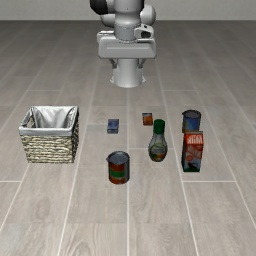

818 train 164 10.0


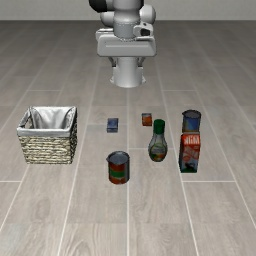

825 validation 153 10.0


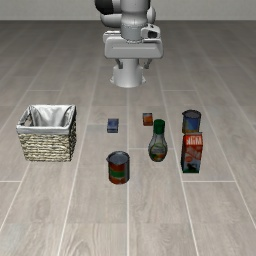

In [9]:
# CPU准备：只下载固定版本三份Parquet与元信息，不是整个LIBERO。
# 已有完成轨迹会核对SHA后跳过；原始图像字节、动作与帧编号一同保存。
log = wb.Log(ARCHIVE / 'prepare_logs')
COMMON = ['--dataset-root', WORKDIR / 'dataset', '--output-root', ARCHIVE,
          '--work-root', WORKDIR / 'corrector-data-work',
          '--source-root', WORKDIR / 'vla-corrector-reference']
log.run([PYTHON, SCRIPT, 'prepare', *COMMON, '--download'], env=ENV)
log.run([PYTHON, SCRIPT, 'verify', *COMMON], env=ENV)
from IPython.display import Image, display
for ep in [813,818,825]:
    info = json.loads((ARCHIVE / 'raw' / f'episode_{ep}' / 'provenance.json').read_text())
    print(ep, info['split'], info['num_frames'], info['fps'])
    display(Image(filename=str(ARCHIVE / 'raw' / f'episode_{ep}' / 'image_frame0.png'), width=256))


## GPU：调用上游视觉路径，逐episode归档

包括两路视觉特征、量化scale、当前checkpoint尺度的动作、原动作、episode/frame/timestamp。动作归一化与原QUANTILES选项不同，已明确记录。

每条完成后写入Drive并验SHA；突然断连的当前轨迹重做，已完成轨迹校验后跳过。先做这一小批，确认数值/空间/帧率后再扩展数据规模。

In [10]:
# 首次GPU入口尚未在远程实测。先核对图片/来源和源码讲解，再明确改为True。
RUN_GPU_EXTRACTION = True
if RUN_GPU_EXTRACTION:
    assert RUNTIME_MODE == "gpu", "切换T4后先以gpu模式重跑准备格"
    log = wb.Log(ARCHIVE / 'extraction_logs')
    log.run([PYTHON, SCRIPT, 'extract', *COMMON], env=ENV)
    log.run([PYTHON, SCRIPT, 'verify', *COMMON], env=ENV)
else:
    print('尚未启动GPU提取；上两格不会训练Corrector。')


运行：["/content/smolvla-training/venv/bin/python", "/content/smolvla-training/corrector_data_workbench.py", "extract", "--dataset-root", "/content/smolvla-training/dataset", "--output-root", "/content/drive/MyDrive/robot-lab/experiments/corrector_data_pilot_20261107", "--work-root", "/content/smolvla-training/corrector-data-work", "--source-root", "/content/smolvla-training/vla-corrector-reference"]
阶段extract；Python=/content/smolvla-training/venv/bin/python；仅三轨迹链路验证
hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint:
hint: 	git config --global init.defaultBranch <name>
hint:
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint:
hint: 	git branch -m <name>
fatal: ambiguous argument 'HEAD': unknown revisio

In [11]:
# 提取完成后只读元信息，不需要重新加载视觉模型；缺少的轨迹会明确显示。
for ep in [813,818,825]:
    path = ARCHIVE / 'features' / f'episode_{ep}' / 'metadata.json'
    if not path.is_file():
        print(ep, '尚未完成视觉特征提取')
        continue
    meta = json.loads(path.read_text())
    print(ep, {k: meta[k] for k in ['num_frames','l_tokens','d_dim','action_dim','split','fps','camera_keys']})


813 {'num_frames': 155, 'l_tokens': 128, 'd_dim': 960, 'action_dim': 7, 'split': 'train', 'fps': 10.0, 'camera_keys': ['observation.images.camera1', 'observation.images.camera2']}
818 {'num_frames': 164, 'l_tokens': 128, 'd_dim': 960, 'action_dim': 7, 'split': 'train', 'fps': 10.0, 'camera_keys': ['observation.images.camera1', 'observation.images.camera2']}
825 {'num_frames': 153, 'l_tokens': 128, 'd_dim': 960, 'action_dim': 7, 'split': 'validation', 'fps': 10.0, 'camera_keys': ['observation.images.camera1', 'observation.images.camera2']}


## 训练与中间权重评估

2026-11-08：用户已完成四个student_*训练步骤，并通过真实CPU训练检查。上游模型、Dataset和损失继续复用；本地脚本负责日志、划分和可恢复训练。

T4采用“先训练，保存少量不可变快照，随后逐个评估”的顺序，不同时加载训练器和完整VLA。每个epoch已有独立轨迹验证与CSV；`--snapshot-every 5`额外保留epoch0、5、10……及训练结束的轻量权重，latest.pt仍负责续训。每份38M评估权重约145MiB；30epoch按间隔5约7份，约1GiB，不逐step保存完整优化器。

每次修改本地.py后，运行`python3 scripts/sync_corrector_notebook.py`，保存Notebook，在远程重跑首个同步格。代码哈希或协议变化必须使用新TRAIN_RUN；旧训练不能通过更改协议强行续训。

默认T4配置为paper-width、episode划分、batch8×累积4（名义有效batch32），不是照搬论文batch512。CPU默认pilot。inspect先核对实际轨迹数和空间；当前数据准备入口仍只支持三条pilot，不将其标成44条或完整训练。下一步扩大数据需先核对物理Parquet映射并冻结轨迹划分。

预测报告支持选择单个中间checkpoint，每份单独输出；未选择时读取best_model。完整LVM状态机、动作中止和LeRobot0.6.1 OGG闭环尚未接入，本节不能产生Corrector成功率。

统一行动安排见[工作日志](../studies/policy_generalization/work_log.md)。


In [ ]:
TRAIN_PROFILE = 'paper-width' if RUNTIME_MODE == 'gpu' else 'pilot'  # pilot：825,024参数；paper-width：38,052,800参数
TRAIN_RUN = '003'        # 协议/数据改变时使用新的实验编号
TRAIN_SPLIT = 'episode'  # 独立轨迹开发验证；源码样本随机划分仍可显式选择
TRAIN_IMPLEMENTATION = 'student'  # 默认执行你在本地填写的A～D；不自动回退reference
TRAIN_DEVICE = 'cuda' if RUNTIME_MODE == 'gpu' else 'cpu'
TRAIN_PYTHON = PYTHON if RUNTIME_MODE == 'gpu' else Path(sys.executable)
TRAIN_OUT = ARCHIVE / 'predictor' / f'{TRAIN_PROFILE}_{TRAIN_SPLIT}_k10_{TRAIN_RUN}'
SNAPSHOT_EVERY = 5 if TRAIN_PROFILE == 'paper-width' else 1
TRAIN_ACCUMULATE = 4 if RUNTIME_MODE == 'gpu' else 1
TRAIN_ARGS = [
    '--features', ARCHIVE / 'features',
    '--source-root', WORKDIR / 'vla-corrector-reference',
    '--output', TRAIN_OUT,
    '--local-cache', WORKDIR / 'corrector-training-features',
    '--device', TRAIN_DEVICE, '--profile', TRAIN_PROFILE,
    '--implementation', TRAIN_IMPLEMENTATION, '--split-mode', TRAIN_SPLIT, '--val-ratio', '0.1',
    '--k-step', '10', '--epochs', '3' if TRAIN_PROFILE == 'pilot' else '30',
    '--batch-size', '8', '--accumulate', str(TRAIN_ACCUMULATE),
    '--snapshot-every', str(SNAPSHOT_EVERY),
    '--loss-type', 'cosine', '--lr', '0.0003', '--patience', '5',
]
RUN_TRAIN_INSPECT = False
if RUN_TRAIN_INSPECT:
    log = wb.Log(ARCHIVE / 'predictor_logs')
    log.run([TRAIN_PYTHON, '-c', 'import torch,numpy; print(torch.__version__,numpy.__version__,torch.cuda.is_available())'], env=ENV)
    log.run([TRAIN_PYTHON, WORKDIR / 'corrector_train.py', 'inspect', *TRAIN_ARGS], env=ENV)
else:
    print('先将RUN_TRAIN_INSPECT设为True，只检查缓存与模型配置，不更新参数。', TRAIN_OUT)


In [ ]:
RUN_CORRECTOR_TRAINING = False
RESUME_TRAINING = False  # 同一配置中断后设True；协议改变需换TRAIN_RUN，不能冒充续训
if RUN_CORRECTOR_TRAINING:
    log = wb.Log(ARCHIVE / 'predictor_logs')
    command = [TRAIN_PYTHON, WORKDIR / 'corrector_train.py', 'fit', *TRAIN_ARGS]
    if RESUME_TRAINING:
        command.append('--resume')
    log.run(command, env=ENV)
else:
    print('未启动训练；确认inspect报告后再打开开关。')


In [ ]:
# 结果分析不需要GPU。验证损失不是机器人成功率；此处也不生成机器人执行视频。
history_path = TRAIN_OUT / 'history.json'
if history_path.is_file():
    history = json.loads(history_path.read_text())
    result_path = TRAIN_OUT / 'result.json'
    print(result_path.read_text() if result_path.is_file() else '已有完整epoch，训练未完整返回。')
    from matplotlib import pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    epochs = [r['epoch'] for r in history]
    axes[0].plot(epochs, [r['train_loss'] for r in history], label='train')
    axes[0].plot(epochs, [r['validation']['loss'] for r in history], label='validation')
    axes[0].set_title('Configured objective'); axes[0].legend()
    axes[1].plot(epochs, [r['validation']['mse'] for r in history], label='predictor')
    axes[1].plot(epochs, [r['validation']['zero_prediction_mse'] for r in history], label='zero-change baseline')
    axes[1].set_title('Validation MSE'); axes[1].legend()
    for axis in axes: axis.set_xlabel('Epoch')
    fig.tight_layout(); fig.savefig(TRAIN_OUT / 'learning_curves.png', dpi=140)
    plt.show(); plt.close(fig)
else:
    print('尚无完整训练epoch，不填造loss或收益。')


## 预测功能评估（不等于机器人成功率）
读取冻结验证索引，保存逐样本cosine/MSE、零变化和训练集均值基线。第一对可视化按冻结索引取，不挑最好结果。真实前后图像仅为参照；预测的是latent delta，不生成未来RGB。


In [ ]:
RUN_PREDICTION_REPORT = False
PREDICTION_RUN = TRAIN_OUT
PREDICTION_CHECKPOINT = None  # 如：PREDICTION_RUN / 'snapshots/epoch_0005.pt'；None表示best_model.pt
PREDICTION_LABEL = PREDICTION_CHECKPOINT.stem if PREDICTION_CHECKPOINT else 'best_model'
PREDICTION_OUTPUT = PREDICTION_RUN / 'prediction_reports' / PREDICTION_LABEL
if RUN_PREDICTION_REPORT:
    log = wb.Log(ARCHIVE / 'predictor_logs')
    checkpoint_args = ['--checkpoint', PREDICTION_CHECKPOINT] if PREDICTION_CHECKPOINT else []
    log.run([TRAIN_PYTHON, WORKDIR / 'corrector_prediction_report.py', 'predict',
             '--run', PREDICTION_RUN, '--features', ARCHIVE / 'features',
             '--source-root', WORKDIR / 'vla-corrector-reference',
             '--raw-root', ARCHIVE / 'raw', '--output', PREDICTION_OUTPUT, *checkpoint_args], env=ENV)
    # 绘图用Colab宿主Matplotlib；此阶段不导入Torch，不要求训练venv安装绘图库。
    log.run([sys.executable, WORKDIR / 'corrector_prediction_report.py', 'plot',
             '--output', PREDICTION_OUTPUT], env=ENV)
    print((PREDICTION_OUTPUT / 'summary.json').read_text())


## 可选：读取完整数据清单，先估算再决定下载

这里只读取固定SHA的Hub文件清单和info.json，不下载训练分片/视频。原LIBERO约32.53GiB，Plus约14.75GiB；Plus为20FPS双路视频，与当前10FPS PNG字段不同。
提取完成一个pilot后可用其实测L/D估算全库特征缓存体积。云盘额度与/content临时磁盘不是一回事；先查真实Drive剩余容量，再决定单任务/单suite/全库范围。


In [12]:
log = wb.Log(ARCHIVE / 'inventory_logs')
command = [PYTHON, WORKDIR / 'inspect_robot_datasets.py', '--output', ARCHIVE / 'dataset_inventory']
pilot = ARCHIVE / 'features/episode_813'
if (pilot / 'COMPLETE.json').is_file():
    command += ['--pilot-cache', pilot]
log.run(command, env=ENV)


运行：["/content/smolvla-training/venv/bin/python", "/content/smolvla-training/inspect_robot_datasets.py", "--output", "/content/drive/MyDrive/robot-lab/experiments/corrector_data_pilot_20261107/dataset_inventory", "--pilot-cache", "/content/drive/MyDrive/robot-lab/experiments/corrector_data_pilot_20261107/features/episode_813"]
HuggingFaceVLA/libero 32.528GiB 1693 episodes 273465 frames 10.0 FPS
全库特征缓存估算： 31.38 GiB
lerobot/libero_plus 14.745GiB 14347 episodes 2238036 frames 20 FPS
全库特征缓存估算： 256.79 GiB


## 独立基线：不等Corrector训练，也不需要五步LoRA checkpoint

先让环境准备通过，再按需运行。本节使用原始LIBERO和原smolvla_libero固定权重，与之前Plus相机开发集分别记录。
SMOKE=True先执行task0的init_state 0/1两个回合；通过后SMOKE=False执行Object全部10任务×5个真实初始状态=50回合。
这是本项目公开权重基线，不是Corrector论文MetaWorld/SmolVLA表格的数值复现。原文LIBERO表使用π0.5。
新完整策略GPU入口尚未实测；每回合保留输入、初噪声、完整sim state、MP4和success，断连从完整回合续跑。

本次T4已完成三轨迹视觉特征提取：472帧、每帧[128,960]，Drive校验通过。仿真依赖安装通过，失败在继承Notebook的MPLBACKEND=inline；更新后的准备格使用Agg，并对已安装环境选择repair-sim。旧失败输出保留，重新执行环境同步格再运行本格。


In [17]:
RUN_PREPARE_SIM = True
if RUN_PREPARE_SIM:
    assert RUNTIME_MODE == 'gpu', '先在T4完成GPU环境准备'
    # 当前依赖已装好但渲染检查失败时，只修复/复查，不重复pip和apt。
    SIM_SETUP_MODE = 'repair-sim' if (
        (WORKDIR / 'sim-venv/bin/python').is_file()
        and (WORKDIR / 'libero-original/libero/libero/__init__.py').is_file()
        and (WORKDIR / 'libero-config/config.yaml').is_file()
    ) else 'prepare-sim'
    log = wb.Log(ARCHIVE / 'baseline_setup_logs')
    print('仿真准备模式：', SIM_SETUP_MODE, '；子进程绘图后端：', ENV.get('MPLBACKEND'))
    log.run([PYTHON, WB, SIM_SETUP_MODE, '--workdir', WORKDIR,
             '--log-root', ARCHIVE / 'baseline_setup_logs'], env=ENV)


仿真准备模式： repair-sim ；子进程绘图后端： Agg
运行：["/content/smolvla-training/venv/bin/python", "/content/smolvla-training/smolvla_training_workbench.py", "repair-sim", "--workdir", "/content/smolvla-training", "--log-root", "/content/drive/MyDrive/robot-lab/experiments/corrector_data_pilot_20261107/baseline_setup_logs"]
已在独立sim-venv注册LIBERO源码根目录；不修改第三方源码或训练venv。
运行：["/content/smolvla-training/sim-venv/bin/python", "-c", "import libero.libero as m; print('LIBERO实际导入文件:', m.__file__)"]
LIBERO实际导入文件: /content/smolvla-training/libero-original/libero/libero/__init__.py
运行：["/content/smolvla-training/sim-venv/bin/python", "-c", "from packaging.requirements import Requirement; from importlib.metadata import version; items=[Requirement(s) for s in ['robosuite==1.4.1', 'bddl==1.0.1', 'easydict==1.13', 'mujoco==3.7.0', 'future==1.0.0', 'Wand==0.6.13', 'scikit-image==0.25.2', 'gym==0.26.2', 'matplotlib==3.10.8', 'numba==0.61.2', 'hydra-core>=1.2,<1.4', 'h5py>=3.11,<4', 'cloudpickle>=2']]; bad=[str(r) for r in

In [18]:
RUN_BASELINE = True
SMOKE = True
BASELINE_ROOT = ARCHIVE / 'baseline' / ('object_H50_smoke_001' if SMOKE else 'object_H50_50episodes_001')
if RUN_BASELINE:
    assert RUNTIME_MODE == 'gpu', '先在T4完成GPU环境准备'
    SIM_PYTHON = WORKDIR / 'sim-venv/bin/python'
    assert SIM_PYTHON.is_file(), '先完成本节仿真环境准备'
    TASK_IDS = [0] if SMOKE else list(range(10))
    INITIAL_STATES = [0,1] if SMOKE else list(range(5))
    log = wb.Log(ARCHIVE / 'baseline_run_logs')
    log.run([SIM_PYTHON, WORKDIR / 'smolvla_baseline_benchmark.py',
             '--workdir', WORKDIR, '--output', BASELINE_ROOT,
             '--suite', 'libero_object', '--task-ids', *map(str,TASK_IDS),
             '--initial-state-ids', *map(str,INITIAL_STATES),
             '--seeds', '1000', '--action-steps', '50'], env=ENV)
else:
    print('基线入口已定义，默认不启动：', BASELINE_ROOT)


运行：["/content/smolvla-training/sim-venv/bin/python", "/content/smolvla-training/smolvla_baseline_benchmark.py", "--workdir", "/content/smolvla-training", "--output", "/content/drive/MyDrive/robot-lab/experiments/corrector_data_pilot_20261107/baseline/object_H50_smoke_001", "--suite", "libero_object", "--task-ids", "0", "--initial-state-ids", "0", "1", "--seeds", "1000", "--action-steps", "50"]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 

In [19]:
# CPU也能读已有统计/视频；不加载策略。
summary = BASELINE_ROOT / 'analysis/summary.json'
if summary.is_file():
    print(summary.read_text())
    failures = json.loads((BASELINE_ROOT / 'analysis/failure_videos.json').read_text())
    print('完整失败回合数：', len(failures))
    if failures:
        from IPython.display import Video, display
        FAILURE_INDEX = 0
        for path in failures[FAILURE_INDEX]['video_paths']:
            display(Video(filename=path, embed=True, width=480))
else:
    print('尚无完整基线统计；不要把未运行/中断记为0%成功率。')


{
  "groups": [
    {
      "method": "H50",
      "condition": "libero_object/task_0/init_0",
      "planned": 1,
      "completed": 1,
      "successes": 1,
      "errors": 0,
      "success_rate": 1.0,
      "pending": 0
    },
    {
      "method": "H50",
      "condition": "libero_object/task_0/init_1",
      "planned": 1,
      "completed": 1,
      "successes": 1,
      "errors": 0,
      "success_rate": 1.0,
      "pending": 0
    }
  ],
  "overall_by_method": [
    {
      "method": "H50",
      "planned": 2,
      "completed": 2,
      "successes": 2,
      "errors": 0,
      "success_rate": 1.0,
      "completion_rate": 1.0,
      "mean_chunk_calls": 3.0,
      "observed_chunk_calls_n": 2,
      "mean_policy_s": 2.2907333564994588,
      "observed_policy_s_n": 2,
      "mean_monitor_s": 0.0,
      "observed_monitor_s_n": 2,
      "mean_event_replans": 0.0,
      "observed_event_replans_n": 2
    }
  ],
  "note": "总体按成功数/完成数加权，不直接平均各组百分比；error/未完成不当作任务失败；非配对因果结论"
}

完整失败回合数： 

## 完整调用链测试：先强制事件冒烟，再无强制事件的成对评测

本节与提取/训练串行执行。数据子进程仍在运行时，不重跑环境同步格、不同时启动完整VLA。首版接原始LIBERO，复用已通过的基线环境；Plus视角尚未接入此新入口。

单回合和批量共用corrector_closed_loop_eval.py。methods可选H50、H20、monitor（只记录）、lvm（中止后普通重规划）、ogg（中止后引导）。原上游完整阈值状态机直接加载固定源码；OGG使用你已完成的输入梯度方法。实例级wrapper局部退出eval_policy外层inference_mode，VLA仍处于no_grad；不会修改安装包。

CLI默认control-implementation=reference作为显式对照；本Notebook已选择student，调用用户完成的两处控制决策。若练习尚未完成，会在加载GPU模型前停止。

录像video-policy=all/failures/none；audit-mode和trace-mode也各有all/failures/none。默认小批量保留失败视频/首帧输入，保留全部低容量分数日志；event_tensors需显式打开。每回合完成立即写Drive，running/error不当机器人失败；断连后同计划重跑跳过完整回合。

强制事件只证明代码路径被执行，不能据其成功率判断Corrector收益。自然事件完整回合才用于后续对照。数据跨度按训练配置换算为控制步；当前1秒预测在20Hz下20步后比较。

用户已实现student_should_interrupt与student_correction_target。提取、训练和预测报告全部结束后，运行前面的“只更新代码，不重新安装”格，将本地实现同步到远程；不重跑环境准备。随后按本节仿真准备→单回合强制事件接线验证→自然触发批次评测执行。闭环默认显式使用student实现。


In [ ]:
RUN_CLOSED_SETUP = False
if RUN_CLOSED_SETUP:
    SIM_SETUP_MODE = 'repair-sim' if ((WORKDIR/'sim-venv/bin/python').is_file()
        and (WORKDIR/'libero-original/libero/libero/__init__.py').is_file()
        and (WORKDIR/'libero-config/config.yaml').is_file()) else 'prepare-sim'
    log=wb.Log(STREAM_ROOT/'closed_setup_logs')
    log.run([PYTHON,WB,SIM_SETUP_MODE,'--workdir',WORKDIR,
             '--log-root',STREAM_ROOT/'closed_setup_logs'],env=ENV)


In [ ]:
# 先选择一份已完成的真实预测器；示例用3条数据的速度探测权重，只用于接线检查。
RUN_CLOSED_SMOKE = False
CLOSED_MODEL_RUN = STREAM_FULL_TRAIN if (STREAM_FULL_TRAIN/'result.json').is_file() else STREAM_PROBE_TRAIN
CLOSED_CHECKPOINT = CLOSED_MODEL_RUN/'best_model.pt'  # 优先完整训练权重；仅小样本权重时仍只作接线验证
CLOSED_CONTROL = 'student'  # 用户已完成两处控制逻辑；先在所有提取/训练/报告格结束后执行代码同步格
if RUN_CLOSED_SMOKE:
    assert CLOSED_CHECKPOINT.is_file(), '先完成预测器训练'
    SIM_PYTHON=WORKDIR/'sim-venv/bin/python';assert SIM_PYTHON.is_file(), '先准备仿真环境'
    CLOSED_SMOKE_ROOT=STREAM_ROOT/'closed_loop'/'debug_ogg_001'
    log=wb.Log(STREAM_ROOT/'closed_logs')
    log.run([SIM_PYTHON,WORKDIR/'corrector_closed_loop_eval.py','--workdir',WORKDIR,
             '--output',CLOSED_SMOKE_ROOT,'--methods','ogg','--initial-state-ids','0',
             '--seeds','1000','--max-steps','60','--debug-force-step','24',
             '--corrector-checkpoint',CLOSED_CHECKPOINT,'--source-root',WORKDIR/'vla-corrector-reference',
             '--control-implementation',CLOSED_CONTROL,'--video-policy','all','--audit-mode','all'],env=ENV)
    print((CLOSED_SMOKE_ROOT/'analysis/summary.json').read_text())
    # 自动验收调用链：任务是否成功不是这一步的通过标准。
    import json
    completed = [json.loads(p.read_text()) for p in (CLOSED_SMOKE_ROOT/'trials').glob('*.json')]
    completed = [r for r in completed if r['status'] == 'completed']
    assert len(completed) == 1, '单回合尚未完整结束'
    record = completed[0]
    assert record['result']['event_replans'] > 0, '未执行动作队列中止/重规划'
    assert record['result']['guidance_calls'] > 0, '未执行OGG梯度引导'
    attempt_dir = CLOSED_SMOKE_ROOT/'attempts'/record['case']['id']/f"attempt_{record['attempt']:03d}"
    actual = json.loads((attempt_dir/'actual_protocol.json').read_text())
    assert actual['monitor_horizon_steps'] == 20, '1秒跨度应对齐20Hz的20控制步'
    print('调用链检查通过：队列中止、OGG引导、1秒监测跨度均已执行；此回合不能作为正式成功率。')


In [ ]:
RUN_CLOSED_BATCH = False
CLOSED_BATCH_ROOT = STREAM_ROOT/'closed_loop'/'paired_001'
CLOSED_METHODS = ['H50','H20','monitor','lvm','ogg']
CLOSED_INITIAL_STATES = [0,1]
if RUN_CLOSED_BATCH:
    log=wb.Log(STREAM_ROOT/'closed_logs')
    log.run([WORKDIR/'sim-venv/bin/python',WORKDIR/'corrector_closed_loop_eval.py',
             '--workdir',WORKDIR,'--output',CLOSED_BATCH_ROOT,'--methods',*CLOSED_METHODS,
             '--initial-state-ids',*map(str,CLOSED_INITIAL_STATES),'--seeds','1000',
             '--corrector-checkpoint',CLOSED_CHECKPOINT,'--source-root',WORKDIR/'vla-corrector-reference',
             '--control-implementation',CLOSED_CONTROL,'--video-policy','failures',
             '--audit-mode','failures','--trace-mode','all'],env=ENV)
    print((CLOSED_BATCH_ROOT/'analysis/summary.json').read_text())
    print('失败视频索引:',CLOSED_BATCH_ROOT/'analysis/failure_videos.html')


In [ ]:
# 只读取已保存的评测记录/视频；不运行模型。先看debug，正式批次后改为paired。
from pathlib import Path
import json
from IPython.display import display, Video, Markdown
CLOSED_REVIEW_KIND = 'debug'  # 'debug'：接线检查；'paired'：自然触发的成对批次
assert CLOSED_REVIEW_KIND in {'debug', 'paired'}
CLOSED_REVIEW_ROOT = Path('/content/drive/MyDrive/robot-lab/experiments/corrector_stream_task24_001/closed_loop') / (
    'debug_ogg_001' if CLOSED_REVIEW_KIND == 'debug' else 'paired_001')
summary_file = CLOSED_REVIEW_ROOT/'analysis/summary.json'
if not summary_file.is_file():
    print('尚无评测汇总：', summary_file, '；先完成上面的相应评测格。')
else:
    print(json.dumps(json.loads(summary_file.read_text()), ensure_ascii=False, indent=2))
    records = [json.loads(p.read_text()) for p in (CLOSED_REVIEW_ROOT/'trials').glob('*.json')]
    completed = [r for r in records if r['status'] == 'completed']
    completed.sort(key=lambda r: r['result']['success'])  # 优先展示失败回合。
    shown = 0
    for record in completed:
        for video in record['result'].get('video_paths', []):
            if shown >= 2:
                break
            path = Path(video)
            if path.is_file():
                display(Markdown(f"**{record['case']['method']} / {record['case']['condition']} / success={record['result']['success']}**"))
                display(Video(filename=str(path), embed=True, width=640))
                shown += 1
    if not shown:
        print('当前无留存视频；failures策略只保留失败录像，全部成功时没有视频是预期行为。')
    print('完整统计和失败索引：', CLOSED_REVIEW_ROOT/'analysis')
